<a href="https://colab.research.google.com/github/devipriyak/2025_VI_sem_CSE_B_LBRCE/blob/main/SEM%20imageges%20Detection%20AMAFFNET.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

print("Current directory:", os.getcwd())
print("Files:", os.listdir())

Current directory: /content
Files: ['.config', 'drive', 'sample_data']


In [ ]:
import os

# Search for saved confusion matrix and prediction files
search_dir = BASE_DIR

extensions = (".npy", ".npz", ".csv", ".pkl", ".xlsx")

print("Searching for saved evaluation results...\n")

for root, dirs, files in os.walk(search_dir):

    for file in files:

        if (
            any(word in file.lower() for word in
                ["confusion", "prediction", "y_pred", "y_true", "result"])
            and file.lower().endswith(extensions)
        ):
            print(os.path.join(root, file))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

root_dir = "/content/drive/MyDrive"

for root, dirs, files in os.walk(root_dir):
    for file in files:
        if file.lower() == "13-1.png":
            print(os.path.join(root, file))

/content/drive/MyDrive/Microplastics_SEM/dataset3_extracted/dataset3/fibre/fibre_1crop/label_gray/13-1.png
/content/drive/MyDrive/Microplastics_SEM/dataset3_extracted/dataset3/fibre/fibre_1crop/image/13-1.png
/content/drive/MyDrive/Microplastics_SEM/dataset3_extracted/dataset3/fibre/fibre_1crop/label_index/test/label/13-1.png
/content/drive/MyDrive/Microplastics_SEM/dataset3_extracted/dataset3/fibre/fibre_1crop/label_index/test/image/13-1.png
/content/drive/MyDrive/Microplastics_SEM/dataset3_extracted/dataset3/fibre/fibre_1crop/label_color_map/13-1.png
/content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/fibre_1crop/label/13-1.png
/content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/fibre_1crop/image/13-1.png


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/Microplastics_SEM/dataset1.zip"

extract_path = "/content/drive/MyDrive/Microplastics_SEM/dataset1"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print("Extracted location:", extract_path)

Extraction completed!
Extracted location: /content/drive/MyDrive/Microplastics_SEM/dataset1


In [ ]:

import os
import numpy as np
from PIL import Image

base = "/content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1"

folders = [
    "[datasets_full]_Exp1_Exp4",
    "[datasets_subset]_Exp2/bead",
    "[datasets_subset]_Exp2/fibre_1",
    "[datasets_subset]_Exp2/fibre_2",
    "[datasets_subset]_Exp2/fibre_1crop",
    "[datasets_subset]_Exp2/fibre_2crop",
    "[datasets_subset]_Exp2/fragment_1",
    "[datasets_subset]_Exp2/fragment_2"
]

for folder in folders:

    path = os.path.join(base, folder)

    image_dir = os.path.join(path, "image")
    label_dir = os.path.join(path, "label")

    images = set(os.listdir(image_dir))
    labels = set(os.listdir(label_dir))

    common = sorted(images & labels)

    print("\nFOLDER:", folder)
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Matching filenames:", len(common))
    print("Images without labels:", len(images-labels))
    print("Labels without images:", len(labels-images))

    if common:
        filename = common[0]

        img = Image.open(
            os.path.join(image_dir, filename)
        )

        mask = Image.open(
            os.path.join(label_dir, filename)
        )

        print("Sample filename:", filename)
        print("Original image size:", img.size)
        print("Original image mode:", img.mode)
        print("Mask size:", mask.size)
        print("Mask mode:", mask.mode)

        mask_array = np.array(mask.convert("RGB"))

        colors = np.unique(
            mask_array.reshape(-1, 3),
            axis=0
        )

        print("Unique mask colours:", len(colors))


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load the original SEM image and its corresponding mask
base = "/content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1"
folder = "[datasets_subset]_Exp2/bead"
filename = "Dove_men_acrylates_copolymer_microbeads_002.png"

image_path = f"{base}/{folder}/image/{filename}"
mask_path = f"{base}/{folder}/label/{filename}"

# Read both images as grayscale arrays
image = np.array(Image.open(image_path).convert("L"))
mask = np.array(Image.open(mask_path).convert("L"))

# Create two binary masks using different thresholds
mask_gt0 = (mask > 0).astype(np.uint8) * 255
mask_ge128 = (mask >= 128).astype(np.uint8) * 255

# Calculate foreground percentages for both thresholds
print("Foreground percentage (mask > 0):",
      np.mean(mask_gt0 > 0) * 100)

print("Foreground percentage (mask >= 128):",
      np.mean(mask_ge128 > 0) * 100)

# Display the original image, raw mask and thresholded mask
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original SEM Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Original Segmentation Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask_ge128, cmap="gray")
plt.title("Binary Mask (Threshold >= 128)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Convert the grayscale annotation into a binary segmentation mask.
# Pixels >= 128 represent the particle; remaining pixels represent background.

binary_mask = (mask >= 128).astype("uint8")

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Define the dataset's main directory
base = "/content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1"

# Select one representative folder from each particle class
samples = {
    "Bead": "[datasets_subset]_Exp2/bead",
    "Fiber": "[datasets_subset]_Exp2/fibre_1",
    "Fragment": "[datasets_subset]_Exp2/fragment_1"
}

# Create a figure to compare all three particle classes
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for row, (class_name, folder) in enumerate(samples.items()):

    # Locate the image and corresponding segmentation mask
    image_dir = os.path.join(base, folder, "image")
    mask_dir = os.path.join(base, folder, "label")

    # Select the first image that has a matching mask
    filenames = sorted(os.listdir(image_dir))
    filename = next(
        (f for f in filenames if os.path.isfile(os.path.join(mask_dir, f))),
        None
    )

    if filename is None:
        print(f"No matching image-mask pair found for {class_name}")
        continue

    # Load the original image and grayscale mask
    image = np.array(
        Image.open(os.path.join(image_dir, filename)).convert("L")
    )
    mask = np.array(
        Image.open(os.path.join(mask_dir, filename)).convert("L")
    )

    # Convert the mask into a binary foreground-background mask
    binary_mask = (mask >= 128).astype(np.uint8)

    # Display the original SEM image
    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(f"{class_name}: Original Image")

    # Display the original segmentation annotation
    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title(f"{class_name}: Original Mask")

    # Display the thresholded binary mask
    axes[row, 2].imshow(binary_mask, cmap="gray")
    axes[row, 2].set_title(f"{class_name}: Binary Mask")

    # Remove axis markings for clearer visualization
    for col in range(3):
        axes[row, col].axis("off")

    # Print basic annotation statistics
    print(
        f"{class_name}: {filename} | "
        f"Foreground: {binary_mask.mean() * 100:.2f}%"
    )

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image

# Define the dataset location
base = "/content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1"

# Specify the three particle-class folders
classes = {
    "Bead": "[datasets_subset]_Exp2/bead",
    "Fiber": "[datasets_subset]_Exp2/fibre_1",
    "Fragment": "[datasets_subset]_Exp2/fragment_1"
}

results = []

for class_name, folder in classes.items():

    # Define image and mask directories
    image_dir = os.path.join(base, folder, "image")
    mask_dir = os.path.join(base, folder, "label")

    # Process every image in the class folder
    for filename in sorted(os.listdir(image_dir)):

        image_path = os.path.join(image_dir, filename)
        mask_path = os.path.join(mask_dir, filename)

        # Skip files without a corresponding annotation
        if not os.path.isfile(mask_path):
            results.append({
                "Class": class_name,
                "Filename": filename,
                "Status": "Missing mask"
            })
            continue

        # Load image and mask
        image = np.array(Image.open(image_path).convert("L"))
        mask = np.array(Image.open(mask_path).convert("L"))

        # Check whether image and mask dimensions match
        dimensions_match = image.shape == mask.shape

        # Convert annotation into a binary mask
        binary_mask = mask >= 128

        # Calculate foreground percentage
        foreground_percentage = binary_mask.mean() * 100

        # Record mask properties
        results.append({
            "Class": class_name,
            "Filename": filename,
            "Image_Shape": str(image.shape),
            "Mask_Shape": str(mask.shape),
            "Dimensions_Match": dimensions_match,
            "Unique_Mask_Values": len(np.unique(mask)),
            "Foreground_Percentage": round(foreground_percentage, 3),
            "Status": "Valid dimensions" if dimensions_match else "Dimension mismatch"
        })

# Convert the collected results into a DataFrame
df = pd.DataFrame(results)

# Display the overall validation summary
print("TOTAL IMAGE-MASK PAIRS:", len(df))
print("\nSTATUS COUNTS:")
print(df["Status"].value_counts())

# Display foreground statistics for each class
print("\nFOREGROUND STATISTICS:")
print(
    df.groupby("Class")["Foreground_Percentage"]
      .agg(["count", "mean", "std", "min", "max"])
)

# Display any missing masks or dimension mismatches
print("\nPAIRS REQUIRING ATTENTION:")
print(df[df["Status"] != "Valid dimensions"])

# Save the validation report
df.to_csv(
    "/content/drive/MyDrive/Microplastics_SEM/mask_validation_report.csv",
    index=False
)

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Define the dataset and validation-report paths
base = "/content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1"
report_path = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "complete_mask_validation.csv"
)

# Load the previously generated validation report
df = pd.read_csv(report_path)

# Define the class-specific image folders
class_folders = {
    "Bead": "[datasets_subset]_Exp2/bead",
    "Fiber": "[datasets_subset]_Exp2/fibre_1",
    "Fragment": "[datasets_subset]_Exp2/fragment_1"
}

# Display the smallest and largest masks for each class
for class_name, folder in class_folders.items():

    # Select five smallest and five largest foreground samples
    class_df = df[df["Class"] == class_name]

    extreme_samples = pd.concat([
        class_df.nsmallest(5, "Foreground_Percentage"),
        class_df.nlargest(5, "Foreground_Percentage")
    ])

    # Create a two-column visualization
    fig, axes = plt.subplots(10, 2, figsize=(12, 30))

    for row, (_, record) in enumerate(extreme_samples.iterrows()):

        # Locate the original image and corresponding mask
        filename = record["Filename"]
        image_path = os.path.join(base, folder, "image", filename)
        mask_path = os.path.join(base, folder, "label", filename)

        # Load image and mask
        image = np.array(Image.open(image_path).convert("L"))
        mask = np.array(Image.open(mask_path).convert("L"))

        # Convert the mask into binary foreground-background form
        binary_mask = mask >= 128

        # Create an overlay to inspect segmentation boundaries
        overlay = np.stack([image, image, image], axis=-1)
        overlay[binary_mask] = (
            0.6 * overlay[binary_mask] +
            0.4 * np.array([255, 0, 0])
        ).astype(np.uint8)

        # Display original SEM image
        axes[row, 0].imshow(image, cmap="gray")
        axes[row, 0].set_title(
            f"{filename}\nForeground: "
            f"{record['Foreground_Percentage']:.2f}%"
        )

        # Display the segmentation overlay
        axes[row, 1].imshow(overlay)
        axes[row, 1].set_title("Segmentation Overlay")

        # Remove unnecessary axis markings
        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

    plt.suptitle(f"{class_name}: Extreme Foreground Samples")
    plt.tight_layout()
    plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Define the main dataset directory
base = "/content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1"

# Load the complete image-mask validation report
report_path = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "complete_mask_validation.csv"
)
df = pd.read_csv(report_path)

# Inspect five smallest and five largest masks in each class
for class_name in ["Bead", "Fiber", "Fragment"]:

    # Select the records belonging to the current class
    class_df = df[df["Class"] == class_name]

    # Combine the five smallest and five largest foreground samples
    extreme_samples = pd.concat([
        class_df.nsmallest(5, "Foreground_Percentage"),
        class_df.nlargest(5, "Foreground_Percentage")
    ])

    # Create a figure for the selected samples
    fig, axes = plt.subplots(10, 2, figsize=(14, 28))

    for row, (_, record) in enumerate(extreme_samples.iterrows()):

        # IMPORTANT: Read the actual folder from the validation report
        folder = record["Folder"]
        filename = record["Filename"]

        # Construct the correct image and mask paths
        image_path = os.path.join(base, folder, "image", filename)
        mask_path = os.path.join(base, folder, "label", filename)

        # Check that both files exist before attempting to read them
        if not os.path.isfile(image_path) or not os.path.isfile(mask_path):
            print("File not found:", filename)
            axes[row, 0].set_visible(False)
            axes[row, 1].set_visible(False)
            continue

        # Load the original SEM image and its corresponding mask
        image = np.array(Image.open(image_path).convert("L"))
        mask = np.array(Image.open(mask_path).convert("L"))

        # Convert the grayscale mask into a binary mask
        binary_mask = mask >= 128

        # Create an RGB version of the original image
        overlay = np.stack([image] * 3, axis=-1)

        # Highlight the segmented foreground in red
        overlay[binary_mask] = (
            0.6 * overlay[binary_mask] +
            0.4 * np.array([255, 0, 0])
        ).astype(np.uint8)

        # Display the original SEM image
        axes[row, 0].imshow(image, cmap="gray")
        axes[row, 0].set_title(
            f"{filename}\n"
            f"Foreground: {record['Foreground_Percentage']:.2f}%"
        )

        # Display the segmentation overlay
        axes[row, 1].imshow(overlay)
        axes[row, 1].set_title("Segmentation Overlay")

        # Remove axis markings
        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

    # Add the class name and display the figure
    plt.suptitle(f"{class_name}: Extreme Foreground Samples")
    plt.tight_layout()
    plt.show()

In [ ]:

# ============================================================
# CELL 1: MOUNT GOOGLE DRIVE AND IMPORT REQUIRED LIBRARIES
# ============================================================

# Mount Google Drive to access the datasets and save split files.
from google.colab import drive
drive.mount('/content/drive')

# Import libraries for file handling and image identification.
import os
import hashlib
import numpy as np
import pandas as pd

# Import the stratified cross-validation utility.
from sklearn.model_selection import StratifiedKFold

# Import image extensions that will be considered.
IMAGE_EXTENSIONS = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')

# Set a fixed random seed so the folds can be reproduced.
RANDOM_STATE = 42

# Define the number of cross-validation folds.
N_SPLITS = 5

print("Google Drive mounted successfully.")
print("Required libraries imported.")


In [ ]:

# ============================================================
# CELL 2: DEFINE DATASET PATHS
# ============================================================

# IMPORTANT:
# Replace this path with the actual folder containing your
# ORIGINAL AMAFF-Net dataset of 150 images.
#
# Expected structure:
# Original_AMAFFNet_Dataset/
#     Bead/
#     Fiber/
#     Fragment/

DATASET_A_DIR = (
    "/content/drive/MyDrive/REPLACE_WITH_ORIGINAL_150_IMAGE_DATASET"
)

# Dataset B: Mendeley SEM dataset.
DATASET_B_BASE = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "dataset1/dataset1"
)

# Dataset B contains original images in these class-specific folders.
# Do NOT use the full dataset folder or crop folders.
DATASET_B_CLASS_DIRS = {
    "Bead": os.path.join(
        DATASET_B_BASE,
        "[datasets_subset]_Exp2",
        "bead"
    ),

    "Fiber": os.path.join(
        DATASET_B_BASE,
        "[datasets_subset]_Exp2",
        "fibre_1"
    ),

    # Include both original Fiber folders.
    "Fiber_2": os.path.join(
        DATASET_B_BASE,
        "[datasets_subset]_Exp2",
        "fibre_2"
    ),

    "Fragment": os.path.join(
        DATASET_B_BASE,
        "[datasets_subset]_Exp2",
        "fragment_1"
    ),

    # Include the second original Fragment folder.
    "Fragment_2": os.path.join(
        DATASET_B_BASE,
        "[datasets_subset]_Exp2",
        "fragment_2"
    )
}

# Folder where the final split files will be saved.
OUTPUT_DIR = (
    "/content/drive/MyDrive/AMAFFNet_5Fold_Splits"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Check whether Dataset B folders exist.
for folder in DATASET_B_CLASS_DIRS.values():
    if not os.path.isdir(folder):
        raise FileNotFoundError(
            f"Dataset B folder not found: {folder}"
        )

print("Dataset B folders verified.")
print("Output directory:", OUTPUT_DIR)
print("Update DATASET_A_DIR before continuing.")


In [ ]:

# ============================================================
# CELL 2: DEFINE DATASET PATHS
# ============================================================

# IMPORTANT:
# Replace this path with the actual folder containing your
# ORIGINAL AMAFF-Net dataset of 150 images.
#
# Expected structure:
# Original_AMAFFNet_Dataset/
#     Bead/
#     Fiber/
#     Fragment/

DATASET_A_DIR = (
    "/content/drive/MyDrive/REPLACE_WITH_ORIGINAL_150_IMAGE_DATASET"
)

# Dataset B: Mendeley SEM dataset.
DATASET_B_BASE = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "dataset1/dataset1"
)

# Dataset B contains original images in these class-specific folders.
# Do NOT use the full dataset folder or crop folders.
DATASET_B_CLASS_DIRS = {
    "Bead": os.path.join(
        DATASET_B_BASE,
        "[datasets_subset]_Exp2",
        "bead"
    ),

    "Fiber": os.path.join(
        DATASET_B_BASE,
        "[datasets_subset]_Exp2",
        "fibre_1"
    ),

    # Include both original Fiber folders.
    "Fiber_2": os.path.join(
        DATASET_B_BASE,
        "[datasets_subset]_Exp2",
        "fibre_2"
    ),

    "Fragment": os.path.join(
        DATASET_B_BASE,
        "[datasets_subset]_Exp2",
        "fragment_1"
    ),

    # Include the second original Fragment folder.
    "Fragment_2": os.path.join(
        DATASET_B_BASE,
        "[datasets_subset]_Exp2",
        "fragment_2"
    )
}

# Folder where the final split files will be saved.
OUTPUT_DIR = (
    "/content/drive/MyDrive/AMAFFNet_5Fold_Splits"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Check whether Dataset B folders exist.
for folder in DATASET_B_CLASS_DIRS.values():
    if not os.path.isdir(folder):
        raise FileNotFoundError(
            f"Dataset B folder not found: {folder}"
        )

print("Dataset B folders verified.")
print("Output directory:", OUTPUT_DIR)
print("Update DATASET_A_DIR before continuing.")


In [ ]:

# ============================================================
# FIND ORIGINAL AMAFF-NET DATASET FOLDER
# ============================================================

import os

# Set Google Drive search location.
search_root = "/content/drive/MyDrive"

# Search for folders with the expected three class names.
required_classes = {"Bead", "Fiber", "Fragment"}

found = False

for root, dirs, files in os.walk(search_root):

    # Skip hidden folders to reduce unnecessary searching.
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    # Check whether all three class folders exist.
    if required_classes.issubset(set(dirs)):

        print("\nPossible Dataset A location:")
        print(root)

        # Count images in each class folder.
        for class_name in sorted(required_classes):

            class_path = os.path.join(root, class_name)

            image_count = sum(
                filename.lower().endswith(
                    (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
                )
                for filename in os.listdir(class_path)
            )

            print(f"{class_name}: {image_count}")

        found = True

if not found:
    print("No matching folder structure found.")
    print("Please share your original dataset folder path.")


In [ ]:

# ============================================================
# CELL 3: COLLECT ORIGINAL IMAGE PATHS AND CHECK DUPLICATES
# ============================================================

# Calculate a SHA-256 hash for an image file.
# Identical files will have identical hashes.
def calculate_sha256(file_path):

    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:

        # Read the file in chunks to avoid loading large files at once.
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


# Collect image paths from Dataset A.
def collect_dataset_a(dataset_dir):

    records = []

    # Confirm that the Dataset A directory exists.
    if not os.path.isdir(dataset_dir):
        raise FileNotFoundError(
            "Correct the DATASET_A_DIR path in Cell 2."
        )

    # Read the three expected class folders.
    for class_name in ["Bead", "Fiber", "Fragment"]:

        class_dir = os.path.join(dataset_dir, class_name)

        if not os.path.isdir(class_dir):
            raise FileNotFoundError(
                f"Missing Dataset A class folder: {class_dir}"
            )

        # Search recursively inside each class folder.
        for root, _, files in os.walk(class_dir):

            for filename in files:

                # Ignore non-image files.
                if filename.lower().endswith(IMAGE_EXTENSIONS):

                    file_path = os.path.join(root, filename)

                    records.append({
                        "Dataset": "A",
                        "FilePath": file_path,
                        "Label": class_name,
                        "SHA256": calculate_sha256(file_path)
                    })

    return pd.DataFrame(records)


# Collect image paths from Dataset B.
def collect_dataset_b(class_directories):

    records = []

    # Map each physical folder to its correct classification label.
    folder_label_map = {
        "Bead": "Bead",
        "Fiber_2": "Fiber",
        "Fiber": "Fiber",
        "Fragment": "Fragment",
        "Fragment_2": "Fragment"
    }

    for folder_key, folder_path in class_directories.items():

        # Determine the final class label.
        class_name = folder_label_map[folder_key]

        # Read only original images from the specified folders.
        for filename in os.listdir(folder_path):

            if filename.lower().endswith(IMAGE_EXTENSIONS):

                file_path = os.path.join(folder_path, filename)

                if os.path.isfile(file_path):

                    records.append({
                        "Dataset": "B",
                        "FilePath": file_path,
                        "Label": class_name,
                        "SHA256": calculate_sha256(file_path)
                    })

    return pd.DataFrame(records)


# Collect Dataset A and Dataset B image information.
df_A = collect_dataset_a(DATASET_A_DIR)

df_B = collect_dataset_b(DATASET_B_CLASS_DIRS)

print("Dataset A image count:", len(df_A))
print("Dataset B image count:", len(df_B))

# Display class-wise image counts.
print("\nDataset A class distribution:")
print(df_A["Label"].value_counts().sort_index())

print("\nDataset B class distribution:")
print(df_B["Label"].value_counts().sort_index())


In [ ]:

# ============================================================
# CELL 1: PREPARE THE COMPLETE MENDELEY SEM DATASET
# Dataset: 237 original images
# Classes: Bead, Fiber, Fragment
# ============================================================

# Import required libraries
import os
import glob
import pandas as pd
from collections import Counter

# ------------------------------------------------------------
# STEP 1: Mount Google Drive
# ------------------------------------------------------------

from google.colab import drive
drive.mount('/content/drive')

# ------------------------------------------------------------
# STEP 2: Define the dataset directory
# ------------------------------------------------------------

base = "/content/drive/MyDrive/Microplastics_SEM/dataset1"

# Define the original-image folders for each class
class_folders = {
    "Bead": [
        "[datasets_subset]_Exp2/bead"
    ],

    "Fiber": [
        "[datasets_subset]_Exp2/fibre_1",
        "[datasets_subset]_Exp2/fibre_2"
    ],

    "Fragment": [
        "[datasets_subset]_Exp2/fragment_1",
        "[datasets_subset]_Exp2/fragment_2"
    ]
}

# Assign numerical labels to the three classes
class_labels = {
    "Bead": 0,
    "Fiber": 1,
    "Fragment": 2
}

# Supported image formats
image_extensions = (
    "*.png", "*.jpg", "*.jpeg",
    "*.bmp", "*.tif", "*.tiff"
)

# ------------------------------------------------------------
# STEP 3: Collect original image paths and labels
# ------------------------------------------------------------

image_records = []

for class_name, folders in class_folders.items():

    for folder in folders:

        # Construct the complete class-folder path
        folder_path = os.path.join(base, folder)

        # Stop if the expected folder does not exist
        if not os.path.isdir(folder_path):
            raise FileNotFoundError(
                f"Class folder not found: {folder_path}"
            )

        # Collect image files from this original-image folder
        for extension in image_extensions:

            image_paths = glob.glob(
                os.path.join(folder_path, extension)
            )

            # Store image path, class name and numerical label
            for image_path in image_paths:

                image_records.append({
                    "Image_Path": image_path,
                    "Filename": os.path.basename(image_path),
                    "Class": class_name,
                    "Label": class_labels[class_name]
                })

# ------------------------------------------------------------
# STEP 4: Create the dataset DataFrame
# ------------------------------------------------------------

df = pd.DataFrame(image_records)

# Remove repeated paths, if any
df = df.drop_duplicates(subset=["Image_Path"])

# Reset the DataFrame index
df = df.reset_index(drop=True)

# ------------------------------------------------------------
# STEP 5: Display class-wise image counts
# ------------------------------------------------------------

print("\nCLASS-WISE IMAGE COUNTS")
print("=" * 45)

class_counts = df["Class"].value_counts()

for class_name in ["Bead", "Fiber", "Fragment"]:

    count = int(class_counts.get(class_name, 0))

    print(f"{class_name:12s}: {count}")

print("-" * 45)
print("Total images:", len(df))

# ------------------------------------------------------------
# STEP 6: Verify the expected dataset counts
# ------------------------------------------------------------

expected_counts = {
    "Bead": 51,
    "Fiber": 90,
    "Fragment": 96
}

actual_counts = {
    class_name: int(class_counts.get(class_name, 0))
    for class_name in expected_counts
}

assert actual_counts == expected_counts, (
    f"Dataset count mismatch!\n"
    f"Expected: {expected_counts}\n"
    f"Actual: {actual_counts}"
)

assert len(df) == 237, (
    f"Expected 237 images, but found {len(df)}"
)

# ------------------------------------------------------------
# STEP 7: Save the classification manifest
# ------------------------------------------------------------

manifest_path = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "Mendeley_SEM_237_Classification_Manifest.csv"
)

df.to_csv(manifest_path, index=False)

print("\nDataset verification successful.")
print("Manifest saved to:", manifest_path)


In [ ]:

# ============================================================
# CELL 1: CREATE AMAFF-NET CLASSIFICATION MANIFEST
# Complete Mendeley SEM Dataset: 237 Original Images
# ============================================================

# Import required libraries
import os
import pandas as pd

# ------------------------------------------------------------
# STEP 1: Define dataset and validation report paths
# ------------------------------------------------------------

base = "/content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1"

report_path = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "complete_mask_validation.csv"
)

# ------------------------------------------------------------
# STEP 2: Load the previously completed validation report
# ------------------------------------------------------------

df = pd.read_csv(report_path)

# Retain only image-mask pairs that passed validation
valid_df = df[df["Status"] == "Valid"].copy()

# ------------------------------------------------------------
# STEP 3: Assign numerical labels to the three classes
# ------------------------------------------------------------

class_labels = {
    "Bead": 0,
    "Fiber": 1,
    "Fragment": 2
}

valid_df["Label"] = valid_df["Class"].map(class_labels)

# ------------------------------------------------------------
# STEP 4: Construct original image paths
# ------------------------------------------------------------

valid_df["Image_Path"] = valid_df.apply(
    lambda row: os.path.join(
        base,
        row["Folder"],
        "image",
        row["Filename"]
    ),
    axis=1
)

# Retain only records whose original image files exist
valid_df = valid_df[
    valid_df["Image_Path"].apply(os.path.isfile)
].copy()

# Keep only the columns required for classification
manifest = valid_df[
    ["Image_Path", "Filename", "Class", "Label"]
].reset_index(drop=True)

# ------------------------------------------------------------
# STEP 5: Verify class-wise image counts
# ------------------------------------------------------------

print("\nCLASS-WISE IMAGE COUNTS")
print("=" * 45)

print(manifest["Class"].value_counts().reindex(
    ["Bead", "Fiber", "Fragment"], fill_value=0
))

print("\nTOTAL VALID IMAGES:", len(manifest))

# ------------------------------------------------------------
# STEP 6: Check expected dataset distribution
# ------------------------------------------------------------

expected_counts = {
    "Bead": 51,
    "Fiber": 90,
    "Fragment": 96
}

actual_counts = manifest["Class"].value_counts().to_dict()

assert actual_counts == expected_counts, (
    f"Count mismatch!\nExpected: {expected_counts}\n"
    f"Actual: {actual_counts}"
)

assert len(manifest) == 237, (
    f"Expected 237 images, found {len(manifest)}"
)

# ------------------------------------------------------------
# STEP 7: Save the classification manifest
# ------------------------------------------------------------

manifest_path = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "Mendeley_SEM_237_Classification_Manifest.csv"
)

manifest.to_csv(manifest_path, index=False)

print("\nSUCCESS: Classification manifest created.")
print("Saved at:", manifest_path)


In [ ]:

# ============================================================
# CELL 2: CREATE FIXED STRATIFIED 5-FOLD SPLITS
# Dataset: Mendeley SEM (237 images)
# ============================================================

# Import required libraries
import os
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------
# STEP 1: Load the verified classification manifest
# ------------------------------------------------------------

manifest_path = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "Mendeley_SEM_237_Classification_Manifest.csv"
)

manifest = pd.read_csv(manifest_path)

# Check that all 237 images are present
assert len(manifest) == 237, "Unexpected dataset size!"

# ------------------------------------------------------------
# STEP 2: Configure stratified five-fold cross-validation
# ------------------------------------------------------------

N_SPLITS = 5
RANDOM_STATE = 42

# Initialize the stratified splitter
skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Extract image paths and numerical class labels
X = manifest["Image_Path"].values
y = manifest["Label"].values

# Create a column to store fold assignments
manifest["Fold"] = -1

# ------------------------------------------------------------
# STEP 3: Assign every image to one test fold
# ------------------------------------------------------------

for fold, (train_idx, test_idx) in enumerate(
    skf.split(X, y), start=1
):

    # Assign the current fold number to its test samples
    manifest.loc[test_idx, "Fold"] = fold

    # Extract current training and testing records
    train_df = manifest.iloc[train_idx]
    test_df = manifest.iloc[test_idx]

    # Display fold-wise dataset sizes
    print(f"\nFOLD {fold}")
    print("-" * 40)

    print("Training images:", len(train_df))
    print("Testing images :", len(test_df))

    # Display training class distribution
    print("\nTraining class counts:")
    print(train_df["Class"].value_counts().sort_index())

    # Display testing class distribution
    print("\nTesting class counts:")
    print(test_df["Class"].value_counts().sort_index())

# ------------------------------------------------------------
# STEP 4: Verify that all images received a fold assignment
# ------------------------------------------------------------

assert (manifest["Fold"] >= 1).all()

# Every image must appear in exactly one test fold
assert manifest["Fold"].nunique() == 5

# ------------------------------------------------------------
# STEP 5: Save the fixed fold assignments
# ------------------------------------------------------------

split_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_5Fold_Splits"
)

os.makedirs(split_dir, exist_ok=True)

split_path = os.path.join(
    split_dir,
    "Mendeley_SEM_237_Fixed_5Fold.csv"
)

manifest.to_csv(split_path, index=False)

# ------------------------------------------------------------
# STEP 6: Save individual fold training and testing files
# ------------------------------------------------------------

for fold in range(1, N_SPLITS + 1):

    # Select test samples belonging to the current fold
    test_df = manifest[manifest["Fold"] == fold].copy()

    # All remaining folds are used for training
    train_df = manifest[manifest["Fold"] != fold].copy()

    # Save training and testing CSV files
    train_df.to_csv(
        os.path.join(split_dir, f"fold_{fold}_train.csv"),
        index=False
    )

    test_df.to_csv(
        os.path.join(split_dir, f"fold_{fold}_test.csv"),
        index=False
    )

# ------------------------------------------------------------
# STEP 7: Display final confirmation
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("FIVE-FOLD SPLIT CREATION COMPLETED")
print("=" * 50)

print("Total images:", len(manifest))
print("Number of folds:", N_SPLITS)
print("Random state:", RANDOM_STATE)
print("Split directory:", split_dir)
print("Main split file:", split_path)


In [ ]:
#x CEPTION 5 FOLD TRIANING

# ============================================================
# CELL 3: XCEPTION - STRATIFIED 5-FOLD CROSS-VALIDATION
# Dataset: Mendeley SEM (237 images)
# ============================================================

# Import required libraries
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.layers import (
    Input, GlobalAveragePooling2D, BatchNormalization,
    Dense, Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# ------------------------------------------------------------
# STEP 1: Configuration
# ------------------------------------------------------------

IMG_SIZE = (299, 299)
BATCH_SIZE = 16
EPOCHS = 10
NUM_CLASSES = 3
RANDOM_STATE = 42

LEARNING_RATE = 1e-4

# Define paths
split_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_5Fold_Splits"
)

model_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/Xception"
)

os.makedirs(model_dir, exist_ok=True)

# Fix random seeds for reproducibility
tf.keras.utils.set_random_seed(RANDOM_STATE)

# ------------------------------------------------------------
# STEP 2: Image generators
# ------------------------------------------------------------

# Apply Xception-specific preprocessing
# Augmentation is applied only to training images
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode="nearest"
)

# Validation and testing images receive preprocessing only
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# ------------------------------------------------------------
# STEP 3: Define Xception model
# ------------------------------------------------------------

def build_xception_model():

    # Load ImageNet-pretrained Xception backbone
    base_model = Xception(
        weights="imagenet",
        include_top=False,
        input_shape=(299, 299, 3)
    )

    # Freeze pretrained convolutional layers for baseline training
    base_model.trainable = False

    # Define model input
    inputs = Input(shape=(299, 299, 3))

    # Extract convolutional features
    x = base_model(inputs, training=False)

    # Convert feature maps into a feature vector
    x = GlobalAveragePooling2D()(x)

    # Normalize extracted features
    x = BatchNormalization()(x)

    # Add fully connected classification layers
    x = Dense(512, activation="relu")(x)
    x = Dropout(0.50)(x)

    x = Dense(256, activation="relu",
              name="Feature_Vector")(x)

    x = Dropout(0.30)(x)

    # Predict Bead, Fiber and Fragment
    outputs = Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    # Construct complete classification model
    model = Model(inputs, outputs, name="Xception_Baseline")

    # Compile model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# ------------------------------------------------------------
# STEP 4: Five-fold training
# ------------------------------------------------------------

fold_results = []

for fold in range(1, 6):

    print("\n" + "=" * 60)
    print(f"TRAINING XCEPTION - FOLD {fold}")
    print("=" * 60)

    # Clear previous fold model from memory
    tf.keras.backend.clear_session()
    gc.collect()

    # Load fixed training and testing CSV files
    train_df = pd.read_csv(
        os.path.join(split_dir, f"fold_{fold}_train.csv")
    )

    test_df = pd.read_csv(
        os.path.join(split_dir, f"fold_{fold}_test.csv")
    )

    # Create a stratified validation split from training data
    train_part, val_part = train_test_split(
        train_df,
        test_size=0.20,
        stratify=train_df["Label"],
        random_state=RANDOM_STATE
    )

    # Reset indexes for generator compatibility
    train_part = train_part.reset_index(drop=True)
    val_part = val_part.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    # Create training generator
    train_generator = train_datagen.flow_from_dataframe(
        dataframe=train_part,
        x_col="Image_Path",
        y_col="Class",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        classes=["Bead", "Fiber", "Fragment"],
        shuffle=True,
        seed=RANDOM_STATE
    )

    # Create validation generator
    val_generator = test_datagen.flow_from_dataframe(
        dataframe=val_part,
        x_col="Image_Path",
        y_col="Class",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        classes=["Bead", "Fiber", "Fragment"],
        shuffle=False
    )

    # Create test generator
    test_generator = test_datagen.flow_from_dataframe(
        dataframe=test_df,
        x_col="Image_Path",
        y_col="Class",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        classes=["Bead", "Fiber", "Fragment"],
        shuffle=False
    )

    # Calculate class weights using training data only
    weights = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1, 2]),
        y=train_part["Label"].values
    )

    class_weights = {
        index: weight
        for index, weight in enumerate(weights)
    }

    # Build a fresh Xception model for this fold
    model = build_xception_model()

    # Define fold-specific model checkpoint
    checkpoint_path = os.path.join(
        model_dir,
        f"best_xception_fold_{fold}.keras"
    )

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),

        ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

    # Train the model using training and validation generators
    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=EPOCHS,
        callbacks=callbacks,
        class_weight=class_weights,
        verbose=1
    )

    # --------------------------------------------------------
    # STEP 5: Evaluate the untouched test fold
    # --------------------------------------------------------

    # Load the best checkpoint for the current fold
    best_model = tf.keras.models.load_model(checkpoint_path)

    # Evaluate on the held-out test data
    test_loss, test_accuracy = best_model.evaluate(
        test_generator,
        verbose=1
    )

    # Store fold-level results
    fold_results.append({
        "Fold": fold,
        "Test_Loss": test_loss,
        "Test_Accuracy": test_accuracy,
        "Best_Epoch": int(
            np.argmin(history.history["val_loss"]) + 1
        )
    })

    print(f"\nFold {fold} Test Accuracy: {test_accuracy:.4f}")
    print("Saved model:", checkpoint_path)

    # Release fold resources
    del model, best_model
    del train_generator, val_generator, test_generator
    tf.keras.backend.clear_session()
    gc.collect()

# ------------------------------------------------------------
# STEP 6: Save and summarize fold results
# ------------------------------------------------------------

results_df = pd.DataFrame(fold_results)

results_path = os.path.join(
    model_dir,
    "Xception_5Fold_Results.csv"
)

results_df.to_csv(results_path, index=False)

print("\n" + "=" * 60)
print("XCEPTION FIVE-FOLD RESULTS")
print("=" * 60)

print(results_df)

print(
    "\nMean Accuracy:",
    round(results_df["Test_Accuracy"].mean(), 4)
)

print(
    "Standard Deviation:",
    round(results_df["Test_Accuracy"].std(), 4)
)

print("\nResults saved:", results_path)


In [ ]:

# ============================================================
# XCEPTION: FIVE-FOLD CROSS-VALIDATION SUMMARY
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Enter the five-fold results
# ------------------------------------------------------------

results = {
    "Fold": [1, 2, 3, 4, 5],
    "Test_Loss": [
        0.247367,
        0.311666,
        0.273149,
        0.321953,
        0.288506
    ],
    "Test_Accuracy": [
        1.000000,
        1.000000,
        0.978723,
        0.957447,
        1.000000
    ],
    "Best_Epoch": [10, 10, 10, 10, 10]
}

# Convert results into a DataFrame
df = pd.DataFrame(results)

# ------------------------------------------------------------
# 2. Display individual fold results
# ------------------------------------------------------------

print("=" * 65)
print("XCEPTION FIVE-FOLD CROSS-VALIDATION RESULTS")
print("=" * 65)

print(df.to_string(index=False))

# ------------------------------------------------------------
# 3. Calculate mean and standard deviation
# ------------------------------------------------------------

mean_accuracy = df["Test_Accuracy"].mean() * 100

# Population standard deviation (ddof=0)
std_accuracy = df["Test_Accuracy"].std(ddof=0) * 100

mean_loss = df["Test_Loss"].mean()
std_loss = df["Test_Loss"].std(ddof=0)

print("\n" + "=" * 65)
print("OVERALL PERFORMANCE")
print("=" * 65)

print(f"Mean Accuracy       : {mean_accuracy:.2f}%")
print(f"Std. Deviation      : {std_accuracy:.2f}%")
print(f"Mean Test Loss      : {mean_loss:.6f}")
print(f"Std. Test Loss      : {std_loss:.6f}")

# ------------------------------------------------------------
# 4. Save fold results as CSV
# ------------------------------------------------------------

save_dir = "/content/drive/MyDrive/AMAFFNet_Results"

import os
os.makedirs(save_dir, exist_ok=True)

csv_path = os.path.join(
    save_dir,
    "Xception_5Fold_Results.csv"
)

df.to_csv(csv_path, index=False)

print("\nFold results saved:", csv_path)

# ------------------------------------------------------------
# 5. Save overall statistical summary
# ------------------------------------------------------------

summary = pd.DataFrame({
    "Metric": [
        "Mean Accuracy",
        "Standard Deviation",
        "Mean Test Loss",
        "Standard Deviation of Test Loss"
    ],
    "Value": [
        mean_accuracy,
        std_accuracy,
        mean_loss,
        std_loss
    ]
})

summary_path = os.path.join(
    save_dir,
    "Xception_Overall_Summary.csv"
)

summary.to_csv(summary_path, index=False)

print("Overall summary saved:", summary_path)


In [ ]:

# ============================================================
# XCEPTION + SE ATTENTION
# STRATIFIED 5-FOLD CROSS-VALIDATION
# Dataset: Mendeley SEM Microplastics (237 images)
# Classes: Bead, Fiber, Fragment
#
# This is a NEW experiment.
# Existing Xception baseline checkpoints are not overwritten.
#
# Saves:
# 1. Best Xception + SE model for each fold
# 2. Five-fold evaluation metrics
# 3. Training histories
# ============================================================

# ------------------------------------------------------------
# STEP 1: IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input

from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    BatchNormalization,
    Dense,
    Dropout,
    Reshape,
    Multiply
)

from tensorflow.keras.models import Model, load_model

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight


# ------------------------------------------------------------
# STEP 2: CONFIGURATION
# ------------------------------------------------------------

IMG_SIZE = (299, 299)
BATCH_SIZE = 16
EPOCHS = 10
NUM_CLASSES = 3
RANDOM_STATE = 42

LEARNING_RATE = 1e-4

# SE reduction ratio
SE_RATIO = 16

# Class order used throughout the experiment
CLASS_NAMES = ["Bead", "Fiber", "Fragment"]

# Existing five-fold split directory
split_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_5Fold_Splits"
)

# IMPORTANT:
# Use a separate directory for Xception + SE.
# Do not use the original Xception baseline directory.

model_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/Xception_SE"
)

os.makedirs(model_dir, exist_ok=True)

# Fix random seeds for reproducibility
tf.keras.utils.set_random_seed(RANDOM_STATE)

print("Xception + SE experiment")
print("Model directory:", model_dir)


# ------------------------------------------------------------
# STEP 3: IMAGE GENERATORS
# ------------------------------------------------------------

# Training images:
# Apply Xception preprocessing and data augmentation.

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode="nearest"
)

# Validation and test images:
# Apply only Xception preprocessing.
# No augmentation is applied.

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)


# ------------------------------------------------------------
# STEP 4: DEFINE SQUEEZE-AND-EXCITATION BLOCK
# ------------------------------------------------------------

def se_block(input_tensor, ratio=16):

    # Get the number of feature-map channels.
    channels = int(input_tensor.shape[-1])

    # SQUEEZE:
    # Convert spatial feature maps into channel descriptors.
    se = GlobalAveragePooling2D(
        name="se_squeeze"
    )(input_tensor)

    # EXCITATION - REDUCTION:
    # Learn channel relationships using a bottleneck layer.
    se = Dense(
        max(channels // ratio, 1),
        activation="relu",
        name="se_reduce"
    )(se)

    # EXCITATION - RESTORATION:
    # Generate one attention weight for each channel.
    se = Dense(
        channels,
        activation="sigmoid",
        name="se_excite"
    )(se)

    # Reshape channel weights for feature-map multiplication.
    se = Reshape(
        (1, 1, channels),
        name="se_reshape"
    )(se)

    # Apply learned channel-wise attention weights.
    output_tensor = Multiply(
        name="se_scale"
    )([input_tensor, se])

    return output_tensor


# ------------------------------------------------------------
# STEP 5: BUILD XCEPTION + SE MODEL
# ------------------------------------------------------------

def build_xception_se_model():

    # Load ImageNet-pretrained Xception backbone.
    base_model = Xception(
        weights="imagenet",
        include_top=False,
        input_shape=(299, 299, 3)
    )

    # Freeze pretrained convolutional layers.
    base_model.trainable = False

    # Define model input.
    inputs = Input(
        shape=(299, 299, 3),
        name="image_input"
    )

    # Extract spatial feature maps.
    x = base_model(
        inputs,
        training=False
    )

    # Apply Squeeze-and-Excitation attention.
    x = se_block(
        x,
        ratio=SE_RATIO
    )

    # Convert attention-refined feature maps into a vector.
    x = GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    # Normalize extracted features.
    x = BatchNormalization(
        name="feature_batch_normalization"
    )(x)

    # First fully connected layer.
    x = Dense(
        512,
        activation="relu",
        name="dense_512"
    )(x)

    x = Dropout(
        0.50,
        name="dropout_50"
    )(x)

    # Extract the 256-dimensional feature vector.
    x = Dense(
        256,
        activation="relu",
        name="Feature_Vector"
    )(x)

    x = Dropout(
        0.30,
        name="dropout_30"
    )(x)

    # Three-class classification output.
    outputs = Dense(
        NUM_CLASSES,
        activation="softmax",
        name="class_output"
    )(x)

    # Construct complete Xception + SE model.
    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="Xception_SE"
    )

    # Compile model.
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ------------------------------------------------------------
# STEP 6: STRATIFIED FIVE-FOLD TRAINING
# ------------------------------------------------------------

fold_results = []

for fold in range(1, 6):

    print("\n" + "=" * 65)
    print(f"TRAINING XCEPTION + SE - FOLD {fold}")
    print("=" * 65)

    # Clear memory from the previous fold.
    tf.keras.backend.clear_session()
    gc.collect()

    # Load the existing fold-specific CSV files.
    train_df = pd.read_csv(
        os.path.join(
            split_dir,
            f"fold_{fold}_train.csv"
        )
    )

    test_df = pd.read_csv(
        os.path.join(
            split_dir,
            f"fold_{fold}_test.csv"
        )
    )

    # Create validation data from the training partition.
    # The held-out test fold remains untouched during training.
    train_part, val_part = train_test_split(
        train_df,
        test_size=0.20,
        stratify=train_df["Label"],
        random_state=RANDOM_STATE
    )

    # Reset indexes for generator compatibility.
    train_part = train_part.reset_index(drop=True)
    val_part = val_part.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    # --------------------------------------------------------
    # CREATE TRAINING GENERATOR
    # --------------------------------------------------------

    train_generator = train_datagen.flow_from_dataframe(
        dataframe=train_part,
        x_col="Image_Path",
        y_col="Class",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        classes=CLASS_NAMES,
        shuffle=True,
        seed=RANDOM_STATE
    )

    # --------------------------------------------------------
    # CREATE VALIDATION GENERATOR
    # --------------------------------------------------------

    val_generator = test_datagen.flow_from_dataframe(
        dataframe=val_part,
        x_col="Image_Path",
        y_col="Class",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        classes=CLASS_NAMES,
        shuffle=False
    )

    # --------------------------------------------------------
    # CREATE TEST GENERATOR
    # --------------------------------------------------------

    test_generator = test_datagen.flow_from_dataframe(
        dataframe=test_df,
        x_col="Image_Path",
        y_col="Class",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        classes=CLASS_NAMES,
        shuffle=False
    )

    # --------------------------------------------------------
    # CALCULATE CLASS WEIGHTS USING TRAINING DATA ONLY
    # --------------------------------------------------------

    weights = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1, 2]),
        y=train_part["Label"].values
    )

    class_weights = {
        index: weight
        for index, weight in enumerate(weights)
    }

    print("\nClass weights:", class_weights)

    # --------------------------------------------------------
    # BUILD A FRESH XCEPTION + SE MODEL
    # --------------------------------------------------------

    model = build_xception_se_model()

    if fold == 1:
        print("\nXception + SE model summary:")
        model.summary()

    # --------------------------------------------------------
    # DEFINE FOLD-SPECIFIC CHECKPOINT
    # --------------------------------------------------------

    checkpoint_path = os.path.join(
        model_dir,
        f"best_xception_se_fold_{fold}.keras"
    )

    # --------------------------------------------------------
    # CALLBACKS
    # --------------------------------------------------------

    callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),

        ModelCheckpoint(
            filepath=checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

    # --------------------------------------------------------
    # TRAIN THE MODEL
    # --------------------------------------------------------

    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=EPOCHS,
        callbacks=callbacks,
        class_weight=class_weights,
        verbose=1
    )

    # --------------------------------------------------------
    # SAVE FOLD TRAINING HISTORY
    # --------------------------------------------------------

    history_df = pd.DataFrame(history.history)

    history_path = os.path.join(
        model_dir,
        f"Xception_SE_Fold_{fold}_History.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    # --------------------------------------------------------
    # LOAD BEST CHECKPOINT
    # --------------------------------------------------------

    best_model = load_model(
        checkpoint_path,
        compile=False
    )

    # Compile the loaded checkpoint for evaluation.
    best_model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # --------------------------------------------------------
    # EVALUATE ON THE HELD-OUT TEST FOLD
    # --------------------------------------------------------

    test_loss, test_accuracy = best_model.evaluate(
        test_generator,
        verbose=1
    )

    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    # Store fold-level performance.
    fold_results.append({

        "Fold": fold,
        "Test_Loss": test_loss,
        "Test_Accuracy": test_accuracy,
        "Best_Epoch": best_epoch

    })

    print("\nFold:", fold)
    print("Best epoch:", best_epoch)
    print("Test loss:", round(test_loss, 4))
    print("Test accuracy:", round(test_accuracy, 4))
    print("Saved checkpoint:", checkpoint_path)

    # --------------------------------------------------------
    # RELEASE MEMORY AFTER EACH FOLD
    # --------------------------------------------------------

    del model
    del best_model
    del history
    del train_generator
    del val_generator
    del test_generator

    tf.keras.backend.clear_session()
    gc.collect()


# ------------------------------------------------------------
# STEP 7: SAVE FIVE-FOLD RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(fold_results)

results_path = os.path.join(
    model_dir,
    "Xception_SE_5Fold_Results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

# ------------------------------------------------------------
# STEP 8: DISPLAY FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("XCEPTION + SE FIVE-FOLD RESULTS")
print("=" * 65)

print(results_df)

print(
    "\nMean test accuracy:",
    round(results_df["Test_Accuracy"].mean(), 4)
)

print(
    "Standard deviation:",
    round(results_df["Test_Accuracy"].std(), 4)
)

print("\nResults saved:", results_path)

print("\nAll five Xception + SE folds completed.")


Xception + SE experiment
Model directory: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception_SE

TRAINING XCEPTION + SE - FOLD 1
Found 151 validated image filenames belonging to 3 classes.
Found 38 validated image filenames belonging to 3 classes.
Found 48 validated image filenames belonging to 3 classes.

Class weights: {0: np.float64(1.5729166666666667), 1: np.float64(0.867816091954023), 2: np.float64(0.825136612021858)}
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Xception + SE model summary:


Model: "Xception_SE"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 299, 299,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ xception            │ (None, 10, 10,    │ 20,861,480 │ image_input[0][0] │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ se_squeeze          │ (None, 2048)      │          0 │ xception[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ se_reduce (Dense)   │ (None, 128)       │    262,272 │ se_squeeze[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ se_excite (Dense)   │ (None, 2048)      │    264,192 │ se_reduce[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ se_reshape          │ (None, 1, 1,      │          0 │ se_excite[0][0]   │
│ (Reshape)           │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ se_scale (Multiply) │ (None, 10, 10,    │          0 │ xception[0][0],   │
│                     │ 2048)             │            │ se_reshape[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ se_scale[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_batch_norm… │ (None, 2048)      │      8,192 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_512 (Dense)   │ (None, 512)       │  1,049,088 │ feature_batch_no… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_50          │ (None, 512)       │          0 │ dense_512[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Feature_Vector      │ (None, 256)       │    131,328 │ dropout_50[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_30          │ (None, 256)       │          0 │ Feature_Vector[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 3)         │        771 │ dropout_30[0][0]  │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 22,577,323 (86.13 MB)

 Trainable params: 1,711,747 (6.53 MB)

 Non-trainable params: 20,865,576 (79.60 MB)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.5109 - loss: 1.1886
Epoch 1: val_loss improved from None to 0.98614, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception_SE/best_xception_se_fold_1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception_SE/best_xception_se_fold_1.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 126s 12s/step - accuracy: 0.5364 - loss: 1.1314 - val_accuracy: 0.7368 - val_loss: 0.9861 - learning_rate: 1.0000e-04
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.6549 - loss: 0.8037
Epoch 2: val_loss improved from 0.98614 to 0.90136, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception_SE/best_xception_se_fold_1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception_SE/best_xception_se_fold_1.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 90s 9s/step - accuracy: 0.7483 - loss: 0.6311 - val_accurac

In [ ]:

# ============================================================
# XCEPTION + SE
# EVALUATION OF EXISTING FIVE-FOLD CHECKPOINTS
#
# IMPORTANT:
# No model training is performed.
# Existing saved models are loaded and evaluated.
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.xception import preprocess_input

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# STEP 1: Configure directories
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

SPLIT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_5Fold_Splits"
)

MODEL_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Weights", "Xception_SE"
)

RESULT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Results", "Xception_SE"
)

os.makedirs(RESULT_DIR, exist_ok=True)

# ------------------------------------------------------------
# STEP 2: Model configuration
# ------------------------------------------------------------

IMG_SIZE = (299, 299)
BATCH_SIZE = 16

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]
NUM_CLASSES = len(CLASS_NAMES)

# Store metrics and predictions from all five folds
all_metrics = []
all_predictions = []

# ------------------------------------------------------------
# STEP 3: Evaluation-only image preprocessing
# No augmentation is applied to test images.
# ------------------------------------------------------------

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# ------------------------------------------------------------
# STEP 4: Evaluate each saved fold checkpoint
# ------------------------------------------------------------

for fold in range(1, 6):

    print("\n" + "=" * 60)
    print(f"EVALUATING XCEPTION + SE - FOLD {fold}")
    print("=" * 60)

    tf.keras.backend.clear_session()
    gc.collect()

    # --------------------------------------------------------
    # Load the corresponding test-fold CSV
    # --------------------------------------------------------

    test_csv = os.path.join(
        SPLIT_DIR,
        f"fold_{fold}_test.csv"
    )

    test_df = pd.read_csv(test_csv)

    # Confirm required columns
    required_columns = ["Image_Path", "Class"]

    for column in required_columns:
        if column not in test_df.columns:
            raise ValueError(
                f"Column '{column}' is missing in {test_csv}. "
                f"Available columns: {list(test_df.columns)}"
            )

    # --------------------------------------------------------
    # Load the already-trained Xception + SE checkpoint
    # --------------------------------------------------------

    checkpoint_path = os.path.join(
        MODEL_DIR,
        f"best_xception_se_fold_{fold}.keras"
    )

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}"
        )

    # compile=False avoids restoring the original optimizer.
    # It does not change the trained model weights.
    model = load_model(
        checkpoint_path,
        compile=False
    )

    # Compile only for calculating test loss.
    # No training or weight updates are performed.
    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    print("Loaded checkpoint:", checkpoint_path)
    print("Test images:", len(test_df))

    # --------------------------------------------------------
    # Create test generator
    # Fixed class ordering ensures consistent labels.
    # --------------------------------------------------------

    test_generator = test_datagen.flow_from_dataframe(
        dataframe=test_df,
        x_col="Image_Path",
        y_col="Class",
        target_size=IMG_SIZE,
        classes=CLASS_NAMES,
        class_mode="categorical",
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # --------------------------------------------------------
    # Evaluate test loss and accuracy
    # --------------------------------------------------------

    test_loss, keras_accuracy = model.evaluate(
        test_generator,
        verbose=1
    )

    # --------------------------------------------------------
    # Generate predicted probabilities
    # --------------------------------------------------------

    y_prob = model.predict(
        test_generator,
        verbose=1
    )

    y_true = test_generator.classes
    y_pred = np.argmax(y_prob, axis=1)

    # --------------------------------------------------------
    # Calculate all evaluation metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true, y_pred
    )

    kappa = cohen_kappa_score(
        y_true, y_pred
    )

    mcc = matthews_corrcoef(
        y_true, y_pred
    )

    # Calculate multiclass ROC-AUC
    # All three classes must be represented in the test fold.
    if len(np.unique(y_true)) == NUM_CLASSES:
        roc_auc = roc_auc_score(
            y_true,
            y_prob,
            multi_class="ovr",
            average="macro",
            labels=np.arange(NUM_CLASSES)
        )
    else:
        roc_auc = np.nan

    # --------------------------------------------------------
    # Store fold-wise metrics
    # --------------------------------------------------------

    fold_result = {
        "Fold": fold,
        "Test_Loss": test_loss,
        "Accuracy": accuracy,
        "Precision_Macro": precision,
        "Recall_Macro": recall,
        "F1_Macro": f1,
        "Balanced_Accuracy": balanced_acc,
        "Cohens_Kappa": kappa,
        "MCC": mcc,
        "ROC_AUC_Macro_OVR": roc_auc
    }

    all_metrics.append(fold_result)

    print("\nFOLD", fold, "RESULTS")

    for key, value in fold_result.items():
        print(f"{key}: {value}")

    # --------------------------------------------------------
    # Save confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    np.save(
        os.path.join(
            RESULT_DIR,
            f"Xception_SE_Fold_{fold}_Confusion_Matrix.npy"
        ),
        cm
    )

    # --------------------------------------------------------
    # Save classification report
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        zero_division=0
    )

    with open(
        os.path.join(
            RESULT_DIR,
            f"Xception_SE_Fold_{fold}_Classification_Report.txt"
        ),
        "w"
    ) as f:
        f.write(report)

    print("\nClassification Report:")
    print(report)

    # --------------------------------------------------------
    # Save individual test predictions
    # --------------------------------------------------------

    fold_predictions = pd.DataFrame({
        "Fold": fold,
        "Image_Path": test_df["Image_Path"].values,
        "Actual_Class": [
            CLASS_NAMES[i] for i in y_true
        ],
        "Predicted_Class": [
            CLASS_NAMES[i] for i in y_pred
        ],
        "Correct": y_true == y_pred,
        "Bead_Probability": y_prob[:, 0],
        "Fiber_Probability": y_prob[:, 1],
        "Fragment_Probability": y_prob[:, 2]
    })

    all_predictions.append(fold_predictions)

    print(f"\nFold {fold} evaluation completed.")

    del model, test_generator
    gc.collect()


# ============================================================
# STEP 5: SAVE COMBINED FIVE-FOLD METRICS
# ============================================================

metrics_df = pd.DataFrame(all_metrics)

metrics_path = os.path.join(
    RESULT_DIR,
    "Xception_SE_5Fold_Complete_Metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)


# ============================================================
# STEP 6: SAVE COMBINED PREDICTIONS
# ============================================================

predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)

predictions_path = os.path.join(
    RESULT_DIR,
    "Xception_SE_All_Fold_Predictions.csv"
)

predictions_df.to_csv(
    predictions_path,
    index=False
)


# ============================================================
# STEP 7: CALCULATE MEAN AND STANDARD DEVIATION
# ============================================================

metric_columns = [
    "Test_Loss",
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohens_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

summary_rows = []

for metric in metric_columns:

    mean_value = metrics_df[metric].mean()

    # Sample standard deviation across five folds
    std_value = metrics_df[metric].std(ddof=1)

    summary_rows.append({
        "Metric": metric,
        "Mean": mean_value,
        "Standard_Deviation": std_value,
        "Mean ± SD": (
            f"{mean_value:.4f} ± {std_value:.4f}"
        )
    })

summary_df = pd.DataFrame(summary_rows)

summary_path = os.path.join(
    RESULT_DIR,
    "Xception_SE_5Fold_Summary.csv"
)

summary_df.to_csv(summary_path, index=False)


# ============================================================
# STEP 8: DISPLAY FINAL RESULTS
# ============================================================

print("\n" + "=" * 65)
print("XCEPTION + SE - COMPLETE FIVE-FOLD EVALUATION")
print("=" * 65)

display(metrics_df)
display(summary_df)

print("\nMetrics saved:", metrics_path)
print("Predictions saved:", predictions_path)
print("Summary saved:", summary_path)

print("\nEvaluation completed without retraining.")



EVALUATING XCEPTION + SE - FOLD 1
Loaded checkpoint: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception_SE/best_xception_se_fold_1.keras
Test images: 48
Found 48 validated image filenames belonging to 3 classes.
3/3 ━━━━━━━━━━━━━━━━━━━━ 24s 7s/step - accuracy: 0.9792 - loss: 0.4921
3/3 ━━━━━━━━━━━━━━━━━━━━ 23s 7s/step

FOLD 1 RESULTS
Fold: 1
Test_Loss: 0.49208864569664
Accuracy: 0.9791666666666666
Precision_Macro: 0.9722222222222222
Recall_Macro: 0.9824561403508771
F1_Macro: 0.9764982373678026
Balanced_Accuracy: 0.9824561403508771
Cohens_Kappa: 0.9681274900398407
MCC: 0.9687812431513233
ROC_AUC_Macro_OVR: 1.0

Classification Report:
              precision    recall  f1-score   support

        Bead       0.92      1.00      0.96        11
       Fiber       1.00      1.00      1.00        18
    Fragment       1.00      0.95      0.97        19

    accuracy                           0.98        48
   macro avg       0.97      0.98      0.98        48
weighted avg    

3/3 ━━━━━━━━━━━━━━━━━━━━ 24s 7s/step - accuracy: 0.9787 - loss: 0.5406
3/3 ━━━━━━━━━━━━━━━━━━━━ 22s 7s/step

FOLD 3 RESULTS
Fold: 3
Test_Loss: 0.5405627489089966
Accuracy: 0.9787234042553191
Precision_Macro: 0.9696969696969697
Recall_Macro: 0.9814814814814815
F1_Macro: 0.9746031746031746
Balanced_Accuracy: 0.9814814814814815
Cohens_Kappa: 0.9671787709497207
MCC: 0.9678662269983734
ROC_AUC_Macro_OVR: 0.9987228607918263

Classification Report:
              precision    recall  f1-score   support

        Bead       0.91      1.00      0.95        10
       Fiber       1.00      0.94      0.97        18
    Fragment       1.00      1.00      1.00        19

    accuracy                           0.98        47
   macro avg       0.97      0.98      0.97        47
weighted avg       0.98      0.98      0.98        47


Fold 3 evaluation completed.

EVALUATING XCEPTION + SE - FOLD 4
Loaded checkpoint: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception_SE/best_xception_se_fo

3/3 ━━━━━━━━━━━━━━━━━━━━ 22s 7s/step - accuracy: 1.0000 - loss: 0.5290


2/3 ━━━━━━━━━━━━━━━━━━━━ 5s 6s/step 

3/3 ━━━━━━━━━━━━━━━━━━━━ 24s 7s/step

FOLD 4 RESULTS
Fold: 4
Test_Loss: 0.5289580225944519
Accuracy: 1.0
Precision_Macro: 1.0
Recall_Macro: 1.0
F1_Macro: 1.0
Balanced_Accuracy: 1.0
Cohens_Kappa: 1.0
MCC: 1.0
ROC_AUC_Macro_OVR: 0.9987468671679198

Classification Report:
              precision    recall  f1-score   support

        Bead       1.00      1.00      1.00        10
       Fiber       1.00      1.00      1.00        18
    Fragment       1.00      1.00      1.00        19

    accuracy                           1.00        47
   macro avg       1.00      1.00      1.00        47
weighted avg       1.00      1.00      1.00        47


Fold 4 evaluation completed.

EVALUATING XCEPTION + SE - FOLD 5
Loaded checkpoint: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception_SE/best_xception_se_fold_5.keras
Test images: 47
Found 47 validated image filenames belonging to 3 classes.
3/3 ━━━━━━━━━━━━━━━━━━━━ 23s 6s/step - accuracy: 0.9787 - loss: 0.5526
3/3 ━━━━━━━━━━━━━━━

,Fold,Test_Loss,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Balanced_Accuracy,Cohens_Kappa,MCC,ROC_AUC_Macro_OVR
0,1,0.492089,0.979167,0.972222,0.982456,0.976498,0.982456,0.968127,0.968781,1.000000
1,2,0.564710,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2,3,0.540563,0.978723,0.969697,0.981481,0.974603,0.981481,0.967179,0.967866,0.998723
3,4,0.528958,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.998747
4,5,0.552589,0.978723,0.969697,0.982456,0.975118,0.982456,0.967202,0.967892,0.998747


,Metric,Mean,Standard_Deviation,Mean ± SD
0,Test_Loss,0.535782,0.027829,0.5358 ± 0.0278
1,Accuracy,0.987323,0.011574,0.9873 ± 0.0116
2,Precision_Macro,0.982323,0.016170,0.9823 ± 0.0162
3,Recall_Macro,0.989279,0.009795,0.9893 ± 0.0098
4,F1_Macro,0.985244,0.013488,0.9852 ± 0.0135
5,Balanced_Accuracy,0.989279,0.009795,0.9893 ± 0.0098
6,Cohens_Kappa,0.980502,0.017804,0.9805 ± 0.0178
7,MCC,0.980908,0.017432,0.9809 ± 0.0174
8,ROC_AUC_Macro_OVR,0.999243,0.000691,0.9992 ± 0.0007



Metrics saved: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/Xception_SE/Xception_SE_5Fold_Complete_Metrics.csv
Predictions saved: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/Xception_SE/Xception_SE_All_Fold_Predictions.csv
Summary saved: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/Xception_SE/Xception_SE_5Fold_Summary.csv

Evaluation completed without retraining.


In [ ]:

# ============================================================
# XCEPTION vs XCEPTION + SE
# FIVE-FOLD EVALUATION METRICS COMPARISON
#
# Purpose:
# 1. Load the saved five-fold metrics of both models.
# 2. Compare mean and standard deviation for each metric.
# 3. Save a consolidated comparison CSV.
# 4. Display the comparison table.
#
# No model training or checkpoint loading is required.
# ============================================================

import os
import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# 1. Define the results directory
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results"

XCEPTION_FILE = os.path.join(
    BASE_DIR, "Xception", "Xception_5Fold_Complete_Metrics.csv"
)

XCEPTION_SE_FILE = os.path.join(
    BASE_DIR, "Xception_SE", "Xception_SE_5Fold_Complete_Metrics.csv"
)

OUTPUT_DIR = os.path.join(BASE_DIR, "Model_Comparison")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Load the saved five-fold metrics
# ------------------------------------------------------------

xception_df = pd.read_csv(XCEPTION_FILE)
xception_se_df = pd.read_csv(XCEPTION_SE_FILE)

print("Xception metrics shape:", xception_df.shape)
print("Xception + SE metrics shape:", xception_se_df.shape)

print("\nXception columns:")
print(xception_df.columns.tolist())

print("\nXception + SE columns:")
print(xception_se_df.columns.tolist())

# ------------------------------------------------------------
# 3. Identify metric columns
#    Expected format: one row per fold with metric columns.
#    Update names here only if your CSV uses different names.
# ------------------------------------------------------------

metric_columns = [
    "Test_Loss",
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohen_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

# ------------------------------------------------------------
# 4. Calculate mean and standard deviation across folds
# ------------------------------------------------------------

comparison_rows = []

for metric in metric_columns:

    # Check that the metric exists in both files
    if metric not in xception_df.columns:
        print("Missing in Xception:", metric)
        continue

    if metric not in xception_se_df.columns:
        print("Missing in Xception + SE:", metric)
        continue

    # Calculate mean and standard deviation
    x_mean = xception_df[metric].mean()
    x_std = xception_df[metric].std(ddof=1)

    se_mean = xception_se_df[metric].mean()
    se_std = xception_se_df[metric].std(ddof=1)

    # Store comparison results
    comparison_rows.append({
        "Metric": metric,
        "Xception": f"{x_mean:.4f} ± {x_std:.4f}",
        "Xception + SE": f"{se_mean:.4f} ± {se_std:.4f}"
    })

# ------------------------------------------------------------
# 5. Create the comparison table
# ------------------------------------------------------------

comparison_df = pd.DataFrame(comparison_rows)

print("\n===================================================")
print("XCEPTION vs XCEPTION + SE")
print("FIVE-FOLD EVALUATION METRICS COMPARISON")
print("===================================================\n")

display(comparison_df)

# ------------------------------------------------------------
# 6. Save the comparison table
# ------------------------------------------------------------

output_file = os.path.join(
    OUTPUT_DIR,
    "Xception_vs_Xception_SE_5Fold_Comparison.csv"
)

comparison_df.to_csv(output_file, index=False)

print("\nComparison file saved successfully:")
print(output_file)


Xception metrics shape: (5, 10)
Xception + SE metrics shape: (5, 10)

Xception columns:
['Fold', 'Test_Loss', 'Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Macro', 'Balanced_Accuracy', 'Cohens_Kappa', 'MCC', 'ROC_AUC_Macro_OVR']

Xception + SE columns:
['Fold', 'Test_Loss', 'Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Macro', 'Balanced_Accuracy', 'Cohens_Kappa', 'MCC', 'ROC_AUC_Macro_OVR']
Missing in Xception: Cohen_Kappa

XCEPTION vs XCEPTION + SE
FIVE-FOLD EVALUATION METRICS COMPARISON



,Metric,Xception,Xception + SE
0,Test_Loss,0.2885 ± 0.0299,0.5358 ± 0.0278
1,Accuracy,0.9872 ± 0.0190,0.9873 ± 0.0116
2,Precision_Macro,0.9844 ± 0.0223,0.9823 ± 0.0162
3,Recall_Macro,0.9893 ± 0.0158,0.9893 ± 0.0098
4,F1_Macro,0.9862 ± 0.0199,0.9852 ± 0.0135
5,Balanced_Accuracy,0.9893 ± 0.0158,0.9893 ± 0.0098
6,MCC,0.9809 ± 0.0285,0.9809 ± 0.0174
7,ROC_AUC_Macro_OVR,0.9997 ± 0.0006,0.9992 ± 0.0007



Comparison file saved successfully:
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/Model_Comparison/Xception_vs_Xception_SE_5Fold_Comparison.csv


In [ ]:

# ================================================================
# DENSENET201 WITHOUT SE - COMPLETE EXPERIMENT
# STRATIFIED 5-FOLD CROSS-VALIDATION
# Mendeley SEM Microplastics Dataset
# Classes: Bead, Fiber, Fragment
#
# SAVES:
# 1. Best DenseNet201 model for each fold (.keras)
# 2. Fold-wise evaluation metrics
# 3. Mean and standard deviation of all metrics
# 4. Confusion matrices
# 5. Classification reports
# 6. Training histories
# 7. Fold-wise predictions and probabilities
#
# IMPORTANT:
# - No SE attention block is used.
# - Existing five-fold splits are reused.
# - Augmentation is applied only to training images.
# - Validation and test images are not augmented.
# - Existing DenseNet201 + SE files are not overwritten.
# ================================================================


# ================================================================
# CELL SECTION 1: IMPORT LIBRARIES AND MOUNT GOOGLE DRIVE
# ================================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from google.colab import drive

from tensorflow.keras.applications import DenseNet201
from tensorflow.keras.applications.densenet import preprocess_input

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    BatchNormalization,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from IPython.display import display


# Mount Google Drive
drive.mount("/content/drive")


# ================================================================
# CELL SECTION 2: REPRODUCIBILITY AND CONFIGURATION
# ================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Dataset and result directories
BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

SPLIT_DIR = os.path.join(
    BASE_DIR,
    "AMAFFNet_5Fold_Splits"
)

# Separate directory for DenseNet201 WITHOUT SE
MODEL_DIR = os.path.join(
    BASE_DIR,
    "AMAFFNet_Weights",
    "DenseNet201_NoSE"
)

RESULT_DIR = os.path.join(
    BASE_DIR,
    "AMAFFNet_Results",
    "DenseNet201_NoSE"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Model configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10
LEARNING_RATE = 1e-4

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]
NUM_CLASSES = len(CLASS_NAMES)

print("DenseNet201 WITHOUT SE experiment")
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Model directory:", MODEL_DIR)
print("Results directory:", RESULT_DIR)


# ================================================================
# CELL SECTION 3: VERIFY EXISTING FIVE-FOLD SPLITS
# ================================================================

for fold in range(1, 6):

    train_csv = os.path.join(
        SPLIT_DIR,
        f"fold_{fold}_train.csv"
    )

    test_csv = os.path.join(
        SPLIT_DIR,
        f"fold_{fold}_test.csv"
    )

    if not os.path.exists(train_csv):
        raise FileNotFoundError(
            f"Training split not found: {train_csv}"
        )

    if not os.path.exists(test_csv):
        raise FileNotFoundError(
            f"Testing split not found: {test_csv}"
        )

print("\nAll five existing fold CSV files verified.")


# ================================================================
# CELL SECTION 4: DEFINE DENSENET201 WITHOUT SE
# ================================================================

def build_densenet201_no_se():

    # Input image layer
    inputs = Input(shape=(224, 224, 3))

    # Load pretrained DenseNet201 backbone
    backbone = DenseNet201(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    # Freeze ImageNet pretrained backbone
    backbone.trainable = False

    # Extract backbone feature maps
    x = backbone.output

    # Global average pooling
    x = GlobalAveragePooling2D()(x)

    # Batch normalization
    x = BatchNormalization()(x)

    # Fully connected layer
    x = Dense(
        512,
        activation="relu",
        name="Dense_512"
    )(x)

    # Dropout regularization
    x = Dropout(0.50)(x)

    # Feature vector layer
    x = Dense(
        256,
        activation="relu",
        name="Feature_Vector"
    )(x)

    # Additional dropout
    x = Dropout(0.30)(x)

    # Three-class classification output
    outputs = Dense(
        NUM_CLASSES,
        activation="softmax",
        name="Classification_Output"
    )(x)

    # Construct model
    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="DenseNet201_Without_SE"
    )

    # Compile model
    model.compile(
        optimizer=Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


print("\nDenseNet201 without SE architecture defined.")


# ================================================================
# CELL SECTION 5: INITIALIZE RESULT STORAGE
# ================================================================

all_metrics = []
all_predictions = []


# ================================================================
# CELL SECTION 6: STRATIFIED FIVE-FOLD TRAINING
# ================================================================

for fold in range(1, 6):

    print("\n" + "=" * 70)
    print(f"STARTING DENSENET201 WITHOUT SE - FOLD {fold}")
    print("=" * 70)

    # Release previous fold resources
    tf.keras.backend.clear_session()
    gc.collect()

    # ------------------------------------------------------------
    # STEP 1: LOAD EXISTING FOLD CSV FILES
    # ------------------------------------------------------------

    train_csv = os.path.join(
        SPLIT_DIR,
        f"fold_{fold}_train.csv"
    )

    test_csv = os.path.join(
        SPLIT_DIR,
        f"fold_{fold}_test.csv"
    )

    train_df = pd.read_csv(train_csv)
    test_df = pd.read_csv(test_csv)

    # Verify required columns
    required_columns = ["Image_Path", "Class"]

    for column in required_columns:

        if column not in train_df.columns:
            raise ValueError(
                f"{column} missing in training CSV."
            )

        if column not in test_df.columns:
            raise ValueError(
                f"{column} missing in testing CSV."
            )

    # Verify class labels
    if not set(train_df["Class"]).issubset(set(CLASS_NAMES)):
        raise ValueError("Unexpected class found in training data.")

    if not set(test_df["Class"]).issubset(set(CLASS_NAMES)):
        raise ValueError("Unexpected class found in testing data.")

    # Verify that image paths exist
    all_paths = pd.concat(
        [train_df["Image_Path"], test_df["Image_Path"]]
    )

    missing_paths = [
        path for path in all_paths
        if not os.path.isfile(path)
    ]

    if missing_paths:
        raise FileNotFoundError(
            f"Missing image: {missing_paths[0]}"
        )

    print("Original training fold:", len(train_df))
    print("Test fold:", len(test_df))

    # ------------------------------------------------------------
    # STEP 2: CREATE STRATIFIED INTERNAL VALIDATION SPLIT
    # ------------------------------------------------------------

    inner_train_df, val_df = train_test_split(
        train_df,
        test_size=0.20,
        random_state=SEED,
        stratify=train_df["Class"]
    )

    inner_train_df = inner_train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    print("Training images:", len(inner_train_df))
    print("Validation images:", len(val_df))
    print("Testing images:", len(test_df))

    # ------------------------------------------------------------
    # STEP 3: DEFINE TRAINING AUGMENTATION
    # ------------------------------------------------------------

    # Augmentation is used only for training images
    train_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_input,
        rotation_range=20,
        width_shift_range=0.10,
        height_shift_range=0.10,
        zoom_range=0.15,
        horizontal_flip=True,
        vertical_flip=True,
        fill_mode="nearest"
    )

    # Validation and test receive preprocessing only
    evaluation_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_input
    )

    # ------------------------------------------------------------
    # STEP 4: CREATE TRAINING GENERATOR
    # ------------------------------------------------------------

    train_generator = train_datagen.flow_from_dataframe(
        dataframe=inner_train_df,
        x_col="Image_Path",
        y_col="Class",
        target_size=IMG_SIZE,
        classes=CLASS_NAMES,
        class_mode="categorical",
        batch_size=BATCH_SIZE,
        shuffle=True,
        seed=SEED
    )

    # ------------------------------------------------------------
    # STEP 5: CREATE VALIDATION GENERATOR
    # ------------------------------------------------------------

    val_generator = evaluation_datagen.flow_from_dataframe(
        dataframe=val_df,
        x_col="Image_Path",
        y_col="Class",
        target_size=IMG_SIZE,
        classes=CLASS_NAMES,
        class_mode="categorical",
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # ------------------------------------------------------------
    # STEP 6: CREATE TEST GENERATOR
    # ------------------------------------------------------------

    test_generator = evaluation_datagen.flow_from_dataframe(
        dataframe=test_df,
        x_col="Image_Path",
        y_col="Class",
        target_size=IMG_SIZE,
        classes=CLASS_NAMES,
        class_mode="categorical",
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # ------------------------------------------------------------
    # STEP 7: COMPUTE CLASS WEIGHTS
    # ------------------------------------------------------------

    class_weights_array = compute_class_weight(
        class_weight="balanced",
        classes=np.arange(NUM_CLASSES),
        y=train_generator.classes
    )

    class_weights = {
        index: weight
        for index, weight in enumerate(
            class_weights_array
        )
    }

    print("Class weights:", class_weights)

    # ------------------------------------------------------------
    # STEP 8: BUILD DENSENET201 WITHOUT SE
    # ------------------------------------------------------------

    model = build_densenet201_no_se()

    print("\nModel architecture:")
    model.summary()

    # ------------------------------------------------------------
    # STEP 9: DEFINE FOLD-SPECIFIC CHECKPOINT
    # ------------------------------------------------------------

    fold_model_path = os.path.join(
        MODEL_DIR,
        f"best_densenet201_no_se_fold_{fold}.keras"
    )

    callbacks = [

        # Save best model based on validation loss
        ModelCheckpoint(
            filepath=fold_model_path,
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),

        # Stop when validation loss does not improve
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),

        # Reduce learning rate when validation loss plateaus
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=3,
            min_lr=1e-7,
            verbose=1
        )
    ]

    # ------------------------------------------------------------
    # STEP 10: TRAIN MODEL
    # ------------------------------------------------------------

    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=EPOCHS,
        class_weight=class_weights,
        callbacks=callbacks,
        verbose=1
    )

    # Save training history
    history_df = pd.DataFrame(history.history)

    history_df.to_csv(
        os.path.join(
            RESULT_DIR,
            f"DenseNet201_NoSE_Fold_{fold}_History.csv"
        ),
        index=False
    )

    # ------------------------------------------------------------
    # STEP 11: LOAD BEST SAVED CHECKPOINT
    # ------------------------------------------------------------

    best_model = tf.keras.models.load_model(
        fold_model_path,
        compile=False
    )

    # Compile for evaluation only
    best_model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    print("\nBest checkpoint loaded:", fold_model_path)

    # ------------------------------------------------------------
    # STEP 12: EVALUATE TEST FOLD
    # ------------------------------------------------------------

    test_loss, test_accuracy = best_model.evaluate(
        test_generator,
        verbose=1
    )

    # Predict class probabilities
    y_prob = best_model.predict(
        test_generator,
        verbose=1
    )

    # Actual and predicted labels
    y_true = test_generator.classes
    y_pred = np.argmax(y_prob, axis=1)

    # ------------------------------------------------------------
    # STEP 13: CALCULATE ALL PERFORMANCE METRICS
    # ------------------------------------------------------------

    accuracy = accuracy_score(
        y_true, y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true, y_pred
    )

    kappa = cohen_kappa_score(
        y_true, y_pred
    )

    mcc = matthews_corrcoef(
        y_true, y_pred
    )

    # Multiclass ROC-AUC
    if len(np.unique(y_true)) == NUM_CLASSES:

        roc_auc = roc_auc_score(
            y_true,
            y_prob,
            multi_class="ovr",
            average="macro",
            labels=np.arange(NUM_CLASSES)
        )

    else:
        roc_auc = np.nan

    # ------------------------------------------------------------
    # STEP 14: STORE FOLD METRICS
    # ------------------------------------------------------------

    fold_result = {
        "Fold": fold,
        "Test_Loss": test_loss,
        "Accuracy": accuracy,
        "Precision_Macro": precision,
        "Recall_Macro": recall,
        "F1_Macro": f1,
        "Balanced_Accuracy": balanced_acc,
        "Cohens_Kappa": kappa,
        "MCC": mcc,
        "ROC_AUC_Macro_OVR": roc_auc
    }

    all_metrics.append(fold_result)

    print("\nFOLD", fold, "EVALUATION RESULTS")

    for key, value in fold_result.items():
        print(f"{key}: {value:.6f}")

    # ------------------------------------------------------------
    # STEP 15: SAVE CONFUSION MATRIX
    # ------------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    np.save(
        os.path.join(
            RESULT_DIR,
            f"DenseNet201_NoSE_Fold_{fold}_Confusion_Matrix.npy"
        ),
        cm
    )

    # ------------------------------------------------------------
    # STEP 16: SAVE CLASSIFICATION REPORT
    # ------------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        zero_division=0
    )

    with open(
        os.path.join(
            RESULT_DIR,
            f"DenseNet201_NoSE_Fold_{fold}_Classification_Report.txt"
        ),
        "w"
    ) as file:

        file.write(report)

    print("\nClassification Report:")
    print(report)

    # ------------------------------------------------------------
    # STEP 17: SAVE FOLD-WISE PREDICTIONS
    # ------------------------------------------------------------

    fold_predictions = pd.DataFrame({

        "Fold": fold,

        "Image_Path": test_df["Image_Path"].values,

        "Actual_Class": [
            CLASS_NAMES[index]
            for index in y_true
        ],

        "Predicted_Class": [
            CLASS_NAMES[index]
            for index in y_pred
        ],

        "Correct": (
            y_true == y_pred
        ),

        "Bead_Probability": y_prob[:, 0],

        "Fiber_Probability": y_prob[:, 1],

        "Fragment_Probability": y_prob[:, 2]
    })

    all_predictions.append(fold_predictions)

    fold_predictions.to_csv(
        os.path.join(
            RESULT_DIR,
            f"DenseNet201_NoSE_Fold_{fold}_Predictions.csv"
        ),
        index=False
    )

    print(f"\nFold {fold} completed successfully.")

    # ------------------------------------------------------------
    # STEP 18: RELEASE MEMORY
    # ------------------------------------------------------------

    del model
    del best_model
    del train_generator
    del val_generator
    del test_generator

    gc.collect()
    tf.keras.backend.clear_session()


# ================================================================
# CELL SECTION 7: SAVE FINAL FIVE-FOLD METRICS
# ================================================================

metrics_df = pd.DataFrame(all_metrics)

metrics_path = os.path.join(
    RESULT_DIR,
    "DenseNet201_NoSE_5Fold_Complete_Metrics.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)

# ================================================================
# CELL SECTION 8: SAVE COMBINED PREDICTIONS
# ================================================================

predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)

predictions_path = os.path.join(
    RESULT_DIR,
    "DenseNet201_NoSE_All_Fold_Predictions.csv"
)

predictions_df.to_csv(
    predictions_path,
    index=False
)


# ================================================================
# CELL SECTION 9: CALCULATE MEAN AND STANDARD DEVIATION
# ================================================================

metric_columns = [
    "Test_Loss",
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohens_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

summary_rows = []

for metric in metric_columns:

    mean_value = metrics_df[metric].mean()

    # Sample standard deviation across five folds
    std_value = metrics_df[metric].std(ddof=1)

    summary_rows.append({

        "Metric": metric,

        "Mean": mean_value,

        "Standard_Deviation": std_value,

        "Mean ± SD": (
            f"{mean_value:.4f} ± {std_value:.4f}"
        )
    })

summary_df = pd.DataFrame(summary_rows)

summary_path = os.path.join(
    RESULT_DIR,
    "DenseNet201_NoSE_5Fold_Summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)


# ================================================================
# CELL SECTION 10: DISPLAY FINAL RESULTS
# ================================================================

print("\n" + "=" * 75)
print("DENSENET201 WITHOUT SE - FINAL FIVE-FOLD RESULTS")
print("=" * 75)

print("\nFOLD-WISE METRICS")
display(metrics_df)

print("\nMEAN ± STANDARD DEVIATION")
display(summary_df)

print("\nALL MODELS AND RESULTS SAVED SUCCESSFULLY.")

print("\nMODEL DIRECTORY:")
print(MODEL_DIR)

print("\nRESULT DIRECTORY:")
print(RESULT_DIR)

print("\nMETRICS CSV:")
print(metrics_path)

print("\nPREDICTIONS CSV:")
print(predictions_path)

print("\nSUMMARY CSV:")
print(summary_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DenseNet201 WITHOUT SE experiment
Image size: (224, 224)
Batch size: 16
Epochs: 10
Learning rate: 0.0001
Model directory: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/DenseNet201_NoSE
Results directory: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201_NoSE

All five existing fold CSV files verified.

DenseNet201 without SE architecture defined.

STARTING DENSENET201 WITHOUT SE - FOLD 1
Original training fold: 189
Test fold: 48
Training images: 151
Validation images: 38
Testing images: 48
Found 151 validated image filenames belonging to 3 classes.
Found 38 validated image filenames belonging to 3 classes.
Found 48 validated image filenames belonging to 3 classes.
Class weights: {0: np.float64(1.5729166666666667), 1: np.float64(0.867816091954023), 2: np.float64(0.825136612021858)}
74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/s

Model: "DenseNet201_Without_SE"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 19,445,315 (74.18 MB)

 Trainable params: 1,119,491 (4.27 MB)

 Non-trainable params: 18,325,824 (69.91 MB)

... (25 outputs left out)

,Fold,Test_Loss,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Balanced_Accuracy,Cohens_Kappa,MCC,ROC_AUC_Macro_OVR
0,1,0.095122,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
1,2,0.132426,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
2,3,0.174737,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
3,4,0.155998,0.978723,0.969697,0.981481,0.974603,0.981481,0.967179,0.967866,1.0
4,5,0.180887,0.978723,0.969697,0.982456,0.975118,0.982456,0.967202,0.967892,1.0



MEAN ± STANDARD DEVIATION


,Metric,Mean,Standard_Deviation,Mean ± SD
0,Test_Loss,0.147834,0.034996,0.1478 ± 0.0350
1,Accuracy,0.991489,0.011654,0.9915 ± 0.0117
2,Precision_Macro,0.987879,0.016598,0.9879 ± 0.0166
3,Recall_Macro,0.992788,0.009882,0.9928 ± 0.0099
4,F1_Macro,0.989944,0.013771,0.9899 ± 0.0138
5,Balanced_Accuracy,0.992788,0.009882,0.9928 ± 0.0099
6,Cohens_Kappa,0.986876,0.017971,0.9869 ± 0.0180
7,MCC,0.987152,0.017593,0.9872 ± 0.0176
8,ROC_AUC_Macro_OVR,1.000000,0.000000,1.0000 ± 0.0000



ALL MODELS AND RESULTS SAVED SUCCESSFULLY.

MODEL DIRECTORY:
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/DenseNet201_NoSE

RESULT DIRECTORY:
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201_NoSE

METRICS CSV:
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201_NoSE/DenseNet201_NoSE_5Fold_Complete_Metrics.csv

PREDICTIONS CSV:
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201_NoSE/DenseNet201_NoSE_All_Fold_Predictions.csv

SUMMARY CSV:
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201_NoSE/DenseNet201_NoSE_5Fold_Summary.csv


In [ ]:
# ============================================================
# DENSENET201 + SE ATTENTION
# STRATIFIED 5-FOLD CROSS-VALIDATION
# Dataset: Mendeley SEM Microplastics
# Classes: Bead, Fiber, Fragment
#
# Saves:
# 1. Best DenseNet201 model for each fold (.keras)
# 2. Fold-wise evaluation metrics
# 3. Confusion matrices
# 4. Classification reports
# 5. Training histories
# 6. Predictions for all test images
# 7. Mean and standard deviation of metrics
# ============================================================


# ============================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications import DenseNet201
from tensorflow.keras.applications.densenet import preprocess_input

from tensorflow.keras.layers import (
    Input, GlobalAveragePooling2D, Dense,
    Dropout, BatchNormalization, Reshape,
    Multiply
)

from tensorflow.keras.models import Model, load_model

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

from sklearn.model_selection import train_test_split


# ============================================================
# STEP 2: SET RANDOM SEEDS
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# STEP 3: DEFINE DIRECTORIES AND PARAMETERS
# ============================================================

# Directory containing the previously generated five-fold CSV files
split_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_5Fold_Splits"
)

# Directory to save the trained DenseNet201 models
model_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/DenseNet201"
)

# Directory to save evaluation results
results_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results/DenseNet201"
)

os.makedirs(model_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

# Model training parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10
NUM_CLASSES = 3
LEARNING_RATE = 1e-4

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]


# ============================================================
# STEP 4: DEFINE SQUEEZE-AND-EXCITATION (SE) BLOCK
# ============================================================

def se_block(input_tensor, ratio=16):

    # Obtain the number of feature channels
    channels = int(input_tensor.shape[-1])

    # Squeeze operation: global average pooling
    se = GlobalAveragePooling2D()(input_tensor)

    # Excitation operation: reduce channel dimensions
    se = Dense(
        max(channels // ratio, 1),
        activation="relu"
    )(se)

    # Restore the original channel dimensions
    se = Dense(
        channels,
        activation="sigmoid"
    )(se)

    # Reshape channel weights for multiplication
    se = Reshape((1, 1, channels))(se)

    # Recalibrate the original feature maps
    output_tensor = Multiply()([input_tensor, se])

    return output_tensor


# ============================================================
# STEP 5: DEFINE DENSENET201 + SE MODEL
# ============================================================

def build_densenet201_model():

    # Define input layer
    inputs = Input(shape=(224, 224, 3))

    # Load ImageNet-pretrained DenseNet201
    base_model = DenseNet201(
        weights="imagenet",
        include_top=False,
        input_tensor=inputs
    )

    # Freeze pretrained convolutional layers
    base_model.trainable = False

    # Extract convolutional feature maps
    x = base_model(inputs, training=False)

    # Apply Squeeze-and-Excitation attention
    x = se_block(x, ratio=16)

    # Convert feature maps into a feature vector
    x = GlobalAveragePooling2D()(x)

    # Normalize extracted features
    x = BatchNormalization()(x)

    # First fully connected layer
    x = Dense(512, activation="relu")(x)

    # Apply dropout to reduce overfitting
    x = Dropout(0.50)(x)

    # Extract 256-dimensional feature representation
    x = Dense(
        256,
        activation="relu",
        name="Feature_Vector"
    )(x)

    # Apply additional dropout
    x = Dropout(0.30)(x)

    # Three-class classification output
    outputs = Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    # Create complete model
    model = Model(inputs, outputs)

    # Compile model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ============================================================
# STEP 6: INITIALIZE RESULT STORAGE
# ============================================================

# Stores evaluation metrics for each fold
fold_results = []

# Stores predictions from every fold
all_fold_predictions = []


# ============================================================
# STEP 7: STRATIFIED FIVE-FOLD TRAINING
# ============================================================

for fold in range(1, 6):

    print("\n" + "=" * 65)
    print(f"STARTING DENSENET201 - FOLD {fold}")
    print("=" * 65)

    # --------------------------------------------------------
    # LOAD TRAINING AND TESTING CSV FILES
    # --------------------------------------------------------

    train_csv = os.path.join(
        split_dir,
        f"fold_{fold}_train.csv"
    )

    test_csv = os.path.join(
        split_dir,
        f"fold_{fold}_test.csv"
    )

    train_df = pd.read_csv(train_csv)
    test_df = pd.read_csv(test_csv)

    print("Training images:", len(train_df))
    print("Testing images :", len(test_df))

    # --------------------------------------------------------
    # CREATE INNER TRAINING AND VALIDATION SPLIT
    # --------------------------------------------------------

    train_part, val_part = train_test_split(
        train_df,
        test_size=0.20,
        stratify=train_df["Label"],
        random_state=SEED
    )

    print("Training subset  :", len(train_part))
    print("Validation subset:", len(val_part))

    # --------------------------------------------------------
    # CREATE IMAGE DATA GENERATORS
    # --------------------------------------------------------

    # Training augmentation and DenseNet preprocessing
    c

    # Validation and testing use preprocessing only
    test_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_input
    )

    # Generate augmented training batches
    train_generator = train_datagen.flow_from_dataframe(
        dataframe=train_part,
        x_col="Image_Path",
        y_col="Class",
        classes=CLASS_NAMES,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=True,
        seed=SEED
    )

    # Generate validation batches
    val_generator = test_datagen.flow_from_dataframe(
        dataframe=val_part,
        x_col="Image_Path",
        y_col="Class",
        classes=CLASS_NAMES,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=False
    )

    # Generate testing batches
    test_generator = test_datagen.flow_from_dataframe(
        dataframe=test_df,
        x_col="Image_Path",
        y_col="Class",
        classes=CLASS_NAMES,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=False
    )

    # --------------------------------------------------------
    # CALCULATE CLASS WEIGHTS FROM TRAINING DATA ONLY
    # --------------------------------------------------------

    class_weights_array = compute_class_weight(
        class_weight="balanced",
        classes=np.unique(train_part["Label"]),
        y=train_part["Label"].values
    )

    class_weights = {
        int(cls): float(weight)
        for cls, weight in zip(
            np.unique(train_part["Label"]),
            class_weights_array
        )
    }

    # --------------------------------------------------------
    # BUILD DENSENET201 MODEL
    # --------------------------------------------------------

    tf.keras.backend.clear_session()

    model = build_densenet201_model()

    # --------------------------------------------------------
    # DEFINE MODEL CHECKPOINT AND CALLBACKS
    # --------------------------------------------------------

    # Save the best model based on validation loss
    checkpoint_path = os.path.join(
        model_dir,
        f"best_densenet201_fold_{fold}.keras"
    )

    callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),

        ModelCheckpoint(
            filepath=checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

    # --------------------------------------------------------
    # TRAIN THE MODEL
    # --------------------------------------------------------

    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=EPOCHS,
        class_weight=class_weights,
        callbacks=callbacks,
        verbose=1
    )

    # --------------------------------------------------------
    # SAVE TRAINING HISTORY
    # --------------------------------------------------------

    history_df = pd.DataFrame(history.history)

    history_path = os.path.join(
        results_dir,
        f"DenseNet201_Fold_{fold}_History.csv"
    )

    history_df.to_csv(history_path, index=False)

    # Determine the best epoch using minimum validation loss
    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    # --------------------------------------------------------
    # LOAD THE BEST SAVED MODEL
    # --------------------------------------------------------

    best_model = load_model(checkpoint_path)

    print(f"\nBest model loaded: {checkpoint_path}")

    # --------------------------------------------------------
    # EVALUATE ON THE HELD-OUT TEST SET
    # --------------------------------------------------------

    test_loss, test_accuracy = best_model.evaluate(
        test_generator,
        verbose=1
    )

    # Predict class probabilities
    probabilities = best_model.predict(
        test_generator,
        verbose=1
    )

    # Obtain true labels
    y_true = test_generator.classes

    # Obtain predicted labels
    y_pred = np.argmax(probabilities, axis=1)

    # --------------------------------------------------------
    # CALCULATE EVALUATION METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    # Calculate multiclass ROC-AUC using one-vs-rest
    try:
        roc_auc = roc_auc_score(
            y_true,
            probabilities,
            multi_class="ovr",
            average="macro"
        )
    except ValueError:
        roc_auc = np.nan
        print("ROC-AUC could not be calculated for this fold.")

    # --------------------------------------------------------
    # DISPLAY FOLD METRICS
    # --------------------------------------------------------

    print("\nDENSENET201 FOLD", fold, "RESULTS")
    print("-" * 50)

    print(f"Test Loss           : {test_loss:.4f}")
    print(f"Accuracy            : {accuracy:.4f}")
    print(f"Precision (Macro)   : {precision:.4f}")
    print(f"Recall (Macro)      : {recall:.4f}")
    print(f"F1-Score (Macro)    : {f1:.4f}")
    print(f"Balanced Accuracy   : {balanced_acc:.4f}")
    print(f"Cohen's Kappa       : {kappa:.4f}")
    print(f"MCC                 : {mcc:.4f}")
    print(f"ROC-AUC (Macro OVR) : {roc_auc:.4f}")
    print(f"Best Epoch          : {best_epoch}")

    # --------------------------------------------------------
    # STORE FOLD METRICS
    # --------------------------------------------------------

    fold_results.append({
        "Fold": fold,
        "Test_Loss": test_loss,
        "Accuracy": accuracy,
        "Precision_Macro": precision,
        "Recall_Macro": recall,
        "F1_Macro": f1,
        "Balanced_Accuracy": balanced_acc,
        "Cohens_Kappa": kappa,
        "MCC": mcc,
        "ROC_AUC_Macro_OVR": roc_auc,
        "Best_Epoch": best_epoch
    })

    # --------------------------------------------------------
    # SAVE CONFUSION MATRIX
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2]
    )

    cm_df = pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    )

    cm_path = os.path.join(
        results_dir,
        f"DenseNet201_Fold_{fold}_Confusion_Matrix.csv"
    )

    cm_df.to_csv(cm_path)

    print("\nConfusion Matrix:")
    print(cm_df)

    # --------------------------------------------------------
    # SAVE CLASSIFICATION REPORT
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    report_path = os.path.join(
        results_dir,
        f"DenseNet201_Fold_{fold}_Classification_Report.csv"
    )

    report_df.to_csv(report_path)

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    # --------------------------------------------------------
    # SAVE IMAGE-WISE PREDICTIONS AND PROBABILITIES
    # --------------------------------------------------------

    prediction_df = pd.DataFrame({
        "Fold": fold,
        "Image_Path": test_df["Image_Path"].values,
        "True_Class": [
            CLASS_NAMES[i] for i in y_true
        ],
        "Predicted_Class": [
            CLASS_NAMES[i] for i in y_pred
        ],
        "Probability_Bead": probabilities[:, 0],
        "Probability_Fiber": probabilities[:, 1],
        "Probability_Fragment": probabilities[:, 2],
        "Correct": (y_true == y_pred)
    })

    all_fold_predictions.append(prediction_df)

    # --------------------------------------------------------
    # CLEAN MEMORY BEFORE NEXT FOLD
    # --------------------------------------------------------

    del model
    del best_model
    del train_generator
    del val_generator
    del test_generator

    tf.keras.backend.clear_session()
    gc.collect()


# ============================================================
# STEP 8: SAVE ALL FOLD RESULTS
# ============================================================

results_df = pd.DataFrame(fold_results)

results_path = os.path.join(
    results_dir,
    "DenseNet201_5Fold_Results.csv"
)

results_df.to_csv(results_path, index=False)

print("\nSaved fold-wise metrics:", results_path)


# ============================================================
# STEP 9: CALCULATE MEAN AND STANDARD DEVIATION
# ============================================================

metric_columns = [
    "Test_Loss",
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohens_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

# Calculate mean and sample standard deviation
summary_df = pd.DataFrame({
    "Metric": metric_columns,
    "Mean": [
        results_df[col].mean()
        for col in metric_columns
    ],
    "Standard_Deviation": [
        results_df[col].std(ddof=1)
        for col in metric_columns
    ]
})

summary_path = os.path.join(
    results_dir,
    "DenseNet201_5Fold_Mean_Std.csv"
)

summary_df.to_csv(summary_path, index=False)

print("\n" + "=" * 65)
print("DENSENET201 FIVE-FOLD CROSS-VALIDATION SUMMARY")
print("=" * 65)

print(summary_df.to_string(index=False))


# ============================================================
# STEP 10: SAVE ALL FOLD PREDICTIONS
# ============================================================

combined_predictions = pd.concat(
    all_fold_predictions,
    ignore_index=True
)

predictions_path = os.path.join(
    results_dir,
    "DenseNet201_All_Fold_Predictions.csv"
)

combined_predictions.to_csv(
    predictions_path,
    index=False
)


# ============================================================
# STEP 11: DISPLAY SAVED FILE LOCATIONS
# ============================================================

print("\n" + "=" * 65)
print("ALL DENSENET201 EXPERIMENTS COMPLETED")
print("=" * 65)

print("\nMODEL DIRECTORY:")
print(model_dir)

print("\nRESULTS DIRECTORY:")
print(results_dir)

print("\nSAVED MODEL FILES:")

for fold in range(1, 6):
    print(
        os.path.join(
            model_dir,
            f"best_densenet201_fold_{fold}.keras"
        )
    )

print("\nSAVED RESULT FILES:")
print(results_path)
print(summary_path)
print(predictions_path)

print("\nAll five folds completed successfully.")


STARTING DENSENET201 - FOLD 1
Training images: 189
Testing images : 48
Training subset  : 151
Validation subset: 38
Found 151 validated image filenames belonging to 3 classes.
Found 38 validated image filenames belonging to 3 classes.
Found 48 validated image filenames belonging to 3 classes.
Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.2502 - loss: 1.4239 
Epoch 1: val_loss improved from None to 1.10821, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/DenseNet201/best_densenet201_fold_1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/DenseNet201/best_densenet201_fold_1.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 351s 25s/step - accuracy: 0.3311 - loss: 1.3537 - val_accuracy: 0.3421 - val_loss: 1.1082 - learning_rate: 1.0000e-04
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 721ms/step - accuracy: 0.5211 - loss: 1.0033
Epoch 2: val_loss improved from 1.10821 to 0.96913, saving model to /content/drive/MyDriv

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 57s 14s/step

DENSENET201 FOLD 4 RESULTS
--------------------------------------------------
Test Loss           : 0.2340
Accuracy            : 1.0000
Precision (Macro)   : 1.0000
Recall (Macro)      : 1.0000
F1-Score (Macro)    : 1.0000
Balanced Accuracy   : 1.0000
Cohen's Kappa       : 1.0000
MCC                 : 1.0000
ROC-AUC (Macro OVR) : 1.0000
Best Epoch          : 10

Confusion Matrix:
          Bead  Fiber  Fragment
Bead        10      0         0
Fiber        0     18         0
Fragment     0      0        19

Classification Report:
              precision    recall  f1-score   support

        Bead       1.00      1.00      1.00        10
       Fiber       1.00      1.00      1.00        18
    Fragment       1.00      1.00      1.00        19

    accuracy                           1.00        47
   macro avg       1.00      1.00      1.00        47
weighted avg       1.00      1.00      1.00        47


STARTING DENSENET201 - FOLD 5
Training image

In [ ]:

# ============================================================
# FIND DENSENET201 + SE RESULTS FILES IN GOOGLE DRIVE
# ============================================================

import os

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results"

# Search for all CSV files containing DenseNet in their names
for root, dirs, files in os.walk(BASE_DIR):

    for file in files:

        if "densenet" in file.lower() and file.lower().endswith(".csv"):

            print(os.path.join(root, file))


/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_1_History.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_1_Confusion_Matrix.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_1_Classification_Report.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_2_History.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_2_Confusion_Matrix.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_2_Classification_Report.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_3_History.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_3_Confusion_Matrix.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_3_Classification_Report.csv
/content/drive/MyDrive

In [ ]:

# ============================================================
# INSPECT EXISTING DENSENET201 RESULTS
# Identify the correct five-fold SE metrics file
# ============================================================

import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results"

FILES = [
    os.path.join(BASE_DIR, "DenseNet201", "DenseNet201_5Fold_Results.csv"),
    os.path.join(BASE_DIR, "DenseNet201", "DenseNet201_5Fold_Mean_Std.csv"),
    os.path.join(BASE_DIR, "DenseNet201_NoSE", "DenseNet201_NoSE_5Fold_Complete_Metrics.csv")
]

for file_path in FILES:

    print("\n" + "=" * 70)
    print("FILE:", os.path.basename(file_path))
    print("=" * 70)

    if os.path.exists(file_path):

        df = pd.read_csv(file_path)

        print("\nColumns:")
        print(df.columns.tolist())

        print("\nFirst five rows:")
        display(df.head())

    else:
        print("File not found:", file_path)



FILE: DenseNet201_5Fold_Results.csv

Columns:
['Fold', 'Test_Loss', 'Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Macro', 'Balanced_Accuracy', 'Cohens_Kappa', 'MCC', 'ROC_AUC_Macro_OVR', 'Best_Epoch']

First five rows:


,Fold,Test_Loss,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Balanced_Accuracy,Cohens_Kappa,MCC,ROC_AUC_Macro_OVR,Best_Epoch
0,1,0.321643,0.979167,0.972222,0.982456,0.976498,0.982456,0.968127,0.968781,1.0,10
1,2,0.249173,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,10
2,3,0.302150,0.936170,0.923077,0.947368,0.927950,0.947368,0.902826,0.908531,1.0,10
3,4,0.233974,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,10
4,5,0.308898,0.978723,0.969697,0.982456,0.975118,0.982456,0.967202,0.967892,1.0,10



FILE: DenseNet201_5Fold_Mean_Std.csv

Columns:
['Metric', 'Mean', 'Standard_Deviation']

First five rows:


,Metric,Mean,Standard_Deviation
0,Test_Loss,0.283168,0.038982
1,Accuracy,0.978812,0.026059
2,Precision_Macro,0.972999,0.031472
3,Recall_Macro,0.982456,0.021487
4,F1_Macro,0.975913,0.029418



FILE: DenseNet201_NoSE_5Fold_Complete_Metrics.csv

Columns:
['Fold', 'Test_Loss', 'Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Macro', 'Balanced_Accuracy', 'Cohens_Kappa', 'MCC', 'ROC_AUC_Macro_OVR']

First five rows:


,Fold,Test_Loss,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Balanced_Accuracy,Cohens_Kappa,MCC,ROC_AUC_Macro_OVR
0,1,0.095122,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
1,2,0.132426,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
2,3,0.174737,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
3,4,0.155998,0.978723,0.969697,0.981481,0.974603,0.981481,0.967179,0.967866,1.0
4,5,0.180887,0.978723,0.969697,0.982456,0.975118,0.982456,0.967202,0.967892,1.0


In [ ]:

# ==============================================================
# DENSENET201 WITH SE vs WITHOUT SE
# FIVE-FOLD CROSS-VALIDATION COMPARISON
# Dataset: Mendeley SEM Microplastics Dataset 1
# ==============================================================

import os
import numpy as np
import pandas as pd

# --------------------------------------------------------------
# 1. Define the exact paths of the two result files
# --------------------------------------------------------------

base_path = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results"

se_file = os.path.join(
    base_path,
    "DenseNet201",
    "DenseNet201_5Fold_Results.csv"
)

nose_file = os.path.join(
    base_path,
    "DenseNet201_NoSE",
    "DenseNet201_NoSE_5Fold_Complete_Metrics.csv"
)

# --------------------------------------------------------------
# 2. Load the five-fold evaluation results
# --------------------------------------------------------------

df_se = pd.read_csv(se_file)
df_nose = pd.read_csv(nose_file)

print("DenseNet201 + SE shape:", df_se.shape)
print("DenseNet201 without SE shape:", df_nose.shape)

# --------------------------------------------------------------
# 3. Define the evaluation metrics to compare
# --------------------------------------------------------------

metrics = [
    "Test_Loss",
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohens_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

# --------------------------------------------------------------
# 4. Verify that both models contain the same five fold IDs
# --------------------------------------------------------------

se_folds = sorted(df_se["Fold"].tolist())
nose_folds = sorted(df_nose["Fold"].tolist())

if se_folds != nose_folds:
    raise ValueError(
        "Fold IDs do not match. Verify that both models "
        "used the same cross-validation splits."
    )

# --------------------------------------------------------------
# 5. Create a fold-wise comparison table
# --------------------------------------------------------------

comparison = pd.DataFrame({
    "Fold": df_se["Fold"]
})

for metric in metrics:

    comparison[f"{metric}_SE"] = df_se[metric].values

    comparison[f"{metric}_NoSE"] = df_nose[metric].values

    # Positive difference means the no-SE model has a higher value.
    # For Test_Loss, a lower value is preferable.
    comparison[f"{metric}_Difference_NoSE_minus_SE"] = (
        df_nose[metric].values - df_se[metric].values
    )

# --------------------------------------------------------------
# 6. Calculate mean and standard deviation for both models
# --------------------------------------------------------------

summary_rows = []

for metric in metrics:

    se_mean = df_se[metric].mean()
    se_std = df_se[metric].std(ddof=1)

    nose_mean = df_nose[metric].mean()
    nose_std = df_nose[metric].std(ddof=1)

    summary_rows.append({
        "Metric": metric,
        "DenseNet201_SE_Mean": se_mean,
        "DenseNet201_SE_SD": se_std,
        "DenseNet201_NoSE_Mean": nose_mean,
        "DenseNet201_NoSE_SD": nose_std,
        "SE_Mean_Plus_Minus_SD": f"{se_mean:.4f} ± {se_std:.4f}",
        "NoSE_Mean_Plus_Minus_SD": f"{nose_mean:.4f} ± {nose_std:.4f}"
    })

summary_df = pd.DataFrame(summary_rows)

# --------------------------------------------------------------
# 7. Display the comparison results
# --------------------------------------------------------------

print("\n" + "=" * 90)
print("FOLD-WISE COMPARISON: DENSENET201 WITH SE vs WITHOUT SE")
print("=" * 90)

display(comparison.round(4))

print("\n" + "=" * 90)
print("MEAN ± STANDARD DEVIATION COMPARISON")
print("=" * 90)

display(summary_df.round(4))

# --------------------------------------------------------------
# 8. Save the comparison tables
# --------------------------------------------------------------

output_dir = os.path.join(
    base_path,
    "DenseNet201_SE_vs_NoSE_Comparison"
)

os.makedirs(output_dir, exist_ok=True)

comparison.to_csv(
    os.path.join(output_dir, "DenseNet201_Foldwise_Comparison.csv"),
    index=False
)

summary_df.to_csv(
    os.path.join(output_dir, "DenseNet201_Mean_SD_Comparison.csv"),
    index=False
)

print("\nComparison files saved successfully:")
print(output_dir)


DenseNet201 + SE shape: (5, 11)
DenseNet201 without SE shape: (5, 10)

FOLD-WISE COMPARISON: DENSENET201 WITH SE vs WITHOUT SE


,Fold,Test_Loss_SE,Test_Loss_NoSE,Test_Loss_Difference_NoSE_minus_SE,Accuracy_SE,Accuracy_NoSE,Accuracy_Difference_NoSE_minus_SE,Precision_Macro_SE,Precision_Macro_NoSE,Precision_Macro_Difference_NoSE_minus_SE,...,Balanced_Accuracy_Difference_NoSE_minus_SE,Cohens_Kappa_SE,Cohens_Kappa_NoSE,Cohens_Kappa_Difference_NoSE_minus_SE,MCC_SE,MCC_NoSE,MCC_Difference_NoSE_minus_SE,ROC_AUC_Macro_OVR_SE,ROC_AUC_Macro_OVR_NoSE,ROC_AUC_Macro_OVR_Difference_NoSE_minus_SE
0,1,0.3216,0.0951,-0.2265,0.9792,1.0000,0.0208,0.9722,1.0000,0.0278,...,0.0175,0.9681,1.0000,0.0319,0.9688,1.0000,0.0312,1.0,1.0,0.0
1,2,0.2492,0.1324,-0.1167,1.0000,1.0000,0.0000,1.0000,1.0000,0.0000,...,0.0000,1.0000,1.0000,0.0000,1.0000,1.0000,0.0000,1.0,1.0,0.0
2,3,0.3021,0.1747,-0.1274,0.9362,1.0000,0.0638,0.9231,1.0000,0.0769,...,0.0526,0.9028,1.0000,0.0972,0.9085,1.0000,0.0915,1.0,1.0,0.0
3,4,0.2340,0.1560,-0.0780,1.0000,0.9787,-0.0213,1.0000,0.9697,-0.0303,...,-0.0185,1.0000,0.9672,-0.0328,1.0000,0.9679,-0.0321,1.0,1.0,0.0
4,5,0.3089,0.1809,-0.1280,0.9787,0.9787,0.0000,0.9697,0.9697,0.0000,...,0.0000,0.9672,0.9672,0.0000,0.9679,0.9679,0.0000,1.0,1.0,0.0



MEAN ± STANDARD DEVIATION COMPARISON


,Metric,DenseNet201_SE_Mean,DenseNet201_SE_SD,DenseNet201_NoSE_Mean,DenseNet201_NoSE_SD,SE_Mean_Plus_Minus_SD,NoSE_Mean_Plus_Minus_SD
0,Test_Loss,0.2832,0.0390,0.1478,0.0350,0.2832 ± 0.0390,0.1478 ± 0.0350
1,Accuracy,0.9788,0.0261,0.9915,0.0117,0.9788 ± 0.0261,0.9915 ± 0.0117
2,Precision_Macro,0.9730,0.0315,0.9879,0.0166,0.9730 ± 0.0315,0.9879 ± 0.0166
3,Recall_Macro,0.9825,0.0215,0.9928,0.0099,0.9825 ± 0.0215,0.9928 ± 0.0099
4,F1_Macro,0.9759,0.0294,0.9899,0.0138,0.9759 ± 0.0294,0.9899 ± 0.0138
5,Balanced_Accuracy,0.9825,0.0215,0.9928,0.0099,0.9825 ± 0.0215,0.9928 ± 0.0099
6,Cohens_Kappa,0.9676,0.0397,0.9869,0.0180,0.9676 ± 0.0397,0.9869 ± 0.0180
7,MCC,0.9690,0.0373,0.9872,0.0176,0.9690 ± 0.0373,0.9872 ± 0.0176
8,ROC_AUC_Macro_OVR,1.0000,0.0000,1.0000,0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000



Comparison files saved successfully:
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201_SE_vs_NoSE_Comparison


In [ ]:

# ============================================================
# MOBILENETV2 WITHOUT SE ATTENTION
# STRATIFIED 5-FOLD CROSS-VALIDATION
# Dataset: Mendeley SEM Microplastics
# Classes: Bead, Fiber, Fragment
# ============================================================


# ============================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.models import Model, load_model

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_auc_score
)


# ============================================================
# STEP 2: SET RANDOM SEEDS
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# STEP 3: DEFINE DIRECTORIES AND PARAMETERS
# ============================================================

# Use exactly the same five-fold splits as MobileNetV2 + SE.

split_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_5Fold_Splits"
)

# Separate directory for MobileNetV2 without SE weights.
# This prevents overwriting the existing SE checkpoints.

model_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/MobileNetV2_NoSE"
)

# Separate directory for MobileNetV2 without SE results.

results_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results/MobileNetV2_NoSE"
)

os.makedirs(model_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

# MobileNetV2 input dimensions

IMG_SIZE = (160, 160)

# Keep the same training parameters as the SE experiment.

BATCH_SIZE = 16
EPOCHS = 10
NUM_CLASSES = 3
LEARNING_RATE = 1e-4

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]


# ============================================================
# STEP 4: BUILD MOBILENETV2 WITHOUT SE
# ============================================================

def build_mobilenetv2_nose_model():

    # Define input layer.

    inputs = Input(shape=(160, 160, 3))

    # Load ImageNet-pretrained MobileNetV2.

    base_model = MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_tensor=inputs
    )

    # Freeze all pretrained convolutional layers.

    base_model.trainable = False

    # Extract convolutional feature maps.
    # No SE attention is applied.

    x = base_model(inputs, training=False)

    # Global average pooling directly follows MobileNetV2.

    x = GlobalAveragePooling2D()(x)

    # Batch normalization.

    x = BatchNormalization()(x)

    # Fully connected layer.

    x = Dense(512, activation="relu")(x)

    # Dropout regularization.

    x = Dropout(0.50)(x)

    # Extract 256-dimensional feature vector.

    x = Dense(
        256,
        activation="relu",
        name="Feature_Vector"
    )(x)

    # Additional dropout.

    x = Dropout(0.30)(x)

    # Three-class softmax output.

    outputs = Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    # Construct the complete model.

    model = Model(inputs, outputs)

    # Compile using the same optimizer and loss as the SE model.

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ============================================================
# STEP 5: INITIALIZE RESULT STORAGE
# ============================================================

# Store evaluation metrics for all five folds.

fold_results = []

# Store predictions from all five test folds.

all_fold_predictions = []


# ============================================================
# STEP 6: STRATIFIED FIVE-FOLD TRAINING
# ============================================================

for fold in range(1, 6):

    print("\n" + "=" * 65)
    print(f"MOBILENETV2 WITHOUT SE - FOLD {fold}")
    print("=" * 65)

    # --------------------------------------------------------
    # LOAD EXISTING FOLD CSV FILES
    # --------------------------------------------------------

    train_csv = os.path.join(
        split_dir,
        f"fold_{fold}_train.csv"
    )

    test_csv = os.path.join(
        split_dir,
        f"fold_{fold}_test.csv"
    )

    train_df = pd.read_csv(train_csv)
    test_df = pd.read_csv(test_csv)

    print("Training images:", len(train_df))
    print("Testing images :", len(test_df))

    # --------------------------------------------------------
    # CREATE INNER TRAINING AND VALIDATION SPLIT
    # --------------------------------------------------------

    train_part, val_part = train_test_split(
        train_df,
        test_size=0.20,
        stratify=train_df["Label"],
        random_state=SEED
    )

    print("Training subset  :", len(train_part))
    print("Validation subset:", len(val_part))

    # --------------------------------------------------------
    # IMAGE DATA GENERATORS
    # --------------------------------------------------------

    # Apply augmentation only to training images.

    train_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_input,
        rotation_range=20,
        width_shift_range=0.10,
        height_shift_range=0.10,
        zoom_range=0.15,
        horizontal_flip=True,
        vertical_flip=True,
        fill_mode="nearest"
    )

    # Validation and testing use preprocessing only.

    test_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_input
    )

    # Training image generator.

    train_generator = train_datagen.flow_from_dataframe(
        dataframe=train_part,
        x_col="Image_Path",
        y_col="Class",
        classes=CLASS_NAMES,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=True,
        seed=SEED
    )

    # Validation image generator.

    val_generator = test_datagen.flow_from_dataframe(
        dataframe=val_part,
        x_col="Image_Path",
        y_col="Class",
        classes=CLASS_NAMES,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=False
    )

    # Testing image generator.

    test_generator = test_datagen.flow_from_dataframe(
        dataframe=test_df,
        x_col="Image_Path",
        y_col="Class",
        classes=CLASS_NAMES,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=False
    )

    # --------------------------------------------------------
    # CALCULATE CLASS WEIGHTS
    # --------------------------------------------------------

    class_weights_array = compute_class_weight(
        class_weight="balanced",
        classes=np.unique(train_part["Label"]),
        y=train_part["Label"].values
    )

    class_weights = {
        int(cls): float(weight)
        for cls, weight in zip(
            np.unique(train_part["Label"]),
            class_weights_array
        )
    }

    # --------------------------------------------------------
    # BUILD MOBILENETV2 WITHOUT SE MODEL
    # --------------------------------------------------------

    tf.keras.backend.clear_session()

    model = build_mobilenetv2_nose_model()

    print("\nMobileNetV2 without SE model summary:")
    model.summary()

    # --------------------------------------------------------
    # DEFINE MODEL CHECKPOINT
    # --------------------------------------------------------

    checkpoint_path = os.path.join(
        model_dir,
        f"best_mobilenetv2_nose_fold_{fold}.keras"
    )

    callbacks = [

        # Stop training when validation loss stops improving.

        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),

        # Reduce learning rate when validation loss plateaus.

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),

        # Save the checkpoint with the lowest validation loss.

        ModelCheckpoint(
            filepath=checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

    # --------------------------------------------------------
    # TRAIN THE MODEL
    # --------------------------------------------------------

    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=EPOCHS,
        class_weight=class_weights,
        callbacks=callbacks,
        verbose=1
    )

    # --------------------------------------------------------
    # SAVE TRAINING HISTORY
    # --------------------------------------------------------

    history_df = pd.DataFrame(history.history)

    history_path = os.path.join(
        results_dir,
        f"MobileNetV2_NoSE_Fold_{fold}_History.csv"
    )

    history_df.to_csv(history_path, index=False)

    # Identify the epoch with the minimum validation loss.

    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    # --------------------------------------------------------
    # LOAD BEST SAVED MODEL
    # --------------------------------------------------------

    best_model = load_model(checkpoint_path)

    print("\nBest model:", checkpoint_path)

    # --------------------------------------------------------
    # EVALUATE TEST DATA
    # --------------------------------------------------------

    test_loss, test_accuracy = best_model.evaluate(
        test_generator,
        verbose=1
    )

    # Obtain predicted class probabilities.

    probabilities = best_model.predict(
        test_generator,
        verbose=1
    )

    # Obtain actual and predicted class labels.

    y_true = test_generator.classes
    y_pred = np.argmax(probabilities, axis=1)

    # --------------------------------------------------------
    # CALCULATE PERFORMANCE METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    # Calculate multiclass ROC-AUC using One-vs-Rest.

    try:
        roc_auc = roc_auc_score(
            y_true,
            probabilities,
            multi_class="ovr",
            average="macro"
        )

    except ValueError:
        roc_auc = np.nan
        print("ROC-AUC could not be calculated.")

    # --------------------------------------------------------
    # DISPLAY FOLD-WISE METRICS
    # --------------------------------------------------------

    print("\nMOBILENETV2 WITHOUT SE - FOLD", fold)
    print("-" * 50)

    print(f"Test Loss           : {test_loss:.4f}")
    print(f"Accuracy            : {accuracy:.4f}")
    print(f"Precision (Macro)   : {precision:.4f}")
    print(f"Recall (Macro)      : {recall:.4f}")
    print(f"F1-Score (Macro)    : {f1:.4f}")
    print(f"Balanced Accuracy   : {balanced_acc:.4f}")
    print(f"Cohen's Kappa       : {kappa:.4f}")
    print(f"MCC                 : {mcc:.4f}")
    print(f"ROC-AUC (Macro OVR) : {roc_auc:.4f}")
    print(f"Best Epoch          : {best_epoch}")

    # --------------------------------------------------------
    # STORE FOLD-WISE METRICS
    # --------------------------------------------------------

    fold_results.append({
        "Fold": fold,
        "Test_Loss": test_loss,
        "Accuracy": accuracy,
        "Precision_Macro": precision,
        "Recall_Macro": recall,
        "F1_Macro": f1,
        "Balanced_Accuracy": balanced_acc,
        "Cohens_Kappa": kappa,
        "MCC": mcc,
        "ROC_AUC_Macro_OVR": roc_auc,
        "Best_Epoch": best_epoch
    })

    # --------------------------------------------------------
    # SAVE CONFUSION MATRIX
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2]
    )

    cm_df = pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    )

    cm_path = os.path.join(
        results_dir,
        f"MobileNetV2_NoSE_Fold_{fold}_Confusion_Matrix.csv"
    )

    cm_df.to_csv(cm_path)

    print("\nConfusion Matrix:")
    print(cm_df)

    # --------------------------------------------------------
    # SAVE CLASSIFICATION REPORT
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    report_path = os.path.join(
        results_dir,
        f"MobileNetV2_NoSE_Fold_{fold}_Classification_Report.csv"
    )

    report_df.to_csv(report_path)

    print("\nClassification Report:")

    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    # --------------------------------------------------------
    # SAVE IMAGE-WISE PREDICTIONS
    # --------------------------------------------------------

    prediction_df = pd.DataFrame({
        "Fold": fold,
        "Image_Path": test_df["Image_Path"].values,

        "True_Class": [
            CLASS_NAMES[i] for i in y_true
        ],

        "Predicted_Class": [
            CLASS_NAMES[i] for i in y_pred
        ],

        "Probability_Bead": probabilities[:, 0],
        "Probability_Fiber": probabilities[:, 1],
        "Probability_Fragment": probabilities[:, 2],

        "Correct": (y_true == y_pred)
    })

    all_fold_predictions.append(prediction_df)

    # --------------------------------------------------------
    # CLEAR MEMORY AFTER EACH FOLD
    # --------------------------------------------------------

    del model
    del best_model
    del train_generator
    del val_generator
    del test_generator

    tf.keras.backend.clear_session()
    gc.collect()


# ============================================================
# STEP 7: SAVE FIVE-FOLD RESULTS
# ============================================================

results_df = pd.DataFrame(fold_results)

results_path = os.path.join(
    results_dir,
    "MobileNetV2_NoSE_5Fold_Results.csv"
)

results_df.to_csv(results_path, index=False)


# ============================================================
# STEP 8: CALCULATE MEAN AND STANDARD DEVIATION
# ============================================================

metric_columns = [
    "Test_Loss",
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohens_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

summary_df = pd.DataFrame({
    "Metric": metric_columns,

    "Mean": [
        results_df[col].mean()
        for col in metric_columns
    ],

    "Standard_Deviation": [
        results_df[col].std(ddof=1)
        for col in metric_columns
    ]
})

summary_path = os.path.join(
    results_dir,
    "MobileNetV2_NoSE_5Fold_Mean_Std.csv"
)

summary_df.to_csv(summary_path, index=False)

print("\n" + "=" * 65)
print("MOBILENETV2 WITHOUT SE - FIVE-FOLD SUMMARY")
print("=" * 65)

print(summary_df.to_string(index=False))


# ============================================================
# STEP 9: SAVE ALL FOLD PREDICTIONS
# ============================================================

combined_predictions = pd.concat(
    all_fold_predictions,
    ignore_index=True
)

predictions_path = os.path.join(
    results_dir,
    "MobileNetV2_NoSE_All_Fold_Predictions.csv"
)

combined_predictions.to_csv(
    predictions_path,
    index=False
)


# ============================================================
# STEP 10: DISPLAY SAVED MODEL AND RESULT FILES
# ============================================================

print("\n" + "=" * 65)
print("ALL MOBILENETV2 WITHOUT SE FOLDS COMPLETED")
print("=" * 65)

print("\nMODEL DIRECTORY:")
print(model_dir)

print("\nRESULTS DIRECTORY:")
print(results_dir)

print("\nSAVED MODELS:")

for fold in range(1, 6):

    print(
        os.path.join(
            model_dir,
            f"best_mobilenetv2_nose_fold_{fold}.keras"
        )
    )

print("\nSAVED RESULT FILES:")
print(results_path)
print(summary_path)
print(predictions_path)

print("\nAll five folds completed successfully.")



MOBILENETV2 WITHOUT SE - FOLD 1
Training images: 189
Testing images : 48
Training subset  : 151
Validation subset: 38
Found 151 validated image filenames belonging to 3 classes.
Found 38 validated image filenames belonging to 3 classes.
Found 48 validated image filenames belonging to 3 classes.


/tmp/ipykernel_1416/3318670536.py:124: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

MobileNetV2 without SE model summary:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Feature_Vector (Dense)          │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,051,075 (11.64 MB)

... (31 outputs left out)

 Total params: 3,051,075 (11.64 MB)

 Trainable params: 790,531 (3.02 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 985ms/step - accuracy: 0.4393 - loss: 1.3334
Epoch 1: val_loss improved from None to 0.87976, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2_NoSE/best_mobilenetv2_nose_fold_5.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2_NoSE/best_mobilenetv2_nose_fold_5.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.4342 - loss: 1.2959 - val_accuracy: 0.6316 - val_loss: 0.8798 - learning_rate: 1.0000e-04
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6091 - loss: 0.9163
Epoch 2: val_loss improved from 0.87976 to 0.64838, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2_NoSE/best_mobilenetv2_nose_fold_5.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2_NoSE/best_mobilenetv2_nose_fold_5.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accu

In [ ]:
# ============================================================
# MOBILENETV2 + SE ATTENTION
# STRATIFIED 5-FOLD CROSS-VALIDATION
# Dataset: Mendeley SEM Microplastics
# Classes: Bead, Fiber, Fragment
# ============================================================


# ============================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization,
    Reshape,
    Multiply
)

from tensorflow.keras.models import Model, load_model

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_auc_score
)


# ============================================================
# STEP 2: SET RANDOM SEEDS
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# STEP 3: DEFINE DIRECTORIES AND PARAMETERS
# ============================================================

# Use exactly the same five-fold splits as Xception
# and DenseNet201 for fair model comparison.

split_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_5Fold_Splits"
)

# Directory for saving MobileNetV2 models
model_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/MobileNetV2"
)

# Directory for saving evaluation results
results_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results/MobileNetV2"
)

os.makedirs(model_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

# MobileNetV2 input size
IMG_SIZE = (160, 160)

# Training parameters
BATCH_SIZE = 16
EPOCHS = 10
NUM_CLASSES = 3
LEARNING_RATE = 1e-4

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]


# ============================================================
# STEP 4: DEFINE SE ATTENTION BLOCK
# ============================================================

def se_block(input_tensor, ratio=16):

    # Get the number of feature channels
    channels = int(input_tensor.shape[-1])

    # Squeeze operation using global average pooling
    se = GlobalAveragePooling2D()(input_tensor)

    # Reduce channel dimensions
    se = Dense(
        max(channels // ratio, 1),
        activation="relu"
    )(se)

    # Generate channel-wise attention weights
    se = Dense(
        channels,
        activation="sigmoid"
    )(se)

    # Reshape attention weights
    se = Reshape((1, 1, channels))(se)

    # Apply attention weights to feature maps
    output_tensor = Multiply()([input_tensor, se])

    return output_tensor


# ============================================================
# STEP 5: BUILD MOBILENETV2 + SE MODEL
# ============================================================

def build_mobilenetv2_model():

    # Define input layer
    inputs = Input(shape=(160, 160, 3))

    # Load ImageNet-pretrained MobileNetV2
    base_model = MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_tensor=inputs
    )

    # Freeze pretrained convolutional layers
    base_model.trainable = False

    # Extract convolutional feature maps
    x = base_model(inputs, training=False)

    # Apply SE attention
    x = se_block(x, ratio=16)

    # Global average pooling
    x = GlobalAveragePooling2D()(x)

    # Batch normalization
    x = BatchNormalization()(x)

    # Fully connected layer
    x = Dense(512, activation="relu")(x)

    # Dropout regularization
    x = Dropout(0.50)(x)

    # Extract 256-dimensional feature vector
    x = Dense(
        256,
        activation="relu",
        name="Feature_Vector"
    )(x)

    # Additional dropout
    x = Dropout(0.30)(x)

    # Three-class softmax output
    outputs = Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    # Construct model
    model = Model(inputs, outputs)

    # Compile model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ============================================================
# STEP 6: INITIALIZE RESULT STORAGE
# ============================================================

# Store metrics for all five folds
fold_results = []

# Store predictions from all test folds
all_fold_predictions = []


# ============================================================
# STEP 7: STRATIFIED FIVE-FOLD TRAINING
# ============================================================

for fold in range(1, 6):

    print("\n" + "=" * 65)
    print(f"MOBILENETV2 - FOLD {fold}")
    print("=" * 65)

    # --------------------------------------------------------
    # LOAD EXISTING FOLD CSV FILES
    # --------------------------------------------------------

    train_csv = os.path.join(
        split_dir,
        f"fold_{fold}_train.csv"
    )

    test_csv = os.path.join(
        split_dir,
        f"fold_{fold}_test.csv"
    )

    train_df = pd.read_csv(train_csv)
    test_df = pd.read_csv(test_csv)

    print("Training images:", len(train_df))
    print("Testing images :", len(test_df))

    # --------------------------------------------------------
    # CREATE INNER TRAINING AND VALIDATION SPLIT
    # --------------------------------------------------------

    train_part, val_part = train_test_split(
        train_df,
        test_size=0.20,
        stratify=train_df["Label"],
        random_state=SEED
    )

    print("Training subset  :", len(train_part))
    print("Validation subset:", len(val_part))

    # --------------------------------------------------------
    # IMAGE DATA GENERATORS
    # --------------------------------------------------------

    # Training augmentation and MobileNetV2 preprocessing
    train_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_input,
        rotation_range=20,
        width_shift_range=0.10,
        height_shift_range=0.10,
        zoom_range=0.15,
        horizontal_flip=True,
        vertical_flip=True,
        fill_mode="nearest"
    )

    # Validation and testing preprocessing only
    test_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_input
    )

    # Training generator
    train_generator = train_datagen.flow_from_dataframe(
        dataframe=train_part,
        x_col="Image_Path",
        y_col="Class",
        classes=CLASS_NAMES,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=True,
        seed=SEED
    )

    # Validation generator
    val_generator = test_datagen.flow_from_dataframe(
        dataframe=val_part,
        x_col="Image_Path",
        y_col="Class",
        classes=CLASS_NAMES,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=False
    )

    # Testing generator
    test_generator = test_datagen.flow_from_dataframe(
        dataframe=test_df,
        x_col="Image_Path",
        y_col="Class",
        classes=CLASS_NAMES,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=False
    )

    # --------------------------------------------------------
    # CALCULATE CLASS WEIGHTS
    # --------------------------------------------------------

    class_weights_array = compute_class_weight(
        class_weight="balanced",
        classes=np.unique(train_part["Label"]),
        y=train_part["Label"].values
    )

    class_weights = {
        int(cls): float(weight)
        for cls, weight in zip(
            np.unique(train_part["Label"]),
            class_weights_array
        )
    }

    # --------------------------------------------------------
    # BUILD MOBILENETV2 MODEL
    # --------------------------------------------------------

    tf.keras.backend.clear_session()

    model = build_mobilenetv2_model()

    # --------------------------------------------------------
    # DEFINE MODEL CHECKPOINT
    # --------------------------------------------------------

    checkpoint_path = os.path.join(
        model_dir,
        f"best_mobilenetv2_fold_{fold}.keras"
    )

    callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),

        ModelCheckpoint(
            filepath=checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

    # --------------------------------------------------------
    # TRAIN THE MODEL
    # --------------------------------------------------------

    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=EPOCHS,
        class_weight=class_weights,
        callbacks=callbacks,
        verbose=1
    )

    # --------------------------------------------------------
    # SAVE TRAINING HISTORY
    # --------------------------------------------------------

    history_df = pd.DataFrame(history.history)

    history_path = os.path.join(
        results_dir,
        f"MobileNetV2_Fold_{fold}_History.csv"
    )

    history_df.to_csv(history_path, index=False)

    # Identify best epoch using validation loss
    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    # --------------------------------------------------------
    # LOAD BEST SAVED MODEL
    # --------------------------------------------------------

    best_model = load_model(checkpoint_path)

    print("\nBest model:", checkpoint_path)

    # --------------------------------------------------------
    # EVALUATE TEST DATA
    # --------------------------------------------------------

    test_loss, test_accuracy = best_model.evaluate(
        test_generator,
        verbose=1
    )

    # Obtain class probabilities
    probabilities = best_model.predict(
        test_generator,
        verbose=1
    )

    # Obtain true and predicted labels
    y_true = test_generator.classes
    y_pred = np.argmax(probabilities, axis=1)

    # --------------------------------------------------------
    # CALCULATE PERFORMANCE METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    # Multiclass ROC-AUC: One-vs-Rest
    try:
        roc_auc = roc_auc_score(
            y_true,
            probabilities,
            multi_class="ovr",
            average="macro"
        )
    except ValueError:
        roc_auc = np.nan
        print("ROC-AUC could not be calculated.")

    # --------------------------------------------------------
    # DISPLAY METRICS
    # --------------------------------------------------------

    print("\nMOBILENETV2 FOLD", fold, "RESULTS")
    print("-" * 50)

    print(f"Test Loss           : {test_loss:.4f}")
    print(f"Accuracy            : {accuracy:.4f}")
    print(f"Precision (Macro)   : {precision:.4f}")
    print(f"Recall (Macro)      : {recall:.4f}")
    print(f"F1-Score (Macro)    : {f1:.4f}")
    print(f"Balanced Accuracy   : {balanced_acc:.4f}")
    print(f"Cohen's Kappa       : {kappa:.4f}")
    print(f"MCC                 : {mcc:.4f}")
    print(f"ROC-AUC (Macro OVR) : {roc_auc:.4f}")
    print(f"Best Epoch          : {best_epoch}")

    # --------------------------------------------------------
    # STORE FOLD-WISE METRICS
    # --------------------------------------------------------

    fold_results.append({
        "Fold": fold,
        "Test_Loss": test_loss,
        "Accuracy": accuracy,
        "Precision_Macro": precision,
        "Recall_Macro": recall,
        "F1_Macro": f1,
        "Balanced_Accuracy": balanced_acc,
        "Cohens_Kappa": kappa,
        "MCC": mcc,
        "ROC_AUC_Macro_OVR": roc_auc,
        "Best_Epoch": best_epoch
    })

    # --------------------------------------------------------
    # SAVE CONFUSION MATRIX
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2]
    )

    cm_df = pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    )

    cm_path = os.path.join(
        results_dir,
        f"MobileNetV2_Fold_{fold}_Confusion_Matrix.csv"
    )

    cm_df.to_csv(cm_path)

    print("\nConfusion Matrix:")
    print(cm_df)

    # --------------------------------------------------------
    # SAVE CLASSIFICATION REPORT
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    report_path = os.path.join(
        results_dir,
        f"MobileNetV2_Fold_{fold}_Classification_Report.csv"
    )

    report_df.to_csv(report_path)

    print("\nClassification Report:")

    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    # --------------------------------------------------------
    # SAVE IMAGE-WISE PREDICTIONS
    # --------------------------------------------------------

    prediction_df = pd.DataFrame({
        "Fold": fold,
        "Image_Path": test_df["Image_Path"].values,
        "True_Class": [
            CLASS_NAMES[i] for i in y_true
        ],
        "Predicted_Class": [
            CLASS_NAMES[i] for i in y_pred
        ],
        "Probability_Bead": probabilities[:, 0],
        "Probability_Fiber": probabilities[:, 1],
        "Probability_Fragment": probabilities[:, 2],
        "Correct": (y_true == y_pred)
    })

    all_fold_predictions.append(prediction_df)

    # --------------------------------------------------------
    # CLEAR MEMORY
    # --------------------------------------------------------

    del model
    del best_model
    del train_generator
    del val_generator
    del test_generator

    tf.keras.backend.clear_session()
    gc.collect()


# ============================================================
# STEP 8: SAVE FIVE-FOLD RESULTS
# ============================================================

results_df = pd.DataFrame(fold_results)

results_path = os.path.join(
    results_dir,
    "MobileNetV2_5Fold_Results.csv"
)

results_df.to_csv(results_path, index=False)


# ============================================================
# STEP 9: CALCULATE MEAN AND STANDARD DEVIATION
# ============================================================

metric_columns = [
    "Test_Loss",
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohens_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

summary_df = pd.DataFrame({
    "Metric": metric_columns,

    "Mean": [
        results_df[col].mean()
        for col in metric_columns
    ],

    "Standard_Deviation": [
        results_df[col].std(ddof=1)
        for col in metric_columns
    ]
})

summary_path = os.path.join(
    results_dir,
    "MobileNetV2_5Fold_Mean_Std.csv"
)

summary_df.to_csv(summary_path, index=False)

print("\n" + "=" * 65)
print("MOBILENETV2 FIVE-FOLD CROSS-VALIDATION SUMMARY")
print("=" * 65)

print(summary_df.to_string(index=False))


# ============================================================
# STEP 10: SAVE ALL FOLD PREDICTIONS
# ============================================================

combined_predictions = pd.concat(
    all_fold_predictions,
    ignore_index=True
)

predictions_path = os.path.join(
    results_dir,
    "MobileNetV2_All_Fold_Predictions.csv"
)

combined_predictions.to_csv(
    predictions_path,
    index=False
)


# ============================================================
# STEP 11: DISPLAY SAVED MODEL AND RESULT FILES
# ============================================================

print("\n" + "=" * 65)
print("ALL MOBILENETV2 FOLDS COMPLETED")
print("=" * 65)

print("\nMODEL DIRECTORY:")
print(model_dir)

print("\nRESULTS DIRECTORY:")
print(results_dir)

print("\nSAVED MODELS:")

for fold in range(1, 6):

    print(
        os.path.join(
            model_dir,
            f"best_mobilenetv2_fold_{fold}.keras"
        )
    )

print("\nSAVED RESULT FILES:")
print(results_path)
print(summary_path)
print(predictions_path)

print("\nAll five folds completed successfully.")


MOBILENETV2 - FOLD 1
Training images: 189
Testing images : 48
Training subset  : 151
Validation subset: 38
Found 151 validated image filenames belonging to 3 classes.
Found 38 validated image filenames belonging to 3 classes.
Found 48 validated image filenames belonging to 3 classes.


/tmp/ipykernel_17593/3039167884.py:153: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4165 - loss: 1.5632
Epoch 1: val_loss improved from None to 0.89373, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_1.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 78s 5s/step - accuracy: 0.4503 - loss: 1.4939 - val_accuracy: 0.5526 - val_loss: 0.8937 - learning_rate: 1.0000e-04
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 571ms/step - accuracy: 0.5907 - loss: 0.9734
Epoch 2: val_loss improved from 0.89373 to 0.75508, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_1.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 815ms/

/tmp/ipykernel_17593/3039167884.py:153: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2716 - loss: 1.7368   
Epoch 1: val_loss improved from None to 0.82154, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_2.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.2781 - loss: 1.5996 - val_accuracy: 0.7368 - val_loss: 0.8215 - learning_rate: 1.0000e-04
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 600ms/step - accuracy: 0.6916 - loss: 0.7129
Epoch 2: val_loss improved from 0.82154 to 0.64318, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_2.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_2.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 934ms/step - accuracy: 0.6755 - loss: 0.7441 - val_a

/tmp/ipykernel_17593/3039167884.py:153: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3566 - loss: 1.6356
Epoch 1: val_loss improved from None to 0.98672, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_3.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_3.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 46s 4s/step - accuracy: 0.4211 - loss: 1.3728 - val_accuracy: 0.4211 - val_loss: 0.9867 - learning_rate: 1.0000e-04
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 763ms/step - accuracy: 0.5872 - loss: 0.9789
Epoch 2: val_loss improved from 0.98672 to 0.79090, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_3.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_3.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.6184 - loss: 0.8985 - val_accura

/tmp/ipykernel_17593/3039167884.py:153: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Epoch 1/10
 9/10 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.2919 - loss: 1.5883   
Epoch 1: val_loss improved from None to 0.97109, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_4.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_4.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.3618 - loss: 1.4781 - val_accuracy: 0.5526 - val_loss: 0.9711 - learning_rate: 1.0000e-04
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 600ms/step - accuracy: 0.6385 - loss: 0.7999
Epoch 2: val_loss improved from 0.97109 to 0.80421, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_4.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_4.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 973ms/step - accuracy: 0.6513 - loss: 0.7788 - val_

/tmp/ipykernel_17593/3039167884.py:153: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Epoch 1/10
 8/10 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - accuracy: 0.4310 - loss: 1.5973   
Epoch 1: val_loss improved from None to 0.95882, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_5.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_5.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.4474 - loss: 1.5742 - val_accuracy: 0.4737 - val_loss: 0.9588 - learning_rate: 1.0000e-04
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 557ms/step - accuracy: 0.6079 - loss: 1.0090
Epoch 2: val_loss improved from 0.95882 to 0.81066, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_5.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_5.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 803ms/step - accuracy: 0.6842 - loss: 0.8426 - val_a

In [ ]:

# ============================================================
# STEP 1: VERIFY FIVE-FOLD SPLITS AND MODEL CHECKPOINTS
# Dataset: Mendeley SEM Microplastics (237 original images)
# This cell only checks existing files. It does not train models.
# ============================================================

import os
import pandas as pd

# ------------------------------------------------------------
# 1. Define the dataset split directory
# ------------------------------------------------------------

split_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_5Fold_Splits"
)

# ------------------------------------------------------------
# 2. Define the model checkpoint directories
# ------------------------------------------------------------

model_dirs = {
    "Xception without SE":
        "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception",

    "Xception with SE":
        "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception_SE",

    "DenseNet201 without SE":
        "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/DenseNet201_NoSE",

    "DenseNet201 with SE":
        "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/DenseNet201",

    "MobileNetV2 without SE":
        "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2_NoSE",

    "MobileNetV2 with SE":
        "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2_SE"
}

# ------------------------------------------------------------
# 3. Verify class mapping
# ------------------------------------------------------------

print("=" * 65)
print("CLASS LABEL MAPPING")
print("=" * 65)

train_df = pd.read_csv(
    os.path.join(split_dir, "fold_1_train.csv")
)

print(pd.crosstab(train_df["Class"], train_df["Label"]))

# ------------------------------------------------------------
# 4. Verify all five-fold data partitions
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FIVE-FOLD SPLIT VERIFICATION")
print("=" * 65)

for fold in range(1, 6):

    train_file = os.path.join(
        split_dir, f"fold_{fold}_train.csv"
    )

    test_file = os.path.join(
        split_dir, f"fold_{fold}_test.csv"
    )

    if not os.path.exists(train_file) or not os.path.exists(test_file):
        print(f"Fold {fold}: SPLIT FILE MISSING")
        continue

    train_data = pd.read_csv(train_file)
    test_data = pd.read_csv(test_file)

    # Check whether an image occurs in both partitions.
    overlap = set(train_data["Image_Path"]) & set(test_data["Image_Path"])

    print(f"\nFold {fold}")
    print("Training images:", len(train_data))
    print("Testing images:", len(test_data))
    print("Training-test overlap:", len(overlap))

    # Display class distributions.
    print("Training classes:")
    print(train_data["Class"].value_counts().to_dict())

    print("Testing classes:")
    print(test_data["Class"].value_counts().to_dict())

# ------------------------------------------------------------
# 5. Verify all five checkpoints for every backbone
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MODEL CHECKPOINT VERIFICATION")
print("=" * 65)

checkpoint_patterns = {
    "Xception without SE": "best_xception_fold_{}.keras",
    "Xception with SE": "best_xception_se_fold_{}.keras",
    "DenseNet201 without SE": "best_densenet201_nose_fold_{}.keras",
    "DenseNet201 with SE": "best_densenet201_se_fold_{}.keras",
    "MobileNetV2 without SE": "best_mobilenetv2_nose_fold_{}.keras",
    "MobileNetV2 with SE": "best_mobilenetv2_se_fold_{}.keras"
}

for model_name, directory in model_dirs.items():

    print(f"\n{model_name}")

    for fold in range(1, 6):

        # Check the expected checkpoint filename.
        filename = checkpoint_patterns[model_name].format(fold)
        checkpoint = os.path.join(directory, filename)

        status = (
            "AVAILABLE" if os.path.exists(checkpoint)
            else "CHECK FILENAME / PATH"
        )

        print(f"Fold {fold}: {status}")

print("\nVerification completed.")


CLASS LABEL MAPPING
Label      0   1   2
Class               
Bead      40   0   0
Fiber      0  72   0
Fragment   0   0  77

FIVE-FOLD SPLIT VERIFICATION

Fold 1
Training images: 189
Testing images: 48
Training-test overlap: 0
Training classes:
{'Fragment': 77, 'Fiber': 72, 'Bead': 40}
Testing classes:
{'Fragment': 19, 'Fiber': 18, 'Bead': 11}

Fold 2
Training images: 189
Testing images: 48
Training-test overlap: 0
Training classes:
{'Fragment': 76, 'Fiber': 72, 'Bead': 41}
Testing classes:
{'Fragment': 20, 'Fiber': 18, 'Bead': 10}

Fold 3
Training images: 190
Testing images: 47
Training-test overlap: 0
Training classes:
{'Fragment': 77, 'Fiber': 72, 'Bead': 41}
Testing classes:
{'Fragment': 19, 'Fiber': 18, 'Bead': 10}

Fold 4
Training images: 190
Testing images: 47
Training-test overlap: 0
Training classes:
{'Fragment': 77, 'Fiber': 72, 'Bead': 41}
Testing classes:
{'Fragment': 19, 'Fiber': 18, 'Bead': 10}

Fold 5
Training images: 190
Testing images: 47
Training-test overlap: 0
Trai

In [ ]:

# ============================================================
# FIND ALL SAVED MODEL CHECKPOINTS
# Read-only operation: no training or file modification.
# ============================================================

import os

# Main model weights directory
base_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights"
)

print("=" * 65)
print("ACTUAL SAVED MODEL CHECKPOINTS")
print("=" * 65)

checkpoint_count = 0

# Search all subdirectories for saved Keras models
for root, dirs, files in os.walk(base_dir):

    for filename in sorted(files):

        if filename.endswith(".keras"):

            full_path = os.path.join(root, filename)

            # Display the folder and exact checkpoint filename
            print(os.path.relpath(full_path, base_dir))

            checkpoint_count += 1

print("\nTotal .keras checkpoints found:", checkpoint_count)


ACTUAL SAVED MODEL CHECKPOINTS
Xception/best_xception_fold_1.keras
Xception/best_xception_fold_2.keras
Xception/best_xception_fold_3.keras
Xception/best_xception_fold_4.keras
Xception/best_xception_fold_5.keras
DenseNet201/best_densenet201_fold_1.keras
DenseNet201/best_densenet201_fold_2.keras
DenseNet201/best_densenet201_fold_3.keras
DenseNet201/best_densenet201_fold_4.keras
DenseNet201/best_densenet201_fold_5.keras
MobileNetV2/best_mobilenetv2_fold_1.keras
MobileNetV2/best_mobilenetv2_fold_2.keras
MobileNetV2/best_mobilenetv2_fold_3.keras
MobileNetV2/best_mobilenetv2_fold_4.keras
MobileNetV2/best_mobilenetv2_fold_5.keras
Xception_SE/best_xception_se_fold_1.keras
Xception_SE/best_xception_se_fold_2.keras
Xception_SE/best_xception_se_fold_3.keras
Xception_SE/best_xception_se_fold_4.keras
Xception_SE/best_xception_se_fold_5.keras
DenseNet201_NoSE/best_densenet201_no_se_fold_1.keras
DenseNet201_NoSE/best_densenet201_no_se_fold_2.keras
DenseNet201_NoSE/best_densenet201_no_se_fold_3.keras


In [ ]:


# ============================================================
# COMBINE ALL SIX MODELS: SE vs NO-SE
# Uses previously completed evaluation results
# NO TRAINING OR MODEL EVALUATION
# ============================================================

import os
import pandas as pd

# ------------------------------------------------------------
# STEP 1: DEFINE THE EXISTING RESULT DIRECTORIES
# ------------------------------------------------------------

base_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results"
)

# MobileNetV2 with SE results saved by your earlier code
mobilenet_se_file = os.path.join(
    base_dir,
    "MobileNetV2",
    "MobileNetV2_5Fold_Results.csv"
)

# Final comparison output directory
output_dir = os.path.join(
    base_dir,
    "Backbone_SE_NoSE_Evaluation"
)

os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# STEP 2: CHECK THE EXISTING 25 MODEL RESULTS
# ------------------------------------------------------------

if "all_fold_metrics" not in globals():
    raise ValueError(
        "The existing 25 metrics are not available in memory. "
        "Please do not rerun training."
    )

existing_df = pd.DataFrame(all_fold_metrics)

print("Existing evaluation records:", len(existing_df))

# ------------------------------------------------------------
# STEP 3: LOAD PREVIOUSLY SAVED MOBILENETV2 + SE RESULTS
# ------------------------------------------------------------

if not os.path.exists(mobilenet_se_file):
    raise FileNotFoundError(
        "MobileNetV2 SE results file not found:\n"
        + mobilenet_se_file
    )

mobilenet_se_df = pd.read_csv(mobilenet_se_file)

# Add the model name to identify this configuration
mobilenet_se_df["Model"] = "MobileNetV2_SE"

print("\nMobileNetV2 SE records:", len(mobilenet_se_df))

# ------------------------------------------------------------
# STEP 4: VERIFY THE FIVE FOLDS
# ------------------------------------------------------------

if len(mobilenet_se_df) != 5:
    raise ValueError(
        "Expected five MobileNetV2 SE fold results, "
        f"but found {len(mobilenet_se_df)}."
    )

if sorted(mobilenet_se_df["Fold"].tolist()) != [1, 2, 3, 4, 5]:
    raise ValueError("MobileNetV2 SE fold numbers are incomplete.")

# ------------------------------------------------------------
# STEP 5: COMBINE THE EXISTING 25 + 5 RECORDS
# ------------------------------------------------------------

combined_df = pd.concat(
    [existing_df, mobilenet_se_df],
    ignore_index=True,
    sort=False
)

# ------------------------------------------------------------
# STEP 6: VERIFY ALL SIX MODEL CONFIGURATIONS
# ------------------------------------------------------------

print("\nMODEL-WISE FOLD COUNTS")
print("=" * 55)

print(
    combined_df.groupby("Model")["Fold"].count()
)

print("\nTotal records:", len(combined_df))

expected_models = [
    "Xception_NoSE",
    "Xception_SE",
    "DenseNet201_NoSE",
    "DenseNet201_SE",
    "MobileNetV2_NoSE",
    "MobileNetV2_SE"
]

# Stop if any model or fold is missing
if len(combined_df) != 30:
    raise ValueError("Expected 30 records, but found a different count.")

if set(combined_df["Model"].unique()) != set(expected_models):
    raise ValueError("The six expected model names do not match.")

if not all(
    combined_df.groupby("Model")["Fold"].count() == 5
):
    raise ValueError("At least one model does not have five folds.")

# Sort the final records
combined_df = combined_df.sort_values(
    ["Model", "Fold"]
).reset_index(drop=True)

# ------------------------------------------------------------
# STEP 7: SAVE THE COMPLETE 30-RECORD METRICS FILE
# ------------------------------------------------------------

metrics_path = os.path.join(
    output_dir,
    "All_Six_Models_5Fold_Metrics.csv"
)

combined_df.to_csv(metrics_path, index=False)

# ------------------------------------------------------------
# STEP 8: GENERATE MEAN AND STANDARD DEVIATION
# ------------------------------------------------------------

metric_columns = [
    "Test_Loss",
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohens_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

summary_df = (
    combined_df.groupby("Model")[metric_columns]
    .agg(["mean", "std"])
)

# Flatten the column names
summary_df.columns = [
    f"{metric}_{stat.upper()}"
    for metric, stat in summary_df.columns
]

summary_df = summary_df.reset_index()

summary_path = os.path.join(
    output_dir,
    "Six_Models_Mean_SD.csv"
)

summary_df.to_csv(summary_path, index=False)

# ------------------------------------------------------------
# STEP 9: DISPLAY FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ALL SIX MODELS - FIVE-FOLD RESULTS")
print("=" * 65)

print(combined_df.to_string(index=False))

print("\nMEAN AND STANDARD DEVIATION")
print("=" * 65)

print(summary_df.to_string(index=False))

print("\nSAVED FILES:")
print(metrics_path)
print(summary_path)

print("\nSUCCESS: All six models have five-fold results.")

Existing evaluation records: 25

MobileNetV2 SE records: 5

MODEL-WISE FOLD COUNTS
Model
DenseNet201_NoSE    5
DenseNet201_SE      5
MobileNetV2_NoSE    5
MobileNetV2_SE      5
Xception_NoSE       5
Xception_SE         5
Name: Fold, dtype: int64

Total records: 30

ALL SIX MODELS - FIVE-FOLD RESULTS
           Model  Fold  Test_Loss  Accuracy  Precision_Macro  Recall_Macro  F1_Macro  Balanced_Accuracy  Cohens_Kappa      MCC  ROC_AUC_Macro_OVR  Best_Epoch
DenseNet201_NoSE     1   0.095122  1.000000         1.000000      1.000000  1.000000           1.000000      1.000000 1.000000           1.000000         NaN
DenseNet201_NoSE     2   0.132426  1.000000         1.000000      1.000000  1.000000           1.000000      1.000000 1.000000           1.000000         NaN
DenseNet201_NoSE     3   0.174737  1.000000         1.000000      1.000000  1.000000           1.000000      1.000000 1.000000           1.000000         NaN
DenseNet201_NoSE     4   0.155998  0.978723         0.969697      0

In [ ]:
# STEP 1: IMPORT AND DEFINE PATHS

import os
import pandas as pd

base_dir = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results"

# MobileNetV2 with SE results
mobilenet_se_file = os.path.join(
    base_dir,
    "MobileNetV2",
    "MobileNetV2_5Fold_Results.csv"
)

# Check whether the file exists
print("File exists:", os.path.exists(mobilenet_se_file))

# Load the five-fold results
if os.path.exists(mobilenet_se_file):
    mobilenet_se_df = pd.read_csv(mobilenet_se_file)
    print(mobilenet_se_df)
else:
    print("MobileNetV2 SE results file not found.")

File exists: True
   Fold  Test_Loss  Accuracy  Precision_Macro  Recall_Macro  F1_Macro  \
0     1   0.305087  0.937500         0.952381      0.947368  0.945788   
1     2   0.258488  0.937500         0.926901      0.950000  0.933661   
2     3   0.258075  0.914894         0.922078      0.929825  0.919270   
3     4   0.184156  1.000000         1.000000      1.000000  1.000000   
4     5   0.316505  0.914894         0.911111      0.929825  0.912937   

   Balanced_Accuracy  Cohens_Kappa       MCC  ROC_AUC_Macro_OVR  Best_Epoch  
0           0.947368      0.904064  0.909525           0.998778          10  
1           0.950000      0.904128  0.908407           0.998787          10  
2           0.929825      0.869081  0.877021           1.000000          10  
3           1.000000      1.000000  1.000000           1.000000          10  
4           0.929825      0.869806  0.877109           0.998747          10  


In [ ]:
# STEP 2: COMBINE ALL SIX MODELS

# Add model name to MobileNetV2 SE results
mobilenet_se_df["Model"] = "MobileNetV2_SE"

# Get the existing 25 records
existing_df = pd.DataFrame(all_fold_metrics)

# Combine 25 + 5 records
combined_df = pd.concat(
    [existing_df, mobilenet_se_df],
    ignore_index=True
)

# Check model-wise fold counts
print(combined_df.groupby("Model")["Fold"].count())

print("\nTotal records:", len(combined_df))

Model
DenseNet201_NoSE    5
DenseNet201_SE      5
MobileNetV2_NoSE    5
MobileNetV2_SE      5
Xception_NoSE       5
Xception_SE         5
Name: Fold, dtype: int64

Total records: 30


In [ ]:
# STEP 3: SAVE ALL SIX MODEL RESULTS

output_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results/Backbone_SE_NoSE_Evaluation"
)

os.makedirs(output_dir, exist_ok=True)

# Save all 30 fold-wise records
combined_df = combined_df.sort_values(
    ["Model", "Fold"]
)

combined_df.to_csv(
    os.path.join(output_dir, "All_Six_Models_5Fold_Metrics.csv"),
    index=False
)

# Calculate mean and standard deviation
metrics = [
    "Test_Loss",
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohens_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

summary_df = combined_df.groupby("Model")[metrics].agg(
    ["mean", "std"]
)

summary_df.columns = [
    f"{metric}_{stat.upper()}"
    for metric, stat in summary_df.columns
]

summary_df = summary_df.reset_index()

# Save summary
summary_df.to_csv(
    os.path.join(output_dir, "Six_Models_Mean_SD.csv"),
    index=False
)

# Display results
print("FINAL SIX-MODEL COMPARISON")
print(summary_df.to_string(index=False))

print("\nBoth CSV files saved successfully.")

FINAL SIX-MODEL COMPARISON
           Model  Test_Loss_MEAN  Test_Loss_STD  Accuracy_MEAN  Accuracy_STD  Precision_Macro_MEAN  Precision_Macro_STD  Recall_Macro_MEAN  Recall_Macro_STD  F1_Macro_MEAN  F1_Macro_STD  Balanced_Accuracy_MEAN  Balanced_Accuracy_STD  Cohens_Kappa_MEAN  Cohens_Kappa_STD  MCC_MEAN  MCC_STD  ROC_AUC_Macro_OVR_MEAN  ROC_AUC_Macro_OVR_STD
DenseNet201_NoSE        0.147834       0.034996       0.991489      0.011654              0.987879             0.016598           0.992788          0.009882       0.989944      0.013771                0.992788               0.009882           0.986876          0.017971  0.987152 0.017593                1.000000               0.000000
  DenseNet201_SE        0.283168       0.038982       0.978812      0.026059              0.972999             0.031472           0.982456          0.021487       0.975913      0.029418                0.982456               0.021487           0.967631          0.039673  0.969041 0.037349             

In [ ]:
# CHECK XCEPTION RESULT FILES

import os
import pandas as pd

folder = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results/Backbone_SE_NoSE_Evaluation"
)

for model in ["Xception_NoSE", "Xception_SE"]:

    print("\n", "=" * 50)
    print(model)
    print("=" * 50)

    for fold in range(1, 6):

        filename = f"{model}_Fold_{fold}_Classification_Report.csv"
        path = os.path.join(folder, filename)

        print(filename, ":", "AVAILABLE" if os.path.exists(path) else "MISSING")


Xception_NoSE
Xception_NoSE_Fold_1_Classification_Report.csv : AVAILABLE
Xception_NoSE_Fold_2_Classification_Report.csv : AVAILABLE
Xception_NoSE_Fold_3_Classification_Report.csv : AVAILABLE
Xception_NoSE_Fold_4_Classification_Report.csv : AVAILABLE
Xception_NoSE_Fold_5_Classification_Report.csv : AVAILABLE

Xception_SE
Xception_SE_Fold_1_Classification_Report.csv : AVAILABLE
Xception_SE_Fold_2_Classification_Report.csv : AVAILABLE
Xception_SE_Fold_3_Classification_Report.csv : AVAILABLE
Xception_SE_Fold_4_Classification_Report.csv : AVAILABLE
Xception_SE_Fold_5_Classification_Report.csv : AVAILABLE


In [ ]:
# VERIFY XCEPTION CHECKPOINTS

import os

base = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights"

paths = {
    "Xception_NoSE": (
        base + "/Xception/best_xception_fold_{}.keras"
    ),
    "Xception_SE": (
        base + "/Xception_SE/best_xception_se_fold_{}.keras"
    )
}

for model, pattern in paths.items():

    print("\n", model)

    for fold in range(1, 6):

        path = pattern.format(fold)

        if os.path.exists(path):
            print(f"Fold {fold}: AVAILABLE")
        else:
            print(f"Fold {fold}: MISSING")


 Xception_NoSE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE

 Xception_SE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE


In [ ]:
# ============================================================
# VERIFY CORRECTED XCEPTION CHECKPOINTS
# Compare fresh predictions with saved classification reports
# ============================================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.xception import preprocess_input

from sklearn.metrics import classification_report, accuracy_score

# ------------------------------------------------------------
# DIRECTORIES
# ------------------------------------------------------------

base = "/content/drive/MyDrive/Microplastics_SEM"

split_dir = base + "/AMAFFNet_5Fold_Splits"

results_dir = (
    base + "/AMAFFNet_Results/Backbone_SE_NoSE_Evaluation"
)

weights_dir = base + "/AMAFFNet_Weights"

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]

# ------------------------------------------------------------
# CHECK BOTH XCEPTION CONFIGURATIONS
# ------------------------------------------------------------

for model_name in ["Xception_NoSE", "Xception_SE"]:

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    for fold in range(1, 6):

        # Select the correct checkpoint
        if model_name == "Xception_NoSE":
            checkpoint = (
                f"{weights_dir}/Xception/"
                f"best_xception_fold_{fold}.keras"
            )
        else:
            checkpoint = (
                f"{weights_dir}/Xception_SE/"
                f"best_xception_se_fold_{fold}.keras"
            )

        # Load the original test split
        test_df = pd.read_csv(
            f"{split_dir}/fold_{fold}_test.csv"
        )

        # Use Xception preprocessing without augmentation
        datagen = ImageDataGenerator(
            preprocessing_function=preprocess_input
        )

        test_gen = datagen.flow_from_dataframe(
            dataframe=test_df,
            x_col="Image_Path",
            y_col="Class",
            classes=CLASS_NAMES,
            target_size=(299, 299),
            batch_size=16,
            class_mode="categorical",
            shuffle=False
        )

        # Load the saved checkpoint
        model = load_model(checkpoint)

        # Generate predictions
        probabilities = model.predict(
            test_gen,
            verbose=0
        )

        y_true = test_gen.classes
        y_pred = np.argmax(probabilities, axis=1)

        # Calculate fresh metrics
        fresh_report = classification_report(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            target_names=CLASS_NAMES,
            output_dict=True,
            zero_division=0
        )

        fresh_accuracy = accuracy_score(y_true, y_pred)

        # Load previously saved report
        report_path = (
            f"{results_dir}/{model_name}_Fold_{fold}_"
            "Classification_Report.csv"
        )

        old_report = pd.read_csv(
            report_path,
            index_col=0
        )

        old_accuracy = float(old_report.loc["accuracy", "f1-score"])

        old_f1 = float(
            old_report.loc["macro avg", "f1-score"]
        )

        new_f1 = float(
            fresh_report["macro avg"]["f1-score"]
        )

        # Display comparison
        print(f"\nFold {fold}")
        print(f"Saved Accuracy : {old_accuracy:.6f}")
        print(f"Fresh Accuracy : {fresh_accuracy:.6f}")
        print(f"Saved Macro F1 : {old_f1:.6f}")
        print(f"Fresh Macro F1 : {new_f1:.6f}")

        print(
            "Result:",
            "MATCH" if (
                np.isclose(old_accuracy, fresh_accuracy, atol=1e-6)
                and np.isclose(old_f1, new_f1, atol=1e-6)
            ) else "DIFFERENCE FOUND"
        )

        # Release memory
        del model, test_gen, probabilities
        tf.keras.backend.clear_session()


Xception_NoSE
Found 48 validated image filenames belonging to 3 classes.

Fold 1
Saved Accuracy : 1.000000
Fresh Accuracy : 1.000000
Saved Macro F1 : 1.000000
Fresh Macro F1 : 1.000000
Result: MATCH
Found 48 validated image filenames belonging to 3 classes.

Fold 2
Saved Accuracy : 1.000000
Fresh Accuracy : 1.000000
Saved Macro F1 : 1.000000
Fresh Macro F1 : 1.000000
Result: MATCH
Found 47 validated image filenames belonging to 3 classes.

Fold 3
Saved Accuracy : 0.978723
Fresh Accuracy : 0.978723
Saved Macro F1 : 0.974603
Fresh Macro F1 : 0.974603
Result: MATCH
Found 47 validated image filenames belonging to 3 classes.

Fold 4
Saved Accuracy : 0.957447
Fresh Accuracy : 0.957447
Saved Macro F1 : 0.956599
Fresh Macro F1 : 0.956599
Result: MATCH
Found 47 validated image filenames belonging to 3 classes.

Fold 5
Saved Accuracy : 1.000000
Fresh Accuracy : 1.000000
Saved Macro F1 : 1.000000
Fresh Macro F1 : 1.000000
Result: MATCH

Xception_SE
Found 48 validated image filenames belonging to

In [ ]:

# ============================================================
# PAIRED WILCOXON SIGNED-RANK TEST
# SE vs NO-SE: DenseNet201, MobileNetV2, Xception
# Uses existing five-fold evaluation results; no retraining.
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# ------------------------------------------------------------
# STEP 1: Load the existing 30-fold metrics file
# ------------------------------------------------------------

file_path = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results/Backbone_SE_NoSE_Evaluation/"
    "All_Six_Models_5Fold_Metrics.csv"
)

df = pd.read_csv(file_path)

print("Available columns:", df.columns.tolist())

# Identify the model and fold columns.
model_col = next(
    (c for c in ["Model", "Model_Name", "ModelName"]
     if c in df.columns), None
)

fold_col = next(
    (c for c in ["Fold", "fold"]
     if c in df.columns), None
)

if model_col is None or fold_col is None:
    raise ValueError("Could not identify Model or Fold columns.")

# ------------------------------------------------------------
# STEP 2: Define the metrics for comparison
# ------------------------------------------------------------

metrics = [
    "Test_Loss",
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohens_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

# Verify that all required metrics are present.
missing = [m for m in metrics if m not in df.columns]

if missing:
    raise ValueError(f"Missing metric columns: {missing}")

# ------------------------------------------------------------
# STEP 3: Define the three paired comparisons
# ------------------------------------------------------------

comparisons = [
    ("DenseNet201_SE", "DenseNet201_NoSE", "DenseNet201"),
    ("MobileNetV2_SE", "MobileNetV2_NoSE", "MobileNetV2"),
    ("Xception_SE", "Xception_NoSE", "Xception")
]

results = []

# ------------------------------------------------------------
# STEP 4: Perform paired Wilcoxon tests
# ------------------------------------------------------------

for se_model, nose_model, backbone in comparisons:

    # Extract the five fold records for both configurations.
    se_data = df[df[model_col] == se_model].sort_values(fold_col)
    nose_data = df[df[model_col] == nose_model].sort_values(fold_col)

    # Confirm that each configuration has five folds.
    if len(se_data) != 5 or len(nose_data) != 5:
        raise ValueError(
            f"{backbone}: Expected five folds for both models."
        )

    # Confirm that the fold numbers match.
    if not np.array_equal(
        se_data[fold_col].to_numpy(),
        nose_data[fold_col].to_numpy()
    ):
        raise ValueError(f"{backbone}: Fold numbers do not match.")

    # Compare every metric using paired fold values.
    for metric in metrics:

        se_values = se_data[metric].astype(float).to_numpy()
        nose_values = nose_data[metric].astype(float).to_numpy()

        # Difference is positive when SE has a higher metric.
        differences = se_values - nose_values

        # Handle identical results in all five folds.
        if np.allclose(differences, 0):
            statistic = 0.0
            p_value = 1.0
        else:
            test = wilcoxon(
                se_values,
                nose_values,
                alternative="two-sided",
                zero_method="wilcox",
                method="auto"
            )
            statistic = test.statistic
            p_value = test.pvalue

        results.append({
            "Backbone": backbone,
            "Metric": metric,
            "SE_Mean": np.mean(se_values),
            "NoSE_Mean": np.mean(nose_values),
            "Mean_Difference_SE_minus_NoSE": np.mean(differences),
            "Wilcoxon_Statistic": statistic,
            "P_Value": p_value
        })

# ------------------------------------------------------------
# STEP 5: Apply Holm correction for 27 comparisons
# ------------------------------------------------------------

result_df = pd.DataFrame(results)

p_values = result_df["P_Value"].to_numpy()
number_of_tests = len(p_values)

# Holm step-down adjustment.
sorted_indices = np.argsort(p_values)
adjusted = np.empty(number_of_tests)

running_max = 0.0

for rank, index in enumerate(sorted_indices):
    adjusted_value = (
        (number_of_tests - rank) * p_values[index]
    )

    running_max = max(running_max, adjusted_value)
    adjusted[index] = min(running_max, 1.0)

result_df["Holm_Adjusted_P"] = adjusted

# Significance is assessed after correction.
result_df["Significant_After_Holm"] = (
    result_df["Holm_Adjusted_P"] < 0.05
)

# ------------------------------------------------------------
# STEP 6: Display and save the results
# ------------------------------------------------------------

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("\nPAIRED WILCOXON TEST RESULTS")
print(result_df.round(6).to_string(index=False))

output_path = os.path.join(
    os.path.dirname(file_path),
    "SE_NoSE_Paired_Wilcoxon_Results.csv"
)

result_df.to_csv(output_path, index=False)

print("\nResults saved to:")
print(output_path)


Available columns: ['Model', 'Fold', 'Test_Loss', 'Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Macro', 'Balanced_Accuracy', 'Cohens_Kappa', 'MCC', 'ROC_AUC_Macro_OVR', 'Best_Epoch']

PAIRED WILCOXON TEST RESULTS
   Backbone            Metric  SE_Mean  NoSE_Mean  Mean_Difference_SE_minus_NoSE  Wilcoxon_Statistic  P_Value  Holm_Adjusted_P  Significant_After_Holm
DenseNet201         Test_Loss 0.283168   0.147834                       0.135333                 0.0   0.0625              1.0                   False
DenseNet201          Accuracy 0.978812   0.991489                      -0.012677                 2.0   0.7500              1.0                   False
DenseNet201   Precision_Macro 0.972999   0.987879                      -0.014880                 2.0   0.7500              1.0                   False
DenseNet201      Recall_Macro 0.982456   0.992788                      -0.010331                 2.0   0.7500              1.0                   False
DenseNet201          F1_Mac

In [ ]:

# ============================================================
# STEP 3: CORRECT CHECKPOINT CONFIGURATION
# Verified against your actual saved checkpoint list
# ============================================================

EXPERIMENTS = {

    # 1. Xception without SE
    "Xception_NoSE": {
        "directory": os.path.join(
            BASE_DIR, "AMAFFNet_Weights", "Xception"
        ),
        "filename": "best_xception_fold_{}.keras",
        "preprocess": xception_preprocess
    },

    # 2. Xception with SE
    "Xception_SE": {
        "directory": os.path.join(
            BASE_DIR, "AMAFFNet_Weights", "Xception_SE"
        ),
        "filename": "best_xception_se_fold_{}.keras",
        "preprocess": xception_preprocess
    },

    # 3. DenseNet201 without SE
    "DenseNet201_NoSE": {
        "directory": os.path.join(
            BASE_DIR, "AMAFFNet_Weights", "DenseNet201_NoSE"
        ),
        "filename": "best_densenet201_no_se_fold_{}.keras",
        "preprocess": densenet_preprocess
    },

    # 4. DenseNet201 with SE
    "DenseNet201_SE": {
        "directory": os.path.join(
            BASE_DIR, "AMAFFNet_Weights", "DenseNet201"
        ),
        "filename": "best_densenet201_fold_{}.keras",
        "preprocess": densenet_preprocess
    },

    # 5. MobileNetV2 without SE
    "MobileNetV2_NoSE": {
        "directory": os.path.join(
            BASE_DIR, "AMAFFNet_Weights", "MobileNetV2_NoSE"
        ),
        "filename": "best_mobilenetv2_nose_fold_{}.keras",
        "preprocess": mobilenet_preprocess
    },

    # 6. MobileNetV2 with SE
    # IMPORTANT: Actual directory is MobileNetV2
    "MobileNetV2_SE": {
        "directory": os.path.join(
            BASE_DIR, "AMAFFNet_Weights", "MobileNetV2"
        ),
        "filename": "best_mobilenetv2_fold_{}.keras",
        "preprocess": mobilenet_preprocess
    }
}


In [ ]:

# ============================================================
# VERIFY ALL 30 CHECKPOINTS
# No model loading and no evaluation
# ============================================================

total = 0

for model_name, config in EXPERIMENTS.items():

    print("\n", model_name)

    for fold in range(1, 6):

        path = os.path.join(
            config["directory"],
            config["filename"].format(fold)
        )

        if not os.path.isfile(path):
            raise FileNotFoundError(
                f"Missing checkpoint: {path}"
            )

        total += 1
        print(f"Fold {fold}: AVAILABLE")

print("\nTotal verified:", total)

assert total == 30, "Expected exactly 30 checkpoints."

print("\nSUCCESS: All 30 checkpoint paths verified.")



 Xception_NoSE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE

 Xception_SE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE

 DenseNet201_NoSE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE

 DenseNet201_SE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE

 MobileNetV2_NoSE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE

 MobileNetV2_SE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE

Total verified: 30

SUCCESS: All 30 checkpoint paths verified.


In [ ]:
# Check whether previous evaluation results remain in memory.

print("Metrics collected:",
      len(all_fold_metrics))

print("Prediction dataframes collected:",
      len(all_predictions))

Metrics collected: 25
Prediction dataframes collected: 25


In [ ]:
INPUT_FILE = os.path.join(
    BASE_DIR,
    "AMAFFNet_Results",
    "Backbone_SE_NoSE_Evaluation",
    "All_Six_Models_5Fold_Metrics.csv"
)

In [ ]:

# ============================================================
# VERIFY ACTUAL EVALUATION RESULT FILES
# No training or model evaluation is performed.
# ============================================================

import os

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

RESULTS_DIR = os.path.join(
    BASE_DIR,
    "AMAFFNet_Results",
    "Backbone_SE_NoSE_Evaluation"
)

print("Checking result directory:")
print(RESULTS_DIR)

if os.path.isdir(RESULTS_DIR):

    print("\nActual files available:")

    for filename in sorted(os.listdir(RESULTS_DIR)):
        print(filename)

else:

    print("\nEvaluation result directory does not exist.")

# Check the exact CSV needed for comparison.
input_file = os.path.join(
    RESULTS_DIR,
    "All_Six_Models_5Fold_Metrics.csv"
)

print("\nRequired comparison input:")

if os.path.isfile(input_file):
    print("AVAILABLE:", input_file)
else:
    print("NOT AVAILABLE:", input_file)


Checking result directory:
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/Backbone_SE_NoSE_Evaluation

Actual files available:
DenseNet201_NoSE_Fold_1_Classification_Report.csv
DenseNet201_NoSE_Fold_1_Confusion_Matrix.csv
DenseNet201_NoSE_Fold_2_Classification_Report.csv
DenseNet201_NoSE_Fold_2_Confusion_Matrix.csv
DenseNet201_NoSE_Fold_3_Classification_Report.csv
DenseNet201_NoSE_Fold_3_Confusion_Matrix.csv
DenseNet201_NoSE_Fold_4_Classification_Report.csv
DenseNet201_NoSE_Fold_4_Confusion_Matrix.csv
DenseNet201_NoSE_Fold_5_Classification_Report.csv
DenseNet201_NoSE_Fold_5_Confusion_Matrix.csv
DenseNet201_SE_Fold_1_Classification_Report.csv
DenseNet201_SE_Fold_1_Confusion_Matrix.csv
DenseNet201_SE_Fold_2_Classification_Report.csv
DenseNet201_SE_Fold_2_Confusion_Matrix.csv
DenseNet201_SE_Fold_3_Classification_Report.csv
DenseNet201_SE_Fold_3_Confusion_Matrix.csv
DenseNet201_SE_Fold_4_Classification_Report.csv
DenseNet201_SE_Fold_4_Confusion_Matrix.csv
DenseNet201_SE_Fold_5_C

In [ ]:
# ============================================================
# CHECK WHETHER ALL 30 EVALUATION METRICS ARE IN MEMORY
# Do not clear or modify any existing variables.
# ============================================================

if "all_fold_metrics" in globals():

    print("Metrics records:", len(all_fold_metrics))

    if len(all_fold_metrics) > 0:
        print("\nAvailable model names:")
        print(pd.DataFrame(all_fold_metrics)["Model"].unique())

else:

    print("all_fold_metrics is not available.")


if "all_predictions" in globals():

    print(
        "\nPrediction dataframes:",
        len(all_predictions)
    )

else:

    print("\nall_predictions is not available.")

Metrics records: 25

Available model names:
['Xception_NoSE' 'Xception_SE' 'DenseNet201_NoSE' 'DenseNet201_SE'
 'MobileNetV2_NoSE']

Prediction dataframes: 25


In [ ]:
# Check existing MobileNetV2_SE result files
import os

folder = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/Backbone_SE_NoSE_Evaluation"

for file in sorted(os.listdir(folder)):
    if "MobileNetV2_SE" in file:
        print(file)

In [ ]:
# ============================================================
# VERIFY ACTUAL MOBILENETV2_SE CHECKPOINT FILENAMES
# ============================================================

import os

# Folder where MobileNetV2 with SE checkpoints are expected.
folder = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/MobileNetV2_SE"
)

print("Checking directory:", folder)

if os.path.exists(folder):

    print("\nFiles available in MobileNetV2_SE:")

    for filename in sorted(os.listdir(folder)):
        print(filename)

else:

    print("\nDIRECTORY NOT FOUND!")

Checking directory: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2_SE

DIRECTORY NOT FOUND!


In [ ]:

# ============================================================
# STEP 1: VERIFY XCEPTION + SE ATTENTION ARCHITECTURE
#
# Purpose:
# 1. Load the saved Xception fold-1 model.
# 2. Inspect top-level layers.
# 3. Inspect nested Xception backbone layers.
# 4. Identify SE attention components.
# 5. Verify the selected Grad-CAM feature layer.
#
# No training, prediction, or model modification.
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import load_model

# ------------------------------------------------------------
# 1. Define saved model path
# ------------------------------------------------------------

MODEL_PATH = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/Xception/"
    "best_xception_fold_1.keras"
)

# ------------------------------------------------------------
# 2. Load original trained model
# ------------------------------------------------------------

model = load_model(
    MODEL_PATH,
    compile=False,
    safe_mode=False
)

print("Xception model loaded successfully.")

# ------------------------------------------------------------
# 3. Display model information
# ------------------------------------------------------------

print("\n========== MODEL INFORMATION ==========")

print("Model name:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total top-level layers:", len(model.layers))

# ------------------------------------------------------------
# 4. Inspect top-level layers
# ------------------------------------------------------------

print("\n========== TOP-LEVEL LAYERS ==========")

for index, layer in enumerate(model.layers):

    print(
        index,
        "|",
        layer.name,
        "|",
        type(layer).__name__
    )

    try:
        print("  Output shape:", layer.output.shape)
    except Exception:
        print("  Output shape unavailable")

# ------------------------------------------------------------
# 5. Identify nested backbone
# ------------------------------------------------------------

print("\n========== BACKBONE INSPECTION ==========")

backbone = model.get_layer("xception")

print("Backbone name:", backbone.name)
print("Backbone input:", backbone.input_shape)
print("Backbone output:", backbone.output_shape)

# ------------------------------------------------------------
# 6. Inspect all backbone layers for SE components
# ------------------------------------------------------------

print("\n========== BACKBONE SE LAYER SEARCH ==========")

se_keywords = [
    "se",
    "squeeze",
    "excitation",
    "reshape",
    "multiply"
]

backbone_se_layers = []

for layer in backbone.layers:

    layer_name = layer.name.lower()

    if any(keyword in layer_name for keyword in se_keywords):

        backbone_se_layers.append(layer)

        print(
            layer.name,
            "|",
            type(layer).__name__
        )

if len(backbone_se_layers) == 0:

    print("No explicitly named SE layers found inside backbone.")

# ------------------------------------------------------------
# 7. Inspect top-level model for SE components
# ------------------------------------------------------------

print("\n========== TOP-LEVEL SE LAYER SEARCH ==========")

top_level_se_layers = []

for layer in model.layers:

    layer_name = layer.name.lower()

    if any(keyword in layer_name for keyword in se_keywords):

        top_level_se_layers.append(layer)

        print(
            layer.name,
            "|",
            type(layer).__name__
        )

if len(top_level_se_layers) == 0:

    print("No explicitly named SE layers found at top level.")

# ------------------------------------------------------------
# 8. Search recursively for nested Functional models
# ------------------------------------------------------------

print("\n========== RECURSIVE MODEL INSPECTION ==========")

def inspect_nested_layers(current_model, prefix=""):

    for layer in current_model.layers:

        full_name = prefix + layer.name

        print(
            full_name,
            "|",
            type(layer).__name__
        )

        if isinstance(layer, tf.keras.Model):

            inspect_nested_layers(
                layer,
                prefix=full_name + "/"
            )

inspect_nested_layers(model)

# ------------------------------------------------------------
# 9. Verify candidate Grad-CAM target layer
# ------------------------------------------------------------

print("\n========== GRAD-CAM TARGET LAYER ==========")

candidate_names = [
    "block14_sepconv2_act",
    "block14_sepconv2"
]

for candidate in candidate_names:

    try:

        layer = backbone.get_layer(candidate)

        print("Found:", layer.name)
        print("Output shape:", layer.output.shape)

    except ValueError:

        print("Not found:", candidate)

# ------------------------------------------------------------
# 10. Final architecture verification summary
# ------------------------------------------------------------

print("\n========== VERIFICATION SUMMARY ==========")

print("Backbone:", backbone.name)

print(
    "Top-level SE-related layers:",
    len(top_level_se_layers)
)

print(
    "Backbone SE-related layers:",
    len(backbone_se_layers)
)

if len(top_level_se_layers) > 0 or len(backbone_se_layers) > 0:

    print("SE-related components detected.")

else:

    print(
        "WARNING: No explicitly identifiable SE components "
        "were found. Architecture requires further verification."
    )

print("\nArchitecture inspection completed.")


In [ ]:
# ============================================================
# XCEPTION: FIVE-FOLD ADDITIONAL METRICS
# NO RETRAINING REQUIRED
# ============================================================

# STEP 1: IMPORT LIBRARIES

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.xception import preprocess_input

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# STEP 2: DEFINE DIRECTORIES
# ============================================================

# Existing five-fold split directory
split_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_5Fold_Splits"
)

# Existing saved Xception models
model_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/Xception"
)

# Directory to save additional evaluation metrics
results_dir = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results/Xception"
)

os.makedirs(results_dir, exist_ok=True)


# ============================================================
# STEP 3: DEFINE PARAMETERS
# ============================================================

IMG_SIZE = (299, 299)
BATCH_SIZE = 16

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]

fold_results = []
all_predictions = []


# ============================================================
# STEP 4: DEFINE TEST PREPROCESSING
# ============================================================

# IMPORTANT:
# Use Xception's preprocess_input.
# Do not use rescale=1./255.

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)


# ============================================================
# STEP 5: EVALUATE ALL FIVE FOLD MODELS
# ============================================================

for fold in range(1, 6):

    print("\n" + "=" * 60)
    print(f"XCEPTION EVALUATION - FOLD {fold}")
    print("=" * 60)

    # Load the corresponding test CSV
    test_csv = os.path.join(
        split_dir,
        f"fold_{fold}_test.csv"
    )

    test_df = pd.read_csv(test_csv)

    # Load the saved best Xception model
    model_path = os.path.join(
        model_dir,
        f"best_xception_fold_{fold}.keras"
    )

    best_model = load_model(
        model_path,
        compile=False
    )

    print("Loaded:", model_path)

    # Create test generator without shuffling
    test_generator = test_datagen.flow_from_dataframe(
        dataframe=test_df,
        x_col="Image_Path",
        y_col="Class",
        classes=CLASS_NAMES,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=False
    )

    # Evaluate test loss
    best_model.compile(
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    test_loss, test_accuracy = best_model.evaluate(
        test_generator,
        verbose=1
    )

    # Generate predicted class probabilities
    probabilities = best_model.predict(
        test_generator,
        verbose=1
    )

    # Obtain actual and predicted labels
    y_true = test_generator.classes
    y_pred = np.argmax(probabilities, axis=1)

    # --------------------------------------------------------
    # CALCULATE METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true, y_pred
    )

    kappa = cohen_kappa_score(
        y_true, y_pred
    )

    mcc = matthews_corrcoef(
        y_true, y_pred
    )

    # Multiclass ROC-AUC
    try:
        roc_auc = roc_auc_score(
            y_true,
            probabilities,
            multi_class="ovr",
            average="macro",
            labels=[0, 1, 2]
        )
    except ValueError:
        roc_auc = np.nan
        print("ROC-AUC unavailable for this fold.")

    # --------------------------------------------------------
    # DISPLAY METRICS
    # --------------------------------------------------------

    print(f"\nTest Loss          : {test_loss:.4f}")
    print(f"Accuracy           : {accuracy:.4f}")
    print(f"Macro Precision    : {precision:.4f}")
    print(f"Macro Recall       : {recall:.4f}")
    print(f"Macro F1           : {f1:.4f}")
    print(f"Balanced Accuracy  : {balanced_acc:.4f}")
    print(f"Cohen's Kappa      : {kappa:.4f}")
    print(f"MCC                : {mcc:.4f}")
    print(f"Macro ROC-AUC      : {roc_auc:.4f}")

    # --------------------------------------------------------
    # STORE METRICS
    # --------------------------------------------------------

    fold_results.append({
        "Fold": fold,
        "Test_Loss": test_loss,
        "Accuracy": accuracy,
        "Precision_Macro": precision,
        "Recall_Macro": recall,
        "F1_Macro": f1,
        "Balanced_Accuracy": balanced_acc,
        "Cohens_Kappa": kappa,
        "MCC": mcc,
        "ROC_AUC_Macro_OVR": roc_auc
    })

    # --------------------------------------------------------
    # SAVE CONFUSION MATRIX
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2]
    )

    cm_df = pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    )

    cm_df.to_csv(
        os.path.join(
            results_dir,
            f"Xception_Fold_{fold}_Confusion_Matrix.csv"
        )
    )

    # --------------------------------------------------------
    # SAVE CLASSIFICATION REPORT
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        os.path.join(
            results_dir,
            f"Xception_Fold_{fold}_Classification_Report.csv"
        )
    )

    # --------------------------------------------------------
    # SAVE IMAGE-WISE PREDICTIONS
    # --------------------------------------------------------

    prediction_df = pd.DataFrame({
        "Fold": fold,
        "Image_Path": test_df["Image_Path"].values,
        "True_Class": [
            CLASS_NAMES[i] for i in y_true
        ],
        "Predicted_Class": [
            CLASS_NAMES[i] for i in y_pred
        ],
        "Probability_Bead": probabilities[:, 0],
        "Probability_Fiber": probabilities[:, 1],
        "Probability_Fragment": probabilities[:, 2],
        "Correct": y_true == y_pred
    })

    all_predictions.append(prediction_df)

    # Release memory
    del best_model
    del test_generator
    tf.keras.backend.clear_session()


# ============================================================
# STEP 6: SAVE FIVE-FOLD METRICS
# ============================================================

results_df = pd.DataFrame(fold_results)

results_df.to_csv(
    os.path.join(
        results_dir,
        "Xception_5Fold_Complete_Metrics.csv"
    ),
    index=False
)


# ============================================================
# STEP 7: CALCULATE MEAN AND SAMPLE STANDARD DEVIATION
# ============================================================

metric_columns = [
    "Test_Loss",
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohens_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

summary_df = pd.DataFrame({
    "Metric": metric_columns,
    "Mean": [
        results_df[col].mean()
        for col in metric_columns
    ],
    "Standard_Deviation": [
        results_df[col].std(ddof=1)
        for col in metric_columns
    ]
})

summary_df.to_csv(
    os.path.join(
        results_dir,
        "Xception_5Fold_Mean_Std_Complete.csv"
    ),
    index=False
)


# ============================================================
# STEP 8: SAVE ALL PREDICTIONS
# ============================================================

combined_predictions = pd.concat(
    all_predictions,
    ignore_index=True
)

combined_predictions.to_csv(
    os.path.join(
        results_dir,
        "Xception_All_Fold_Predictions.csv"
    ),
    index=False
)


# ============================================================
# STEP 9: DISPLAY FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("XCEPTION FIVE-FOLD COMPLETE METRICS")
print("=" * 65)

print(summary_df.to_string(index=False))

print("\nAll evaluation results saved in:")
print(results_dir)

print("\nXception evaluation completed without retraining.")


XCEPTION EVALUATION - FOLD 1
Loaded: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception/best_xception_fold_1.keras
Found 48 validated image filenames belonging to 3 classes.
3/3 ━━━━━━━━━━━━━━━━━━━━ 29s 473ms/step - accuracy: 1.0000 - loss: 0.2474
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 466ms/step

Test Loss          : 0.2474
Accuracy           : 1.0000
Macro Precision    : 1.0000
Macro Recall       : 1.0000
Macro F1           : 1.0000
Balanced Accuracy  : 1.0000
Cohen's Kappa      : 1.0000
MCC                : 1.0000
Macro ROC-AUC      : 1.0000

XCEPTION EVALUATION - FOLD 2
Loaded: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception/best_xception_fold_2.keras
Found 48 validated image filenames belonging to 3 classes.
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 459ms/step - accuracy: 1.0000 - loss: 0.3117
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 577ms/step

Test Loss          : 0.3117
Accuracy           : 1.0000
Macro Precision    : 1.0000
Macro Recall       : 1.0000
Macro F1           : 1.0000

3/3 ━━━━━━━━━━━━━━━━━━━━ 27s 11s/step - accuracy: 0.9787 - loss: 0.2731
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step

Test Loss          : 0.2731
Accuracy           : 0.9787
Macro Precision    : 0.9697
Macro Recall       : 0.9815
Macro F1           : 0.9746
Balanced Accuracy  : 0.9815
Cohen's Kappa      : 0.9672
MCC                : 0.9679
Macro ROC-AUC      : 1.0000

XCEPTION EVALUATION - FOLD 4
Loaded: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception/best_xception_fold_4.keras
Found 47 validated image filenames belonging to 3 classes.


3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.9574 - loss: 0.3220
3/3 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step

Test Loss          : 0.3220
Accuracy           : 0.9574
Macro Precision    : 0.9522
Macro Recall       : 0.9649
Macro F1           : 0.9566
Balanced Accuracy  : 0.9649
Cohen's Kappa      : 0.9344
MCC                : 0.9364
Macro ROC-AUC      : 0.9987

XCEPTION EVALUATION - FOLD 5
Loaded: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception/best_xception_fold_5.keras
Found 47 validated image filenames belonging to 3 classes.
3/3 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 1.0000 - loss: 0.2885
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step

Test Loss          : 0.2885
Accuracy           : 1.0000
Macro Precision    : 1.0000
Macro Recall       : 1.0000
Macro F1           : 1.0000
Balanced Accuracy  : 1.0000
Cohen's Kappa      : 1.0000
MCC                : 1.0000
Macro ROC-AUC      : 1.0000

XCEPTION FIVE-FOLD COMPLETE METRICS
           Metric     Mean  Standard_Deviation
       

In [ ]:

# ================================================================
# AMAFF-Net: ADAPTIVE FEATURE FUSION USING THREE TRAINED BACKBONES
# Xception + SE, DenseNet201 + SE, MobileNetV2 + SE
# Stratified 5-Fold Cross-Validation
#
# IMPORTANT:
# 1. Existing CNN models are loaded only for feature extraction.
# 2. Their weights are NOT updated.
# 3. Only the adaptive fusion classifier is trained.
# 4. The same five-fold CSV splits are reused.
# ================================================================

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import load_model, Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, Concatenate,
    LayerNormalization, Reshape, Dot, Flatten
)
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.applications.xception import preprocess_input as xception_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score,
    cohen_kappa_score, matthews_corrcoef,
    roc_auc_score, log_loss, confusion_matrix,
    classification_report
)

# ------------------------------------------------
# 1. SET RANDOM SEEDS FOR REPRODUCIBILITY
# ------------------------------------------------

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------
# 2. DEFINE GOOGLE DRIVE DIRECTORIES
# ------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

SPLIT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_5Fold_Splits"
)

WEIGHT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Weights"
)

RESULT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Results", "AMAFFNet_Fusion"
)

os.makedirs(RESULT_DIR, exist_ok=True)

# ------------------------------------------------
# 3. DEFINE BACKBONE MODEL DETAILS
# ------------------------------------------------

BACKBONES = {
    "Xception": {
        "directory": os.path.join(WEIGHT_DIR, "Xception"),
        "filename": "best_xception_fold_{}.keras",
        "size": (299, 299),
        "preprocess": xception_preprocess
    },

    "DenseNet201": {
        "directory": os.path.join(WEIGHT_DIR, "DenseNet201"),
        "filename": "best_densenet201_fold_{}.keras",
        "size": (224, 224),
        "preprocess": densenet_preprocess
    },

    "MobileNetV2": {
        "directory": os.path.join(WEIGHT_DIR, "MobileNetV2"),
        "filename": "best_mobilenetv2_fold_{}.keras",
        "size": (160, 160),
        "preprocess": mobilenet_preprocess
    }
}

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]
NUM_CLASSES = 3
FEATURE_DIM = 256
BATCH_SIZE = 16
EPOCHS = 50

# ------------------------------------------------
# 4. FUNCTION TO EXTRACT FEATURES FROM A CNN
# ------------------------------------------------

def extract_features(model_path, dataframe, image_size, preprocess_function):

    # Load the previously trained CNN without compiling it.
    trained_model = load_model(model_path, compile=False)

    # Extract the 256-dimensional Feature_Vector output.
    feature_model = Model(
        inputs=trained_model.input,
        outputs=trained_model.get_layer("Feature_Vector").output
    )

    # Apply the correct preprocessing for this backbone.
    image_generator = ImageDataGenerator(
        preprocessing_function=preprocess_function
    )

    # Preserve the exact image order in the supplied dataframe.
    data_flow = image_generator.flow_from_dataframe(
        dataframe=dataframe,
        x_col="Image_Path",
        y_col=None,
        class_mode=None,
        target_size=image_size,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # Extract feature vectors without updating model weights.
    features = feature_model.predict(
        data_flow,
        verbose=1
    )

    # Release memory.
    del data_flow
    del feature_model
    del trained_model
    gc.collect()
    tf.keras.backend.clear_session()

    return features


# ------------------------------------------------
# 5. BUILD THE ADAPTIVE FEATURE-FUSION NETWORK
# ------------------------------------------------

def build_amaffnet():

    # Three separate inputs, each containing 256 features.
    xception_input = Input(
        shape=(FEATURE_DIM,),
        name="Xception_Features"
    )

    densenet_input = Input(
        shape=(FEATURE_DIM,),
        name="DenseNet201_Features"
    )

    mobilenet_input = Input(
        shape=(FEATURE_DIM,),
        name="MobileNetV2_Features"
    )

    # Normalize each backbone feature vector independently.
    x1 = LayerNormalization(name="Xception_Normalization")(
        xception_input
    )

    x2 = LayerNormalization(name="DenseNet_Normalization")(
        densenet_input
    )

    x3 = LayerNormalization(name="MobileNet_Normalization")(
        mobilenet_input
    )

    # Concatenate all three vectors to learn adaptive weights.
    context = Concatenate(name="Feature_Context")(
        [x1, x2, x3]
    )

    # Learn three sample-specific weights.
    # Softmax ensures that the weights sum to one.
    adaptive_weights = Dense(
        3,
        activation="softmax",
        name="Adaptive_Backbone_Weights"
    )(context)

    # Stack the normalized feature vectors.
    stacked_features = Concatenate(
        axis=1,
        name="Stacked_Backbone_Features"
    )([
        Reshape((1, FEATURE_DIM))(x1),
        Reshape((1, FEATURE_DIM))(x2),
        Reshape((1, FEATURE_DIM))(x3)
    ])

    # Reshape weights for weighted feature aggregation.
    weight_vector = Reshape(
        (1, 3),
        name="Weight_Reshape"
    )(adaptive_weights)

    # Perform adaptive weighted feature fusion.
    weighted_features = Dot(
        axes=(2, 1),
        name="Adaptive_Weighted_Fusion"
    )([
        weight_vector,
        stacked_features
    ])

    # Convert the fused output into a 256-dimensional vector.
    fused_vector = Flatten(
        name="Fused_Feature_Vector"
    )(weighted_features)

    # Final classification head.
    x = Dense(
        128,
        activation="relu",
        name="Fusion_Dense"
    )(fused_vector)

    x = Dropout(0.30)(x)

    output = Dense(
        NUM_CLASSES,
        activation="softmax",
        name="Final_Classification"
    )(x)

    # Create the complete AMAFF-Net fusion model.
    fusion_model = Model(
        inputs=[
            xception_input,
            densenet_input,
            mobilenet_input
        ],
        outputs=output,
        name="AMAFFNet"
    )

    # Compile only the fusion classifier.
    fusion_model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return fusion_model


# ------------------------------------------------
# 6. INITIALIZE RESULT COLLECTION
# ------------------------------------------------

fold_results = []
all_fold_predictions = []
all_fold_weights = []

# ------------------------------------------------
# 7. PERFORM FIVE-FOLD AMAFF-NET EXPERIMENT
# ------------------------------------------------

for fold in range(1, 6):

    print("\n" + "=" * 65)
    print("AMAFF-Net FOLD:", fold)
    print("=" * 65)

    # Read the existing outer-fold train and test CSV files.
    train_df = pd.read_csv(
        os.path.join(SPLIT_DIR, f"fold_{fold}_train.csv")
    )

    test_df = pd.read_csv(
        os.path.join(SPLIT_DIR, f"fold_{fold}_test.csv")
    )

    # Reset indices to preserve consistent ordering.
    train_df = train_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    # Check the required columns.
    required_columns = ["Image_Path", "Label"]

    for column in required_columns:
        if column not in train_df.columns or column not in test_df.columns:
            raise ValueError(f"Missing required column: {column}")

    # Verify that all three classes are represented.
    if set(train_df["Label"].unique()) != {0, 1, 2}:
        raise ValueError("Training fold does not contain all three classes.")

    # Split outer training data into fusion training and validation data.
    fusion_train_df, fusion_val_df = train_test_split(
        train_df,
        test_size=0.20,
        stratify=train_df["Label"],
        random_state=SEED
    )

    fusion_train_df = fusion_train_df.reset_index(drop=True)
    fusion_val_df = fusion_val_df.reset_index(drop=True)

    # Extract integer labels.
    y_train = fusion_train_df["Label"].values.astype(int)
    y_val = fusion_val_df["Label"].values.astype(int)
    y_test = test_df["Label"].values.astype(int)

    # ------------------------------------------------
    # 8. EXTRACT FEATURES FROM ALL THREE BACKBONES
    # ------------------------------------------------

    train_features = {}
    val_features = {}
    test_features = {}

    for backbone_name, settings in BACKBONES.items():

        print(f"\nExtracting {backbone_name} features...")

        # Identify the saved model for this fold.
        model_path = os.path.join(
            settings["directory"],
            settings["filename"].format(fold)
        )

        if not os.path.exists(model_path):
            raise FileNotFoundError(
                f"Saved model not found: {model_path}"
            )

        # Extract features from fusion training images.
        train_features[backbone_name] = extract_features(
            model_path,
            fusion_train_df,
            settings["size"],
            settings["preprocess"]
        )

        # Extract features from fusion validation images.
        val_features[backbone_name] = extract_features(
            model_path,
            fusion_val_df,
            settings["size"],
            settings["preprocess"]
        )

        # Extract features from the untouched outer test fold.
        test_features[backbone_name] = extract_features(
            model_path,
            test_df,
            settings["size"],
            settings["preprocess"]
        )

        print(
            backbone_name,
            "Train:", train_features[backbone_name].shape,
            "Validation:", val_features[backbone_name].shape,
            "Test:", test_features[backbone_name].shape
        )

    # Arrange feature arrays in the model's input order.
    X_train = [
        train_features["Xception"],
        train_features["DenseNet201"],
        train_features["MobileNetV2"]
    ]

    X_val = [
        val_features["Xception"],
        val_features["DenseNet201"],
        val_features["MobileNetV2"]
    ]

    X_test = [
        test_features["Xception"],
        test_features["DenseNet201"],
        test_features["MobileNetV2"]
    ]

    # ------------------------------------------------
    # 9. COMPUTE CLASS WEIGHTS FROM FUSION TRAINING DATA
    # ------------------------------------------------

    classes_present = np.unique(y_train)

    class_weight_values = compute_class_weight(
        class_weight="balanced",
        classes=classes_present,
        y=y_train
    )

    class_weights = {
        int(cls): float(weight)
        for cls, weight in zip(classes_present, class_weight_values)
    }

    # ------------------------------------------------
    # 10. BUILD AND TRAIN AMAFF-NET FUSION CLASSIFIER
    # ------------------------------------------------

    fusion_model = build_amaffnet()

    fusion_model.summary()

    fold_model_path = os.path.join(
        RESULT_DIR,
        f"best_amaffnet_fold_{fold}.keras"
    )

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=4,
            min_lr=1e-7,
            verbose=1
        ),

        ModelCheckpoint(
            fold_model_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

    history = fusion_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights,
        callbacks=callbacks,
        verbose=1
    )

    # Save training history for this fold.
    pd.DataFrame(history.history).to_csv(
        os.path.join(
            RESULT_DIR,
            f"AMAFFNet_Fold_{fold}_History.csv"
        ),
        index=False
    )

    # ------------------------------------------------
    # 11. LOAD THE BEST FUSION MODEL AND TEST
    # ------------------------------------------------

    best_model = load_model(
        fold_model_path,
        compile=False
    )

    best_model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    test_loss, test_accuracy = best_model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    probabilities = best_model.predict(
        X_test,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    # ------------------------------------------------
    # 12. CALCULATE CLASSIFICATION METRICS
    # ------------------------------------------------

    precision = precision_score(
        y_test, predictions,
        average="macro", zero_division=0
    )

    recall = recall_score(
        y_test, predictions,
        average="macro", zero_division=0
    )

    f1 = f1_score(
        y_test, predictions,
        average="macro", zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_test, predictions
    )

    kappa = cohen_kappa_score(
        y_test, predictions
    )

    mcc = matthews_corrcoef(
        y_test, predictions
    )

    # Calculate multiclass ROC-AUC.
    try:
        auc = roc_auc_score(
            y_test,
            probabilities,
            multi_class="ovr",
            average="macro",
            labels=[0, 1, 2]
        )
    except ValueError:
        auc = np.nan

    # Store the fold results.
    fold_result = {
        "Fold": fold,
        "Test_Loss": test_loss,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision_Macro": precision,
        "Recall_Macro": recall,
        "F1_Macro": f1,
        "Balanced_Accuracy": balanced_acc,
        "Cohens_Kappa": kappa,
        "MCC": mcc,
        "ROC_AUC_Macro_OVR": auc
    }

    fold_results.append(fold_result)

    # Save confusion matrix for this fold.
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1, 2]
    )

    pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    ).to_csv(
        os.path.join(
            RESULT_DIR,
            f"AMAFFNet_Fold_{fold}_Confusion_Matrix.csv"
        )
    )

    # Save classification report.
    report = classification_report(
        y_test,
        predictions,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        os.path.join(
            RESULT_DIR,
            f"AMAFFNet_Fold_{fold}_Classification_Report.csv"
        )
    )

    # Save individual test predictions.
    fold_prediction_df = test_df.copy()

    fold_prediction_df["Fold"] = fold
    fold_prediction_df["Actual_Label"] = y_test
    fold_prediction_df["Predicted_Label"] = predictions

    for class_index, class_name in enumerate(CLASS_NAMES):
        fold_prediction_df[
            f"Probability_{class_name}"
        ] = probabilities[:, class_index]

    fold_prediction_df.to_csv(
        os.path.join(
            RESULT_DIR,
            f"AMAFFNet_Fold_{fold}_Predictions.csv"
        ),
        index=False
    )

    all_fold_predictions.append(fold_prediction_df)

    # ------------------------------------------------
    # 13. EXTRACT THE LEARNED ADAPTIVE WEIGHTS
    # ------------------------------------------------

    weight_model = Model(
        inputs=best_model.inputs,
        outputs=best_model.get_layer(
            "Adaptive_Backbone_Weights"
        ).output
    )

    learned_weights = weight_model.predict(
        X_test,
        verbose=0
    )

    weight_df = test_df.copy()
    weight_df["Xception_Weight"] = learned_weights[:, 0]
    weight_df["DenseNet201_Weight"] = learned_weights[:, 1]
    weight_df["MobileNetV2_Weight"] = learned_weights[:, 2]
    weight_df["Fold"] = fold

    weight_df.to_csv(
        os.path.join(
            RESULT_DIR,
            f"AMAFFNet_Fold_{fold}_Adaptive_Weights.csv"
        ),
        index=False
    )

    all_fold_weights.append(weight_df)

    print("\nFOLD", fold, "RESULTS")
    print(pd.Series(fold_result))

    # Release memory before the next fold.
    del fusion_model
    del best_model
    del weight_model
    del X_train, X_val, X_test
    del train_features, val_features, test_features
    gc.collect()
    tf.keras.backend.clear_session()


# ------------------------------------------------
# 14. SAVE ALL FIVE-FOLD RESULTS
# ------------------------------------------------

results_df = pd.DataFrame(fold_results)

results_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "AMAFFNet_5Fold_Results.csv"
    ),
    index=False
)

# Calculate mean and sample standard deviation.
metric_columns = [
    "Test_Loss",
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohens_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

summary_df = pd.DataFrame({
    "Metric": metric_columns,
    "Mean": [
        results_df[col].mean()
        for col in metric_columns
    ],
    "Standard_Deviation": [
        results_df[col].std(ddof=1)
        for col in metric_columns
    ]
})

summary_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "AMAFFNet_5Fold_Mean_Std.csv"
    ),
    index=False
)

# Save combined predictions and adaptive weights.
pd.concat(
    all_fold_predictions,
    ignore_index=True
).to_csv(
    os.path.join(
        RESULT_DIR,
        "AMAFFNet_All_Fold_Predictions.csv"
    ),
    index=False
)

pd.concat(
    all_fold_weights,
    ignore_index=True
).to_csv(
    os.path.join(
        RESULT_DIR,
        "AMAFFNet_All_Fold_Adaptive_Weights.csv"
    ),
    index=False
)

# ------------------------------------------------
# 15. DISPLAY FINAL AMAFF-NET RESULTS
# ------------------------------------------------

print("\n" + "=" * 65)
print("AMAFF-NET FIVE-FOLD RESULTS")
print("=" * 65)

print(results_df)

print("\nFINAL MEAN AND STANDARD DEVIATION")
print(summary_df.to_string(index=False))

print("\nAll AMAFF-Net fold models and results saved in:")
print(RESULT_DIR)



AMAFF-Net FOLD: 1

Extracting Xception features...
Found 151 validated image filenames.
10/10 ━━━━━━━━━━━━━━━━━━━━ 84s 8s/step
Found 38 validated image filenames.
3/3 ━━━━━━━━━━━━━━━━━━━━ 23s 6s/step
Found 48 validated image filenames.


3/3 ━━━━━━━━━━━━━━━━━━━━ 26s 8s/step
Xception Train: (151, 256) Validation: (38, 256) Test: (48, 256)

Extracting DenseNet201 features...
Found 151 validated image filenames.


10/10 ━━━━━━━━━━━━━━━━━━━━ 70s 6s/step
Found 38 validated image filenames.
3/3 ━━━━━━━━━━━━━━━━━━━━ 29s 8s/step
Found 48 validated image filenames.
3/3 ━━━━━━━━━━━━━━━━━━━━ 31s 6s/step
DenseNet201 Train: (151, 256) Validation: (38, 256) Test: (48, 256)

Extracting MobileNetV2 features...
Found 151 validated image filenames.
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step
Found 38 validated image filenames.
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step
Found 48 validated image filenames.
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 826ms/step
MobileNetV2 Train: (151, 256) Validation: (38, 256) Test: (48, 256)


Model: "AMAFFNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Xception_Features   │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ DenseNet201_Featur… │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNetV2_Featur… │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Xception_Normaliza… │ (None, 256)       │        512 │ Xception_Feature… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ DenseNet_Normaliza… │ (None, 256)       │        512 │ DenseNet201_Feat… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNet_Normaliz… │ (None, 256)       │        512 │ MobileNetV2_Feat… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Feature_Context     │ (None, 768)       │          0 │ Xception_Normali… │
│ (Concatenate)       │                   │            │ DenseNet_Normali… │
│                     │                   │            │ MobileNet_Normal… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Adaptive_Backbone_… │ (None, 3)         │      2,307 │ Feature_Context[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 256)    │          0 │ Xception_Normali… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 1, 256)    │          0 │ DenseNet_Normali… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 1, 256)    │          0 │ MobileNet_Normal… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Weight_Reshape      │ (None, 1, 3)      │          0 │ Adaptive_Backbon… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Stacked_Backbone_F… │ (None, 3, 256)    │          0 │ reshape[0][0],    │
│ (Concatenate)       │                   │            │ reshape_1[0][0],  │
│                     │                   │            │ reshape_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Adaptive_Weighted_… │ (None, 1, 256)    │          0 │ Weight_Reshape[0… │
│ (Dot)               │                   │            │ Stacked_Backbone… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Fused_Feature_Vect… │ (None, 256)       │          0 │ Adaptive_Weighte… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Fusion_Dense        │ (None, 128)       │     32,896 │ Fused_Feature_Ve… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ Fusion_Dense[0][… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 37,126 (145.02 KB)

... (23 outputs left out)

 Total params: 37,126 (145.02 KB)

 Trainable params: 37,126 (145.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
 1/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.1250 - loss: 1.3400
Epoch 1: val_loss improved from None to 0.15508, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/best_amaffnet_fold_5.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/best_amaffnet_fold_5.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - accuracy: 0.7368 - loss: 0.6578 - val_accuracy: 1.0000 - val_loss: 0.1551 - learning_rate: 0.0010
Epoch 2/50
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 1.0000 - loss: 0.0981
Epoch 2: val_loss improved from 0.15508 to 0.06662, saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/best_amaffnet_fold_5.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/best_amaffnet_fold_5.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9934 - loss: 0.0781 - val_accu

In [ ]:
#Newwww

# ============================================================
# AMAFF-Net: CHECK EXISTING CHECKPOINTS AND FEATURE DIMENSIONS
# No training is performed in this cell.
# ============================================================

import os
import tensorflow as tf
from tensorflow.keras.models import load_model

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"
WEIGHT_DIR = os.path.join(BASE_DIR, "AMAFFNet_Weights")

# Check both versions of every backbone.
CHECKPOINTS = {
    "Xception_NoSE": (
        "Xception", "best_xception_fold_1.keras"
    ),
    "Xception_SE": (
        "Xception_SE", "best_xception_se_fold_1.keras"
    ),
    "DenseNet201_NoSE": (
        "DenseNet201_NoSE", "best_densenet201_no_se_fold_1.keras"
    ),
    "DenseNet201_SE": (
        "DenseNet201", "best_densenet201_fold_1.keras"
    ),
    "MobileNetV2_NoSE": (
        "MobileNetV2_NoSE", "best_mobilenetv2_nose_fold_1.keras"
    ),
    "MobileNetV2_SE": (
        "MobileNetV2", "best_mobilenetv2_fold_1.keras"
    )
}

# Inspect each saved model without compiling or training it.
for model_name, (folder, filename) in CHECKPOINTS.items():

    model_path = os.path.join(
        WEIGHT_DIR, folder, filename
    )

    print("\n" + "=" * 60)
    print(model_name)

    if not os.path.exists(model_path):
        print("CHECKPOINT NOT FOUND:", model_path)
        continue

    try:
        model = load_model(model_path, compile=False)

        # Retrieve the named feature layer.
        feature_layer = model.get_layer("Feature_Vector")

        print("Checkpoint: AVAILABLE")
        print("Input shape:", model.input_shape)
        print("Feature_Vector shape:", feature_layer.output.shape)

        del model
        tf.keras.backend.clear_session()

    except Exception as error:
        print("MODEL INSPECTION ERROR:", str(error))



Xception_NoSE
Checkpoint: AVAILABLE
Input shape: (None, 299, 299, 3)
Feature_Vector shape: (None, 256)

Xception_SE
Checkpoint: AVAILABLE
Input shape: (None, 299, 299, 3)
Feature_Vector shape: (None, 256)

DenseNet201_NoSE
Checkpoint: AVAILABLE
Input shape: (None, 224, 224, 3)
Feature_Vector shape: (None, 256)

DenseNet201_SE
Checkpoint: AVAILABLE
Input shape: (None, 224, 224, 3)
Feature_Vector shape: (None, 256)

MobileNetV2_NoSE
Checkpoint: AVAILABLE
Input shape: (None, 160, 160, 3)
Feature_Vector shape: (None, 256)

MobileNetV2_SE
Checkpoint: AVAILABLE
Input shape: (None, 160, 160, 3)
Feature_Vector shape: (None, 256)


In [ ]:

# ============================================================
# VERIFY ALL 30 BACKBONE CHECKPOINTS
# Six configurations x Five folds
# No model training or weight modification.
# ============================================================

import os

WEIGHT_DIR = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights"

# Exact folders and filename patterns verified earlier.
models = {
    "Xception_NoSE": ("Xception", "best_xception_fold_{}.keras"),
    "Xception_SE": ("Xception_SE", "best_xception_se_fold_{}.keras"),
    "DenseNet201_NoSE": ("DenseNet201_NoSE", "best_densenet201_no_se_fold_{}.keras"),
    "DenseNet201_SE": ("DenseNet201", "best_densenet201_fold_{}.keras"),
    "MobileNetV2_NoSE": ("MobileNetV2_NoSE", "best_mobilenetv2_nose_fold_{}.keras"),
    "MobileNetV2_SE": ("MobileNetV2", "best_mobilenetv2_fold_{}.keras")
}

# Check every checkpoint for all five folds.
for model_name, (folder, pattern) in models.items():

    print("\n" + "=" * 55)
    print(model_name)

    for fold in range(1, 6):

        filename = pattern.format(fold)
        path = os.path.join(WEIGHT_DIR, folder, filename)

        status = "AVAILABLE" if os.path.exists(path) else "MISSING"

        print(f"Fold {fold}: {status}")



Xception_NoSE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE

Xception_SE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE

DenseNet201_NoSE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE

DenseNet201_SE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE

MobileNetV2_NoSE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE

MobileNetV2_SE
Fold 1: AVAILABLE
Fold 2: AVAILABLE
Fold 3: AVAILABLE
Fold 4: AVAILABLE
Fold 5: AVAILABLE


In [ ]:

# ============================================================
# AMAFF-Net: CORRECTED MODEL CONFIGURATION
# Two experiments:
# 1. AMAFF-Net without SE
# 2. AMAFF-Net with SE
#
# Original adaptive weighted feature fusion is preserved.
# No training is performed in this cell.
# ============================================================

import os
import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    Concatenate,
    LayerNormalization,
    Reshape,
    Dot,
    Flatten
)

# ------------------------------------------------------------
# STEP 1: SET RANDOM SEED
# ------------------------------------------------------------

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# STEP 2: DEFINE PROJECT DIRECTORIES
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

SPLIT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_5Fold_Splits"
)

WEIGHT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Weights"
)

RESULT_BASE_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Results"
)

# ------------------------------------------------------------
# STEP 3: DEFINE CLASS INFORMATION
# ------------------------------------------------------------

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]

NUM_CLASSES = 3
FEATURE_DIM = 256

# ------------------------------------------------------------
# STEP 4: DEFINE BACKBONE CONFIGURATIONS
# ------------------------------------------------------------

# Each experiment uses three backbones with matching SE status.
EXPERIMENTS = {

    "AMAFFNet_NoSE": {

        "Xception": {
            "directory": "Xception",
            "filename": "best_xception_fold_{}.keras",
            "size": (299, 299)
        },

        "DenseNet201": {
            "directory": "DenseNet201_NoSE",
            "filename": "best_densenet201_no_se_fold_{}.keras",
            "size": (224, 224)
        },

        "MobileNetV2": {
            "directory": "MobileNetV2_NoSE",
            "filename": "best_mobilenetv2_nose_fold_{}.keras",
            "size": (160, 160)
        }
    },

    "AMAFFNet_SE": {

        "Xception": {
            "directory": "Xception_SE",
            "filename": "best_xception_se_fold_{}.keras",
            "size": (299, 299)
        },

        "DenseNet201": {
            "directory": "DenseNet201",
            "filename": "best_densenet201_fold_{}.keras",
            "size": (224, 224)
        },

        "MobileNetV2": {
            "directory": "MobileNetV2",
            "filename": "best_mobilenetv2_fold_{}.keras",
            "size": (160, 160)
        }
    }
}

# ------------------------------------------------------------
# STEP 5: BUILD ADAPTIVE FEATURE-FUSION ARCHITECTURE
# ------------------------------------------------------------

def build_amaffnet(experiment_name):

    # Create three 256-dimensional feature inputs.
    xception_input = Input(
        shape=(FEATURE_DIM,),
        name="Xception_Features"
    )

    densenet_input = Input(
        shape=(FEATURE_DIM,),
        name="DenseNet201_Features"
    )

    mobilenet_input = Input(
        shape=(FEATURE_DIM,),
        name="MobileNetV2_Features"
    )

    # Normalize the feature vectors independently.
    x1 = LayerNormalization(
        name="Xception_Normalization"
    )(xception_input)

    x2 = LayerNormalization(
        name="DenseNet_Normalization"
    )(densenet_input)

    x3 = LayerNormalization(
        name="MobileNet_Normalization"
    )(mobilenet_input)

    # Combine all three feature vectors to learn
    # sample-specific adaptive backbone weights.
    context = Concatenate(
        name="Feature_Context"
    )([x1, x2, x3])

    # Generate three adaptive weights using softmax.
    adaptive_weights = Dense(
        3,
        activation="softmax",
        name="Adaptive_Backbone_Weights"
    )(context)

    # Stack the three normalized feature vectors.
    stacked_features = Concatenate(
        axis=1,
        name="Stacked_Backbone_Features"
    )([
        Reshape((1, FEATURE_DIM))(x1),
        Reshape((1, FEATURE_DIM))(x2),
        Reshape((1, FEATURE_DIM))(x3)
    ])

    # Reshape adaptive weights for weighted fusion.
    weight_vector = Reshape(
        (1, 3),
        name="Weight_Reshape"
    )(adaptive_weights)

    # Perform adaptive weighted feature aggregation.
    weighted_features = Dot(
        axes=(2, 1),
        name="Adaptive_Weighted_Fusion"
    )([
        weight_vector,
        stacked_features
    ])

    # Convert the fused representation into a vector.
    fused_vector = Flatten(
        name="Fused_Feature_Vector"
    )(weighted_features)

    # Classification head.
    x = Dense(
        128,
        activation="relu",
        name="Fusion_Dense"
    )(fused_vector)

    x = Dropout(
        0.30,
        name="Fusion_Dropout"
    )(x)

    # Predict Bead, Fiber and Fragment.
    output = Dense(
        NUM_CLASSES,
        activation="softmax",
        name="Final_Classification"
    )(x)

    # Construct the fusion network.
    model = Model(
        inputs=[
            xception_input,
            densenet_input,
            mobilenet_input
        ],
        outputs=output,
        name=experiment_name
    )

    return model


# ------------------------------------------------------------
# STEP 6: BUILD AND VERIFY BOTH ARCHITECTURES
# ------------------------------------------------------------

for experiment_name in EXPERIMENTS:

    print("\n" + "=" * 65)
    print("BUILDING:", experiment_name)
    print("=" * 65)

    model = build_amaffnet(experiment_name)

    # Display model input and output dimensions.
    print("Model name:", model.name)
    print("Input shapes:", model.input_shape)
    print("Output shape:", model.output_shape)

    # Verify adaptive weight layer.
    print(
        "Adaptive weight output:",
        model.get_layer(
            "Adaptive_Backbone_Weights"
        ).output.shape
    )

    # Verify weighted fusion output.
    print(
        "Fused feature output:",
        model.get_layer(
            "Fused_Feature_Vector"
        ).output.shape
    )

    model.summary()

    del model
    tf.keras.backend.clear_session()

print("\nBoth AMAFF-Net architectures created successfully.")



BUILDING: AMAFFNet_NoSE
Model name: AMAFFNet_NoSE
Input shapes: [(None, 256), (None, 256), (None, 256)]
Output shape: (None, 3)
Adaptive weight output: (None, 3)
Fused feature output: (None, 256)


Model: "AMAFFNet_NoSE"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Xception_Features   │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ DenseNet201_Featur… │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNetV2_Featur… │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Xception_Normaliza… │ (None, 256)       │        512 │ Xception_Feature… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ DenseNet_Normaliza… │ (None, 256)       │        512 │ DenseNet201_Feat… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNet_Normaliz… │ (None, 256)       │        512 │ MobileNetV2_Feat… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Feature_Context     │ (None, 768)       │          0 │ Xception_Normali… │
│ (Concatenate)       │                   │            │ DenseNet_Normali… │
│                     │                   │            │ MobileNet_Normal… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Adaptive_Backbone_… │ (None, 3)         │      2,307 │ Feature_Context[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 256)    │          0 │ Xception_Normali… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 1, 256)    │          0 │ DenseNet_Normali… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 1, 256)    │          0 │ MobileNet_Normal… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Weight_Reshape      │ (None, 1, 3)      │          0 │ Adaptive_Backbon… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Stacked_Backbone_F… │ (None, 3, 256)    │          0 │ reshape[0][0],    │
│ (Concatenate)       │                   │            │ reshape_1[0][0],  │
│                     │                   │            │ reshape_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Adaptive_Weighted_… │ (None, 1, 256)    │          0 │ Weight_Reshape[0… │
│ (Dot)               │                   │            │ Stacked_Backbone… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Fused_Feature_Vect… │ (None, 256)       │          0 │ Adaptive_Weighte… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Fusion_Dense        │ (None, 128)       │     32,896 │ Fused_Feature_Ve… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Fusion_Dropout      │ (None, 128)       │          0 │ Fusion_Dense[0][… │
│ (Dropout)           │                   │            │                 

 Total params: 37,126 (145.02 KB)

 Trainable params: 37,126 (145.02 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 37,126 (145.02 KB)

 Trainable params: 37,126 (145.02 KB)

 Non-trainable params: 0 (0.00 B)


Both AMAFF-Net architectures created successfully.


In [ ]:

# ============================================================
# AMAFF-Net: FEATURE EXTRACTION FOR SE AND NO-SE EXPERIMENTS
#
# Experiments:
# 1. AMAFFNet_NoSE
# 2. AMAFFNet_SE
#
# Five-fold stratified cross-validation
# Three pretrained backbones per experiment
#
# IMPORTANT:
# - No backbone training is performed.
# - Existing checkpoints are used only for feature extraction.
# - Features are saved to avoid repeated extraction.
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import load_model, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.applications.xception import (
    preprocess_input as xception_preprocess
)

from tensorflow.keras.applications.densenet import (
    preprocess_input as densenet_preprocess
)

from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input as mobilenet_preprocess
)

# ------------------------------------------------------------
# STEP 1: DIRECTORIES
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

SPLIT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_5Fold_Splits"
)

WEIGHT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Weights"
)

FEATURE_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Feature_Cache"
)

os.makedirs(FEATURE_DIR, exist_ok=True)

# ------------------------------------------------------------
# STEP 2: EXPERIMENT CONFIGURATIONS
# ------------------------------------------------------------

EXPERIMENTS = {

    "AMAFFNet_NoSE": {

        "Xception": {
            "directory": "Xception",
            "filename": "best_xception_fold_{}.keras",
            "size": (299, 299),
            "preprocess": xception_preprocess
        },

        "DenseNet201": {
            "directory": "DenseNet201_NoSE",
            "filename": "best_densenet201_no_se_fold_{}.keras",
            "size": (224, 224),
            "preprocess": densenet_preprocess
        },

        "MobileNetV2": {
            "directory": "MobileNetV2_NoSE",
            "filename": "best_mobilenetv2_nose_fold_{}.keras",
            "size": (160, 160),
            "preprocess": mobilenet_preprocess
        }
    },

    "AMAFFNet_SE": {

        "Xception": {
            "directory": "Xception_SE",
            "filename": "best_xception_se_fold_{}.keras",
            "size": (299, 299),
            "preprocess": xception_preprocess
        },

        "DenseNet201": {
            "directory": "DenseNet201",
            "filename": "best_densenet201_fold_{}.keras",
            "size": (224, 224),
            "preprocess": densenet_preprocess
        },

        "MobileNetV2": {
            "directory": "MobileNetV2",
            "filename": "best_mobilenetv2_fold_{}.keras",
            "size": (160, 160),
            "preprocess": mobilenet_preprocess
        }
    }
}

BATCH_SIZE = 16
FEATURE_DIM = 256

# ------------------------------------------------------------
# STEP 3: FEATURE EXTRACTION FUNCTION
# ------------------------------------------------------------

def extract_features(
    model_path,
    dataframe,
    image_size,
    preprocess_function
):

    # Load the existing trained backbone.
    trained_model = load_model(
        model_path,
        compile=False
    )

    # Extract the trained 256-dimensional feature layer.
    feature_model = Model(
        inputs=trained_model.input,
        outputs=trained_model.get_layer(
            "Feature_Vector"
        ).output
    )

    # Apply backbone-specific image preprocessing.
    image_generator = ImageDataGenerator(
        preprocessing_function=preprocess_function
    )

    # Preserve the exact dataframe image order.
    data_flow = image_generator.flow_from_dataframe(
        dataframe=dataframe,
        x_col="Image_Path",
        y_col=None,
        class_mode=None,
        target_size=image_size,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # Extract features without updating backbone weights.
    features = feature_model.predict(
        data_flow,
        verbose=1
    )

    # Verify feature dimensions.
    if features.shape != (len(dataframe), FEATURE_DIM):
        raise ValueError(
            f"Unexpected feature shape: {features.shape}"
        )

    # Release model memory.
    del data_flow
    del feature_model
    del trained_model

    gc.collect()
    tf.keras.backend.clear_session()

    return features


# ------------------------------------------------------------
# STEP 4: PROCESS ALL FIVE FOLDS
# ------------------------------------------------------------

for experiment_name, backbone_settings in EXPERIMENTS.items():

    print("\n" + "=" * 70)
    print("EXPERIMENT:", experiment_name)
    print("=" * 70)

    # Create a separate folder for each experiment.
    experiment_dir = os.path.join(
        FEATURE_DIR,
        experiment_name
    )

    os.makedirs(
        experiment_dir,
        exist_ok=True
    )

    for fold in range(1, 6):

        print("\n" + "-" * 60)
        print("FOLD:", fold)
        print("-" * 60)

        # Read the existing outer-fold CSV files.
        train_df = pd.read_csv(
            os.path.join(
                SPLIT_DIR,
                f"fold_{fold}_train.csv"
            )
        ).reset_index(drop=True)

        test_df = pd.read_csv(
            os.path.join(
                SPLIT_DIR,
                f"fold_{fold}_test.csv"
            )
        ).reset_index(drop=True)

        # Verify required columns.
        for column in ["Image_Path", "Label"]:
            if column not in train_df.columns:
                raise ValueError(
                    f"Missing {column} in training CSV."
                )

            if column not in test_df.columns:
                raise ValueError(
                    f"Missing {column} in testing CSV."
                )

        # Verify that image files exist.
        for dataframe_name, dataframe in [
            ("Training", train_df),
            ("Testing", test_df)
        ]:

            missing = [
                path for path in dataframe["Image_Path"]
                if not os.path.isfile(path)
            ]

            if missing:
                raise FileNotFoundError(
                    f"{dataframe_name}: {len(missing)} image "
                    f"files are missing. Example: {missing[0]}"
                )

        # Collect labels and image paths.
        y_train = train_df["Label"].to_numpy(dtype=int)
        y_test = test_df["Label"].to_numpy(dtype=int)

        train_paths = train_df["Image_Path"].to_numpy()
        test_paths = test_df["Image_Path"].to_numpy()

        # Dictionaries to store extracted features.
        train_features = {}
        test_features = {}

        # ----------------------------------------------------
        # STEP 5: EXTRACT FEATURES FROM THREE BACKBONES
        # ----------------------------------------------------

        for backbone_name, settings in backbone_settings.items():

            print("\nExtracting:", backbone_name)

            # Construct the exact checkpoint path.
            model_path = os.path.join(
                WEIGHT_DIR,
                settings["directory"],
                settings["filename"].format(fold)
            )

            if not os.path.isfile(model_path):
                raise FileNotFoundError(model_path)

            # Extract training-fold features.
            train_features[backbone_name] = extract_features(
                model_path,
                train_df,
                settings["size"],
                settings["preprocess"]
            )

            # Extract untouched outer-test-fold features.
            test_features[backbone_name] = extract_features(
                model_path,
                test_df,
                settings["size"],
                settings["preprocess"]
            )

            print(
                backbone_name,
                "Training:",
                train_features[backbone_name].shape,
                "Testing:",
                test_features[backbone_name].shape
            )

        # ----------------------------------------------------
        # STEP 6: SAVE ALL FEATURES FOR THIS FOLD
        # ----------------------------------------------------

        cache_path = os.path.join(
            experiment_dir,
            f"Fold_{fold}_Features.npz"
        )

        np.savez_compressed(

            cache_path,

            # Training features.
            Xception_train=train_features["Xception"],
            DenseNet201_train=train_features["DenseNet201"],
            MobileNetV2_train=train_features["MobileNetV2"],

            # Testing features.
            Xception_test=test_features["Xception"],
            DenseNet201_test=test_features["DenseNet201"],
            MobileNetV2_test=test_features["MobileNetV2"],

            # Original labels.
            y_train=y_train,
            y_test=y_test,

            # Preserve image ordering for later predictions.
            train_paths=train_paths,
            test_paths=test_paths
        )

        print("\nFEATURE CACHE SAVED:")
        print(cache_path)

        # Release feature arrays before next fold.
        del train_features
        del test_features
        del y_train, y_test
        gc.collect()
        tf.keras.backend.clear_session()

print("\n" + "=" * 70)
print("FEATURE EXTRACTION COMPLETED FOR BOTH EXPERIMENTS")
print("=" * 70)

print("Feature directory:", FEATURE_DIR)



EXPERIMENT: AMAFFNet_NoSE

------------------------------------------------------------
FOLD: 1
------------------------------------------------------------

Extracting: Xception
Found 189 validated image filenames.
12/12 ━━━━━━━━━━━━━━━━━━━━ 199s 16s/step
Found 48 validated image filenames.
3/3 ━━━━━━━━━━━━━━━━━━━━ 21s 8s/step
Xception Training: (189, 256) Testing: (48, 256)

Extracting: DenseNet201
Found 189 validated image filenames.
12/12 ━━━━━━━━━━━━━━━━━━━━ 190s 9s/step
Found 48 validated image filenames.
3/3 ━━━━━━━━━━━━━━━━━━━━ 27s 449ms/step
DenseNet201 Training: (189, 256) Testing: (48, 256)

Extracting: MobileNetV2
Found 189 validated image filenames.
12/12 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step
Found 48 validated image filenames.
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 421ms/step
MobileNetV2 Training: (189, 256) Testing: (48, 256)

FEATURE CACHE SAVED:
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Feature_Cache/AMAFFNet_NoSE/Fold_1_Features.npz

-----------------------------------------

12/12 ━━━━━━━━━━━━━━━━━━━━ 124s 9s/step
Found 47 validated image filenames.
3/3 ━━━━━━━━━━━━━━━━━━━━ 118s 45s/step
DenseNet201 Training: (190, 256) Testing: (47, 256)

Extracting: MobileNetV2
Found 190 validated image filenames.


12/12 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step
Found 47 validated image filenames.
3/3 ━━━━━━━━━━━━━━━━━━━━ 21s 8s/step
MobileNetV2 Training: (190, 256) Testing: (47, 256)

FEATURE CACHE SAVED:
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Feature_Cache/AMAFFNet_NoSE/Fold_3_Features.npz

------------------------------------------------------------
FOLD: 4
------------------------------------------------------------

Extracting: Xception
Found 190 validated image filenames.
12/12 ━━━━━━━━━━━━━━━━━━━━ 15s 984ms/step
Found 47 validated image filenames.
3/3 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step
Xception Training: (190, 256) Testing: (47, 256)

Extracting: DenseNet201
Found 190 validated image filenames.
12/12 ━━━━━━━━━━━━━━━━━━━━ 60s 3s/step
Found 47 validated image filenames.
3/3 ━━━━━━━━━━━━━━━━━━━━ 55s 14s/step
DenseNet201 Training: (190, 256) Testing: (47, 256)

Extracting: MobileNetV2
Found 190 validated image filenames.
12/12 ━━━━━━━━━━━━━━━━━━━━ 16s 989ms/step
Found 47 validated image filenam

In [ ]:

# ============================================================
# CELL 3: VERIFY ALL AMAFF-NET FEATURE CACHE FILES
# No training is performed in this cell.
# ============================================================

import os
import numpy as np

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

FEATURE_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Feature_Cache"
)

experiments = ["AMAFFNet_NoSE", "AMAFFNet_SE"]

backbones = [
    "Xception",
    "DenseNet201",
    "MobileNetV2"
]

all_verified = True

# Check both experiments and all five folds.
for experiment in experiments:

    print("\n" + "=" * 65)
    print("EXPERIMENT:", experiment)
    print("=" * 65)

    for fold in range(1, 6):

        file_path = os.path.join(
            FEATURE_DIR,
            experiment,
            f"Fold_{fold}_Features.npz"
        )

        if not os.path.isfile(file_path):
            print(f"Fold {fold}: FILE MISSING")
            all_verified = False
            continue

        # Load the saved feature cache.
        data = np.load(file_path)

        print(f"\nFold {fold}:")

        # Verify each backbone's feature dimensions.
        for backbone in backbones:

            train_key = f"{backbone}_train"
            test_key = f"{backbone}_test"

            train_shape = data[train_key].shape
            test_shape = data[test_key].shape

            print(
                f"{backbone}: "
                f"Train {train_shape}, "
                f"Test {test_shape}"
            )

            # All features should contain 256 values.
            if train_shape[1] != 256 or test_shape[1] != 256:
                all_verified = False

            # Check for invalid numerical values.
            if not np.isfinite(data[train_key]).all():
                all_verified = False

            if not np.isfinite(data[test_key]).all():
                all_verified = False

        # Verify label counts match feature counts.
        print(
            "Labels:",
            data["y_train"].shape,
            data["y_test"].shape
        )

        if len(data["y_train"]) != len(data["Xception_train"]):
            all_verified = False

        if len(data["y_test"]) != len(data["Xception_test"]):
            all_verified = False

        data.close()

# Final verification status.
print("\n" + "=" * 65)

if all_verified:
    print("SUCCESS: ALL FEATURE CACHE FILES VERIFIED.")
else:
    print("WARNING: PLEASE CHECK THE FILES REPORTED ABOVE.")

print("=" * 65)



EXPERIMENT: AMAFFNet_NoSE

Fold 1:
Xception: Train (189, 256), Test (48, 256)
DenseNet201: Train (189, 256), Test (48, 256)
MobileNetV2: Train (189, 256), Test (48, 256)
Labels: (189,) (48,)

Fold 2:
Xception: Train (189, 256), Test (48, 256)
DenseNet201: Train (189, 256), Test (48, 256)
MobileNetV2: Train (189, 256), Test (48, 256)
Labels: (189,) (48,)

Fold 3:
Xception: Train (190, 256), Test (47, 256)
DenseNet201: Train (190, 256), Test (47, 256)
MobileNetV2: Train (190, 256), Test (47, 256)
Labels: (190,) (47,)

Fold 4:
Xception: Train (190, 256), Test (47, 256)
DenseNet201: Train (190, 256), Test (47, 256)
MobileNetV2: Train (190, 256), Test (47, 256)
Labels: (190,) (47,)

Fold 5:
Xception: Train (190, 256), Test (47, 256)
DenseNet201: Train (190, 256), Test (47, 256)
MobileNetV2: Train (190, 256), Test (47, 256)
Labels: (190,) (47,)

EXPERIMENT: AMAFFNet_SE

Fold 1:
Xception: Train (189, 256), Test (48, 256)
DenseNet201: Train (189, 256), Test (48, 256)
MobileNetV2: Train (189, 

In [ ]:

# ================================================================
# CELL 4: COMPLETE AMAFF-Net FUSION TRAINING
# ================================================================

import os
import gc
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, LayerNormalization,
    Concatenate, Reshape, Dot, Flatten
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import BackupAndRestore, CSVLogger

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score,
    cohen_kappa_score, matthews_corrcoef,
    confusion_matrix, classification_report,
    roc_auc_score
)

# ------------------------------------------------
# 1. DIRECTORIES AND SETTINGS
# ------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

FEATURE_DIR = os.path.join(BASE_DIR, "AMAFFNet_Feature_Cache")
RESULT_DIR = os.path.join(BASE_DIR, "AMAFFNet_Fusion_Results")
BACKUP_DIR = os.path.join(BASE_DIR, "AMAFFNet_Training_Backups")

os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(BACKUP_DIR, exist_ok=True)

EXPERIMENTS = ["AMAFFNet_NoSE", "AMAFFNet_SE"]

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]
BACKBONES = ["Xception", "DenseNet201", "MobileNetV2"]

EPOCHS = 50
BATCH_SIZE = 16
LEARNING_RATE = 0.001
SEED = 42

tf.keras.utils.set_random_seed(SEED)

# ------------------------------------------------
# 2. BUILD THE ADAPTIVE FEATURE FUSION MODEL
# ------------------------------------------------

def build_amaffnet():
    pass


In [ ]:

# ------------------------------------------------
# 2. BUILD THE ADAPTIVE FEATURE FUSION MODEL
# ------------------------------------------------

def build_amaffnet():

    # Three backbone feature inputs (256 dimensions each).
    xception_input = Input(shape=(256,), name="Xception_Input")
    densenet_input = Input(shape=(256,), name="DenseNet201_Input")
    mobilenet_input = Input(shape=(256,), name="MobileNetV2_Input")

    # Normalize features from each backbone.
    x1 = LayerNormalization(name="Xception_Normalization")(xception_input)
    x2 = LayerNormalization(name="DenseNet201_Normalization")(densenet_input)
    x3 = LayerNormalization(name="MobileNetV2_Normalization")(mobilenet_input)

    # Concatenate normalized features to learn adaptive weights.
    context = Concatenate(name="Feature_Context")([x1, x2, x3])

    # Learn sample-specific weights for three backbones.
    adaptive_weights = Dense(
        3,
        activation="softmax",
        name="Adaptive_Backbone_Weights"
    )(context)

    # Stack the three feature vectors.
    stacked_features = Concatenate(
        axis=1,
        name="Stacked_Features"
    )([
        Reshape((1, 256))(x1),
        Reshape((1, 256))(x2),
        Reshape((1, 256))(x3)
    ])

    # Apply adaptive weights to the three feature vectors.
    weight_vector = Reshape((1, 3))(adaptive_weights)

    weighted_features = Dot(
        axes=(2, 1),
        name="Adaptive_Weighted_Fusion"
    )([weight_vector, stacked_features])

    # Obtain the fused 256-dimensional representation.
    fused_features = Flatten(name="Fused_Feature_Vector")(
        weighted_features
    )

    # Classification layers.
    x = Dense(128, activation="relu", name="Fusion_Dense_128")(
        fused_features
    )

    x = Dropout(0.30, name="Fusion_Dropout")(x)

    output = Dense(
        3,
        activation="softmax",
        name="Classification_Output"
    )(x)

    # Build model with three inputs.
    model = Model(
        inputs=[
            xception_input,
            densenet_input,
            mobilenet_input
        ],
        outputs=output,
        name="AMAFFNet"
    )

    # Compile the model.
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ------------------------------------------------
# 3. VERIFY MODEL ARCHITECTURE
# ------------------------------------------------

model = build_amaffnet()

model.summary()

print("\nAMAFF-Net model built successfully.")


Model: "AMAFFNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Xception_Input      │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ DenseNet201_Input   │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNetV2_Input   │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Xception_Normaliza… │ (None, 256)       │        512 │ Xception_Input[0… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ DenseNet201_Normal… │ (None, 256)       │        512 │ DenseNet201_Inpu… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNetV2_Normal… │ (None, 256)       │        512 │ MobileNetV2_Inpu… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Feature_Context     │ (None, 768)       │          0 │ Xception_Normali… │
│ (Concatenate)       │                   │            │ DenseNet201_Norm… │
│                     │                   │            │ MobileNetV2_Norm… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Adaptive_Backbone_… │ (None, 3)         │      2,307 │ Feature_Context[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 256)    │          0 │ Xception_Normali… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 1, 256)    │          0 │ DenseNet201_Norm… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 1, 256)    │          0 │ MobileNetV2_Norm… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_3 (Reshape) │ (None, 1, 3)      │          0 │ Adaptive_Backbon… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Stacked_Features    │ (None, 3, 256)    │          0 │ reshape[0][0],    │
│ (Concatenate)       │                   │            │ reshape_1[0][0],  │
│                     │                   │            │ reshape_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Adaptive_Weighted_… │ (None, 1, 256)    │          0 │ reshape_3[0][0],  │
│ (Dot)               │                   │            │ Stacked_Features… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Fused_Feature_Vect… │ (None, 256)       │          0 │ Adaptive_Weighte… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Fusion_Dense_128    │ (None, 128)       │     32,896 │ Fused_Feature_Ve… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Fusion_Dropout      │ (None, 128)       │          0 │ Fusion_Dense_128… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 37,126 (145.02 KB)

 Trainable params: 37,126 (145.02 KB)

 Non-trainable params: 0 (0.00 B)


AMAFF-Net model built successfully.


In [ ]:

# ================================================================
# VERIFY AMAFF-Net FEATURE CACHE
# ================================================================

import os
import numpy as np

FEATURE_DIR = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Feature_Cache"

EXPERIMENTS = ["AMAFFNet_NoSE", "AMAFFNet_SE"]

for experiment in EXPERIMENTS:

    print("\n" + "=" * 65)
    print("EXPERIMENT:", experiment)
    print("=" * 65)

    for fold in range(1, 6):

        cache_path = os.path.join(
            FEATURE_DIR,
            experiment,
            f"Fold_{fold}_Features.npz"
        )

        if not os.path.exists(cache_path):
            print(f"Fold {fold}: CACHE FILE NOT FOUND")
            continue

        # Load trusted feature-cache file, including object arrays.
        with np.load(cache_path, allow_pickle=True) as data:

            print(f"\nFold {fold}")

            for key in data.files:
                array = data[key]
                print(
                    f"{key}: {array.shape} | "
                    f"dtype: {array.dtype}"
                )

print("\nFEATURE CACHE INSPECTION COMPLETED.")



EXPERIMENT: AMAFFNet_NoSE

Fold 1
Xception_train: (189, 256) | dtype: float32
DenseNet201_train: (189, 256) | dtype: float32
MobileNetV2_train: (189, 256) | dtype: float32
Xception_test: (48, 256) | dtype: float32
DenseNet201_test: (48, 256) | dtype: float32
MobileNetV2_test: (48, 256) | dtype: float32
y_train: (189,) | dtype: int64
y_test: (48,) | dtype: int64
train_paths: (189,) | dtype: object
test_paths: (48,) | dtype: object

Fold 2
Xception_train: (189, 256) | dtype: float32
DenseNet201_train: (189, 256) | dtype: float32
MobileNetV2_train: (189, 256) | dtype: float32
Xception_test: (48, 256) | dtype: float32
DenseNet201_test: (48, 256) | dtype: float32
MobileNetV2_test: (48, 256) | dtype: float32
y_train: (189,) | dtype: int64
y_test: (48,) | dtype: int64
train_paths: (189,) | dtype: object
test_paths: (48,) | dtype: object

Fold 3
Xception_train: (190, 256) | dtype: float32
DenseNet201_train: (190, 256) | dtype: float32
MobileNetV2_train: (190, 256) | dtype: float32
Xception_te

In [ ]:

# ================================================================
# RESTORE AMAFF-Net MODEL-BUILDING FUNCTION
# Run this cell before restarting Cell 4.
# ================================================================

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, LayerNormalization,
    Concatenate, Reshape, Dot, Flatten
)
from tensorflow.keras.optimizers import Adam


def build_amaffnet():

    # Three backbone feature inputs.
    x1 = Input(shape=(256,), name="Xception_Input")
    x2 = Input(shape=(256,), name="DenseNet201_Input")
    x3 = Input(shape=(256,), name="MobileNetV2_Input")

    # Normalize individual backbone features.
    n1 = LayerNormalization(name="Xception_Normalization")(x1)
    n2 = LayerNormalization(name="DenseNet201_Normalization")(x2)
    n3 = LayerNormalization(name="MobileNetV2_Normalization")(x3)

    # Concatenate normalized features.
    context = Concatenate(name="Feature_Context")([n1, n2, n3])

    # Learn adaptive weights for each backbone.
    weights = Dense(
        3,
        activation="softmax",
        name="Adaptive_Backbone_Weights"
    )(context)

    # Stack the three feature vectors.
    s1 = Reshape((1, 256))(n1)
    s2 = Reshape((1, 256))(n2)
    s3 = Reshape((1, 256))(n3)

    stacked = Concatenate(
        axis=1,
        name="Stacked_Features"
    )([s1, s2, s3])

    # Apply adaptive weighted fusion.
    expanded_weights = Reshape((1, 3))(weights)

    weighted = Dot(
        axes=(2, 1),
        name="Adaptive_Weighted_Fusion"
    )([expanded_weights, stacked])

    # Produce fused 256-dimensional features.
    fused = Flatten(name="Fused_Feature_Vector")(weighted)

    # Classification head.
    x = Dense(128, activation="relu", name="Fusion_Dense_128")(fused)
    x = Dropout(0.30, name="Fusion_Dropout")(x)

    output = Dense(
        3,
        activation="softmax",
        name="Classification_Output"
    )(x)

    # Construct and compile the model.
    model = Model(
        inputs=[x1, x2, x3],
        outputs=output,
        name="AMAFFNet"
    )

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Verify that the function is available.
test_model = build_amaffnet()

print("Function restored successfully.")
print("Total parameters:", test_model.count_params())

assert test_model.count_params() == 37126

del test_model

print("AMAFF-Net verification successful.")


Function restored successfully.
Total parameters: 37126
AMAFF-Net verification successful.


In [ ]:

# ================================================================
# CELL 4: COMPLETE AMAFF-Net FUSION TRAINING
# Five-fold training for NoSE and SE variants
# Automatic epoch checkpoints and fold-level resume
# ================================================================

import os
import gc
import json
import glob
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import Model, load_model
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# ------------------------------------------------
# 1. DIRECTORIES AND SETTINGS
# ------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

FEATURE_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Feature_Cache"
)

RESULT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Fusion_Results"
)

os.makedirs(RESULT_DIR, exist_ok=True)

EXPERIMENTS = ["AMAFFNet_NoSE", "AMAFFNet_SE"]

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]

BACKBONES = [
    "Xception",
    "DenseNet201",
    "MobileNetV2"
]

EPOCHS = 10
BATCH_SIZE = 16
SEED = 42

# ------------------------------------------------
# 2. FUNCTION TO SAVE CSV FILES SAFELY
# ------------------------------------------------

def save_csv_safely(dataframe, file_path):

    # Write to a temporary file before replacing the final CSV.
    temporary_path = file_path + ".tmp"

    dataframe.to_csv(temporary_path, index=False)

    os.replace(temporary_path, file_path)


# ------------------------------------------------
# 3. FUNCTION TO CREATE DIAGNOSTIC MODEL
# ------------------------------------------------

def create_diagnostic_model(classifier):

    # This model exposes predictions, adaptive weights,
    # and the fused feature representation.
    diagnostic_model = Model(
        inputs=classifier.inputs,
        outputs=[
            classifier.output,
            classifier.get_layer(
                "Adaptive_Backbone_Weights"
            ).output,
            classifier.get_layer(
                "Fused_Feature_Vector"
            ).output
        ],
        name="AMAFFNet_Diagnostic_Model"
    )

    return diagnostic_model


# ------------------------------------------------
# 4. TRAIN BOTH AMAFF-Net EXPERIMENTS
# ------------------------------------------------

all_experiment_results = []

for experiment in EXPERIMENTS:

    print("\n" + "=" * 70)
    print("EXPERIMENT:", experiment)
    print("=" * 70)

    EXP_RESULT_DIR = os.path.join(
        RESULT_DIR, experiment
    )

    os.makedirs(EXP_RESULT_DIR, exist_ok=True)

    experiment_metrics = []

    # ------------------------------------------------
    # PROCESS FIVE FOLDS
    # ------------------------------------------------

    for fold in range(1, 6):

        print("\n" + "-" * 65)
        print(f"{experiment} | FOLD {fold}")
        print("-" * 65)

        fold_dir = os.path.join(
            EXP_RESULT_DIR, f"Fold_{fold}"
        )

        checkpoint_dir = os.path.join(
            fold_dir, "Epoch_Checkpoints"
        )

        os.makedirs(checkpoint_dir, exist_ok=True)

        # A completed fold will not be trained again.
        completion_file = os.path.join(
            fold_dir, "FOLD_COMPLETE.json"
        )

        metrics_file = os.path.join(
            fold_dir, "Fold_Metrics.csv"
        )

        if (
            os.path.exists(completion_file)
            and os.path.exists(metrics_file)
        ):

            print("Fold already completed. Skipping.")

            previous_metrics = pd.read_csv(metrics_file)

            experiment_metrics.extend(
                previous_metrics.to_dict("records")
            )

            continue

        # ------------------------------------------------
        # LOAD CACHED FEATURES
        # ------------------------------------------------

        cache_path = os.path.join(
            FEATURE_DIR,
            experiment,
            f"Fold_{fold}_Features.npz"
        )

        if not os.path.exists(cache_path):
            raise FileNotFoundError(
                f"Feature cache missing: {cache_path}"
            )

        # Trusted cache contains object arrays for image paths.
        with np.load(
            cache_path,
            allow_pickle=True
        ) as data:

            X_train = [
                data["Xception_train"].astype(np.float32),
                data["DenseNet201_train"].astype(np.float32),
                data["MobileNetV2_train"].astype(np.float32)
            ]

            X_test = [
                data["Xception_test"].astype(np.float32),
                data["DenseNet201_test"].astype(np.float32),
                data["MobileNetV2_test"].astype(np.float32)
            ]

            y_train = data["y_train"].astype(np.int64)
            y_test = data["y_test"].astype(np.int64)

            train_paths = data["train_paths"].astype(str)
            test_paths = data["test_paths"].astype(str)

        # ------------------------------------------------
        # VERIFY FEATURE AND LABEL DIMENSIONS
        # ------------------------------------------------

        assert all(
            x.shape[1] == 256 for x in X_train + X_test
        ), "Unexpected feature dimension."

        assert all(
            len(x) == len(y_train) for x in X_train
        ), "Training feature and label counts do not match."

        assert all(
            len(x) == len(y_test) for x in X_test
        ), "Testing feature and label counts do not match."

        assert len(train_paths) == len(y_train)
        assert len(test_paths) == len(y_test)

        assert set(np.unique(y_train)) == {0, 1, 2}
        assert set(np.unique(y_test)) == {0, 1, 2}

        print("Training samples:", len(y_train))
        print("Testing samples :", len(y_test))
        print("All three backbone feature arrays verified.")

        # ------------------------------------------------
        # CALCULATE CLASS WEIGHTS
        # ------------------------------------------------

        class_values = np.unique(y_train)

        calculated_weights = compute_class_weight(
            class_weight="balanced",
            classes=class_values,
            y=y_train
        )

        class_weights = {
            int(class_id): float(weight)
            for class_id, weight in zip(
                class_values,
                calculated_weights
            )
        }

        print("Class weights:", class_weights)

        # ------------------------------------------------
        # FIND LATEST COMPLETED EPOCH CHECKPOINT
        # ------------------------------------------------

        checkpoint_pattern = os.path.join(
            checkpoint_dir,
            "Epoch_*.keras"
        )

        checkpoint_files = glob.glob(checkpoint_pattern)

        completed_epochs = []

        for checkpoint_file in checkpoint_files:

            filename = os.path.basename(checkpoint_file)

            try:
                epoch_number = int(
                    filename.replace(
                        "Epoch_", ""
                    ).replace(".keras", "")
                )

                completed_epochs.append(epoch_number)

            except ValueError:
                continue

        latest_epoch = (
            max(completed_epochs)
            if completed_epochs else 0
        )

        # ------------------------------------------------
        # BUILD OR RESUME MODEL
        # ------------------------------------------------

        if latest_epoch > 0:

            latest_checkpoint = os.path.join(
                checkpoint_dir,
                f"Epoch_{latest_epoch:03d}.keras"
            )

            print(
                f"Resuming from completed epoch {latest_epoch}"
            )

            classifier = load_model(
                latest_checkpoint,
                compile=True
            )

        else:

            print("Building a new AMAFF-Net model.")

            tf.keras.backend.clear_session()

            tf.keras.utils.set_random_seed(
                SEED + fold
            )

            classifier = build_amaffnet()

        diagnostic_model = create_diagnostic_model(
            classifier
        )

        print(
            "Model parameters:",
            classifier.count_params()
        )

        # ------------------------------------------------
        # TRAIN ONE EPOCH AT A TIME
        # Save a separate checkpoint after every epoch.
        # ------------------------------------------------

        for epoch in range(latest_epoch, EPOCHS):

            print(
                f"\n{experiment} | Fold {fold} | "
                f"Epoch {epoch + 1}/{EPOCHS}"
            )

            history = classifier.fit(
                X_train,
                y_train,
                epochs=epoch + 1,
                initial_epoch=epoch,
                batch_size=BATCH_SIZE,
                class_weight=class_weights,
                shuffle=True,
                verbose=1
            )

            # Save a versioned full-model checkpoint.
            # The previous completed epoch is preserved.
            checkpoint_path = os.path.join(
                checkpoint_dir,
                f"Epoch_{epoch + 1:03d}.keras"
            )

            temporary_checkpoint = os.path.join(
                checkpoint_dir,
                f"Epoch_{epoch + 1:03d}_temporary.keras"
            )

            classifier.save(temporary_checkpoint)

            os.replace(
                temporary_checkpoint,
                checkpoint_path
            )

            # Save the training history after the checkpoint.
            history_file = os.path.join(
                fold_dir,
                "Training_History.csv"
            )

            new_history_row = {
                "Epoch": epoch + 1,
                "Loss": history.history["loss"][-1],
                "Accuracy": history.history["accuracy"][-1]
            }

            if os.path.exists(history_file):
                old_history = pd.read_csv(history_file)

                # Remove a duplicate epoch if it exists.
                old_history = old_history[
                    old_history["Epoch"] != epoch + 1
                ]

                updated_history = pd.concat(
                    [
                        old_history,
                        pd.DataFrame([new_history_row])
                    ],
                    ignore_index=True
                )

            else:
                updated_history = pd.DataFrame(
                    [new_history_row]
                )

            updated_history = updated_history.sort_values(
                "Epoch"
            )

            save_csv_safely(
                updated_history,
                history_file
            )

            print(
                f"Checkpoint saved: Epoch {epoch + 1}"
            )

        # ------------------------------------------------
        # SAVE FINAL CLASSIFIER
        # ------------------------------------------------

        final_model_path = os.path.join(
            fold_dir,
            "AMAFFNet_Final_Model.keras"
        )

        classifier.save(final_model_path)

        print("Final model saved:", final_model_path)

        # ------------------------------------------------
        # EVALUATE ON THE UNTOUCHED OUTER TEST FOLD
        # ------------------------------------------------

        print("\nEvaluating outer test fold...")

        diagnostic_model = create_diagnostic_model(
            classifier
        )

        probabilities, adaptive_weights, fused_features = (
            diagnostic_model.predict(
                X_test,
                batch_size=BATCH_SIZE,
                verbose=0
            )
        )

        y_pred = np.argmax(
            probabilities,
            axis=1
        )

        # ------------------------------------------------
        # CALCULATE PERFORMANCE METRICS
        # ------------------------------------------------

        try:
            macro_auc = roc_auc_score(
                y_test,
                probabilities,
                labels=[0, 1, 2],
                multi_class="ovr",
                average="macro"
            )

        except ValueError:
            macro_auc = np.nan

        fold_metrics = {
            "Experiment": experiment,
            "Fold": fold,
            "Test_Samples": len(y_test),
            "Accuracy": accuracy_score(
                y_test, y_pred
            ),
            "Precision_Macro": precision_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            ),
            "Recall_Macro": recall_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            ),
            "F1_Macro": f1_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            ),
            "Balanced_Accuracy": balanced_accuracy_score(
                y_test, y_pred
            ),
            "Cohens_Kappa": cohen_kappa_score(
                y_test, y_pred
            ),
            "MCC": matthews_corrcoef(
                y_test, y_pred
            ),
            "ROC_AUC_Macro_OVR": macro_auc
        }

        # ------------------------------------------------
        # SAVE FOLD METRICS
        # ------------------------------------------------

        metrics_df = pd.DataFrame(
            [fold_metrics]
        )

        save_csv_safely(
            metrics_df,
            metrics_file
        )

        experiment_metrics.append(
            fold_metrics
        )

        # ------------------------------------------------
        # SAVE CONFUSION MATRIX
        # ------------------------------------------------

        cm = confusion_matrix(
            y_test,
            y_pred,
            labels=[0, 1, 2]
        )

        cm_df = pd.DataFrame(
            cm,
            index=CLASS_NAMES,
            columns=CLASS_NAMES
        )

        cm_df.index.name = "Actual_Class"

        cm_path = os.path.join(
            fold_dir,
            "Confusion_Matrix.csv"
        )

        cm_df.to_csv(cm_path)

        # ------------------------------------------------
        # SAVE CLASSIFICATION REPORT
        # ------------------------------------------------

        report = classification_report(
            y_test,
            y_pred,
            labels=[0, 1, 2],
            target_names=CLASS_NAMES,
            output_dict=True,
            zero_division=0
        )

        report_df = pd.DataFrame(report).transpose()

        report_path = os.path.join(
            fold_dir,
            "Classification_Report.csv"
        )

        report_df.to_csv(report_path)

        # ------------------------------------------------
        # SAVE SAMPLE-LEVEL PREDICTIONS
        # ------------------------------------------------

        predictions_df = pd.DataFrame({
            "Image_Path": test_paths,
            "True_Label": y_test,
            "True_Class": [
                CLASS_NAMES[i] for i in y_test
            ],
            "Predicted_Label": y_pred,
            "Predicted_Class": [
                CLASS_NAMES[i] for i in y_pred
            ],
            "Probability_Bead": probabilities[:, 0],
            "Probability_Fiber": probabilities[:, 1],
            "Probability_Fragment": probabilities[:, 2]
        })

        predictions_df.to_csv(
            os.path.join(
                fold_dir,
                "Test_Predictions.csv"
            ),
            index=False
        )

        # ------------------------------------------------
        # SAVE LEARNED ADAPTIVE BACKBONE WEIGHTS
        # ------------------------------------------------

        weights_df = pd.DataFrame({
            "Image_Path": test_paths,
            "True_Class": [
                CLASS_NAMES[i] for i in y_test
            ],
            "Predicted_Class": [
                CLASS_NAMES[i] for i in y_pred
            ],
            "Xception_Weight": adaptive_weights[:, 0],
            "DenseNet201_Weight": adaptive_weights[:, 1],
            "MobileNetV2_Weight": adaptive_weights[:, 2]
        })

        weights_df.to_csv(
            os.path.join(
                fold_dir,
                "Adaptive_Backbone_Weights.csv"
            ),
            index=False
        )

        # ------------------------------------------------
        # SAVE FUSED FEATURES FOR FURTHER ANALYSIS
        # ------------------------------------------------

        np.save(
            os.path.join(
                fold_dir,
                "Fused_Test_Features.npy"
            ),
            fused_features
        )

        # ------------------------------------------------
        # MARK FOLD COMPLETE ONLY AFTER ALL OUTPUTS SAVE
        # ------------------------------------------------

        with open(
            completion_file,
            "w"
        ) as file:

            json.dump(
                {
                    "experiment": experiment,
                    "fold": fold,
                    "completed_epochs": EPOCHS,
                    "test_samples": len(y_test),
                    "status": "COMPLETE"
                },
                file,
                indent=4
            )

        print("\nFOLD", fold, "COMPLETED SUCCESSFULLY.")

        print(
            "Accuracy:",
            round(fold_metrics["Accuracy"], 4)
        )

        print(
            "Macro F1:",
            round(fold_metrics["F1_Macro"], 4)
        )

        print(
            "Balanced Accuracy:",
            round(fold_metrics["Balanced_Accuracy"], 4)
        )

        print(
            "MCC:",
            round(fold_metrics["MCC"], 4)
        )

        del classifier
        del diagnostic_model
        gc.collect()

        tf.keras.backend.clear_session()

    # ------------------------------------------------
    # SAVE EXPERIMENT-LEVEL FIVE-FOLD RESULTS
    # ------------------------------------------------

    experiment_df = pd.DataFrame(
        experiment_metrics
    )

    experiment_summary_path = os.path.join(
        EXP_RESULT_DIR,
        "Five_Fold_Metrics.csv"
    )

    save_csv_safely(
        experiment_df,
        experiment_summary_path
    )

    all_experiment_results.extend(
        experiment_metrics
    )

    print("\n" + "=" * 70)
    print(experiment, "FIVE-FOLD RESULTS")
    print("=" * 70)

    print(
        experiment_df.to_string(index=False)
    )

# ------------------------------------------------
# 5. SAVE COMBINED NoSE AND SE RESULTS
# ------------------------------------------------

combined_df = pd.DataFrame(
    all_experiment_results
)

combined_path = os.path.join(
    RESULT_DIR,
    "AMAFFNet_NoSE_SE_Combined_Results.csv"
)

save_csv_safely(
    combined_df,
    combined_path
)

# ------------------------------------------------
# 6. CALCULATE MEAN AND STANDARD DEVIATION
# ------------------------------------------------

metric_columns = [
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohens_Kappa",
    "MCC",
    "ROC_AUC_Macro_OVR"
]

summary_rows = []

for experiment in EXPERIMENTS:

    subset = combined_df[
        combined_df["Experiment"] == experiment
    ]

    row = {"Experiment": experiment}

    for metric in metric_columns:

        row[metric + "_Mean"] = subset[metric].mean()
        row[metric + "_SD"] = subset[metric].std(ddof=1)

    summary_rows.append(row)

summary_df = pd.DataFrame(
    summary_rows
)

summary_path = os.path.join(
    RESULT_DIR,
    "AMAFFNet_Final_Mean_SD_Comparison.csv"
)

save_csv_safely(
    summary_df,
    summary_path
)

print("\n" + "=" * 70)
print("AMAFF-Net TRAINING AND EVALUATION COMPLETED")
print("=" * 70)

print("\nFINAL NoSE vs SE COMPARISON")

print(
    summary_df.to_string(index=False)
)

print("\nAll results saved in:")
print(RESULT_DIR)



EXPERIMENT: AMAFFNet_NoSE

-----------------------------------------------------------------
AMAFFNet_NoSE | FOLD 1
-----------------------------------------------------------------
Fold already completed. Skipping.

-----------------------------------------------------------------
AMAFFNet_NoSE | FOLD 2
-----------------------------------------------------------------
Training samples: 189
Testing samples : 48
All three backbone feature arrays verified.
Class weights: {0: 1.5365853658536586, 1: 0.875, 2: 0.8289473684210527}
Building a new AMAFF-Net model.
Model parameters: 37126

AMAFFNet_NoSE | Fold 2 | Epoch 1/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 425ms/step - accuracy: 0.7566 - loss: 0.5663
Checkpoint saved: Epoch 1

AMAFFNet_NoSE | Fold 2 | Epoch 2/10
Epoch 2/2
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0267
Checkpoint saved: Epoch 2

AMAFFNet_NoSE | Fold 2 | Epoch 3/10
Epoch 3/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 0.0091 
Checkp


FOLD 4 COMPLETED SUCCESSFULLY.
Accuracy: 0.9574
Macro F1: 0.9559
Balanced Accuracy: 0.9491
MCC: 0.9343

-----------------------------------------------------------------
AMAFFNet_NoSE | FOLD 5
-----------------------------------------------------------------
Training samples: 190
Testing samples : 47
All three backbone feature arrays verified.
Class weights: {0: 1.5447154471544715, 1: 0.8796296296296297, 2: 0.8225108225108225}
Building a new AMAFF-Net model.
Model parameters: 37126

AMAFFNet_NoSE | Fold 5 | Epoch 1/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 143ms/step - accuracy: 0.6947 - loss: 0.6898
Checkpoint saved: Epoch 1

AMAFFNet_NoSE | Fold 5 | Epoch 2/10
Epoch 2/2
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9737 - loss: 0.0895 
Checkpoint saved: Epoch 2

AMAFFNet_NoSE | Fold 5 | Epoch 3/10
Epoch 3/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9895 - loss: 0.0224 
Checkpoint saved: Epoch 3

AMAFFNet_NoSE | Fold 5 | Epoch 4/10
Epoch 4/4
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms

In [ ]:
import os

RESULT_DIR = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Fusion_Results"

print("Directory exists:", os.path.exists(RESULT_DIR))

for experiment in ["AMAFFNet_NoSE", "AMAFFNet_SE"]:
    print("\n", experiment)

    for fold in range(1, 6):
        fold_dir = os.path.join(
            RESULT_DIR, experiment, f"Fold_{fold}"
        )

        completion = os.path.join(
            fold_dir, "FOLD_COMPLETE.json"
        )

        print(
            f"Fold {fold}:",
            "SAVED AND COMPLETE" if os.path.exists(completion)
            else "NOT MARKED COMPLETE"
        )

Directory exists: True

 AMAFFNet_NoSE
Fold 1: SAVED AND COMPLETE
Fold 2: SAVED AND COMPLETE
Fold 3: SAVED AND COMPLETE
Fold 4: SAVED AND COMPLETE
Fold 5: SAVED AND COMPLETE

 AMAFFNet_SE
Fold 1: SAVED AND COMPLETE
Fold 2: SAVED AND COMPLETE
Fold 3: SAVED AND COMPLETE
Fold 4: SAVED AND COMPLETE
Fold 5: SAVED AND COMPLETE


In [ ]:

import os
import pandas as pd
from collections import Counter

# ============================================================
# DATASET B ONLY: AMAFF-NET DATASET AND FEATURE-CACHE AUDIT
# Dataset A is intentionally excluded.
# ============================================================

ROOT = "/content/drive/MyDrive/Microplastics_SEM"

# Dataset B classification manifest
MANIFEST_PATH = os.path.join(
    ROOT, "Mendeley_SEM_237_Classification_Manifest.csv"
)

# Dataset B five-fold split directory
SPLIT_DIR = os.path.join(
    ROOT, "AMAFFNet_5Fold_Splits"
)

# Load Dataset B manifest
manifest = pd.read_csv(MANIFEST_PATH)

print("=" * 65)
print("PART A: DATASET B IMAGE COUNT")
print("=" * 65)

print("Dataset used:", "Dataset B only")
print("Manifest:", MANIFEST_PATH)
print("Total images:", len(manifest))

# Display class-wise image counts
print("\nClass distribution:")
print(manifest["Class"].value_counts().sort_index())

# Expected Dataset B distribution
expected_counts = {
    "Bead": 51,
    "Fiber": 90,
    "Fragment": 96
}

actual_counts = manifest["Class"].value_counts().to_dict()

print("\nExpected Dataset B counts:", expected_counts)
print("Actual Dataset B counts:", actual_counts)

assert actual_counts == expected_counts, (
    "Dataset B class distribution does not match expected counts."
)

# Verify all manifest image paths exist
print("\n" + "=" * 65)
print("PART B: DATASET B IMAGE PATH VERIFICATION")
print("=" * 65)

existing_paths = manifest["Image_Path"].apply(os.path.exists)

print("Unique image paths:", manifest["Image_Path"].nunique())
print("Existing image paths:", existing_paths.sum())
print("Missing image paths:", (~existing_paths).sum())

assert existing_paths.all(), "Some Dataset B image paths are missing."

# Verify five-fold train/test splits
print("\n" + "=" * 65)
print("PART C: DATASET B FIVE-FOLD SPLIT AUDIT")
print("=" * 65)

all_test_paths = []

for fold in range(1, 6):

    train_file = os.path.join(
        SPLIT_DIR, f"fold_{fold}_train.csv"
    )

    test_file = os.path.join(
        SPLIT_DIR, f"fold_{fold}_test.csv"
    )

    # Load the saved train and test splits
    train_df = pd.read_csv(train_file)
    test_df = pd.read_csv(test_file)

    train_paths = set(train_df["Image_Path"])
    test_paths = set(test_df["Image_Path"])

    # Check train/test overlap
    overlap = train_paths.intersection(test_paths)

    # Check class distributions
    train_counts = train_df["Label"].value_counts().sort_index().to_dict()
    test_counts = test_df["Label"].value_counts().sort_index().to_dict()

    print(f"\nFold {fold}")
    print("Training images:", len(train_df))
    print("Testing images :", len(test_df))
    print("Training labels:", train_counts)
    print("Testing labels :", test_counts)
    print("Train-test overlap:", len(overlap))

    assert len(overlap) == 0, f"Overlap found in fold {fold}"

    assert len(train_df) + len(test_df) == len(manifest), (
        f"Unexpected image count in fold {fold}"
    )

    all_test_paths.extend(test_df["Image_Path"].tolist())

# Check that every Dataset B image appears in exactly one test fold
test_counts = Counter(all_test_paths)

print("\n" + "=" * 65)
print("PART D: TEST-FOLD COVERAGE")
print("=" * 65)

print("Unique test images:", len(test_counts))
print("Images appearing exactly once:", sum(
    count == 1 for count in test_counts.values()
))
print("Images appearing more than once:", sum(
    count > 1 for count in test_counts.values()
))

missing_test_images = set(manifest["Image_Path"]) - set(test_counts)

print("Images never used for testing:", len(missing_test_images))

assert len(test_counts) == len(manifest)
assert all(count == 1 for count in test_counts.values())
assert len(missing_test_images) == 0

print("\n" + "=" * 65)
print("FINAL DATASET B VERIFICATION")
print("=" * 65)
print("Dataset A: EXCLUDED")
print("Dataset B: VERIFIED")
print("Total Dataset B images:", len(manifest))
print("Train/test overlap: NONE")
print("Every image tested exactly once: YES")
print("All image paths exist: YES")
print("\nDATASET B AUDIT COMPLETED SUCCESSFULLY.")


PART A: DATASET B IMAGE COUNT
Dataset used: Dataset B only
Manifest: /content/drive/MyDrive/Microplastics_SEM/Mendeley_SEM_237_Classification_Manifest.csv
Total images: 237

Class distribution:
Class
Bead        51
Fiber       90
Fragment    96
Name: count, dtype: int64

Expected Dataset B counts: {'Bead': 51, 'Fiber': 90, 'Fragment': 96}
Actual Dataset B counts: {'Fragment': 96, 'Fiber': 90, 'Bead': 51}

PART B: DATASET B IMAGE PATH VERIFICATION
Unique image paths: 237
Existing image paths: 237
Missing image paths: 0

PART C: DATASET B FIVE-FOLD SPLIT AUDIT

Fold 1
Training images: 189
Testing images : 48
Training labels: {0: 40, 1: 72, 2: 77}
Testing labels : {0: 11, 1: 18, 2: 19}
Train-test overlap: 0

Fold 2
Training images: 189
Testing images : 48
Training labels: {0: 41, 1: 72, 2: 76}
Testing labels : {0: 10, 1: 18, 2: 20}
Train-test overlap: 0

Fold 3
Training images: 190
Testing images : 47
Training labels: {0: 41, 1: 72, 2: 77}
Testing labels : {0: 10, 1: 18, 2: 19}
Train-test

In [ ]:

import os
import re
import pandas as pd

# ============================================================
# DATASET B: COMPLETE SEM METADATA MATCHING AND AUDIT
# Dataset A is excluded.
# No model training or checkpoint modification.
# ============================================================

ROOT = "/content/drive/MyDrive/Microplastics_SEM"

MANIFEST_PATH = os.path.join(
    ROOT, "Mendeley_SEM_237_Classification_Manifest.csv"
)

METADATA_PATH = os.path.join(
    ROOT, "DatasetB_SEM_Extracted_Metadata.csv"
)

# ------------------------------------------------------------
# PART 1: LOAD DATASET B FILES
# ------------------------------------------------------------

manifest = pd.read_csv(MANIFEST_PATH)
metadata = pd.read_csv(METADATA_PATH)

print("=" * 70)
print("PART 1: DATASET B INPUT VERIFICATION")
print("=" * 70)

print("Classification images:", len(manifest))
print("SEM metadata records:", len(metadata))
print("\nClass distribution:")
print(manifest["Class"].value_counts().to_string())

# ------------------------------------------------------------
# PART 2: EXTRACT NUMERIC IDENTIFIERS
# ------------------------------------------------------------

def extract_numbers(value):
    """Extract all numeric groups from a filename or metadata name."""
    if pd.isna(value):
        return []

    filename = os.path.basename(str(value))
    stem = os.path.splitext(filename)[0]

    return re.findall(r"\d+", stem)


# Use the final numeric group as a candidate identifier.
manifest["Image_Number"] = manifest["Filename"].apply(
    lambda x: int(extract_numbers(x)[-1])
    if extract_numbers(x) else None
)

metadata["Metadata_Number"] = metadata.apply(
    lambda row: (
        int(extract_numbers(row["ImageName"])[-1])
        if extract_numbers(row["ImageName"])
        else (
            int(extract_numbers(row["Metadata_File"])[-1])
            if extract_numbers(row["Metadata_File"])
            else None
        )
    ),
    axis=1
)

# ------------------------------------------------------------
# PART 3: CLASS-SPECIFIC METADATA KEYWORDS
# ------------------------------------------------------------

class_keywords = {
    "Bead": ["microbead", "dove"],
    "Fiber": ["polyester", "fibre", "fiber"],
    "Fragment": ["foam", "particle"]
}

metadata["Search_Text"] = (
    metadata["Metadata_File"].fillna("").astype(str)
    + " "
    + metadata["ImageName"].fillna("").astype(str)
).str.lower()

# ------------------------------------------------------------
# PART 4: GENERATE ALL CANDIDATE MATCHES
# ------------------------------------------------------------

candidate_records = []

for _, image in manifest.iterrows():

    class_name = image["Class"]
    image_number = image["Image_Number"]

    keywords = class_keywords.get(class_name, [])

    # Select metadata records containing class-related keywords.
    class_metadata = metadata[
        metadata["Search_Text"].apply(
            lambda x: any(keyword in x for keyword in keywords)
        )
    ]

    # Match the numeric identifier.
    matches = class_metadata[
        class_metadata["Metadata_Number"] == image_number
    ]

    for _, record in matches.iterrows():

        candidate_records.append({

            "Class": class_name,

            "Classification_Filename": image["Filename"],

            "Image_Number": image_number,

            "Metadata_File": record["Metadata_File"],

            "Metadata_ImageName": record["ImageName"],

            "Date": record.get("Date", ""),

            "Time": record.get("Time", ""),

            "AcceleratingVoltage": record.get(
                "AcceleratingVoltage", ""
            ),

            "Magnification": record.get(
                "Magnification", ""
            ),

            "WorkingDistance": record.get(
                "WorkingDistance", ""
            ),

            "DataNumber": record.get(
                "DataNumber", ""
            ),

            "StagePositionX": record.get(
                "StagePositionX", ""
            ),

            "StagePositionY": record.get(
                "StagePositionY", ""
            ),

            "StagePositionZ": record.get(
                "StagePositionZ", ""
            )
        })

candidates = pd.DataFrame(candidate_records)

# ------------------------------------------------------------
# PART 5: CLASS-WISE MATCHING COVERAGE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PART 5: CLASS-WISE NUMERIC METADATA COVERAGE")
print("=" * 70)

coverage_records = []

for class_name in ["Bead", "Fiber", "Fragment"]:

    class_images = manifest[
        manifest["Class"] == class_name
    ]

    if candidates.empty:
        matched_images = set()
        ambiguous_images = set()
    else:
        class_candidates = candidates[
            candidates["Class"] == class_name
        ]

        match_counts = class_candidates.groupby(
            "Classification_Filename"
        ).size()

        matched_images = set(match_counts.index)

        ambiguous_images = set(
            match_counts[match_counts > 1].index
        )

    total = len(class_images)
    matched = len(matched_images)

    coverage_records.append({

        "Class": class_name,

        "Total_Images": total,

        "Images_With_Candidates": matched,

        "Images_Without_Candidates": total - matched,

        "Coverage_Percentage": round(
            matched / total * 100, 2
        ),

        "Images_With_Multiple_Candidates": len(
            ambiguous_images
        )
    })

coverage = pd.DataFrame(coverage_records)

print(coverage.to_string(index=False))

# ------------------------------------------------------------
# PART 6: IDENTIFY AMBIGUOUS MATCHES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PART 6: AMBIGUOUS METADATA MATCHES")
print("=" * 70)

if not candidates.empty:

    candidate_counts = (
        candidates.groupby(
            ["Class", "Classification_Filename"]
        )
        .size()
        .reset_index(name="Number_of_Candidates")
    )

    ambiguous = candidate_counts[
        candidate_counts["Number_of_Candidates"] > 1
    ]

    if len(ambiguous) > 0:

        print("Images with multiple candidate metadata records:")
        print(ambiguous.to_string(index=False))

        ambiguous_details = candidates.merge(
            ambiguous[
                ["Class", "Classification_Filename"]
            ],
            on=["Class", "Classification_Filename"],
            how="inner"
        )

        print("\nDetailed ambiguous records:")
        print(ambiguous_details.to_string(index=False))

    else:
        ambiguous_details = pd.DataFrame()
        print("No multiple candidate matches found.")

else:
    ambiguous = pd.DataFrame()
    ambiguous_details = pd.DataFrame()
    print("No numeric candidate matches found.")

# ------------------------------------------------------------
# PART 7: SAVE ALL AUDIT RESULTS
# ------------------------------------------------------------

candidate_file = os.path.join(
    ROOT, "DatasetB_Numeric_Metadata_Candidate_Matches.csv"
)

coverage_file = os.path.join(
    ROOT, "DatasetB_Numeric_Metadata_Coverage.csv"
)

ambiguous_file = os.path.join(
    ROOT, "DatasetB_Ambiguous_Metadata_Matches.csv"
)

candidates.to_csv(candidate_file, index=False)
coverage.to_csv(coverage_file, index=False)
ambiguous_details.to_csv(ambiguous_file, index=False)

# ------------------------------------------------------------
# PART 8: FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL DATASET B METADATA AUDIT")
print("=" * 70)

print("Dataset A: EXCLUDED")
print("Dataset B images:", len(manifest))
print("SEM metadata records:", len(metadata))
print("Total candidate matches:", len(candidates))

print("\nSaved files:")
print(candidate_file)
print(coverage_file)
print(ambiguous_file)

print("\nMETADATA AUDIT COMPLETED.")
print("Note: Numeric matches are candidates, not confirmed specimen identities.")


PART 1: DATASET B INPUT VERIFICATION
Classification images: 237
SEM metadata records: 249

Class distribution:
Class
Fragment    96
Fiber       90
Bead        51

PART 5: CLASS-WISE NUMERIC METADATA COVERAGE
   Class  Total_Images  Images_With_Candidates  Images_Without_Candidates  Coverage_Percentage  Images_With_Multiple_Candidates
    Bead            51                      51                          0               100.00                                0
   Fiber            90                      48                         42                53.33                                2
Fragment            96                      54                         42                56.25                               43

PART 6: AMBIGUOUS METADATA MATCHES
Images with multiple candidate metadata records:
   Class Classification_Filename  Number_of_Candidates
   Fiber  p13polyester_fibre.png                     2
   Fiber  p23polyester_fibre.png                     2
Fragment         Foam_No0001.p

In [ ]:

# ================================================================
# DATASET AND FIVE-FOLD CACHE AUDIT
# No training or model modification
# ================================================================

import os
import numpy as np

FEATURE_DIR = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Feature_Cache"
)

for experiment in ["AMAFFNet_NoSE", "AMAFFNet_SE"]:

    print("\n" + "=" * 65)
    print("AUDIT:", experiment)
    print("=" * 65)

    all_test_paths = []
    all_fold_paths = []

    for fold in range(1, 6):

        cache_path = os.path.join(
            FEATURE_DIR,
            experiment,
            f"Fold_{fold}_Features.npz"
        )

        with np.load(cache_path, allow_pickle=True) as data:

            train_paths = [
                str(p) for p in data["train_paths"]
            ]

            test_paths = [
                str(p) for p in data["test_paths"]
            ]

            y_train = data["y_train"]
            y_test = data["y_test"]

            print(
                f"Fold {fold}: "
                f"Train={len(train_paths)}, "
                f"Test={len(test_paths)}, "
                f"Total={len(train_paths) + len(test_paths)}"
            )

            # Check overlap between training and test samples.
            overlap = set(train_paths).intersection(
                set(test_paths)
            )

            print("Train-test overlap:", len(overlap))

            if overlap:
                print("WARNING: Overlapping samples detected.")

            all_test_paths.extend(test_paths)
            all_fold_paths.extend(
                train_paths + test_paths
            )

    print("\nUnique test images across five folds:",
          len(set(all_test_paths)))

    print("Unique images in all fold datasets:",
          len(set(all_fold_paths)))

    print("Total test entries across folds:",
          len(all_test_paths))

    print("Repeated test entries:",
          len(all_test_paths) - len(set(all_test_paths)))

print("\nCACHE AUDIT COMPLETED.")



AUDIT: AMAFFNet_NoSE
Fold 1: Train=189, Test=48, Total=237
Train-test overlap: 0
Fold 2: Train=189, Test=48, Total=237
Train-test overlap: 0
Fold 3: Train=190, Test=47, Total=237
Train-test overlap: 0
Fold 4: Train=190, Test=47, Total=237
Train-test overlap: 0
Fold 5: Train=190, Test=47, Total=237
Train-test overlap: 0

Unique test images across five folds: 237
Unique images in all fold datasets: 237
Total test entries across folds: 237
Repeated test entries: 0

AUDIT: AMAFFNet_SE
Fold 1: Train=189, Test=48, Total=237
Train-test overlap: 0
Fold 2: Train=189, Test=48, Total=237
Train-test overlap: 0
Fold 3: Train=190, Test=47, Total=237
Train-test overlap: 0
Fold 4: Train=190, Test=47, Total=237
Train-test overlap: 0
Fold 5: Train=190, Test=47, Total=237
Train-test overlap: 0

Unique test images across five folds: 237
Unique images in all fold datasets: 237
Total test entries across folds: 237
Repeated test entries: 0

CACHE AUDIT COMPLETED.


In [ ]:
# ================================================================
# ORIGINAL DATASET AND FEATURE-CACHE COUNT VERIFICATION
# This cell only reads files. It does NOT train or modify models.
# ================================================================

import os
from pathlib import Path
import numpy as np
from collections import Counter

# Original image dataset directory
DATASET_DIR = Path(
    "/content/drive/MyDrive/Enhanced_MP_Dataset/train"
)

# Saved AMAFFNet feature-cache directory
FEATURE_DIR = Path(
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Feature_Cache"
)

# Common image file extensions
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

print("=" * 70)
print("PART A: ORIGINAL DATASET IMAGE COUNT")
print("=" * 70)

if not DATASET_DIR.exists():
    print("ERROR: Original dataset directory was not found.")
else:
    # Count all images recursively
    all_images = [
        p for p in DATASET_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    print("Original dataset directory:", DATASET_DIR)
    print("Total image files found:", len(all_images))

    # Display image counts in each immediate class folder
    class_folders = sorted([
        p for p in DATASET_DIR.iterdir() if p.is_dir()
    ])

    print("\nImage count in each immediate subfolder:")

    for folder in class_folders:
        count = sum(
            1 for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )
        print(f"{folder.name}: {count}")

print("\n" + "=" * 70)
print("PART B: FEATURE-CACHE LABEL DISTRIBUTION")
print("=" * 70)

# Check both AMAFFNet experiments
for experiment in ["AMAFFNet_NoSE", "AMAFFNet_SE"]:

    print("\nExperiment:", experiment)

    experiment_dir = FEATURE_DIR / experiment

    for fold in range(1, 6):

        cache_file = (
            experiment_dir / f"Fold_{fold}_Features.npz"
        )

        with np.load(cache_file, allow_pickle=True) as data:

            y_train = data["y_train"]
            y_test = data["y_test"]

            train_counts = Counter(y_train.tolist())
            test_counts = Counter(y_test.tolist())

            print(f"\nFold {fold}")
            print("Training label counts:", dict(sorted(train_counts.items())))
            print("Testing label counts :", dict(sorted(test_counts.items())))

print("\n" + "=" * 70)
print("PART C: CHECK WHETHER CACHED IMAGE PATHS EXIST")
print("=" * 70)

# Check paths from the first experiment because both experiments
# were found to use the same 237-image split.
reference_cache_dir = FEATURE_DIR / "AMAFFNet_NoSE"

cached_paths = set()

for fold in range(1, 6):

    cache_file = (
        reference_cache_dir / f"Fold_{fold}_Features.npz"
    )

    with np.load(cache_file, allow_pickle=True) as data:

        for path in data["train_paths"]:
            cached_paths.add(str(path))

        for path in data["test_paths"]:
            cached_paths.add(str(path))

existing_paths = [
    p for p in cached_paths if os.path.exists(p)
]

missing_paths = [
    p for p in cached_paths if not os.path.exists(p)
]

print("Unique cached image paths:", len(cached_paths))
print("Paths that currently exist:", len(existing_paths))
print("Paths not found:", len(missing_paths))

if missing_paths:
    print("\nExamples of paths not found:")
    for path in missing_paths[:5]:
        print(path)

print("\nDATASET AND CACHE VERIFICATION COMPLETED.")

In [ ]:

# ============================================================
# ADDITIONAL AUDIT: EXACT IMAGE DUPLICATES BETWEEN
# TRAINING AND TESTING SETS IN EACH FOLD
# ============================================================

import os
import hashlib
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"
SPLIT_DIR = os.path.join(BASE_DIR, "AMAFFNet_5Fold_Splits")

# Function to calculate the exact content hash of an image
def get_file_hash(path):
    if not os.path.isfile(path):
        return None

    hasher = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            hasher.update(chunk)

    return hasher.hexdigest()


# Check each fold independently
print("\n========== TRAIN-TEST HASH LEAKAGE AUDIT ==========")

for fold in range(1, 6):

    train_file = os.path.join(
        SPLIT_DIR, f"fold_{fold}_train.csv"
    )

    test_file = os.path.join(
        SPLIT_DIR, f"fold_{fold}_test.csv"
    )

    train_df = pd.read_csv(train_file)
    test_df = pd.read_csv(test_file)

    # Calculate hashes for training images
    train_hashes = {
        get_file_hash(path)
        for path in train_df["Image_Path"].astype(str)
    }

    # Calculate hashes for testing images
    test_hashes = {
        get_file_hash(path)
        for path in test_df["Image_Path"].astype(str)
    }

    # Remove missing-file results, if any
    train_hashes.discard(None)
    test_hashes.discard(None)

    # Identify identical image content in both sets
    common_hashes = train_hashes.intersection(test_hashes)

    print(f"\nFOLD {fold}")
    print("Training image hashes:", len(train_hashes))
    print("Testing image hashes :", len(test_hashes))
    print("Identical hashes across train/test:", len(common_hashes))

    if len(common_hashes) == 0:
        print("PASS: No exact image-content overlap.")
    else:
        print("WARNING: Exact duplicate content detected!")


print("\n========== HASH AUDIT COMPLETED ==========")



========== TRAIN-TEST HASH LEAKAGE AUDIT ==========

FOLD 1
Training image hashes: 189
Testing image hashes : 48
Identical hashes across train/test: 0
PASS: No exact image-content overlap.

FOLD 2
Training image hashes: 189
Testing image hashes : 48
Identical hashes across train/test: 0
PASS: No exact image-content overlap.

FOLD 3
Training image hashes: 190
Testing image hashes : 47
Identical hashes across train/test: 0
PASS: No exact image-content overlap.

FOLD 4
Training image hashes: 190
Testing image hashes : 47
Identical hashes across train/test: 0
PASS: No exact image-content overlap.

FOLD 5
Training image hashes: 190
Testing image hashes : 47
Identical hashes across train/test: 0
PASS: No exact image-content overlap.

========== HASH AUDIT COMPLETED ==========


In [ ]:

# ============================================================
# AMAFF-NET: ADAPTIVE WEIGHT AND CONFUSION MATRIX ANALYSIS
# No training or model modification is performed.
# ============================================================

import os
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

RESULT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Results", "AMAFFNet_Fusion"
)

# ------------------------------------------------------------
# STEP 1: Load adaptive weights from all five folds
# ------------------------------------------------------------
weight_files = []

for fold in range(1, 6):
    file_path = os.path.join(
        RESULT_DIR,
        f"AMAFFNet_Fold_{fold}_Adaptive_Weights.csv"
    )

    if os.path.isfile(file_path):
        df = pd.read_csv(file_path)
        df["Fold"] = fold
        weight_files.append(df)
    else:
        print("Missing adaptive weight file:", file_path)

if weight_files:

    weights_df = pd.concat(weight_files, ignore_index=True)

    print("\n========== ADAPTIVE WEIGHT DATA ==========")
    print("Shape:", weights_df.shape)
    print("Columns:", weights_df.columns.tolist())
    print(weights_df.head())

    # Identify numeric columns that may represent backbone weights
    numeric_columns = weights_df.select_dtypes(
        include=[np.number]
    ).columns.tolist()

    # Exclude Fold from the weight summary
    weight_columns = [
        col for col in numeric_columns
        if col.lower() not in ["fold", "label", "index"]
    ]

    if weight_columns:

        print("\n========== OVERALL ADAPTIVE WEIGHT SUMMARY ==========")

        print(
            weights_df[weight_columns]
            .agg(["mean", "std", "min", "max"])
            .T
            .round(4)
        )

        print("\n========== ADAPTIVE WEIGHTS BY FOLD ==========")

        print(
            weights_df.groupby("Fold")[weight_columns]
            .mean()
            .round(4)
        )

    else:
        print("No numeric weight columns identified.")

else:
    print("No adaptive weight files were loaded.")


# ------------------------------------------------------------
# STEP 2: Inspect confusion matrices for all five folds
# ------------------------------------------------------------
print("\n========== CONFUSION MATRICES ==========")

for fold in range(1, 6):

    cm_file = os.path.join(
        RESULT_DIR,
        f"AMAFFNet_Fold_{fold}_Confusion_Matrix.csv"
    )

    if os.path.isfile(cm_file):

        cm = pd.read_csv(cm_file, index_col=0)

        print(f"\nFOLD {fold} CONFUSION MATRIX")
        print(cm.to_string())

        # Check whether all off-diagonal entries are zero
        cm_values = cm.to_numpy()

        off_diagonal = cm_values.copy()
        np.fill_diagonal(off_diagonal, 0)

        if np.sum(off_diagonal) == 0:
            print("PASS: No misclassified samples.")
        else:
            print("WARNING: Misclassified samples detected.")

    else:
        print(f"Fold {fold}: Confusion matrix missing.")


print("\n========== ANALYSIS COMPLETED ==========")



========== ADAPTIVE WEIGHT DATA ==========
Shape: (237, 8)
Columns: ['Image_Path', 'Filename', 'Class', 'Label', 'Fold', 'Xception_Weight', 'DenseNet201_Weight', 'MobileNetV2_Weight']
                                          Image_Path  \
0  /content/drive/MyDrive/Microplastics_SEM/datas...   
1  /content/drive/MyDrive/Microplastics_SEM/datas...   
2  /content/drive/MyDrive/Microplastics_SEM/datas...   
3  /content/drive/MyDrive/Microplastics_SEM/datas...   
4  /content/drive/MyDrive/Microplastics_SEM/datas...   

                                          Filename Class  Label  Fold  \
0  Dove_men_acrylates_copolymer_microbeads_015.png  Bead      0     1   
1  Dove_men_acrylates_copolymer_microbeads_019.png  Bead      0     1   
2  Dove_men_acrylates_copolymer_microbeads_022.png  Bead      0     1   
3  Dove_men_acrylates_copolymer_microbeads_025.png  Bead      0     1   
4  Dove_men_acrylates_copolymer_microbeads_034.png  Bead      0     1   

   Xception_Weight  DenseNet201_Weight 

In [ ]:

# ============================================================
# AMAFF-NET: CLASS-WISE ADAPTIVE WEIGHT ANALYSIS
# This cell only reads existing CSV results.
# ============================================================

import os
import numpy as np
import pandas as pd

# Location of saved fusion results
RESULT_DIR = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results/AMAFFNet_Fusion"
)

# Load adaptive weights from all five folds
weight_frames = []

for fold in range(1, 6):

    file_path = os.path.join(
        RESULT_DIR,
        f"AMAFFNet_Fold_{fold}_Adaptive_Weights.csv"
    )

    df = pd.read_csv(file_path)
    weight_frames.append(df)

# Combine all fold-wise records
weights_df = pd.concat(weight_frames, ignore_index=True)

# Identify the three backbone weight columns
weight_columns = [
    "Xception_Weight",
    "DenseNet201_Weight",
    "MobileNetV2_Weight"
]

# ------------------------------------------------------------
# CHECK 1: Verify weight values are within [0, 1]
# ------------------------------------------------------------
print("\n========== WEIGHT RANGE CHECK ==========")

for col in weight_columns:
    print(
        col,
        "| Minimum:", round(weights_df[col].min(), 6),
        "| Maximum:", round(weights_df[col].max(), 6)
    )

# ------------------------------------------------------------
# CHECK 2: Verify weights sum to one for each image
# ------------------------------------------------------------
weights_df["Weight_Sum"] = weights_df[weight_columns].sum(axis=1)

print("\n========== WEIGHT SUM CHECK ==========")

print("Minimum weight sum:", weights_df["Weight_Sum"].min())
print("Maximum weight sum:", weights_df["Weight_Sum"].max())

tolerance = 1e-5

valid_sums = np.isclose(
    weights_df["Weight_Sum"].values,
    1.0,
    atol=tolerance
)

print("Valid rows:", int(valid_sums.sum()))
print("Invalid rows:", int((~valid_sums).sum()))

# ------------------------------------------------------------
# CHECK 3: Mean adaptive weights for each particle class
# ------------------------------------------------------------
print("\n========== CLASS-WISE ADAPTIVE WEIGHTS ==========")

class_weights = (
    weights_df.groupby("Class")[weight_columns]
    .agg(["mean", "std"])
    .round(4)
)

print(class_weights.to_string())

# ------------------------------------------------------------
# CHECK 4: Mean adaptive weights for each fold and class
# ------------------------------------------------------------
print("\n========== FOLD-WISE CLASS ADAPTIVE WEIGHTS ==========")

fold_class_weights = (
    weights_df.groupby(["Fold", "Class"])[weight_columns]
    .mean()
    .round(4)
)

print(fold_class_weights.to_string())

# ------------------------------------------------------------
# CHECK 5: Identify dominant backbone for each image
# ------------------------------------------------------------
weights_df["Dominant_Backbone"] = (
    weights_df[weight_columns]
    .idxmax(axis=1)
    .str.replace("_Weight", "", regex=False)
)

print("\n========== DOMINANT BACKBONE COUNTS ==========")

print(
    weights_df["Dominant_Backbone"]
    .value_counts()
    .to_string()
)

print("\n========== DOMINANT BACKBONE BY CLASS ==========")

print(
    pd.crosstab(
        weights_df["Class"],
        weights_df["Dominant_Backbone"]
    ).to_string()
)

print("\nCLASS-WISE ADAPTIVE WEIGHT ANALYSIS COMPLETED.")



========== WEIGHT RANGE CHECK ==========
Xception_Weight | Minimum: 0.000263 | Maximum: 0.999755
DenseNet201_Weight | Minimum: 8e-05 | Maximum: 0.996799
MobileNetV2_Weight | Minimum: 3e-05 | Maximum: 0.999317

========== WEIGHT SUM CHECK ==========
Minimum weight sum: 0.9999998446
Maximum weight sum: 1.0000001648999999
Valid rows: 237
Invalid rows: 0

========== CLASS-WISE ADAPTIVE WEIGHTS ==========
         Xception_Weight         DenseNet201_Weight         MobileNetV2_Weight        
                    mean     std               mean     std               mean     std
Class                                                                                 
Bead              0.5824  0.4728             0.2232  0.3929             0.1945  0.3918
Fiber             0.2885  0.3768             0.2144  0.3578             0.4971  0.4356
Fragment          0.6375  0.3630             0.2312  0.2935             0.1312  0.2813

========== FOLD-WISE CLASS ADAPTIVE WEIGHTS ==========
               Xc

In [ ]:

# ============================================================
# AMAFF-NET: SOURCE-GROUP DISTRIBUTION AUDIT
# Checks whether filename groups are distributed across folds.
# This is a screening check, not proof of particle identity.
# ============================================================

import os
import re
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"
SPLIT_DIR = os.path.join(BASE_DIR, "AMAFFNet_5Fold_Splits")

all_data = []

# Load all five test-fold CSV files
for fold in range(1, 6):

    file_path = os.path.join(
        SPLIT_DIR, f"fold_{fold}_test.csv"
    )

    df = pd.read_csv(file_path)
    df["Fold"] = fold

    # Extract filename from the image path if needed
    if "Filename" not in df.columns:
        df["Filename"] = df["Image_Path"].apply(
            lambda p: os.path.basename(str(p))
        )

    # Remove extension
    df["Filename_Stem"] = df["Filename"].apply(
        lambda x: os.path.splitext(str(x))[0]
    )

    # Remove a final underscore followed by digits.
    # Example: Dove_microbeads_015 -> Dove_microbeads
    df["Source_Group"] = df["Filename_Stem"].str.replace(
        r"_\d+$", "", regex=True
    )

    all_data.append(df)

# Combine all test-fold records
combined_df = pd.concat(all_data, ignore_index=True)

print("\n========== SOURCE GROUP SUMMARY ==========")

print("Total images:", len(combined_df))
print("Unique filename groups:",
      combined_df["Source_Group"].nunique())

print("\nImages per source group:")
print(
    combined_df.groupby("Source_Group")
    .size()
    .sort_values(ascending=False)
    .to_string()
)

# Identify groups occurring in multiple test folds
group_fold_counts = (
    combined_df.groupby("Source_Group")["Fold"]
    .nunique()
)

groups_across_folds = group_fold_counts[
    group_fold_counts > 1
]

print("\n========== GROUPS ACROSS TEST FOLDS ==========")
print("Groups appearing in multiple test folds:",
      len(groups_across_folds))

if len(groups_across_folds) > 0:

    print("\nGroups and their fold assignments:")

    for group in groups_across_folds.index:

        rows = combined_df[
            combined_df["Source_Group"] == group
        ]

        print(
            group,
            "| Folds:", sorted(rows["Fold"].unique()),
            "| Images:", len(rows)
        )

else:
    print("No filename groups span multiple test folds.")

# Check filenames that do not end in a numeric suffix
suffix_pattern = combined_df["Filename_Stem"].str.contains(
    r"_\d+$", regex=True
)

print("\nFilenames without a final numeric suffix:",
      int((~suffix_pattern).sum()))

# Show class distribution for each inferred source group
print("\n========== SOURCE GROUP CLASS DISTRIBUTION ==========")

print(
    pd.crosstab(
        combined_df["Source_Group"],
        combined_df["Class"]
    ).to_string()
)

print("\nSOURCE GROUP AUDIT COMPLETED.")



========== SOURCE GROUP SUMMARY ==========
Total images: 237
Unique filename groups: 101

Images per source group:
Source_Group
Dove_men_acrylates_copolymer_microbeads    51
polyester                                  41
PS_Isopropyl_Alcohol_Suspension            41
PAN_05_3kV                                  2
PAN_01_2kV                                  2
PE_01_2kV                                   2
PP_01_3kV                                   2
PAN_03_2kV                                  2
PAN_01_3kV                                  2
Foam_No0005                                 1
Foam_No0004                                 1
Foam_No0002                                 1
Foam_No0001                                 1
Foam_No0013                                 1
Foam_No0012                                 1
Foam_No0011                                 1
PAN_01_2.5kV                                1
PAN_02_2.5kV                                1
Foam_No0007                                

In [ ]:

# ============================================================
# CELL 1: VERIFY SAVED BACKBONE MODELS FOR ABLATION STUDY
# Dataset B: Mendeley SEM (237 images)
# ============================================================

import os

# Main directory containing the saved backbone checkpoints
BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Individual backbone model directories
model_dirs = {
    "Xception": os.path.join(
        BASE_DIR, "AMAFFNet_Weights", "Xception"
    ),
    "DenseNet201": os.path.join(
        BASE_DIR, "AMAFFNet_Weights", "DenseNet201"
    ),
    "MobileNetV2": os.path.join(
        BASE_DIR, "AMAFFNet_Weights", "MobileNetV2"
    )
}

# Check the five-fold model files for each backbone
for model_name, folder in model_dirs.items():

    print("\n" + "=" * 60)
    print("MODEL:", model_name)
    print("DIRECTORY:", folder)

    if os.path.exists(folder):

        # List saved Keras model checkpoints
        model_files = [
            f for f in os.listdir(folder)
            if f.endswith(".keras")
        ]

        model_files.sort()

        print("Number of saved models:", len(model_files))

        for file in model_files:
            file_path = os.path.join(folder, file)

            # Display model file size in KB
            size_kb = os.path.getsize(file_path) / 1024

            print(f"{file} | {size_kb:.2f} KB")

    else:
        print("WARNING: Directory not found!")

# Check existing AMAFF-Net fusion models
fusion_dir = os.path.join(
    BASE_DIR, "AMAFFNet_Results", "AMAFFNet_Fusion"
)

print("\n" + "=" * 60)
print("EXISTING AMAFF-NET FUSION MODELS")

if os.path.exists(fusion_dir):

    for file in sorted(os.listdir(fusion_dir)):

        if file.endswith(".keras"):
            print(file)

else:
    print("Fusion directory not found.")

print("\nMODEL VERIFICATION COMPLETED.")



MODEL: Xception
DIRECTORY: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/Xception
Number of saved models: 5
best_xception_fold_1.keras | 95910.21 KB
best_xception_fold_2.keras | 95910.21 KB
best_xception_fold_3.keras | 95910.21 KB
best_xception_fold_4.keras | 95910.21 KB
best_xception_fold_5.keras | 95910.21 KB

MODEL: DenseNet201
DIRECTORY: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/DenseNet201
Number of saved models: 5
best_densenet201_fold_1.keras | 92605.37 KB
best_densenet201_fold_2.keras | 92605.37 KB
best_densenet201_fold_3.keras | 92605.37 KB
best_densenet201_fold_4.keras | 92605.37 KB
best_densenet201_fold_5.keras | 92605.37 KB

MODEL: MobileNetV2
DIRECTORY: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/MobileNetV2
Number of saved models: 5
best_mobilenetv2_fold_1.keras | 21120.82 KB
best_mobilenetv2_fold_2.keras | 21120.82 KB
best_mobilenetv2_fold_3.keras | 21120.82 KB
best_mobilenetv2_fold_4.keras | 21120.82 KB
best_mobilenetv2_fold_5.

In [ ]:
import os

# Base directory containing all saved experimental models
BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Check the fifth MobileNetV2 fold
mobilenet_dir = os.path.join(
    BASE_DIR, "AMAFFNet_Weights", "MobileNetV2"
)

print("MOBILENETV2 FOLD 5")
fold5_path = os.path.join(
    mobilenet_dir, "best_mobilenetv2_fold_5.keras"
)
print("Exists:", os.path.isfile(fold5_path))

# Check the AMAFF-Net fusion model directory
fusion_dir = os.path.join(
    BASE_DIR, "AMAFFNet_Results", "AMAFFNet_Fusion"
)

print("\nAMAFF-NET FUSION DIRECTORY")
print("Directory exists:", os.path.isdir(fusion_dir))

if os.path.isdir(fusion_dir):
    for file_name in sorted(os.listdir(fusion_dir)):
        if file_name.endswith(".keras"):
            file_path = os.path.join(fusion_dir, file_name)
            size_mb = os.path.getsize(file_path) / (1024 * 1024)
            print(f"{file_name} | {size_mb:.2f} MB")

MOBILENETV2 FOLD 5
Exists: True

AMAFF-NET FUSION DIRECTORY
Directory exists: True
best_amaffnet_fold_1.keras | 0.49 MB
best_amaffnet_fold_2.keras | 0.49 MB
best_amaffnet_fold_3.keras | 0.49 MB
best_amaffnet_fold_4.keras | 0.49 MB
best_amaffnet_fold_5.keras | 0.49 MB


In [ ]:
# ============================================================
# A4: SIMPLE CONCATENATION ABLATION
# STEP 1: VERIFY MODEL FEATURE LAYERS AND FOLD CSV FILES
# Dataset: Mendeley SEM (237 images)
# ============================================================

import os
import pandas as pd
import tensorflow as tf

# Main project directory
BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Saved individual backbone model directories
MODEL_DIRS = {
    "Xception": os.path.join(
        BASE_DIR, "AMAFFNet_Weights", "Xception"
    ),
    "DenseNet201": os.path.join(
        BASE_DIR, "AMAFFNet_Weights", "DenseNet201"
    ),
    "MobileNetV2": os.path.join(
        BASE_DIR, "AMAFFNet_Weights", "MobileNetV2"
    )
}

# Directory containing the existing five-fold CSV splits
SPLIT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_5Fold_Splits"
)

# Verify the expected feature layer in each fold-specific model
for model_name, model_dir in MODEL_DIRS.items():

    print("\n" + "=" * 60)
    print("MODEL:", model_name)

    for fold in range(1, 6):

        # Construct the exact saved model filename
        if model_name == "Xception":
            filename = f"best_xception_fold_{fold}.keras"

        elif model_name == "DenseNet201":
            filename = f"best_densenet201_fold_{fold}.keras"

        else:
            filename = f"best_mobilenetv2_fold_{fold}.keras"

        model_path = os.path.join(model_dir, filename)

        # Check that the checkpoint exists
        if not os.path.isfile(model_path):
            print("MISSING:", model_path)
            continue

        # Load the saved model without compiling it
        saved_model = tf.keras.models.load_model(
            model_path,
            compile=False
        )

        # Verify the named feature-extraction layer
        layer_names = [layer.name for layer in saved_model.layers]

        print(
            f"Fold {fold}: "
            f"Feature_Vector exists = {'Feature_Vector' in layer_names}"
        )

        if "Feature_Vector" in layer_names:
            print(
                "Feature output shape:",
                saved_model.get_layer("Feature_Vector").output.shape
            )

        # Release model memory before checking the next checkpoint
        del saved_model


# Verify all five train/test split CSV files
print("\n" + "=" * 60)
print("FIVE-FOLD CSV VERIFICATION")

for fold in range(1, 6):

    train_csv = os.path.join(
        SPLIT_DIR, f"fold_{fold}_train.csv"
    )

    test_csv = os.path.join(
        SPLIT_DIR, f"fold_{fold}_test.csv"
    )

    # Check both files before reading them
    if os.path.isfile(train_csv) and os.path.isfile(test_csv):

        train_df = pd.read_csv(train_csv)
        test_df = pd.read_csv(test_csv)

        print(
            f"Fold {fold}: "
            f"Train = {len(train_df)}, "
            f"Test = {len(test_df)}"
        )

        print(
            "Columns:",
            train_df.columns.tolist()
        )

    else:
        print(f"Fold {fold}: CSV FILE MISSING")

print("\nA4 PRE-TRAINING VERIFICATION COMPLETED.")


MODEL: Xception
Fold 1: Feature_Vector exists = True
Feature output shape: (None, 256)
Fold 2: Feature_Vector exists = True
Feature output shape: (None, 256)
Fold 3: Feature_Vector exists = True
Feature output shape: (None, 256)
Fold 4: Feature_Vector exists = True
Feature output shape: (None, 256)
Fold 5: Feature_Vector exists = True
Feature output shape: (None, 256)

MODEL: DenseNet201
Fold 1: Feature_Vector exists = True
Feature output shape: (None, 256)
Fold 2: Feature_Vector exists = True
Feature output shape: (None, 256)
Fold 3: Feature_Vector exists = True
Feature output shape: (None, 256)
Fold 4: Feature_Vector exists = True
Feature output shape: (None, 256)
Fold 5: Feature_Vector exists = True
Feature output shape: (None, 256)

MODEL: MobileNetV2
Fold 1: Feature_Vector exists = True
Feature output shape: (None, 256)
Fold 2: Feature_Vector exists = True
Feature output shape: (None, 256)
Fold 3: Feature_Vector exists = True
Feature output shape: (None, 256)
Fold 4: Feature_Vect

In [ ]:
# A4: Check the saved feature layer in Fold 1 only

import tensorflow as tf
import os

base = "/content/drive/MyDrive/Microplastics_SEM"

models = {
    "Xception": base + "/AMAFFNet_Weights/Xception/best_xception_fold_1.keras",
    "DenseNet201": base + "/AMAFFNet_Weights/DenseNet201/best_densenet201_fold_1.keras",
    "MobileNetV2": base + "/AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_1.keras"
}

for name, path in models.items():

    # Load one saved fold checkpoint at a time
    model = tf.keras.models.load_model(path, compile=False)

    # Display the extracted feature dimension
    print(name, model.get_layer("Feature_Vector").output.shape)

    # Release memory
    del model

print("Fold 1 feature-layer check completed.")

Xception (None, 256)
DenseNet201 (None, 256)
MobileNetV2 (None, 256)
Fold 1 feature-layer check completed.


In [ ]:
# ============================================================
# A4: SIMPLE CONCATENATION
# STEP 2: LOAD AND VERIFY FOLD 1 DATA
# ============================================================

import os
import pandas as pd

# Project and split directories
BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"
SPLIT_DIR = os.path.join(BASE_DIR, "AMAFFNet_5Fold_Splits")

# Load the existing Fold 1 training and testing CSV files
train_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "fold_1_train.csv")
)

test_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "fold_1_test.csv")
)

# Display dataset sizes
print("Fold 1 training images:", len(train_df))
print("Fold 1 testing images :", len(test_df))

# Display class distribution
print("\nTraining class distribution:")
print(train_df["Class"].value_counts())

print("\nTesting class distribution:")
print(test_df["Class"].value_counts())

# Verify that all image files are accessible
missing_train = [
    p for p in train_df["Image_Path"] if not os.path.isfile(p)
]

missing_test = [
    p for p in test_df["Image_Path"] if not os.path.isfile(p)
]

print("\nMissing training images:", len(missing_train))
print("Missing testing images :", len(missing_test))

print("\nFOLD 1 DATA VERIFICATION COMPLETED.")

Fold 1 training images: 189
Fold 1 testing images : 48

Training class distribution:
Class
Fragment    77
Fiber       72
Bead        40
Name: count, dtype: int64

Testing class distribution:
Class
Fragment    19
Fiber       18
Bead        11
Name: count, dtype: int64

Missing training images: 0
Missing testing images : 0

FOLD 1 DATA VERIFICATION COMPLETED.


In [ ]:
# ============================================================
# A4: SIMPLE CONCATENATION
# STEP 3: FOLD 1 FEATURE EXTRACTION
# ============================================================

import os
import gc
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.image import load_img, img_to_array

# ------------------------------------------------------------
# 1. Define project directories
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

SAVE_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_Results", "Ablation_Concatenation"
)

os.makedirs(SAVE_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Define the three fold-specific saved models
# ------------------------------------------------------------

MODEL_PATHS = {
    "Xception": os.path.join(
        BASE_DIR, "AMAFFNet_Weights/Xception/best_xception_fold_1.keras"
    ),
    "DenseNet201": os.path.join(
        BASE_DIR, "AMAFFNet_Weights/DenseNet201/best_densenet201_fold_1.keras"
    ),
    "MobileNetV2": os.path.join(
        BASE_DIR, "AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_1.keras"
    )
}

# Each backbone uses its original input resolution
INPUT_SIZES = {
    "Xception": 299,
    "DenseNet201": 224,
    "MobileNetV2": 160
}

# Use the matching preprocessing function for each backbone
PREPROCESS = {
    "Xception": tf.keras.applications.xception.preprocess_input,
    "DenseNet201": tf.keras.applications.densenet.preprocess_input,
    "MobileNetV2": tf.keras.applications.mobilenet_v2.preprocess_input
}

# ------------------------------------------------------------
# 3. Prepare image paths from the verified Fold 1 dataframes
# ------------------------------------------------------------

train_paths = train_df["Image_Path"].tolist()
test_paths = test_df["Image_Path"].tolist()

# ------------------------------------------------------------
# 4. Extract features in small batches
# ------------------------------------------------------------

def extract_features(extractor, image_paths, model_name):

    # Obtain the required image size for this backbone
    image_size = INPUT_SIZES[model_name]

    # Store extracted feature batches
    feature_batches = []

    # Process images in batches to reduce RAM consumption
    for start in range(0, len(image_paths), 16):

        batch_paths = image_paths[start:start + 16]
        batch_images = []

        for image_path in batch_paths:

            # Load each image as RGB and resize it
            image = load_img(
                image_path,
                target_size=(image_size, image_size),
                color_mode="rgb"
            )

            # Convert image into a numerical array
            image = img_to_array(image)

            batch_images.append(image)

        # Convert the batch into a NumPy array
        batch_images = np.asarray(batch_images, dtype=np.float32)

        # Apply the backbone-specific preprocessing
        batch_images = PREPROCESS[model_name](batch_images)

        # Extract the 256-dimensional feature vectors
        batch_features = extractor(
            batch_images,
            training=False
        ).numpy()

        feature_batches.append(batch_features)

        print(
            model_name,
            "processed:",
            min(start + len(batch_paths), len(image_paths)),
            "/",
            len(image_paths)
        )

        del batch_images, batch_features
        gc.collect()

    # Combine all feature batches
    return np.concatenate(feature_batches, axis=0)


# ------------------------------------------------------------
# 5. Extract training and testing features for each backbone
# ------------------------------------------------------------

train_feature_list = []
test_feature_list = []

for model_name, model_path in MODEL_PATHS.items():

    print("\n" + "=" * 55)
    print("EXTRACTING:", model_name)

    # Load the saved fold-specific model
    saved_model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    # Create a feature extractor using the named layer
    extractor = tf.keras.Model(
        inputs=saved_model.input,
        outputs=saved_model.get_layer("Feature_Vector").output
    )

    # Extract training features
    train_features = extract_features(
        extractor, train_paths, model_name
    )

    # Extract testing features
    test_features = extract_features(
        extractor, test_paths, model_name
    )

    # Store features in the same backbone order
    train_feature_list.append(train_features)
    test_feature_list.append(test_features)

    print("Training feature shape:", train_features.shape)
    print("Testing feature shape :", test_features.shape)

    # Release model memory before loading the next backbone
    del extractor, saved_model
    del train_features, test_features
    gc.collect()


# ------------------------------------------------------------
# 6. Concatenate the three 256-dimensional feature vectors
# ------------------------------------------------------------

X_train_concat = np.concatenate(train_feature_list, axis=1)
X_test_concat = np.concatenate(test_feature_list, axis=1)

# ------------------------------------------------------------
# 7. Preserve labels from the original fold CSV files
# ------------------------------------------------------------

y_train = train_df["Label"].to_numpy()
y_test = test_df["Label"].to_numpy()

# ------------------------------------------------------------
# 8. Verify the concatenated feature dimensions
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FOLD 1 CONCATENATED FEATURE VERIFICATION")

print("Training features:", X_train_concat.shape)
print("Testing features :", X_test_concat.shape)
print("Training labels  :", y_train.shape)
print("Testing labels   :", y_test.shape)

# ------------------------------------------------------------
# 9. Save extracted features permanently
# ------------------------------------------------------------

save_path = os.path.join(
    SAVE_DIR, "A4_Fold_1_Concatenated_Features.npz"
)

np.savez_compressed(
    save_path,
    X_train=X_train_concat,
    X_test=X_test_concat,
    y_train=y_train,
    y_test=y_test
)

print("\nFeatures saved successfully:")
print(save_path)

print("\nFOLD 1 FEATURE EXTRACTION COMPLETED.")


EXTRACTING: Xception
Xception processed: 16 / 189
Xception processed: 32 / 189
Xception processed: 48 / 189
Xception processed: 64 / 189
Xception processed: 80 / 189
Xception processed: 96 / 189
Xception processed: 112 / 189
Xception processed: 128 / 189
Xception processed: 144 / 189
Xception processed: 160 / 189
Xception processed: 176 / 189
Xception processed: 189 / 189
Xception processed: 16 / 48
Xception processed: 32 / 48
Xception processed: 48 / 48
Training feature shape: (189, 256)
Testing feature shape : (48, 256)

EXTRACTING: DenseNet201
DenseNet201 processed: 16 / 189
DenseNet201 processed: 32 / 189
DenseNet201 processed: 48 / 189
DenseNet201 processed: 64 / 189
DenseNet201 processed: 80 / 189
DenseNet201 processed: 96 / 189
DenseNet201 processed: 112 / 189
DenseNet201 processed: 128 / 189
DenseNet201 processed: 144 / 189
DenseNet201 processed: 160 / 189
DenseNet201 processed: 176 / 189
DenseNet201 processed: 189 / 189
DenseNet201 processed: 16 / 48
DenseNet201 processed: 32

In [ ]:
# ============================================================
# AMAFF-Net: SPECIMEN / SOURCE-LEVEL LEAKAGE INVESTIGATION
# STEP 1: INSPECT DATASET FILENAMES
# ============================================================

import os
import pandas as pd

# Original Dataset B directory
BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Existing five-fold split directory
SPLIT_DIR = os.path.join(
    BASE_DIR, "AMAFFNet_5Fold_Splits"
)

# Load all five test-fold CSV files
all_test_data = []

for fold in range(1, 6):

    # Read the existing test split
    file_path = os.path.join(
        SPLIT_DIR, f"fold_{fold}_test.csv"
    )

    fold_df = pd.read_csv(file_path)

    # Record the fold number for every image
    fold_df["Fold"] = fold

    all_test_data.append(fold_df)

# Combine test records for inspection only
all_test_df = pd.concat(
    all_test_data,
    ignore_index=True
)

# Extract original filenames
all_test_df["Filename"] = all_test_df["Image_Path"].apply(
    os.path.basename
)

# Display dataset summary
print("Total test images:", len(all_test_df))
print("Unique filenames:", all_test_df["Filename"].nunique())

# Display representative filenames from each class
for class_name in ["Bead", "Fiber", "Fragment"]:

    print("\nCLASS:", class_name)

    sample_names = (
        all_test_df[
            all_test_df["Class"] == class_name
        ]["Filename"]
        .head(15)
        .tolist()
    )

    for filename in sample_names:
        print(filename)

print("\nFILENAME INSPECTION COMPLETED.")

Total test images: 237
Unique filenames: 237

CLASS: Bead
Dove_men_acrylates_copolymer_microbeads_015.png
Dove_men_acrylates_copolymer_microbeads_019.png
Dove_men_acrylates_copolymer_microbeads_022.png
Dove_men_acrylates_copolymer_microbeads_025.png
Dove_men_acrylates_copolymer_microbeads_034.png
Dove_men_acrylates_copolymer_microbeads_040.png
Dove_men_acrylates_copolymer_microbeads_044.png
Dove_men_acrylates_copolymer_microbeads_047.png
Dove_men_acrylates_copolymer_microbeads_049.png
Dove_men_acrylates_copolymer_microbeads_054.png
Dove_men_acrylates_copolymer_microbeads_060.png
Dove_men_acrylates_copolymer_microbeads_006.png
Dove_men_acrylates_copolymer_microbeads_009.png
Dove_men_acrylates_copolymer_microbeads_018.png
Dove_men_acrylates_copolymer_microbeads_029.png

CLASS: Fiber
polyester_121.png
polyester_53.png
polyester_63.png
polyester_77.png
polyester_79.png
polyester_87.png
polyester_89.png
polyester_99.png
PAN_01_2.5kV.png
PAN_01_2kV_20201119.png
PAN_10_3kV.png
PE_02_2kV.png
P

In [ ]:
# ============================================================
# CHECK FOR ORIGINAL MENDELEY DATASET METADATA
# ============================================================

import os

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# List project folders and files without scanning image contents
print("PROJECT DIRECTORY CONTENTS:\n")

for item in sorted(os.listdir(BASE_DIR)):
    print(item)

# Search for likely metadata files in the project directory
print("\nPOSSIBLE METADATA FILES:\n")

keywords = [
    "dataset3", "metadata", "experiment",
    "setting", "readme", "description"
]

for root, dirs, files in os.walk(BASE_DIR):

    # Avoid scanning large model and image directories
    dirs[:] = [
        d for d in dirs
        if d not in [
            "AMAFFNet_Weights",
            "AMAFFNet_Results"
        ]
    ]

    for filename in files:
        if any(word in filename.lower() for word in keywords):
            print(os.path.join(root, filename))

PROJECT DIRECTORY CONTENTS:

AMAFFNet_5Fold_Splits
AMAFFNet_Results
AMAFFNet_Weights
Mendeley_SEM_237_Classification_Manifest.csv
complete_mask_validation.csv
dataset1
dataset1.zip
dataset2.zip
dataset3.zip
dataset3_extracted
fibre_instance_counts.csv
mask_validation_report.csv
result.zip

POSSIBLE METADATA FILES:

/content/drive/MyDrive/Microplastics_SEM/dataset3.zip
/content/drive/MyDrive/Microplastics_SEM/dataset3_extracted/dataset3/fibre/fibre_1crop/label_VIA/readme.txt
/content/drive/MyDrive/Microplastics_SEM/dataset3_extracted/dataset3/fibre/fibre_1crop/label_index/readme.txt
/content/drive/MyDrive/Microplastics_SEM/dataset3_extracted/__MACOSX/._dataset3
/content/drive/MyDrive/Microplastics_SEM/dataset3_extracted/__MACOSX/dataset3/fibre/fibre_1crop/label_VIA/._readme.txt
/content/drive/MyDrive/Microplastics_SEM/dataset3_extracted/__MACOSX/dataset3/fibre/fibre_1crop/label_index/._readme.txt


In [ ]:
# ============================================================
# AMAFF-Net: ORIGINAL DATASET 3 METADATA INSPECTION
# ============================================================

import os
import zipfile

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# ------------------------------------------------------------
# 1. Inspect the original ZIP archive
# ------------------------------------------------------------

zip_path = os.path.join(BASE_DIR, "dataset3.zip")

print("ORIGINAL DATASET 3 ZIP CONTENTS")

with zipfile.ZipFile(zip_path, "r") as zip_ref:

    files = zip_ref.namelist()

    for name in files[:60]:
        print(name)

    print("\nTotal entries in ZIP:", len(files))


# ------------------------------------------------------------
# 2. Read the available documentation files
# ------------------------------------------------------------

print("\n\nDATASET DOCUMENTATION")

for root, dirs, filenames in os.walk(
    os.path.join(BASE_DIR, "dataset3_extracted")
):

    for filename in filenames:

        if filename.lower() == "readme.txt":

            file_path = os.path.join(root, filename)

            print("\nDOCUMENT:", file_path)

            with open(
                file_path,
                "r",
                encoding="utf-8",
                errors="replace"
            ) as file:

                print(file.read()[:5000])


# ------------------------------------------------------------
# 3. Inspect the classification manifest
# ------------------------------------------------------------

manifest_path = os.path.join(
    BASE_DIR,
    "Mendeley_SEM_237_Classification_Manifest.csv"
)

if os.path.isfile(manifest_path):

    import pandas as pd

    manifest = pd.read_csv(manifest_path)

    print("\n\nCLASSIFICATION MANIFEST")
    print("Shape:", manifest.shape)
    print("Columns:", manifest.columns.tolist())

    print("\nFirst 15 records:")
    print(manifest.head(15).to_string(index=False))

print("\nMETADATA INSPECTION COMPLETED.")

ORIGINAL DATASET 3 ZIP CONTENTS
dataset3/
__MACOSX/._dataset3
dataset3/fibre/
dataset3/fragment/
dataset3/bead/
dataset3/fibre/fibre_1crop/
dataset3/fibre/fibre_2crop/
dataset3/fibre/fibre_1/
dataset3/fibre/original_image_fibre_2/
dataset3/fibre/fibre_2/
dataset3/fibre/original_image_fibre_1/
dataset3/fragment/original_image_fragment/
dataset3/fragment/fragment_2/
dataset3/fragment/fragment_1/
dataset3/bead/original_image_bead/
dataset3/bead/bead/
__MACOSX/dataset3/bead/._bead
dataset3/fibre/fibre_1crop/label_gray/
__MACOSX/dataset3/fibre/fibre_1crop/._label_gray
dataset3/fibre/fibre_1crop/label_VIA/
dataset3/fibre/fibre_1crop/counts_fibre_1crop.txt
__MACOSX/dataset3/fibre/fibre_1crop/._counts_fibre_1crop.txt
dataset3/fibre/fibre_1crop/image/
__MACOSX/dataset3/fibre/fibre_1crop/._image
dataset3/fibre/fibre_1crop/label_index/
dataset3/fibre/fibre_1crop/label_color_map/
dataset3/fibre/fibre_2crop/label/
__MACOSX/dataset3/fibre/fibre_2crop/._label
dataset3/fibre/fibre_2crop/image/
__MACOS

In [ ]:
# ============================================================
# INSPECT ORIGINAL SEM IMAGE METADATA
# ============================================================

import zipfile
import os

zip_path = "/content/drive/MyDrive/Microplastics_SEM/dataset3.zip"

with zipfile.ZipFile(zip_path, "r") as z:

    # Find text metadata files, excluding macOS metadata
    txt_files = [
        f for f in z.namelist()
        if f.lower().endswith(".txt")
        and "__macosx" not in f.lower()
    ]

    print("Total text files:", len(txt_files))

    # Inspect up to five original SEM metadata files
    original_files = [
        f for f in txt_files
        if "original_image" in f.lower()
    ]

    print("\nOriginal-image metadata files:")
    for f in original_files[:5]:
        print(os.path.basename(f))

    print("\nMETADATA CONTENTS:")

    for f in original_files[:3]:

        print("\nFILE:", os.path.basename(f))

        try:
            content = z.read(f).decode(
                "utf-8", errors="replace"
            )
            print(content[:1200])

        except Exception as e:
            print("Could not read:", e)

print("\nMETADATA INSPECTION COMPLETED.")

Total text files: 250

Original-image metadata files:
50-53_PAN_3keV_No0009.txt
22-23_PAN_2kV_No0003_20201119.txt
88-89_PP_3keV_No0002.txt
96-97_PE_3keV_No0005.txt
66-67_PAN_3keV_No0007.txt

METADATA CONTENTS:

FILE: 50-53_PAN_3keV_No0009.txt
[SemImageFile]
InstructName=SU5000
SemVersion=03-04
SDMVersion=
SerialNumber=5000-3123-03
DataNumber=SU5000 0009
SampleName=
Format=tif
ImageName=PAN_3keV_No0009.tif
Directory=C:\Users\PC-SEM\Desktop\All Users\Jihui Yan\20201124\
Date=11/24/2020
Time=12:08:35
Media=HD[OS]
DataSize=1280x960
PixelSize=992.1875
SignalName=UVD
DisplaySignalName=UVD
SEDetSetting=
AcceleratingVoltage=3000 Volt
DecelerationVoltage=0 Volt
DecelerationMode=
Magnification=100
WorkingDistance=7430.19 um
EmissionCurrent=102000 nA
LensMode=
PhotoSize=1000
MagnificationDisplay=0
Vacuum=40
MicronMarker=500000
SubMagnification=0
SubSignalName=
SpecimenBias=0 V
Condencer1=40000
ScanSpeed=Capture_Slow(64)
CaptureSpeed_Integration=
CalibrationScanSpeed=24
ImgEnhance=0
ColorMode=Gray

In [ ]:

# ============================================================
# VERIFY SAVED DATASET B FILES AND MODEL CHECKPOINTS
# ============================================================

import os
import glob

# Main project directory
base_dir = "/content/drive/MyDrive/Microplastics_SEM"

# Check whether Google Drive is accessible
print("PROJECT DIRECTORY:", base_dir)
print("Directory exists:", os.path.exists(base_dir))

# ------------------------------------------------------------
# 1. VERIFY FIVE-FOLD SPLITS
# ------------------------------------------------------------

split_dir = os.path.join(base_dir, "AMAFFNet_5Fold_Splits")

print("\n1. FIVE-FOLD SPLIT FILES")
print("=" * 55)

if os.path.exists(split_dir):
    for fold in range(1, 6):
        for split in ["train", "test"]:
            path = os.path.join(
                split_dir, f"fold_{fold}_{split}.csv"
            )
            print(
                os.path.basename(path),
                "| EXISTS" if os.path.isfile(path) else "| MISSING"
            )
else:
    print("Split directory not found.")

# ------------------------------------------------------------
# 2. VERIFY INDIVIDUAL BACKBONE CHECKPOINTS
# ------------------------------------------------------------

models = ["Xception", "DenseNet201", "MobileNetV2"]

print("\n2. BACKBONE MODEL CHECKPOINTS")
print("=" * 55)

for model in models:

    model_dir = os.path.join(
        base_dir, "AMAFFNet_Weights", model
    )

    files = glob.glob(
        os.path.join(model_dir, "*.keras")
    )

    print(f"\nMODEL: {model}")
    print("Saved checkpoints:", len(files))

    for file in sorted(files):
        print("  ", os.path.basename(file))

# ------------------------------------------------------------
# 3. VERIFY AMAFF-NET FUSION CHECKPOINTS
# ------------------------------------------------------------

fusion_dir = os.path.join(
    base_dir, "AMAFFNet_Results", "AMAFFNet_Fusion"
)

print("\n3. AMAFF-NET FUSION CHECKPOINTS")
print("=" * 55)

fusion_files = glob.glob(
    os.path.join(fusion_dir, "*.keras")
)

print("Saved fusion models:", len(fusion_files))

for file in sorted(fusion_files):
    print("  ", os.path.basename(file))

# ------------------------------------------------------------
# 4. VERIFY MANIFEST AND VALIDATION REPORT
# ------------------------------------------------------------

print("\n4. DATASET FILES")
print("=" * 55)

dataset_files = [
    "Mendeley_SEM_237_Classification_Manifest.csv",
    "complete_mask_validation.csv"
]

for filename in dataset_files:
    path = os.path.join(base_dir, filename)
    print(
        filename,
        "| EXISTS" if os.path.isfile(path) else "| MISSING"
    )

print("\nVERIFICATION COMPLETED.")


PROJECT DIRECTORY: /content/drive/MyDrive/Microplastics_SEM
Directory exists: True

1. FIVE-FOLD SPLIT FILES
fold_1_train.csv | EXISTS
fold_1_test.csv | EXISTS
fold_2_train.csv | EXISTS
fold_2_test.csv | EXISTS
fold_3_train.csv | EXISTS
fold_3_test.csv | EXISTS
fold_4_train.csv | EXISTS
fold_4_test.csv | EXISTS
fold_5_train.csv | EXISTS
fold_5_test.csv | EXISTS

2. BACKBONE MODEL CHECKPOINTS

MODEL: Xception
Saved checkpoints: 5
   best_xception_fold_1.keras
   best_xception_fold_2.keras
   best_xception_fold_3.keras
   best_xception_fold_4.keras
   best_xception_fold_5.keras

MODEL: DenseNet201
Saved checkpoints: 5
   best_densenet201_fold_1.keras
   best_densenet201_fold_2.keras
   best_densenet201_fold_3.keras
   best_densenet201_fold_4.keras
   best_densenet201_fold_5.keras

MODEL: MobileNetV2
Saved checkpoints: 5
   best_mobilenetv2_fold_1.keras
   best_mobilenetv2_fold_2.keras
   best_mobilenetv2_fold_3.keras
   best_mobilenetv2_fold_4.keras
   best_mobilenetv2_fold_5.keras

3. A

In [ ]:

# ============================================================
# DATASET B: VERIFY ALL SAVED EXPERIMENTAL RESULTS
# Checks evaluation metrics, histories, predictions,
# confusion matrices and classification reports.
# ============================================================

import os
from collections import defaultdict

# ------------------------------------------------------------
# STEP 1: Define the main results directory
# ------------------------------------------------------------

base_dir = "/content/drive/MyDrive/Microplastics_SEM"

results_dir = os.path.join(
    base_dir, "AMAFFNet_Results"
)

# File formats commonly used for saved experimental results
result_extensions = (
    ".csv", ".json", ".npy", ".npz",
    ".pkl", ".txt", ".xlsx", ".png",
    ".jpg", ".jpeg", ".log"
)

# ------------------------------------------------------------
# STEP 2: Identify result files recursively
# ------------------------------------------------------------

saved_files = defaultdict(list)

for root, dirs, files in os.walk(results_dir):

    for filename in files:

        # Ignore files that are not relevant result formats
        if filename.lower().endswith(result_extensions):

            full_path = os.path.join(root, filename)

            # Determine the relative folder
            relative_folder = os.path.relpath(
                root, results_dir
            )

            # Obtain file size in KB
            size_kb = os.path.getsize(full_path) / 1024

            saved_files[relative_folder].append(
                (filename, size_kb)
            )

# ------------------------------------------------------------
# STEP 3: Display saved files model-wise
# ------------------------------------------------------------

print("\nDATASET B - EXPERIMENTAL RESULTS AUDIT")
print("=" * 75)

total_files = 0

for folder in sorted(saved_files):

    print("\nFOLDER:", folder)
    print("-" * 75)

    for filename, size_kb in sorted(saved_files[folder]):

        print(
            f"{filename:<55} {size_kb:>10.2f} KB"
        )

        total_files += 1

    print("Files in folder:", len(saved_files[folder]))

# ------------------------------------------------------------
# STEP 4: Summarize available result files
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL AUDIT SUMMARY")
print("=" * 75)

print("Total saved result files:", total_files)

# ------------------------------------------------------------
# STEP 5: Check expected model result directories
# ------------------------------------------------------------

expected_folders = [
    "Xception",
    "DenseNet201",
    "MobileNetV2",
    "AMAFFNet_Fusion"
]

print("\nEXPECTED RESULT DIRECTORIES")

for folder in expected_folders:

    path = os.path.join(results_dir, folder)

    print(
        folder,
        "| EXISTS" if os.path.isdir(path) else "| MISSING"
    )

print("\nRESULTS AUDIT COMPLETED.")



DATASET B - EXPERIMENTAL RESULTS AUDIT

FOLDER: AMAFFNet_Fusion
---------------------------------------------------------------------------
AMAFFNet_5Fold_Mean_Std.csv                                   0.24 KB
AMAFFNet_5Fold_Results.csv                                    0.38 KB
AMAFFNet_All_Fold_Adaptive_Weights.csv                       46.38 KB
AMAFFNet_All_Fold_Predictions.csv                            47.95 KB
AMAFFNet_Fold_1_Adaptive_Weights.csv                          9.43 KB
AMAFFNet_Fold_1_Classification_Report.csv                     0.18 KB
AMAFFNet_Fold_1_Confusion_Matrix.csv                          0.06 KB
AMAFFNet_Fold_1_History.csv                                   2.74 KB
AMAFFNet_Fold_1_Predictions.csv                               9.77 KB
AMAFFNet_Fold_2_Adaptive_Weights.csv                          9.48 KB
AMAFFNet_Fold_2_Classification_Report.csv                     0.18 KB
AMAFFNet_Fold_2_Confusion_Matrix.csv                          0.06 KB
AMAFFNet_Fold_2_His

In [ ]:

# ============================================================
# VERIFY SAVED FIVE-FOLD METRIC TABLES
# No model training or modification is performed.
# ============================================================

import os
import pandas as pd

base = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results"

files = {
    "Xception": "Xception_5Fold_Mean_Std_Complete.csv",
    "DenseNet201": "DenseNet201_5Fold_Mean_Std.csv",
    "MobileNetV2": "MobileNetV2_5Fold_Mean_Std.csv",
    "AMAFF-Net": "AMAFFNet_5Fold_Mean_Std.csv"
}

for model, filename in files.items():

    # Locate the appropriate result directory
    folder = (
        "AMAFFNet_Fusion" if model == "AMAFF-Net"
        else model
    )

    path = os.path.join(base, folder, filename)

    print("\n" + "=" * 65)
    print("MODEL:", model)
    print("=" * 65)

    if os.path.isfile(path):

        # Read and display the saved mean and standard deviation
        df = pd.read_csv(path)

        print(df.to_string(index=False))

    else:
        print("Metric file not found:", path)

print("\nMETRIC TABLE VERIFICATION COMPLETED.")



MODEL: Xception
           Metric     Mean  Standard_Deviation
        Test_Loss 0.288529            0.029931
         Accuracy 0.987234            0.019030
  Precision_Macro 0.984370            0.022283
     Recall_Macro 0.989279            0.015806
         F1_Macro 0.986241            0.019887
Balanced_Accuracy 0.989279            0.015806
     Cohens_Kappa 0.980326            0.029320
              MCC 0.980857            0.028473
ROC_AUC_Macro_OVR 0.999749            0.000560

MODEL: DenseNet201
           Metric     Mean  Standard_Deviation
        Test_Loss 0.283168            0.038982
         Accuracy 0.978812            0.026059
  Precision_Macro 0.972999            0.031472
     Recall_Macro 0.982456            0.021487
         F1_Macro 0.975913            0.029418
Balanced_Accuracy 0.982456            0.021487
     Cohens_Kappa 0.967631            0.039673
              MCC 0.969041            0.037349
ROC_AUC_Macro_OVR 1.000000            0.000000

MODEL: MobileNetV2
   

In [ ]:

# ============================================================
# STEP 1: DATASET B - METADATA INSPECTION
# Purpose:
# Examine original SEM metadata files to identify possible
# specimen relationships and acquisition information.
# ============================================================

import os
import glob
import pandas as pd

# Dataset B project directory
BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Search for extracted metadata text files
metadata_files = glob.glob(
    os.path.join(BASE_DIR, "**", "*.txt"),
    recursive=True
)

print("Total metadata text files:", len(metadata_files))

# Store extracted metadata information
metadata_records = []

# Read each metadata file
for file_path in metadata_files:

    try:
        with open(file_path, "r", encoding="utf-8",
                  errors="ignore") as file:
            content = file.read()

        # Retain the original file name and metadata text
        metadata_records.append({
            "Metadata_File": os.path.basename(file_path),
            "Full_Path": file_path,
            "Metadata_Content": content
        })

    except Exception as error:
        print("Could not read:", file_path, error)

# Convert records into a DataFrame
metadata_df = pd.DataFrame(metadata_records)

print("\nMetadata records collected:", len(metadata_df))

# Display file names for manual inspection
print("\nFirst 20 metadata filenames:")
print(metadata_df["Metadata_File"].head(20).to_string(index=False))

# Save the metadata inventory
output_path = os.path.join(
    BASE_DIR, "DatasetB_Metadata_Inventory.csv"
)

metadata_df.to_csv(output_path, index=False)

print("\nMetadata inventory saved:")
print(output_path)


Total metadata text files: 255

Metadata records collected: 255

First 20 metadata filenames:
                         counts_fibre_1crop.txt
                                     readme.txt
                                     readme.txt
                             counts_fibre_1.txt
                      50-53_PAN_3keV_No0009.txt
              22-23_PAN_2kV_No0003_20201119.txt
                       88-89_PP_3keV_No0002.txt
                       96-97_PE_3keV_No0005.txt
                      66-67_PAN_3keV_No0007.txt
              32-33_PAN_3kV_No0019_20201119.txt
48-49_Polyester_Fibre_On_Carbon_Tape_No0008.txt
                      58-59_PAN_2keV_No0002.txt
                       90-91_PP_3keV_No0003.txt
                       86-87_PE_3keV_No0002.txt
12-13_Polyester_Fibre_On_Carbon_Tape_No0012.txt
                    56-57_PAN_2.5keV_No0002.txt
                      70-71_PAN_2keV_No0001.txt
                       98-99_PE_3keV_No0006.txt
                      64-65_PAN_3keV_No000

In [ ]:

# ============================================================
# STEP 2: IDENTIFY ORIGINAL SEM METADATA FILES
# Purpose:
# Exclude general text files and inspect original SEM records.
# ============================================================

import os
import glob

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Find all text files recursively
all_txt_files = glob.glob(
    os.path.join(BASE_DIR, "**", "*.txt"),
    recursive=True
)

# Exclude general documentation and count files
sem_metadata_files = [
    path for path in all_txt_files
    if os.path.basename(path).lower() not in [
        "readme.txt",
        "counts_fibre_1crop.txt",
        "counts_fibre_1.txt"
    ]
]

print("Total text files:", len(all_txt_files))
print("Candidate SEM metadata files:", len(sem_metadata_files))

# Display five original SEM metadata records
print("\n========== SAMPLE SEM METADATA ==========")

for file_path in sem_metadata_files[:5]:

    print("\n" + "=" * 65)
    print("FILE:", os.path.basename(file_path))
    print("=" * 65)

    try:
        with open(file_path, "r", encoding="utf-8",
                  errors="ignore") as file:
            lines = file.readlines()

        # Display the first 60 lines of each metadata file
        for line in lines[:60]:
            print(line.rstrip())

    except Exception as error:
        print("Error reading file:", error)

print("\nSEM METADATA INSPECTION COMPLETED.")


Total text files: 255
Candidate SEM metadata files: 249

========== SAMPLE SEM METADATA ==========

FILE: 50-53_PAN_3keV_No0009.txt
[SemImageFile]
InstructName=SU5000
SemVersion=03-04
SDMVersion=
SerialNumber=5000-3123-03
DataNumber=SU5000 0009
SampleName=
Format=tif
ImageName=PAN_3keV_No0009.tif
Directory=C:\Users\PC-SEM\Desktop\All Users\Jihui Yan\20201124\
Date=11/24/2020
Time=12:08:35
Media=HD[OS]
DataSize=1280x960
PixelSize=992.1875
SignalName=UVD
DisplaySignalName=UVD
SEDetSetting=
AcceleratingVoltage=3000 Volt
DecelerationVoltage=0 Volt
DecelerationMode=
Magnification=100
WorkingDistance=7430.19 um
EmissionCurrent=102000 nA
LensMode=
PhotoSize=1000
MagnificationDisplay=0
Vacuum=40
MicronMarker=500000
SubMagnification=0
SubSignalName=
SpecimenBias=0 V
Condencer1=40000
ScanSpeed=Capture_Slow(64)
CaptureSpeed_Integration=
CalibrationScanSpeed=24
ImgEnhance=0
ColorMode=Grayscale
ColorPalette=
ScreenMode=Full Screen
Comment=
KeyWord1=
KeyWord2=
Condition=Vacc=3.0kV   Mag=x100   WD=7.

In [ ]:

# ============================================================
# STEP 3: EXTRACT SEM IDENTIFIERS AND ACQUISITION DETAILS
# Dataset B - Mendeley SEM
# Purpose:
# 1. Extract metadata fields from all candidate SEM records.
# 2. Identify repeated dates and DataNumbers.
# 3. Inspect stage positions and image names.
# 4. Check the existing 237-image manifest columns.
# ============================================================

import os
import glob
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Locate candidate SEM metadata files
all_txt_files = glob.glob(
    os.path.join(BASE_DIR, "**", "*.txt"),
    recursive=True
)

excluded_files = {
    "readme.txt",
    "counts_fibre_1crop.txt",
    "counts_fibre_1.txt"
}

sem_files = [
    path for path in all_txt_files
    if os.path.basename(path).lower() not in excluded_files
]

# Fields relevant to acquisition and specimen investigation
required_fields = [
    "ImageName",
    "DataNumber",
    "SampleName",
    "Date",
    "Time",
    "AcceleratingVoltage",
    "Magnification",
    "WorkingDistance",
    "DataSize",
    "StagePositionX",
    "StagePositionY",
    "StagePositionZ",
    "StagePositionR",
    "SerialNumber",
    "Directory"
]

records = []

# Read and parse each metadata file
for path in sem_files:

    metadata = {}

    with open(path, "r", encoding="utf-8",
              errors="ignore") as file:

        for line in file:

            line = line.strip()

            # Extract key-value pairs from SEM metadata
            if "=" in line:

                key, value = line.split("=", 1)
                metadata[key.strip()] = value.strip()

    record = {
        "Metadata_File": os.path.basename(path),
        "Metadata_Path": path
    }

    # Retain the requested metadata fields
    for field in required_fields:
        record[field] = metadata.get(field, "")

    records.append(record)

# Create metadata table
sem_df = pd.DataFrame(records)

# Save extracted metadata
metadata_output = os.path.join(
    BASE_DIR,
    "DatasetB_SEM_Extracted_Metadata.csv"
)

sem_df.to_csv(metadata_output, index=False)

print("Total SEM metadata records:", len(sem_df))
print("\nExtracted metadata columns:")
print(sem_df.columns.tolist())

# Examine repeated acquisition dates
print("\n========== ACQUISITION DATE COUNTS ==========")
print(sem_df["Date"].value_counts(dropna=False).head(20))

# Examine repeated DataNumbers
print("\n========== REPEATED DATA NUMBERS ==========")
print(
    sem_df["DataNumber"].value_counts(dropna=False).head(20)
)

# Check blank specimen names
print("\n========== SPECIMEN NAME AVAILABILITY ==========")
print("Blank SampleName records:",
      (sem_df["SampleName"].fillna("") == "").sum())

# Display selected fields for inspection
print("\n========== SELECTED SEM RECORDS ==========")

display(
    sem_df[
        [
            "Metadata_File",
            "ImageName",
            "DataNumber",
            "Date",
            "Time",
            "StagePositionX",
            "StagePositionY",
            "SampleName"
        ]
    ].head(20)
)

# Inspect the existing classification manifest
manifest_path = os.path.join(
    BASE_DIR,
    "Mendeley_SEM_237_Classification_Manifest.csv"
)

print("\n========== CLASSIFICATION MANIFEST ==========")

if os.path.exists(manifest_path):

    manifest_df = pd.read_csv(manifest_path)

    print("Manifest rows:", len(manifest_df))
    print("Manifest columns:")
    print(manifest_df.columns.tolist())

    display(manifest_df.head())

else:
    print("Manifest file not found at:", manifest_path)

print("\nExtracted metadata saved to:")
print(metadata_output)

print("\nSTEP 3 COMPLETED.")


Total SEM metadata records: 249

Extracted metadata columns:
['Metadata_File', 'Metadata_Path', 'ImageName', 'DataNumber', 'SampleName', 'Date', 'Time', 'AcceleratingVoltage', 'Magnification', 'WorkingDistance', 'DataSize', 'StagePositionX', 'StagePositionY', 'StagePositionZ', 'StagePositionR', 'SerialNumber', 'Directory']

========== ACQUISITION DATE COUNTS ==========
Date
03/11/2021    55
08/28/2021    51
08/24/2020    47
08/24/2021    41
11/24/2020    26
11/19/2020    16
08/07/2020     7
               6
Name: count, dtype: int64

========== REPEATED DATA NUMBERS ==========
DataNumber
SU5000 0001    13
SU5000 0002    10
SU5000 0003     9
SU5000 0013     8
SU5000 0007     7
SU5000 0005     7
SU5000 0008     6
SU5000 0006     6
SU5000 0004     6
                6
SU5000 0023     5
SU5000 0009     5
SU5000 0012     5
SU5000 0019     4
SU5000 0010     4
SU5000 0015     4
SU5000 0011     4
SU5000 0022     3
SU5000 0021     3
SU5000 0026     2
Name: count, dtype: int64

========== SPECIME

,Metadata_File,ImageName,DataNumber,Date,Time,StagePositionX,StagePositionY,SampleName
0,50-53_PAN_3keV_No0009.txt,PAN_3keV_No0009.tif,SU5000 0009,11/24/2020,12:08:35,-8095700,-2787950,
1,22-23_PAN_2kV_No0003_20201119.txt,PAN_2kV_No0003.tif,SU5000 0003,11/19/2020,12:56:32,-7209500,3176800,
2,88-89_PP_3keV_No0002.txt,PP_3keV_No0002.tif,SU5000 0002,11/24/2020,10:47:05,7101150,-5239950,
3,96-97_PE_3keV_No0005.txt,PE_3keV_No0005.tif,SU5000 0005,11/24/2020,10:40:40,-5514100,6180600,
4,66-67_PAN_3keV_No0007.txt,PAN_3keV_No0007.tif,SU5000 0007,11/24/2020,10:28:40,-6757650,709850,
5,32-33_PAN_3kV_No0019_20201119.txt,PAN_3kV_No0019.tif,SU5000 0019,11/19/2020,11:12:11,-5925400,3846400,
6,48-49_Polyester_Fibre_On_Carbon_Tape_No0008.txt,Polyester_Fibre_On_Carbon_Tape_No0008.tif,SU5000 0008,08/07/2020,16:07:12,1794500,-4817550,
7,58-59_PAN_2keV_No0002.txt,PAN_2keV_No0002.tif,SU5000 0002,11/24/2020,11:15:49,-5801400,-1838250,
8,90-91_PP_3keV_No0003.txt,PP_3keV_No0003.tif,SU5000 0003,11/24/2020,10:48:44,7154400,-3668300,
9,86-87_PE_3keV_No0002.txt,PE_3keV_No0002.tif,SU5000 0002,11/24/2020,10:34:47,-3311300,7824600,



========== CLASSIFICATION MANIFEST ==========
Manifest rows: 237
Manifest columns:
['Image_Path', 'Filename', 'Class', 'Label']


,Image_Path,Filename,Class,Label
0,/content/drive/MyDrive/Microplastics_SEM/datas...,Dove_men_acrylates_copolymer_microbeads_002.png,Bead,0
1,/content/drive/MyDrive/Microplastics_SEM/datas...,Dove_men_acrylates_copolymer_microbeads_003.png,Bead,0
2,/content/drive/MyDrive/Microplastics_SEM/datas...,Dove_men_acrylates_copolymer_microbeads_004.png,Bead,0
3,/content/drive/MyDrive/Microplastics_SEM/datas...,Dove_men_acrylates_copolymer_microbeads_006.png,Bead,0
4,/content/drive/MyDrive/Microplastics_SEM/datas...,Dove_men_acrylates_copolymer_microbeads_007.png,Bead,0



Extracted metadata saved to:
/content/drive/MyDrive/Microplastics_SEM/DatasetB_SEM_Extracted_Metadata.csv

STEP 3 COMPLETED.


In [ ]:

# ============================================================
# STEP 4: LINK CLASSIFICATION IMAGES WITH SEM METADATA
# Purpose:
# 1. Inventory all image files in Dataset B.
# 2. Compare manifest filenames with actual image filenames.
# 3. Compare image names with SEM metadata ImageName fields.
# 4. Identify whether a reliable filename mapping exists.
# ============================================================

import os
import pandas as pd
from pathlib import Path

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Load the existing 237-image classification manifest
manifest_path = os.path.join(
    BASE_DIR,
    "Mendeley_SEM_237_Classification_Manifest.csv"
)

manifest_df = pd.read_csv(manifest_path)

# Load the extracted SEM metadata
metadata_path = os.path.join(
    BASE_DIR,
    "DatasetB_SEM_Extracted_Metadata.csv"
)

metadata_df = pd.read_csv(metadata_path)

# Supported image formats
image_extensions = {
    ".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"
}

# Recursively inventory image files
image_inventory = []

for root, dirs, files in os.walk(BASE_DIR):

    for filename in files:

        if Path(filename).suffix.lower() in image_extensions:

            image_inventory.append({
                "Filename": filename,
                "Stem": Path(filename).stem.lower(),
                "Extension": Path(filename).suffix.lower(),
                "Full_Path": os.path.join(root, filename)
            })

image_df = pd.DataFrame(image_inventory)

print("========== IMAGE INVENTORY ==========")
print("Total image files:", len(image_df))

# Display image file counts by format
print("\nImage files by extension:")
print(image_df["Extension"].value_counts())

# Prepare filename sets for comparison
manifest_names = set(
    manifest_df["Filename"].astype(str).str.lower()
)

manifest_stems = set(
    manifest_df["Filename"].apply(
        lambda x: Path(str(x)).stem.lower()
    )
)

inventory_names = set(
    image_df["Filename"].astype(str).str.lower()
)

inventory_stems = set(image_df["Stem"])

metadata_names = set(
    metadata_df["ImageName"]
    .dropna()
    .astype(str)
    .str.lower()
)

metadata_stems = {
    Path(name).stem.lower()
    for name in metadata_names
}

# Compare manifest with actual image inventory
manifest_inventory_matches = manifest_names.intersection(
    inventory_names
)

manifest_stem_matches = manifest_stems.intersection(
    inventory_stems
)

# Compare manifest with metadata image names
metadata_exact_matches = manifest_names.intersection(
    metadata_names
)

metadata_stem_matches = manifest_stems.intersection(
    metadata_stems
)

print("\n========== FILENAME MATCHING ==========")

print(
    "Manifest files matching image inventory:",
    len(manifest_inventory_matches),
    "out of", len(manifest_names)
)

print(
    "Manifest stems matching image inventory:",
    len(manifest_stem_matches),
    "out of", len(manifest_stems)
)

print(
    "Manifest filenames matching metadata ImageName:",
    len(metadata_exact_matches),
    "out of", len(manifest_names)
)

print(
    "Manifest stems matching metadata ImageName stems:",
    len(metadata_stem_matches),
    "out of", len(manifest_stems)
)

# Display manifest examples
print("\n========== MANIFEST FILENAME EXAMPLES ==========")
print(manifest_df["Filename"].head(15).to_string(index=False))

# Display metadata image-name examples
print("\n========== METADATA IMAGE-NAME EXAMPLES ==========")
print(
    metadata_df["ImageName"].head(15).to_string(index=False)
)

# Display unmatched manifest names
unmatched_manifest = manifest_df[
    ~manifest_df["Filename"].str.lower().isin(
        metadata_names
    )
]

print("\n========== UNMATCHED MANIFEST EXAMPLES ==========")
print(
    unmatched_manifest["Filename"].head(20).to_string(index=False)
)

# Save the inventory for further investigation
inventory_output = os.path.join(
    BASE_DIR,
    "DatasetB_Image_Inventory.csv"
)

image_df.to_csv(inventory_output, index=False)

print("\nImage inventory saved:", inventory_output)
print("\nSTEP 4 COMPLETED.")


========== IMAGE INVENTORY ==========
Total image files: 5677

Image files by extension:
Extension
.png    5086
.tif     486
.jpg     105
Name: count, dtype: int64

========== FILENAME MATCHING ==========
Manifest files matching image inventory: 237 out of 237
Manifest stems matching image inventory: 237 out of 237
Manifest filenames matching metadata ImageName: 0 out of 237
Manifest stems matching metadata ImageName stems: 95 out of 237

========== MANIFEST FILENAME EXAMPLES ==========
Dove_men_acrylates_copolymer_microbeads_002.png
Dove_men_acrylates_copolymer_microbeads_003.png
Dove_men_acrylates_copolymer_microbeads_004.png
Dove_men_acrylates_copolymer_microbeads_006.png
Dove_men_acrylates_copolymer_microbeads_007.png
Dove_men_acrylates_copolymer_microbeads_008.png
Dove_men_acrylates_copolymer_microbeads_009.png
Dove_men_acrylates_copolymer_microbeads_012.png
Dove_men_acrylates_copolymer_microbeads_015.png
Dove_men_acrylates_copolymer_microbeads_016.png
Dove_men_acrylates_copolymer

In [ ]:

# ============================================================
# STEP 5: INVESTIGATE THE 95 POSSIBLE METADATA MATCHES
# Purpose:
# 1. Match classification images with metadata by filename stem.
# 2. Display the corresponding image paths and SEM records.
# 3. Identify unmatched classification images.
# 4. Save the matching report for further examination.
# ============================================================

import os
import pandas as pd
from pathlib import Path

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Load the classification manifest and extracted metadata
manifest_df = pd.read_csv(
    os.path.join(
        BASE_DIR,
        "Mendeley_SEM_237_Classification_Manifest.csv"
    )
)

metadata_df = pd.read_csv(
    os.path.join(
        BASE_DIR,
        "DatasetB_SEM_Extracted_Metadata.csv"
    )
)

# Create lowercase filename stems for matching
manifest_df["Match_Stem"] = manifest_df["Filename"].apply(
    lambda x: Path(str(x)).stem.lower()
)

metadata_df["Match_Stem"] = metadata_df["ImageName"].apply(
    lambda x: Path(str(x)).stem.lower()
    if pd.notna(x) else ""
)

# Retain only metadata fields useful for comparison
metadata_columns = [
    "Match_Stem",
    "Metadata_File",
    "ImageName",
    "Date",
    "Time",
    "DataNumber",
    "AcceleratingVoltage",
    "Magnification",
    "StagePositionX",
    "StagePositionY",
    "SampleName"
]

# Merge using filename stems
matched_df = manifest_df.merge(
    metadata_df[metadata_columns],
    on="Match_Stem",
    how="inner"
)

# Identify classification images without a metadata match
matched_stems = set(matched_df["Match_Stem"])

unmatched_df = manifest_df[
    ~manifest_df["Match_Stem"].isin(matched_stems)
].copy()

print("========== MATCHING SUMMARY ==========")
print("Classification images:", len(manifest_df))
print("Matching records:", len(matched_df))
print("Unmatched classification images:", len(unmatched_df))

# Check whether any image stem maps to multiple metadata records
multiple_matches = (
    matched_df.groupby("Match_Stem")
    .size()
    .reset_index(name="Metadata_Record_Count")
)

multiple_matches = multiple_matches[
    multiple_matches["Metadata_Record_Count"] > 1
]

print("\nStems with multiple metadata records:",
      len(multiple_matches))

# Display the matching records
print("\n========== MATCHED RECORDS ==========")

display(
    matched_df[
        [
            "Filename",
            "Class",
            "Image_Path",
            "Metadata_File",
            "ImageName",
            "Date",
            "Time",
            "DataNumber",
            "StagePositionX",
            "StagePositionY"
        ]
    ].head(30)
)

# Display multiple metadata matches, if any
print("\n========== MULTIPLE MATCHES ==========")
display(multiple_matches.head(20))

# Display unmatched examples
print("\n========== UNMATCHED CLASSIFICATION IMAGES ==========")
display(
    unmatched_df[
        ["Filename", "Class", "Image_Path"]
    ].head(20)
)

# Save both reports
matched_output = os.path.join(
    BASE_DIR,
    "DatasetB_Classification_Metadata_Matches.csv"
)

unmatched_output = os.path.join(
    BASE_DIR,
    "DatasetB_Unmatched_Classification_Images.csv"
)

matched_df.to_csv(matched_output, index=False)
unmatched_df.to_csv(unmatched_output, index=False)

print("\nMatching report saved:", matched_output)
print("Unmatched report saved:", unmatched_output)

print("\nSTEP 5 COMPLETED.")


========== MATCHING SUMMARY ==========
Classification images: 237
Matching records: 96
Unmatched classification images: 142

Stems with multiple metadata records: 1

========== MATCHED RECORDS ==========


,Filename,Class,Image_Path,Metadata_File,ImageName,Date,Time,DataNumber,StagePositionX,StagePositionY
0,Foam_No0001.png,Fragment,/content/drive/MyDrive/Microplastics_SEM/datas...,Foam_No0001.txt,Foam_No0001.tif,03/11/2021,15:14:42,SU5000 0001,-3650550.0,2546350.0
1,Foam_No0002.png,Fragment,/content/drive/MyDrive/Microplastics_SEM/datas...,Foam_No0002.txt,Foam_No0002.tif,03/11/2021,15:19:01,SU5000 0002,-8791300.0,4888450.0
2,Foam_No0004.png,Fragment,/content/drive/MyDrive/Microplastics_SEM/datas...,Foam_No0004.txt,Foam_No0004.tif,03/11/2021,15:24:45,SU5000 0004,-6136000.0,3987150.0
3,Foam_No0005.png,Fragment,/content/drive/MyDrive/Microplastics_SEM/datas...,Foam_No0005.txt,Foam_No0005.tif,03/11/2021,15:30:15,SU5000 0005,-6598850.0,6289150.0
4,Foam_No0006.png,Fragment,/content/drive/MyDrive/Microplastics_SEM/datas...,Foam_No0006.txt,Foam_No0006.tif,03/11/2021,15:35:32,SU5000 0006,-6050200.0,4516600.0
5,Foam_No0007.png,Fragment,/content/drive/MyDrive/Microplastics_SEM/datas...,Foam_No0007.txt,Foam_No0007.tif,03/11/2021,15:38:45,SU5000 0007,-7035650.0,2691250.0
6,Foam_No0008.png,Fragment,/content/drive/MyDrive/Microplastics_SEM/datas...,Foam_No0008.txt,Foam_No0008.tif,03/11/2021,15:46:06,SU5000 0008,-5814100.0,2888950.0
7,Foam_No0009.png,Fragment,/content/drive/MyDrive/Microplastics_SEM/datas...,Foam_No0009.txt,Foam_No0009.tif,03/11/2021,15:49:05,SU5000 0009,-7129500.0,3874900.0
8,Foam_No0010.png,Fragment,/content/drive/MyDrive/Microplastics_SEM/datas...,Foam_No0010.txt,Foam_No0010.tif,03/11/2021,15:53:44,SU5000 0010,-1337750.0,4746000.0
9,Foam_No0011.png,Fragment,/content/drive/MyDrive/Microplastics_SEM/datas...,Foam_No0011.txt,Foam_No0011.tif,03/11/2021,15:57:51,SU5000 0011,-2070300.0,6572950.0



========== MULTIPLE MATCHES ==========


,Match_Stem,Metadata_Record_Count
47,particle_no0022,2



========== UNMATCHED CLASSIFICATION IMAGES ==========


,Filename,Class,Image_Path
0,Dove_men_acrylates_copolymer_microbeads_002.png,Bead,/content/drive/MyDrive/Microplastics_SEM/datas...
1,Dove_men_acrylates_copolymer_microbeads_003.png,Bead,/content/drive/MyDrive/Microplastics_SEM/datas...
2,Dove_men_acrylates_copolymer_microbeads_004.png,Bead,/content/drive/MyDrive/Microplastics_SEM/datas...
3,Dove_men_acrylates_copolymer_microbeads_006.png,Bead,/content/drive/MyDrive/Microplastics_SEM/datas...
4,Dove_men_acrylates_copolymer_microbeads_007.png,Bead,/content/drive/MyDrive/Microplastics_SEM/datas...
5,Dove_men_acrylates_copolymer_microbeads_008.png,Bead,/content/drive/MyDrive/Microplastics_SEM/datas...
6,Dove_men_acrylates_copolymer_microbeads_009.png,Bead,/content/drive/MyDrive/Microplastics_SEM/datas...
7,Dove_men_acrylates_copolymer_microbeads_012.png,Bead,/content/drive/MyDrive/Microplastics_SEM/datas...
8,Dove_men_acrylates_copolymer_microbeads_015.png,Bead,/content/drive/MyDrive/Microplastics_SEM/datas...
9,Dove_men_acrylates_copolymer_microbeads_016.png,Bead,/content/drive/MyDrive/Microplastics_SEM/datas...



Matching report saved: /content/drive/MyDrive/Microplastics_SEM/DatasetB_Classification_Metadata_Matches.csv
Unmatched report saved: /content/drive/MyDrive/Microplastics_SEM/DatasetB_Unmatched_Classification_Images.csv

STEP 5 COMPLETED.


In [ ]:

# ============================================================
# STEP 6: CLASS-WISE METADATA COVERAGE
# Purpose:
# 1. Count metadata matches for each classification class.
# 2. Identify unique matched images.
# 3. Inspect duplicate metadata associations.
# ============================================================

import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Load the saved matching reports
matched_df = pd.read_csv(
    os.path.join(
        BASE_DIR,
        "DatasetB_Classification_Metadata_Matches.csv"
    )
)

manifest_df = pd.read_csv(
    os.path.join(
        BASE_DIR,
        "Mendeley_SEM_237_Classification_Manifest.csv"
    )
)

# Count total classification images in each class
class_totals = (
    manifest_df.groupby("Class")["Filename"]
    .nunique()
    .rename("Total_Images")
)

# Count unique matched images in each class
class_matched = (
    matched_df.groupby("Class")["Filename"]
    .nunique()
    .rename("Images_With_Metadata")
)

# Combine class-wise counts
coverage_df = pd.concat(
    [class_totals, class_matched],
    axis=1
).fillna(0)

coverage_df["Images_Without_Metadata"] = (
    coverage_df["Total_Images"]
    - coverage_df["Images_With_Metadata"]
)

coverage_df["Coverage_Percentage"] = (
    coverage_df["Images_With_Metadata"]
    / coverage_df["Total_Images"] * 100
).round(2)

print("========== CLASS-WISE METADATA COVERAGE ==========")
print(coverage_df.to_string())

# Inspect duplicate filename-stem associations
duplicate_df = matched_df[
    matched_df.duplicated(
        subset="Filename",
        keep=False
    )
].sort_values("Filename")

print("\n========== DUPLICATE MATCH RECORDS ==========")

if len(duplicate_df) > 0:
    display(
        duplicate_df[
            [
                "Filename",
                "Metadata_File",
                "ImageName",
                "Date",
                "Time",
                "DataNumber",
                "StagePositionX",
                "StagePositionY"
            ]
        ]
    )
else:
    print("No duplicate matches found.")

# Save the class-wise coverage report
output_path = os.path.join(
    BASE_DIR,
    "DatasetB_Metadata_Coverage_By_Class.csv"
)

coverage_df.to_csv(output_path)

print("\nCoverage report saved:", output_path)
print("\nSTEP 6 COMPLETED.")


========== CLASS-WISE METADATA COVERAGE ==========
          Total_Images  Images_With_Metadata  Images_Without_Metadata  Coverage_Percentage
Class                                                                                     
Bead                51                   0.0                     51.0                 0.00
Fiber               90                   0.0                     90.0                 0.00
Fragment            96                  95.0                      1.0                98.96

========== DUPLICATE MATCH RECORDS ==========


,Filename,Metadata_File,ImageName,Date,Time,DataNumber,StagePositionX,StagePositionY
47,Particle_No0022.png,Particle_No0022.txt,Particle_No0022.tif,03/11/2021,17:01:35,SU5000 0022,1069500.0,-5070250.0
48,Particle_No0022.png,Particle_No0020.txt,Particle_No0022.tif,03/11/2021,16:51:36,SU5000 0022,4880900.0,-3007150.0



Coverage report saved: /content/drive/MyDrive/Microplastics_SEM/DatasetB_Metadata_Coverage_By_Class.csv

STEP 6 COMPLETED.


In [ ]:

# ============================================================
# STEP 7: INVESTIGATE DATASET B FOLDER STRUCTURE
# Purpose:
# Identify image folders, class distribution, and metadata
# filename patterns to understand incomplete metadata matching.
# ============================================================

import os
import pandas as pd
from pathlib import Path
from collections import Counter

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Load classification manifest and metadata
manifest_df = pd.read_csv(
    os.path.join(
        BASE_DIR,
        "Mendeley_SEM_237_Classification_Manifest.csv"
    )
)

metadata_df = pd.read_csv(
    os.path.join(
        BASE_DIR,
        "DatasetB_SEM_Extracted_Metadata.csv"
    )
)

# ------------------------------------------------------------
# 1. Display class-wise image folder information
# ------------------------------------------------------------

print("========== CLASS-WISE IMAGE FOLDERS ==========")

for class_name in sorted(manifest_df["Class"].unique()):

    class_data = manifest_df[
        manifest_df["Class"] == class_name
    ]

    print("\nCLASS:", class_name)
    print("Number of images:", len(class_data))

    # Show folders containing the classification images
    folders = class_data["Image_Path"].apply(
        lambda x: os.path.dirname(x)
    ).value_counts()

    print("\nImage folders:")
    print(folders.to_string())

    # Display first 10 filenames
    print("\nSample filenames:")
    print(
        class_data["Filename"]
        .head(10)
        .to_string(index=False)
    )

# ------------------------------------------------------------
# 2. Examine metadata filename patterns
# ------------------------------------------------------------

print("\n========== METADATA FILENAME PATTERNS ==========")

metadata_df["Filename_Prefix"] = (
    metadata_df["Metadata_File"]
    .astype(str)
    .str.extract(r"^([A-Za-z_]+)")[0]
)

print(
    metadata_df["Filename_Prefix"]
    .value_counts(dropna=False)
    .head(30)
    .to_string()
)

# ------------------------------------------------------------
# 3. Search metadata filenames for possible class terms
# ------------------------------------------------------------

print("\n========== POSSIBLE CLASS-RELATED METADATA ==========")

for term in [
    "bead", "microbead", "dove",
    "fiber", "fibre", "fragment",
    "foam", "particle"
]:

    matches = metadata_df[
        metadata_df["Metadata_File"]
        .str.contains(term, case=False, na=False)
    ]

    print(f"\n{term}: {len(matches)} metadata files")

    if len(matches) > 0:
        print(
            matches["Metadata_File"]
            .head(10)
            .to_string(index=False)
        )

# ------------------------------------------------------------
# 4. Inspect folder-level image counts in the full dataset
# ------------------------------------------------------------

print("\n========== IMAGE COUNTS BY FOLDER ==========")

folder_counts = Counter()

for root, dirs, files in os.walk(BASE_DIR):

    image_files = [
        f for f in files
        if Path(f).suffix.lower() in {
            ".png", ".jpg", ".jpeg", ".tif", ".tiff"
        }
    ]

    if image_files:
        folder_counts[root] = len(image_files)

folder_df = pd.DataFrame(
    folder_counts.items(),
    columns=["Folder", "Image_Count"]
).sort_values(
    "Image_Count",
    ascending=False
)

display(folder_df.head(30))

# Save folder report
folder_output = os.path.join(
    BASE_DIR,
    "DatasetB_Folder_Inspection.csv"
)

folder_df.to_csv(folder_output, index=False)

print("\nFolder inspection saved:", folder_output)
print("\nSTEP 7 COMPLETED.")


========== CLASS-WISE IMAGE FOLDERS ==========

CLASS: Bead
Number of images: 51

Image folders:
Image_Path
/content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/bead/image    51

Sample filenames:
Dove_men_acrylates_copolymer_microbeads_002.png
Dove_men_acrylates_copolymer_microbeads_003.png
Dove_men_acrylates_copolymer_microbeads_004.png
Dove_men_acrylates_copolymer_microbeads_006.png
Dove_men_acrylates_copolymer_microbeads_007.png
Dove_men_acrylates_copolymer_microbeads_008.png
Dove_men_acrylates_copolymer_microbeads_009.png
Dove_men_acrylates_copolymer_microbeads_012.png
Dove_men_acrylates_copolymer_microbeads_015.png
Dove_men_acrylates_copolymer_microbeads_016.png

CLASS: Fiber
Number of images: 90

Image folders:
Image_Path
/content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/fibre_2/image    49
/content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/fibre_1/image    41

Sample filenames:
polyester

,Folder,Image_Count
6,/content/drive/MyDrive/Microplastics_SEM/datas...,800
5,/content/drive/MyDrive/Microplastics_SEM/datas...,800
41,/content/drive/MyDrive/Microplastics_SEM/datas...,237
40,/content/drive/MyDrive/Microplastics_SEM/datas...,237
0,/content/drive/MyDrive/Microplastics_SEM/datas...,101
32,/content/drive/MyDrive/Microplastics_SEM/datas...,101
29,/content/drive/MyDrive/Microplastics_SEM/datas...,101
4,/content/drive/MyDrive/Microplastics_SEM/datas...,101
9,/content/drive/MyDrive/Microplastics_SEM/datas...,101
43,/content/drive/MyDrive/Microplastics_SEM/datas...,101



Folder inspection saved: /content/drive/MyDrive/Microplastics_SEM/DatasetB_Folder_Inspection.csv

STEP 7 COMPLETED.


In [ ]:

import os
import re
import pandas as pd

# ------------------------------------------------------------
# STEP 8: CANDIDATE METADATA MATCHING USING NUMERIC SUFFIXES
# ------------------------------------------------------------

# Load the 237-image classification manifest.
root = "/content/drive/MyDrive/Microplastics_SEM"

manifest_path = os.path.join(
    root, "Mendeley_SEM_237_Classification_Manifest.csv"
)

metadata_path = os.path.join(
    root, "DatasetB_SEM_Extracted_Metadata.csv"
)

manifest_df = pd.read_csv(manifest_path)
metadata_df = pd.read_csv(metadata_path)

# Convert filenames and metadata fields to strings for safe comparison.
manifest_df["Filename"] = manifest_df["Filename"].astype(str)
metadata_df["ImageName"] = metadata_df["ImageName"].fillna("").astype(str)
metadata_df["Metadata_File"] = metadata_df["Metadata_File"].fillna("").astype(str)

# Extract the final numeric sequence from a filename.
def extract_number(filename):
    stem = os.path.splitext(os.path.basename(filename))[0]
    numbers = re.findall(r"\d+", stem)

    if numbers:
        return int(numbers[-1])

    return None

# Prepare numeric identifiers for classification images.
manifest_df["Image_Number"] = manifest_df["Filename"].apply(extract_number)

# Combine metadata filename and ImageName for searching.
metadata_df["Metadata_Search_Text"] = (
    metadata_df["Metadata_File"] + " " + metadata_df["ImageName"]
).str.lower()

metadata_df["Metadata_Number"] = metadata_df[
    "Metadata_Search_Text"
].apply(extract_number)

# Define class-specific metadata keywords.
class_keywords = {
    "Bead": ["microbead", "dove"],
    "Fiber": ["polyester", "fibre", "fiber"],
    "Fragment": ["foam", "particle"]
}

candidate_records = []

# Compare each classification image against relevant metadata records.
for _, image_row in manifest_df.iterrows():

    image_class = str(image_row["Class"])
    image_number = image_row["Image_Number"]

    keywords = class_keywords.get(image_class, [])

    # Restrict candidate metadata records using class-related keywords.
    class_metadata = metadata_df[
        metadata_df["Metadata_Search_Text"].apply(
            lambda value: any(word in value for word in keywords)
        )
    ]

    # Find records with the same numeric suffix.
    matches = class_metadata[
        class_metadata["Metadata_Number"] == image_number
    ]

    # Retain every candidate, including multiple matches.
    for _, metadata_row in matches.iterrows():

        candidate_records.append({
            "Class": image_class,
            "Classification_Filename": image_row["Filename"],
            "Image_Number": image_number,
            "Metadata_File": metadata_row["Metadata_File"],
            "Metadata_ImageName": metadata_row["ImageName"],
            "Metadata_Date": metadata_row.get("Date", ""),
            "Metadata_Time": metadata_row.get("Time", ""),
            "AcceleratingVoltage": metadata_row.get(
                "AcceleratingVoltage", ""
            ),
            "WorkingDistance": metadata_row.get(
                "WorkingDistance", ""
            ),
            "StagePositionX": metadata_row.get(
                "StagePositionX", ""
            ),
            "StagePositionY": metadata_row.get(
                "StagePositionY", ""
            )
        })

# Convert candidate records into a DataFrame.
candidate_df = pd.DataFrame(candidate_records)

# Save all candidate matches for manual verification.
candidate_output = os.path.join(
    root, "DatasetB_Numeric_Metadata_Candidate_Matches.csv"
)

candidate_df.to_csv(candidate_output, index=False)

# Count how many candidate metadata records each image has.
if not candidate_df.empty:

    match_counts = (
        candidate_df.groupby(
            ["Class", "Classification_Filename"]
        )
        .size()
        .reset_index(name="Candidate_Metadata_Count")
    )

    # Summarize unique images with candidate matches by class.
    summary = (
        match_counts.groupby("Class")
        .agg(
            Images_With_Candidates=("Classification_Filename", "nunique"),
            Images_With_Ambiguous_Matches=(
                "Candidate_Metadata_Count",
                lambda values: (values > 1).sum()
            )
        )
        .reset_index()
    )

else:
    match_counts = pd.DataFrame()
    summary = pd.DataFrame()

print("\n========== NUMERIC METADATA MATCH SUMMARY ==========")
print(summary.to_string(index=False))

print("\n========== CANDIDATE MATCH RECORDS ==========")
print("Total candidate records:", len(candidate_df))

print("\n========== SAMPLE CANDIDATE MATCHES ==========")
print(candidate_df.head(20).to_string(index=False))

print("\nCandidate match file saved:")
print(candidate_output)

print("\nSTEP 8 COMPLETED.")



========== NUMERIC METADATA MATCH SUMMARY ==========
   Class  Images_With_Candidates  Images_With_Ambiguous_Matches
    Bead                      51                              0
   Fiber                      48                              2
Fragment                      54                             43

========== CANDIDATE MATCH RECORDS ==========
Total candidate records: 234

========== SAMPLE CANDIDATE MATCHES ==========
Class                         Classification_Filename  Image_Number                                          Metadata_File                                     Metadata_ImageName Metadata_Date Metadata_Time AcceleratingVoltage WorkingDistance  StagePositionX  StagePositionY
 Bead Dove_men_acrylates_copolymer_microbeads_002.png             2 Dove_men_acrylates_copolymer_microbeads_new_No0002.txt Dove_men_acrylates_copolymer_microbeads_new_No0002.tif    08/28/2021      14:34:26           1000 Volt      4819.54 um      -3101500.0      -2118700.0
 Bead Dove_men_acr

In [ ]:

# ================================================================
# AMAFF-Net REVISION
# STEP 9: NUMERIC METADATA CANDIDATE VERIFICATION
# ================================================================

import os
import re
import pandas as pd
import numpy as np

# ------------------------------------------------
# 1. Define input and output directories
# ------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

INPUT_FILE = os.path.join(
    BASE_DIR,
    "DatasetB_Numeric_Metadata_Candidate_Matches.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "DatasetB_Metadata_Verification"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------
# 2. Load candidate matching records
# ------------------------------------------------

df = pd.read_csv(INPUT_FILE)

print("=" * 65)
print("NUMERIC METADATA VERIFICATION")
print("=" * 65)

print("\nTotal candidate records:", len(df))
print("\nAvailable columns:")
print(df.columns.tolist())

# ------------------------------------------------
# 3. Check required columns
# ------------------------------------------------

required_columns = [
    "Class",
    "Classification_Filename",
    "Image_Number",
    "Metadata_File",
    "Metadata_ImageName"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# ------------------------------------------------
# 4. Clean filename and class fields
# ------------------------------------------------

for col in [
    "Class",
    "Classification_Filename",
    "Metadata_File",
    "Metadata_ImageName"
]:
    df[col] = df[col].astype(str).str.strip()

df["Class"] = df["Class"].str.capitalize()

# Convert image number into numeric format
df["Image_Number"] = pd.to_numeric(
    df["Image_Number"],
    errors="coerce"
)

# ------------------------------------------------
# 5. Extract numeric identifier from metadata filename
# ------------------------------------------------

def extract_metadata_number(filename):
    """
    Extract the number following No from metadata filename.
    Example: sample_No0002.txt -> 2
    """

    match = re.search(
        r"No0*(\d+)",
        str(filename),
        flags=re.IGNORECASE
    )

    if match:
        return int(match.group(1))

    return np.nan


df["Metadata_Number"] = df[
    "Metadata_File"
].apply(extract_metadata_number)

# ------------------------------------------------
# 6. Check numeric identifier consistency
# ------------------------------------------------

df["Number_Match"] = (
    df["Image_Number"] == df["Metadata_Number"]
)

# ------------------------------------------------
# 7. Count candidate records for each classification image
# ------------------------------------------------

image_candidate_counts = (
    df.groupby(
        ["Class", "Classification_Filename"]
    )
    .size()
    .reset_index(name="Candidate_Count")
)

df = df.merge(
    image_candidate_counts,
    on=["Class", "Classification_Filename"],
    how="left"
)

# ------------------------------------------------
# 8. Check whether metadata files are reused
# ------------------------------------------------

metadata_usage = (
    df.groupby("Metadata_File")
    .agg(
        Images_Assigned=(
            "Classification_Filename",
            "nunique"
        ),
        Candidate_Records=(
            "Classification_Filename",
            "size"
        )
    )
    .reset_index()
)

df = df.merge(
    metadata_usage,
    on="Metadata_File",
    how="left"
)

# ------------------------------------------------
# 9. Assign verification status
# ------------------------------------------------

def assign_status(row):

    if not row["Number_Match"]:
        return "Numeric_Mismatch"

    if row["Candidate_Count"] > 1:
        return "Ambiguous_Image_Match"

    if row["Images_Assigned"] > 1:
        return "Reused_Metadata_File"

    return "Unique_Numeric_Candidate"


df["Verification_Status"] = df.apply(
    assign_status,
    axis=1
)

# ------------------------------------------------
# 10. Generate image-level summary
# ------------------------------------------------

image_summary = (
    df.groupby(
        ["Class", "Classification_Filename"]
    )
    .agg(
        Candidate_Count=("Metadata_File", "size"),
        Unique_Metadata_Files=("Metadata_File", "nunique"),
        Numeric_Matches=("Number_Match", "sum")
    )
    .reset_index()
)

image_summary["Image_Status"] = np.where(
    image_summary["Candidate_Count"] > 1,
    "Ambiguous",
    np.where(
        image_summary["Numeric_Matches"] == 1,
        "Unique_Numeric_Candidate",
        "Numeric_Mismatch"
    )
)

# ------------------------------------------------
# 11. Extract ambiguous image records
# ------------------------------------------------

ambiguous_images = df[
    df["Candidate_Count"] > 1
].copy()

# ------------------------------------------------
# 12. Extract reused metadata records
# ------------------------------------------------

reused_metadata = df[
    df["Images_Assigned"] > 1
].copy()

# ------------------------------------------------
# 13. Extract numeric mismatches
# ------------------------------------------------

numeric_mismatches = df[
    df["Number_Match"] == False
].copy()

# ------------------------------------------------
# 14. Extract unique numeric candidates
# ------------------------------------------------

unique_candidates = df[
    (df["Candidate_Count"] == 1) &
    (df["Images_Assigned"] == 1) &
    (df["Number_Match"] == True)
].copy()

# ------------------------------------------------
# 15. Generate class-wise verification summary
# ------------------------------------------------

class_summary = (
    image_summary.groupby("Class")
    .agg(
        Images_With_Candidates=(
            "Classification_Filename",
            "count"
        ),
        Unique_Numeric_Candidates=(
            "Image_Status",
            lambda x: (x == "Unique_Numeric_Candidate").sum()
        ),
        Ambiguous_Images=(
            "Image_Status",
            lambda x: (x == "Ambiguous").sum()
        )
    )
    .reset_index()
)

# ------------------------------------------------
# 16. Save all verification results
# ------------------------------------------------

df.to_csv(
    os.path.join(OUTPUT_DIR, "All_Verification_Records.csv"),
    index=False
)

image_summary.to_csv(
    os.path.join(OUTPUT_DIR, "Image_Level_Summary.csv"),
    index=False
)

ambiguous_images.to_csv(
    os.path.join(OUTPUT_DIR, "Ambiguous_Image_Matches.csv"),
    index=False
)

reused_metadata.to_csv(
    os.path.join(OUTPUT_DIR, "Reused_Metadata_Files.csv"),
    index=False
)

numeric_mismatches.to_csv(
    os.path.join(OUTPUT_DIR, "Numeric_Mismatches.csv"),
    index=False
)

unique_candidates.to_csv(
    os.path.join(OUTPUT_DIR, "Unique_Numeric_Candidates.csv"),
    index=False
)

class_summary.to_csv(
    os.path.join(OUTPUT_DIR, "Class_Wise_Verification_Summary.csv"),
    index=False
)

# ------------------------------------------------
# 17. Display final results
# ------------------------------------------------

print("\n" + "=" * 65)
print("CLASS-WISE VERIFICATION SUMMARY")
print("=" * 65)

print(class_summary.to_string(index=False))

print("\n" + "=" * 65)
print("VERIFICATION STATUS SUMMARY")
print("=" * 65)

print(
    df["Verification_Status"]
    .value_counts()
    .to_string()
)

print("\nTotal candidate records:", len(df))

print(
    "Unique numeric candidates:",
    len(unique_candidates)
)

print(
    "Ambiguous candidate records:",
    len(ambiguous_images)
)

print(
    "Reused metadata candidate records:",
    len(reused_metadata)
)

print(
    "Numeric mismatch records:",
    len(numeric_mismatches)
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nSTEP 9 COMPLETED.")


NUMERIC METADATA VERIFICATION

Total candidate records: 234

Available columns:
['Class', 'Classification_Filename', 'Image_Number', 'Metadata_File', 'Metadata_ImageName', 'Metadata_Date', 'Metadata_Time', 'AcceleratingVoltage', 'WorkingDistance', 'StagePositionX', 'StagePositionY']

CLASS-WISE VERIFICATION SUMMARY
   Class  Images_With_Candidates  Unique_Numeric_Candidates  Ambiguous_Images
    Bead                      51                         51                 0
   Fiber                      48                         46                 2
Fragment                      54                         11                43

VERIFICATION STATUS SUMMARY
Verification_Status
Ambiguous_Image_Match       125
Unique_Numeric_Candidate    108
Numeric_Mismatch              1

Total candidate records: 234
Unique numeric candidates: 108
Ambiguous candidate records: 126
Reused metadata candidate records: 120
Numeric mismatch records: 1

Output directory:
/content/drive/MyDrive/Microplastics_SEM/Datas

In [ ]:

# ================================================================
# STEP 10: INVESTIGATION OF REUSED METADATA FILES
# ================================================================

import os
import pandas as pd

# ------------------------------------------------
# 1. Load verification records
# ------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

INPUT_FILE = os.path.join(
    BASE_DIR,
    "DatasetB_Metadata_Verification",
    "All_Verification_Records.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "DatasetB_Metadata_Verification"
)

df = pd.read_csv(INPUT_FILE)

# ------------------------------------------------
# 2. Identify metadata files linked to multiple images
# ------------------------------------------------

reuse_summary = (
    df.groupby("Metadata_File")
    .agg(
        Number_of_Images=(
            "Classification_Filename", "nunique"
        ),
        Number_of_Classes=("Class", "nunique"),
        Classes=("Class", lambda x: ", ".join(sorted(set(x)))),
        Classification_Images=(
            "Classification_Filename",
            lambda x: " | ".join(sorted(set(x)))
        )
    )
    .reset_index()
)

# Retain only reused metadata files
reused_files = reuse_summary[
    reuse_summary["Number_of_Images"] > 1
].copy()

# ------------------------------------------------
# 3. Display reused metadata file details
# ------------------------------------------------

print("=" * 70)
print("REUSED METADATA FILE INVESTIGATION")
print("=" * 70)

print("Total metadata files:", df["Metadata_File"].nunique())

print("Reused metadata files:", len(reused_files))

print(
    "\nMetadata files reused across different classes:",
    (reused_files["Number_of_Classes"] > 1).sum()
)

print(
    "\nMetadata files reused within the same class:",
    (reused_files["Number_of_Classes"] == 1).sum()
)

# ------------------------------------------------
# 4. Save complete reuse summary
# ------------------------------------------------

reused_files.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Metadata_File_Reuse_Investigation.csv"
    ),
    index=False
)

# ------------------------------------------------
# 5. Display detailed records for reused files
# ------------------------------------------------

reused_details = df[
    df["Metadata_File"].isin(
        reused_files["Metadata_File"]
    )
].sort_values(
    ["Metadata_File", "Class", "Classification_Filename"]
)

reused_details.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Detailed_Reused_Metadata_Records.csv"
    ),
    index=False
)

# ------------------------------------------------
# 6. Inspect ambiguous Fragment matches
# ------------------------------------------------

fragment_ambiguous = df[
    (df["Class"] == "Fragment") &
    (df["Candidate_Count"] > 1)
].copy()

fragment_ambiguous.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Fragment_Ambiguous_Detailed.csv"
    ),
    index=False
)

# ------------------------------------------------
# 7. Display sample records
# ------------------------------------------------

print("\nFIRST 20 REUSED METADATA FILES")

print(
    reused_files.head(20).to_string(index=False)
)

print("\nFIRST 20 AMBIGUOUS FRAGMENT RECORDS")

display_columns = [
    "Classification_Filename",
    "Image_Number",
    "Metadata_File",
    "Metadata_ImageName",
    "Metadata_Number",
    "Number_Match",
    "Candidate_Count"
]

print(
    fragment_ambiguous[
        display_columns
    ].head(20).to_string(index=False)
)

# ------------------------------------------------
# 8. Final output
# ------------------------------------------------

print("\nSaved investigation files in:")
print(OUTPUT_DIR)

print("\nSTEP 10 COMPLETED.")


REUSED METADATA FILE INVESTIGATION
Total metadata files: 156
Reused metadata files: 42

Metadata files reused across different classes: 0

Metadata files reused within the same class: 42

FIRST 20 REUSED METADATA FILES
        Metadata_File  Number_of_Images  Number_of_Classes  Classes                                         Classification_Images
      Foam_No0001.txt                 3                  1 Fragment Foam_No0001.png | Particle_2_No0001.png | Particle_No0001.png
      Foam_No0002.txt                 3                  1 Fragment Foam_No0002.png | Particle_2_No0002.png | Particle_No0002.png
      Foam_No0004.txt                 3                  1 Fragment Foam_No0004.png | Particle_2_No0004.png | Particle_No0004.png
      Foam_No0005.txt                 3                  1 Fragment Foam_No0005.png | Particle_2_No0005.png | Particle_No0005.png
      Foam_No0006.txt                 3                  1 Fragment Foam_No0006.png | Particle_2_No0006.png | Particle_No0006.png
 

In [ ]:

# ================================================================
# AMAFF-Net REVISION
# STEP 11: EXACT FILENAME AND SERIES PREFIX VERIFICATION
# ================================================================

import os
import re
import pandas as pd

# ------------------------------------------------
# 1. Load candidate matching records
# ------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

INPUT_FILE = os.path.join(
    BASE_DIR,
    "DatasetB_Numeric_Metadata_Candidate_Matches.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "DatasetB_Metadata_Verification"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(INPUT_FILE)

# ------------------------------------------------
# 2. Define filename normalization function
# ------------------------------------------------

def normalize_filename(filename):
    """
    Remove file extension and normalize filename.
    Example:
    Foam_No0001.png -> foam_no0001
    Foam_No0001.tif -> foam_no0001
    """

    filename = os.path.basename(str(filename).strip())

    filename = os.path.splitext(filename)[0]

    return filename.lower()


# ------------------------------------------------
# 3. Extract normalized filename stems
# ------------------------------------------------

df["Classification_Stem"] = df[
    "Classification_Filename"
].apply(normalize_filename)

df["Metadata_Image_Stem"] = df[
    "Metadata_ImageName"
].apply(normalize_filename)

df["Metadata_File_Stem"] = df[
    "Metadata_File"
].apply(normalize_filename)

# ------------------------------------------------
# 4. Check exact image filename correspondence
# ------------------------------------------------

df["Exact_Image_Stem_Match"] = (
    df["Classification_Stem"] ==
    df["Metadata_Image_Stem"]
)

# ------------------------------------------------
# 5. Check metadata text file and TIFF correspondence
# ------------------------------------------------

df["Metadata_File_Image_Match"] = (
    df["Metadata_File_Stem"] ==
    df["Metadata_Image_Stem"]
)

# ------------------------------------------------
# 6. Check both matching conditions
# ------------------------------------------------

df["Exact_Series_Match"] = (
    df["Exact_Image_Stem_Match"] &
    df["Metadata_File_Image_Match"]
)

# ------------------------------------------------
# 7. Generate image-level matching summary
# ------------------------------------------------

image_summary = (
    df.groupby(
        ["Class", "Classification_Filename"]
    )
    .agg(
        Total_Candidates=(
            "Metadata_File", "size"
        ),
        Exact_Image_Matches=(
            "Exact_Image_Stem_Match", "sum"
        ),
        Exact_Series_Matches=(
            "Exact_Series_Match", "sum"
        ),
        Matching_Metadata_Files=(
            "Metadata_File",
            lambda x: " | ".join(
                sorted(set(x))
            )
        )
    )
    .reset_index()
)

# ------------------------------------------------
# 8. Assign exact matching status
# ------------------------------------------------

def determine_match_status(row):

    if row["Exact_Series_Matches"] == 1:
        return "Single_Exact_Series_Candidate"

    elif row["Exact_Series_Matches"] > 1:
        return "Multiple_Exact_Series_Candidates"

    elif row["Exact_Image_Matches"] > 0:
        return "Image_Stem_Match_File_Stem_Mismatch"

    else:
        return "No_Exact_Filename_Match"


image_summary["Exact_Match_Status"] = (
    image_summary.apply(
        determine_match_status,
        axis=1
    )
)

# ------------------------------------------------
# 9. Extract exact series matches
# ------------------------------------------------

exact_matches = df[
    df["Exact_Series_Match"] == True
].copy()

# ------------------------------------------------
# 10. Extract remaining ambiguous records
# ------------------------------------------------

remaining_ambiguous = image_summary[
    image_summary["Exact_Match_Status"] !=
    "Single_Exact_Series_Candidate"
].copy()

# ------------------------------------------------
# 11. Extract Fragment-specific results
# ------------------------------------------------

fragment_results = image_summary[
    image_summary["Class"] == "Fragment"
].copy()

fragment_exact = fragment_results[
    fragment_results["Exact_Match_Status"] ==
    "Single_Exact_Series_Candidate"
]

fragment_unresolved = fragment_results[
    fragment_results["Exact_Match_Status"] !=
    "Single_Exact_Series_Candidate"
]

# ------------------------------------------------
# 12. Save results
# ------------------------------------------------

df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Exact_Filename_Candidate_Records.csv"
    ),
    index=False
)

image_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Exact_Filename_Image_Summary.csv"
    ),
    index=False
)

exact_matches.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Exact_Series_Matches.csv"
    ),
    index=False
)

remaining_ambiguous.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Remaining_Unresolved_Matches.csv"
    ),
    index=False
)

fragment_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Fragment_Exact_Matching_Summary.csv"
    ),
    index=False
)

# ------------------------------------------------
# 13. Display class-wise results
# ------------------------------------------------

print("=" * 70)
print("EXACT FILENAME MATCHING SUMMARY")
print("=" * 70)

print(
    image_summary.groupby("Class").agg(
        Total_Images=(
            "Classification_Filename", "count"
        ),
        Single_Exact_Matches=(
            "Exact_Match_Status",
            lambda x: (
                x == "Single_Exact_Series_Candidate"
            ).sum()
        ),
        Unresolved_Images=(
            "Exact_Match_Status",
            lambda x: (
                x != "Single_Exact_Series_Candidate"
            ).sum()
        )
    ).to_string()
)

# ------------------------------------------------
# 14. Display Fragment results
# ------------------------------------------------

print("\nFRAGMENT EXACT MATCHING RESULTS")

print("Total Fragment images:", len(fragment_results))

print("Single exact series candidates:", len(fragment_exact))

print("Unresolved Fragment images:", len(fragment_unresolved))

print("\nFIRST 20 FRAGMENT MATCHES")

print(
    fragment_results[
        [
            "Classification_Filename",
            "Total_Candidates",
            "Exact_Image_Matches",
            "Exact_Series_Matches",
            "Exact_Match_Status"
        ]
    ].head(20).to_string(index=False)
)

# ------------------------------------------------
# 15. Final message
# ------------------------------------------------

print("\nAll outputs saved in:")
print(OUTPUT_DIR)

print("\nSTEP 11 COMPLETED.")


EXACT FILENAME MATCHING SUMMARY
          Total_Images  Single_Exact_Matches  Unresolved_Images
Class                                                          
Bead                51                     0                 51
Fiber               48                     0                 48
Fragment            54                    54                  0

FRAGMENT EXACT MATCHING RESULTS
Total Fragment images: 54
Single exact series candidates: 54
Unresolved Fragment images: 0

FIRST 20 FRAGMENT MATCHES
Classification_Filename  Total_Candidates  Exact_Image_Matches  Exact_Series_Matches            Exact_Match_Status
        Foam_No0001.png                 3                    1                     1 Single_Exact_Series_Candidate
        Foam_No0002.png                 3                    1                     1 Single_Exact_Series_Candidate
        Foam_No0004.png                 3                    1                     1 Single_Exact_Series_Candidate
        Foam_No0005.png              

In [ ]:

# ============================================================
# INSPECT EXISTING AMAFF-NET EVALUATION RESULTS
# This cell only lists existing files. It does not retrain models.
# ============================================================

import os

# Main project directory
BASE_DIR = '/content/drive/MyDrive/Microplastics_SEM'

# Search for existing evaluation result files
keywords = [
    'metric',
    'result',
    'confusion',
    'matrix',
    'roc',
    'auc',
    'prediction',
    'probability',
    'classification_report'
]

print("========== EXISTING EVALUATION FILES ==========\n")

for root, dirs, files in os.walk(BASE_DIR):

    # Avoid scanning model weight directories unnecessarily
    dirs[:] = [
        d for d in dirs
        if 'weights' not in d.lower()
    ]

    for filename in files:

        # Identify relevant result files
        if any(word in filename.lower() for word in keywords):

            print(os.path.join(root, filename))


========== EXISTING EVALUATION FILES ==========

/content/drive/MyDrive/Microplastics_SEM/result.zip
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_1_Confusion_Matrix.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_1_Classification_Report.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_2_Confusion_Matrix.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_2_Classification_Report.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_3_Confusion_Matrix.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_3_Classification_Report.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_4_Confusion_Matrix.csv
/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_Fold_4_Classification_Report.csv

In [ ]:
import os

# Main directory containing all AMAFF-Net evaluation results
ROOT_DIR = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results"

# Prediction files generated after five-fold evaluation
prediction_files = [
    "Xception_All_Fold_Predictions.csv",
    "DenseNet201_All_Fold_Predictions.csv",
    "MobileNetV2_All_Fold_Predictions.csv",
    "AMAFFNet_All_Fold_Predictions.csv"
]

print("=" * 70)
print("SEARCHING FOR SAVED PREDICTION FILES")
print("=" * 70)

# Search all subfolders under the main results directory
for filename in prediction_files:
    found_paths = []

    for current_root, folders, files in os.walk(ROOT_DIR):
        if filename in files:
            found_paths.append(os.path.join(current_root, filename))

    print(f"\nFile: {filename}")

    if found_paths:
        for path in found_paths:
            print("Found:", path)
    else:
        print("NOT FOUND")

SEARCHING FOR SAVED PREDICTION FILES

File: Xception_All_Fold_Predictions.csv
Found: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/Xception/Xception_All_Fold_Predictions.csv

File: DenseNet201_All_Fold_Predictions.csv
Found: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_All_Fold_Predictions.csv

File: MobileNetV2_All_Fold_Predictions.csv
Found: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/MobileNetV2/MobileNetV2_All_Fold_Predictions.csv

File: AMAFFNet_All_Fold_Predictions.csv
Found: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/AMAFFNet_All_Fold_Predictions.csv


All prediction and five-fold metric files verified.
Xception: 237 predictions loaded successfully.
DenseNet201: 237 predictions loaded successfully.
MobileNetV2: 237 predictions loaded successfully.
AMAFFNet: 237 predictions loaded successfully.

Image identity and actual-label consistency verified.

POOLED EVALUATION METRICS
      Model  Accuracy  Precision_Macro  Recall_Macro  F1_Macro  Balanced_Accuracy  Cohens_Kappa    MCC  ROC_AUC_Macro_OVR
   Xception    0.9873           0.9837        0.9894    0.9864             0.9894        0.9804 0.9805             0.9999
DenseNet201    0.9789           0.9702        0.9826    0.9755             0.9826        0.9675 0.9682             1.0000
MobileNetV2    0.9409           0.9399        0.9514    0.9423             0.9514        0.9092 0.9130             0.9990
   AMAFFNet    1.0000           1.0000        1.0000    1.0000             1.0000        1.0000 1.0000             1.0000


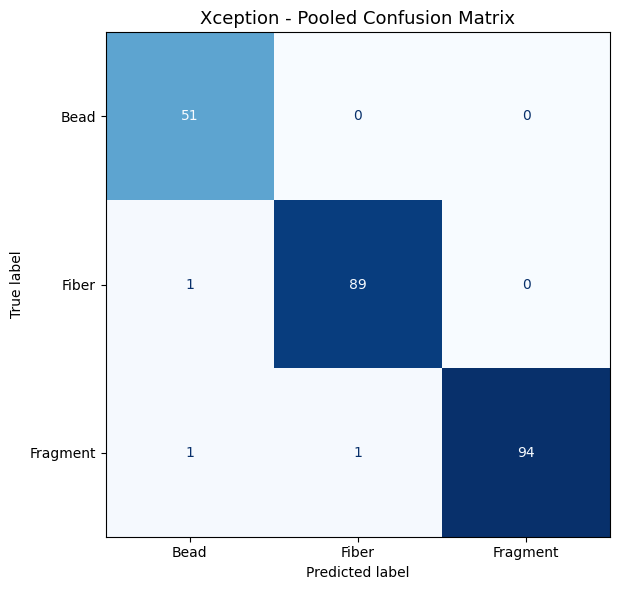

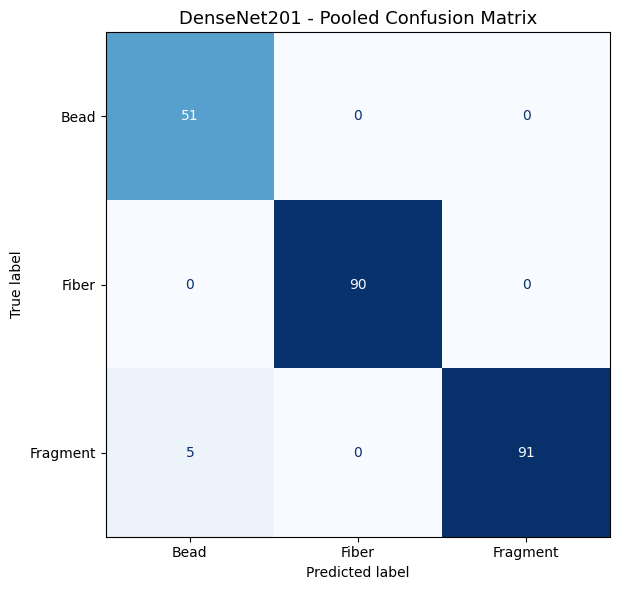

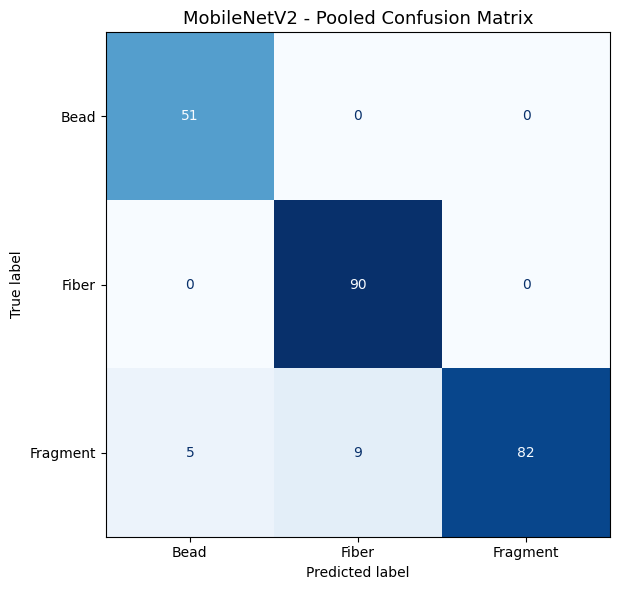

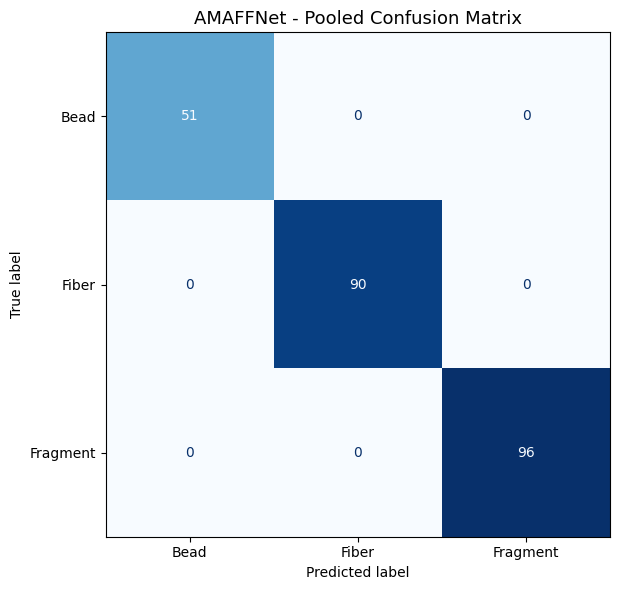

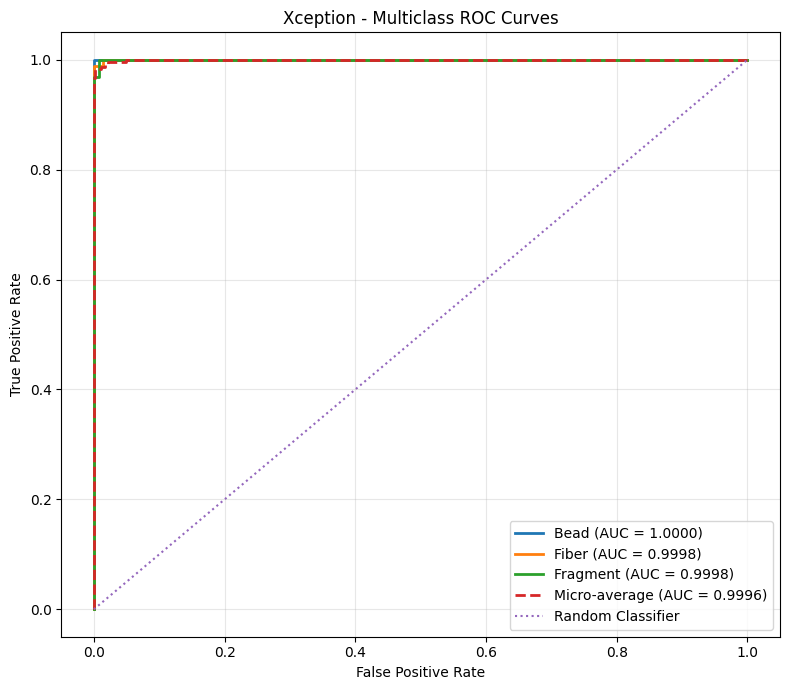

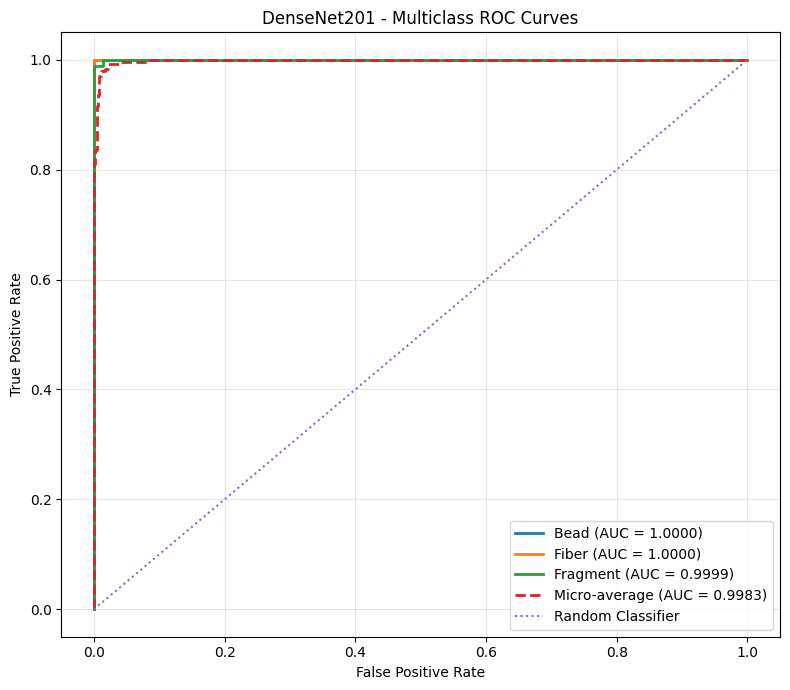

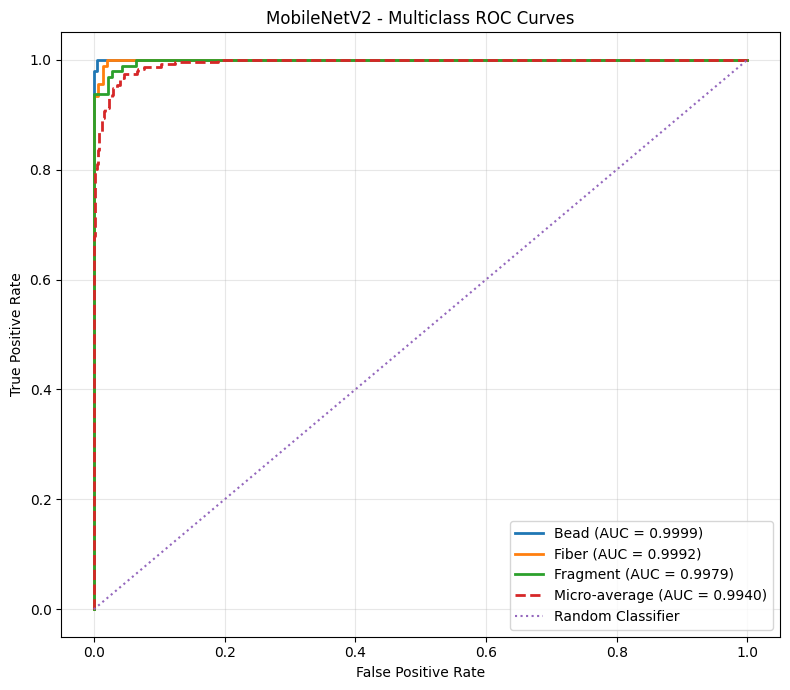

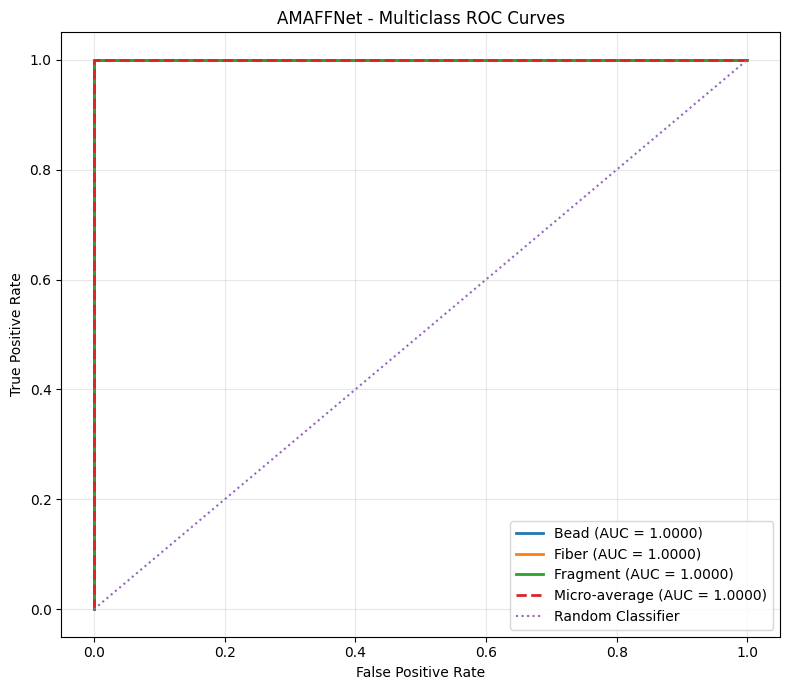


FIVE-FOLD MEAN AND STANDARD DEVIATION
      Model            Metric   Mean  Standard_Deviation
   Xception         Test_Loss 0.2885              0.0299
   Xception          Accuracy 0.9872              0.0190
   Xception   Precision_Macro 0.9844              0.0223
   Xception      Recall_Macro 0.9893              0.0158
   Xception          F1_Macro 0.9862              0.0199
   Xception Balanced_Accuracy 0.9893              0.0158
   Xception      Cohens_Kappa 0.9803              0.0293
   Xception               MCC 0.9809              0.0285
   Xception ROC_AUC_Macro_OVR 0.9997              0.0006
DenseNet201         Test_Loss 0.2832              0.0390
DenseNet201          Accuracy 0.9788              0.0261
DenseNet201   Precision_Macro 0.9730              0.0315
DenseNet201      Recall_Macro 0.9825              0.0215
DenseNet201          F1_Macro 0.9759              0.0294
DenseNet201 Balanced_Accuracy 0.9825              0.0215
DenseNet201      Cohens_Kappa 0.9676             

In [ ]:
# ================================================================
# STEP 10: COMPLETE EVALUATION USING SAVED FIVE-FOLD PREDICTIONS
# Models: Xception, DenseNet201, MobileNetV2 and AMAFFNet
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

# ------------------------------------------------
# 1. Define the main results directory
# ------------------------------------------------

ROOT_DIR = "/content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results"

# Folder to save all publication evaluation outputs
OUTPUT_DIR = os.path.join(ROOT_DIR, "Publication_Evaluation")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------
# 2. Specify the exact prediction file paths
# ------------------------------------------------

prediction_paths = {
    "Xception": os.path.join(
        ROOT_DIR, "Xception",
        "Xception_All_Fold_Predictions.csv"
    ),

    "DenseNet201": os.path.join(
        ROOT_DIR, "DenseNet201",
        "DenseNet201_All_Fold_Predictions.csv"
    ),

    "MobileNetV2": os.path.join(
        ROOT_DIR, "MobileNetV2",
        "MobileNetV2_All_Fold_Predictions.csv"
    ),

    "AMAFFNet": os.path.join(
        ROOT_DIR, "AMAFFNet_Fusion",
        "AMAFFNet_All_Fold_Predictions.csv"
    )
}

# ------------------------------------------------
# 3. Specify the five-fold metric file paths
# ------------------------------------------------

metric_paths = {
    "Xception": os.path.join(
        ROOT_DIR, "Xception",
        "Xception_5Fold_Complete_Metrics.csv"
    ),

    "DenseNet201": os.path.join(
        ROOT_DIR, "DenseNet201",
        "DenseNet201_5Fold_Results.csv"
    ),

    "MobileNetV2": os.path.join(
        ROOT_DIR, "MobileNetV2",
        "MobileNetV2_5Fold_Results.csv"
    ),

    "AMAFFNet": os.path.join(
        ROOT_DIR, "AMAFFNet_Fusion",
        "AMAFFNet_5Fold_Results.csv"
    )
}

# ------------------------------------------------
# 4. Verify all required files before processing
# ------------------------------------------------

for model_name, path in prediction_paths.items():

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Prediction file not found for {model_name}: {path}"
        )

for model_name, path in metric_paths.items():

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Five-fold metric file not found for {model_name}: {path}"
        )

print("All prediction and five-fold metric files verified.")

# ------------------------------------------------
# 5. Define class names and probability columns
# ------------------------------------------------

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]

CLASS_MAPPING = {
    0: "Bead",
    1: "Fiber",
    2: "Fragment"
}

PROBABILITY_COLUMNS = [
    "Probability_Bead",
    "Probability_Fiber",
    "Probability_Fragment"
]

# Convert numeric labels or class names into a common format
def standardize_labels(values):

    standardized = []

    for value in values:

        if pd.isna(value):
            raise ValueError("Missing class label detected.")

        # Handle numeric labels used by AMAFFNet
        if isinstance(value, (int, float, np.integer, np.floating)):
            if float(value).is_integer() and int(value) in CLASS_MAPPING:
                standardized.append(CLASS_MAPPING[int(value)])
                continue

        # Handle numeric labels stored as strings
        value_string = str(value).strip()

        if value_string in ["0", "1", "2"]:
            standardized.append(CLASS_MAPPING[int(value_string)])
        else:
            standardized.append(value_string.capitalize())

    return np.array(standardized)

# ------------------------------------------------
# 6. Load and standardize all prediction files
# ------------------------------------------------

predictions = {}

for model_name, path in prediction_paths.items():

    df = pd.read_csv(path)

    # Select the appropriate actual and predicted label columns
    if model_name == "AMAFFNet":
        actual_column = "Actual_Label"
        predicted_column = "Predicted_Label"
    else:
        actual_column = "True_Class"
        predicted_column = "Predicted_Class"

    # Verify the required columns
    required_columns = [
        actual_column,
        predicted_column
    ] + PROBABILITY_COLUMNS

    missing_columns = [
        col for col in required_columns if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{model_name}: Missing columns {missing_columns}"
        )

    # Standardize actual and predicted class labels
    y_true = standardize_labels(df[actual_column])
    y_pred = standardize_labels(df[predicted_column])

    # Read the predicted probability values
    y_prob = df[PROBABILITY_COLUMNS].to_numpy(dtype=float)

    # Check for invalid probability values
    if not np.isfinite(y_prob).all():
        raise ValueError(
            f"{model_name}: Invalid probability values detected."
        )

    if not np.allclose(y_prob.sum(axis=1), 1.0, atol=1e-3):
        raise ValueError(
            f"{model_name}: Probability rows do not sum to approximately 1."
        )

    if not set(y_true).issubset(set(CLASS_NAMES)):
        raise ValueError(f"{model_name}: Unexpected actual class labels.")

    if not set(y_pred).issubset(set(CLASS_NAMES)):
        raise ValueError(f"{model_name}: Unexpected predicted class labels.")

    # Save standardized results
    predictions[model_name] = {
        "data": df,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    print(
        f"{model_name}: {len(df)} predictions loaded successfully."
    )

# ------------------------------------------------
# 7. Verify consistency across all four models
# ------------------------------------------------

reference_actual = predictions["Xception"]["y_true"]

for model_name in predictions:

    current_actual = predictions[model_name]["y_true"]

    if not np.array_equal(reference_actual, current_actual):
        raise ValueError(
            f"Actual class labels differ in {model_name}."
        )

# Verify image identity and ordering across models
def get_image_identifiers(model_name):

    df = predictions[model_name]["data"]

    if model_name == "AMAFFNet":
        if "Image_Path" in df.columns:
            return df["Image_Path"].astype(str).to_numpy()
        return df["Filename"].astype(str).to_numpy()

    return df["Image_Path"].astype(str).to_numpy()


reference_images = get_image_identifiers("Xception")

for model_name in predictions:

    current_images = get_image_identifiers(model_name)

    if not np.array_equal(reference_images, current_images):
        raise ValueError(
            f"Image order or image identities differ in {model_name}."
        )

    # Each image should occur only once in the pooled OOF predictions
    if len(np.unique(current_images)) != len(current_images):
        raise ValueError(
            f"Duplicate image predictions detected in {model_name}."
        )

print("\nImage identity and actual-label consistency verified.")

# ------------------------------------------------
# 8. Calculate pooled evaluation metrics
# ------------------------------------------------

pooled_results = []
classification_reports = {}

for model_name, result in predictions.items():

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    y_prob = result["y_prob"]

    # Calculate macro one-vs-rest ROC-AUC
    y_true_binary = label_binarize(
        y_true,
        classes=CLASS_NAMES
    )

    roc_auc_macro = roc_auc_score(
        y_true_binary,
        y_prob,
        average="macro"
    )

    # Calculate evaluation metrics
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_Macro": precision_score(
            y_true, y_pred,
            labels=CLASS_NAMES,
            average="macro",
            zero_division=0
        ),
        "Recall_Macro": recall_score(
            y_true, y_pred,
            labels=CLASS_NAMES,
            average="macro",
            zero_division=0
        ),
        "F1_Macro": f1_score(
            y_true, y_pred,
            labels=CLASS_NAMES,
            average="macro",
            zero_division=0
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Cohens_Kappa": cohen_kappa_score(
            y_true, y_pred
        ),
        "MCC": matthews_corrcoef(
            y_true, y_pred
        ),
        "ROC_AUC_Macro_OVR": roc_auc_macro
    }

    pooled_results.append(metrics)

    # Generate detailed class-wise classification report
    report = classification_report(
        y_true,
        y_pred,
        labels=CLASS_NAMES,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    classification_reports[model_name] = pd.DataFrame(report).transpose()

    # Save classification report
    classification_reports[model_name].to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{model_name}_Pooled_Classification_Report.csv"
        )
    )

# Save the pooled comparison table
pooled_df = pd.DataFrame(pooled_results)

pooled_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "All_Models_Pooled_Evaluation_Metrics.csv"
    ),
    index=False
)

print("\nPOOLED EVALUATION METRICS")
print(pooled_df.round(4).to_string(index=False))

# ------------------------------------------------
# 9. Generate pooled confusion matrices
# ------------------------------------------------

for model_name, result in predictions.items():

    y_true = result["y_true"]
    y_pred = result["y_pred"]

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=CLASS_NAMES
    )

    # Save numerical confusion matrix
    cm_df = pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    )

    cm_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{model_name}_Pooled_Confusion_Matrix.csv"
        )
    )

    # Plot confusion matrix
    fig, ax = plt.subplots(figsize=(7, 6))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(
        f"{model_name} - Pooled Confusion Matrix",
        fontsize=13
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{model_name}_Pooled_Confusion_Matrix.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------
# 10. Generate class-wise ROC curves
# ------------------------------------------------

for model_name, result in predictions.items():

    y_true = result["y_true"]
    y_prob = result["y_prob"]

    # Convert actual class labels into binary format
    y_true_binary = label_binarize(
        y_true,
        classes=CLASS_NAMES
    )

    fig, ax = plt.subplots(figsize=(8, 7))

    class_auc_values = {}

    # Calculate and plot ROC curve for each class
    for i, class_name in enumerate(CLASS_NAMES):

        fpr, tpr, thresholds = roc_curve(
            y_true_binary[:, i],
            y_prob[:, i]
        )

        class_auc = auc(fpr, tpr)
        class_auc_values[class_name] = class_auc

        ax.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{class_name} (AUC = {class_auc:.4f})"
        )

    # Calculate micro-average ROC curve
    micro_fpr, micro_tpr, _ = roc_curve(
        y_true_binary.ravel(),
        y_prob.ravel()
    )

    micro_auc = auc(micro_fpr, micro_tpr)

    ax.plot(
        micro_fpr,
        micro_tpr,
        linestyle="--",
        linewidth=2,
        label=f"Micro-average (AUC = {micro_auc:.4f})"
    )

    # Reference diagonal
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle=":",
        linewidth=1.5,
        label="Random Classifier"
    )

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")

    ax.set_title(
        f"{model_name} - Multiclass ROC Curves"
    )

    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{model_name}_ROC_Curves.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    # Save class-wise AUC values
    auc_df = pd.DataFrame(
        list(class_auc_values.items()),
        columns=["Class", "ROC_AUC"]
    )

    auc_df.loc[len(auc_df)] = [
        "Micro_Average",
        micro_auc
    ]

    auc_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{model_name}_Classwise_ROC_AUC.csv"
        ),
        index=False
    )

# ------------------------------------------------
# 11. Calculate five-fold mean and standard deviation
# ------------------------------------------------

fold_summary = []

for model_name, path in metric_paths.items():

    fold_df = pd.read_csv(path)

    # Metrics available in all four models
    common_metrics = [
        "Test_Loss",
        "Accuracy",
        "Precision_Macro",
        "Recall_Macro",
        "F1_Macro",
        "Balanced_Accuracy",
        "Cohens_Kappa",
        "MCC",
        "ROC_AUC_Macro_OVR"
    ]

    # Verify that expected columns are available
    available_metrics = [
        col for col in common_metrics if col in fold_df.columns
    ]

    for metric in available_metrics:

        values = pd.to_numeric(
            fold_df[metric],
            errors="coerce"
        ).dropna()

        fold_summary.append({
            "Model": model_name,
            "Metric": metric,
            "Mean": values.mean(),
            "Standard_Deviation": values.std(ddof=1)
        })

fold_summary_df = pd.DataFrame(fold_summary)

fold_summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "All_Models_Five_Fold_Mean_Standard_Deviation.csv"
    ),
    index=False
)

# ------------------------------------------------
# 12. Display five-fold summary
# ------------------------------------------------

print("\nFIVE-FOLD MEAN AND STANDARD DEVIATION")
print(
    fold_summary_df.round(4).to_string(index=False)
)

# ------------------------------------------------
# 13. Save the final evaluation summary
# ------------------------------------------------

print("\n" + "=" * 65)
print("EVALUATION COMPLETED SUCCESSFULLY")
print("=" * 65)

print("\nAll outputs saved in:")
print(OUTPUT_DIR)

print("\nGenerated outputs include:")
print("1. Pooled evaluation metrics")
print("2. Pooled confusion matrices (CSV and PNG)")
print("3. Class-wise ROC curves (PNG)")
print("4. Class-wise ROC-AUC values")
print("5. Pooled classification reports")
print("6. Five-fold mean and standard deviation")
print("7. Comparative performance metrics")

In [ ]:

# ============================================================
# STEP 9: INSPECT ALL SAVED AMAFF-NET EVALUATION RESULTS
# No model training or prediction is performed in this cell.
# ============================================================

import os
import zipfile
import pandas as pd

# ------------------------------------------------------------
# Define the main result directory
# ------------------------------------------------------------

BASE_DIR = (
    '/content/drive/MyDrive/Microplastics_SEM/'
    'AMAFFNet_Results'
)

# ------------------------------------------------------------
# Define model display names and actual folder names
# ------------------------------------------------------------

MODEL_DIRS = {
    'Xception + SE': 'Xception',
    'DenseNet201': 'DenseNet201',
    'MobileNetV2': 'MobileNetV2',
    'AMAFFNet': 'AMAFFNet_Fusion'
}

# ------------------------------------------------------------
# Inspect the metric and prediction CSV files
# ------------------------------------------------------------

for model_name, folder_name in MODEL_DIRS.items():

    model_path = os.path.join(BASE_DIR, folder_name)

    print('\n' + '=' * 70)
    print('MODEL:', model_name)
    print('=' * 70)

    if not os.path.exists(model_path):
        print('Model result directory not found.')
        continue

    # Display available CSV files
    csv_files = [
        f for f in os.listdir(model_path)
        if f.lower().endswith('.csv')
    ]

    print('\nAvailable CSV files:')
    for filename in sorted(csv_files):
        print(' -', filename)

    # --------------------------------------------------------
    # Inspect the five-fold metric summary file
    # --------------------------------------------------------

    metric_files = [
        f for f in csv_files
        if '5fold' in f.lower()
        and 'result' in f.lower()
    ]

    # Xception uses a differently named metric file
    if model_name == 'Xception + SE':
        metric_files = [
            f for f in csv_files
            if 'complete_metrics' in f.lower()
        ]

    if metric_files:

        metric_path = os.path.join(
            model_path, metric_files[0]
        )

        metrics_df = pd.read_csv(metric_path)

        print('\nMETRIC FILE:', metric_files[0])
        print('Shape:', metrics_df.shape)
        print('Columns:', metrics_df.columns.tolist())
        print(metrics_df.head(10).to_string(index=False))

    # --------------------------------------------------------
    # Inspect the combined prediction file
    # --------------------------------------------------------

    prediction_files = [
        f for f in csv_files
        if 'all_fold_predictions' in f.lower()
    ]

    if prediction_files:

        prediction_path = os.path.join(
            model_path, prediction_files[0]
        )

        predictions_df = pd.read_csv(prediction_path)

        print('\nPREDICTION FILE:', prediction_files[0])
        print('Shape:', predictions_df.shape)
        print('Columns:', predictions_df.columns.tolist())

        print('\nFirst five prediction records:')
        print(predictions_df.head().to_string(index=False))

        # Identify columns that may contain probabilities
        probability_columns = [
            col for col in predictions_df.columns
            if any(word in col.lower()
                   for word in [
                       'prob', 'score',
                       'bead', 'fiber', 'fragment'
                   ])
        ]

        print('\nPossible class probability columns:')
        print(probability_columns)

    # --------------------------------------------------------
    # Inspect first-fold confusion matrix and report
    # --------------------------------------------------------

    for filename in sorted(csv_files):

        if 'fold_1_confusion_matrix' in filename.lower():

            cm_df = pd.read_csv(
                os.path.join(model_path, filename)
            )

            print('\nFOLD 1 CONFUSION MATRIX:')
            print(cm_df.to_string(index=False))

        if 'fold_1_classification_report' in filename.lower():

            report_df = pd.read_csv(
                os.path.join(model_path, filename)
            )

            print('\nFOLD 1 CLASSIFICATION REPORT:')
            print(report_df.to_string(index=False))


# ------------------------------------------------------------
# Inspect the existing ZIP archive
# ------------------------------------------------------------

ZIP_PATH = (
    '/content/drive/MyDrive/Microplastics_SEM/result.zip'
)

print('\n' + '=' * 70)
print('ZIP ARCHIVE INSPECTION')
print('=' * 70)

if os.path.exists(ZIP_PATH):

    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:

        zip_files = zip_ref.namelist()

        print('Total files in ZIP:', len(zip_files))

        for filename in zip_files[:100]:
            print(filename)

else:
    print('result.zip not found.')

print('\nRESULT FILE INSPECTION COMPLETED.')



MODEL: Xception + SE

Available CSV files:
 - Xception_5Fold_Complete_Metrics.csv
 - Xception_5Fold_Mean_Std_Complete.csv
 - Xception_All_Fold_Predictions.csv
 - Xception_Fold_1_Classification_Report.csv
 - Xception_Fold_1_Confusion_Matrix.csv
 - Xception_Fold_2_Classification_Report.csv
 - Xception_Fold_2_Confusion_Matrix.csv
 - Xception_Fold_3_Classification_Report.csv
 - Xception_Fold_3_Confusion_Matrix.csv
 - Xception_Fold_4_Classification_Report.csv
 - Xception_Fold_4_Confusion_Matrix.csv
 - Xception_Fold_5_Classification_Report.csv
 - Xception_Fold_5_Confusion_Matrix.csv

METRIC FILE: Xception_5Fold_Complete_Metrics.csv
Shape: (5, 10)
Columns: ['Fold', 'Test_Loss', 'Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Macro', 'Balanced_Accuracy', 'Cohens_Kappa', 'MCC', 'ROC_AUC_Macro_OVR']
 Fold  Test_Loss  Accuracy  Precision_Macro  Recall_Macro  F1_Macro  Balanced_Accuracy  Cohens_Kappa      MCC  ROC_AUC_Macro_OVR
    1   0.247367  1.000000         1.000000      1.000000  1.00000

In [ ]:

# ============================================================
# STEP 9: INSPECT ALL SAVED AMAFF-NET EVALUATION RESULTS
# No model training or prediction is performed in this cell.
# ============================================================

import os
import zipfile
import pandas as pd

# ------------------------------------------------------------
# Define the main result directory
# ------------------------------------------------------------

BASE_DIR = (
    '/content/drive/MyDrive/Microplastics_SEM/'
    'AMAFFNet_Results'
)

# ------------------------------------------------------------
# Define model display names and actual folder names
# ------------------------------------------------------------

MODEL_DIRS = {
    'Xception + SE': 'Xception',
    'DenseNet201': 'DenseNet201',
    'MobileNetV2': 'MobileNetV2',
    'AMAFFNet': 'AMAFFNet_Fusion'
}

# ------------------------------------------------------------
# Inspect the metric and prediction CSV files
# ------------------------------------------------------------

for model_name, folder_name in MODEL_DIRS.items():

    model_path = os.path.join(BASE_DIR, folder_name)

    print('\n' + '=' * 70)
    print('MODEL:', model_name)
    print('=' * 70)

    if not os.path.exists(model_path):
        print('Model result directory not found.')
        continue

    # Display available CSV files
    csv_files = [
        f for f in os.listdir(model_path)
        if f.lower().endswith('.csv')
    ]

    print('\nAvailable CSV files:')
    for filename in sorted(csv_files):
        print(' -', filename)

    # --------------------------------------------------------
    # Inspect the five-fold metric summary file
    # --------------------------------------------------------

    metric_files = [
        f for f in csv_files
        if '5fold' in f.lower()
        and 'result' in f.lower()
    ]

    # Xception uses a differently named metric file
    if model_name == 'Xception + SE':
        metric_files = [
            f for f in csv_files
            if 'complete_metrics' in f.lower()
        ]

    if metric_files:

        metric_path = os.path.join(
            model_path, metric_files[0]
        )

        metrics_df = pd.read_csv(metric_path)

        print('\nMETRIC FILE:', metric_files[0])
        print('Shape:', metrics_df.shape)
        print('Columns:', metrics_df.columns.tolist())
        print(metrics_df.head(10).to_string(index=False))

    # --------------------------------------------------------
    # Inspect the combined prediction file
    # --------------------------------------------------------

    prediction_files = [
        f for f in csv_files
        if 'all_fold_predictions' in f.lower()
    ]

    if prediction_files:

        prediction_path = os.path.join(
            model_path, prediction_files[0]
        )

        predictions_df = pd.read_csv(prediction_path)

        print('\nPREDICTION FILE:', prediction_files[0])
        print('Shape:', predictions_df.shape)
        print('Columns:', predictions_df.columns.tolist())

        print('\nFirst five prediction records:')
        print(predictions_df.head().to_string(index=False))

        # Identify columns that may contain probabilities
        probability_columns = [
            col for col in predictions_df.columns
            if any(word in col.lower()
                   for word in [
                       'prob', 'score',
                       'bead', 'fiber', 'fragment'
                   ])
        ]

        print('\nPossible class probability columns:')
        print(probability_columns)

    # --------------------------------------------------------
    # Inspect first-fold confusion matrix and report
    # --------------------------------------------------------

    for filename in sorted(csv_files):

        if 'fold_1_confusion_matrix' in filename.lower():

            cm_df = pd.read_csv(
                os.path.join(model_path, filename)
            )

            print('\nFOLD 1 CONFUSION MATRIX:')
            print(cm_df.to_string(index=False))

        if 'fold_1_classification_report' in filename.lower():

            report_df = pd.read_csv(
                os.path.join(model_path, filename)
            )

            print('\nFOLD 1 CLASSIFICATION REPORT:')
            print(report_df.to_string(index=False))


# ------------------------------------------------------------
# Inspect the existing ZIP archive
# ------------------------------------------------------------

ZIP_PATH = (
    '/content/drive/MyDrive/Microplastics_SEM/result.zip'
)

print('\n' + '=' * 70)
print('ZIP ARCHIVE INSPECTION')
print('=' * 70)

if os.path.exists(ZIP_PATH):

    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:

        zip_files = zip_ref.namelist()

        print('Total files in ZIP:', len(zip_files))

        for filename in zip_files[:100]:
            print(filename)

else:
    print('result.zip not found.')

print('\nRESULT FILE INSPECTION COMPLETED.')



MODEL: Xception + SE

Available CSV files:
 - Xception_5Fold_Complete_Metrics.csv
 - Xception_5Fold_Mean_Std_Complete.csv
 - Xception_All_Fold_Predictions.csv
 - Xception_Fold_1_Classification_Report.csv
 - Xception_Fold_1_Confusion_Matrix.csv
 - Xception_Fold_2_Classification_Report.csv
 - Xception_Fold_2_Confusion_Matrix.csv
 - Xception_Fold_3_Classification_Report.csv
 - Xception_Fold_3_Confusion_Matrix.csv
 - Xception_Fold_4_Classification_Report.csv
 - Xception_Fold_4_Confusion_Matrix.csv
 - Xception_Fold_5_Classification_Report.csv
 - Xception_Fold_5_Confusion_Matrix.csv

METRIC FILE: Xception_5Fold_Complete_Metrics.csv
Shape: (5, 10)
Columns: ['Fold', 'Test_Loss', 'Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Macro', 'Balanced_Accuracy', 'Cohens_Kappa', 'MCC', 'ROC_AUC_Macro_OVR']
 Fold  Test_Loss  Accuracy  Precision_Macro  Recall_Macro  F1_Macro  Balanced_Accuracy  Cohens_Kappa      MCC  ROC_AUC_Macro_OVR
    1   0.247367  1.000000         1.000000      1.000000  1.00000


Verified: Xception + SE
Prediction: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/Xception/Xception_All_Fold_Predictions.csv
Metrics: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/Xception/Xception_5Fold_Complete_Metrics.csv

Verified: DenseNet201
Prediction: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_All_Fold_Predictions.csv
Metrics: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_5Fold_Results.csv

Verified: MobileNetV2
Prediction: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/MobileNetV2/MobileNetV2_All_Fold_Predictions.csv
Metrics: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/MobileNetV2/MobileNetV2_5Fold_Results.csv

Verified: AMAFFNet
Prediction: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/AMAFFNet_All_Fold_Predictions.csv
Metrics: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/AMAFFNet_5Fold_Results.cs

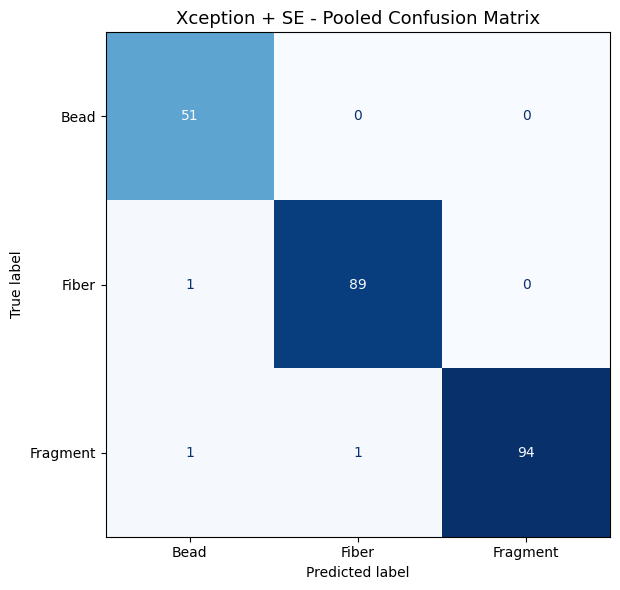


Xception + SE Confusion Matrix:
          Bead  Fiber  Fragment
Bead        51      0         0
Fiber        1     89         0
Fragment     1      1        94


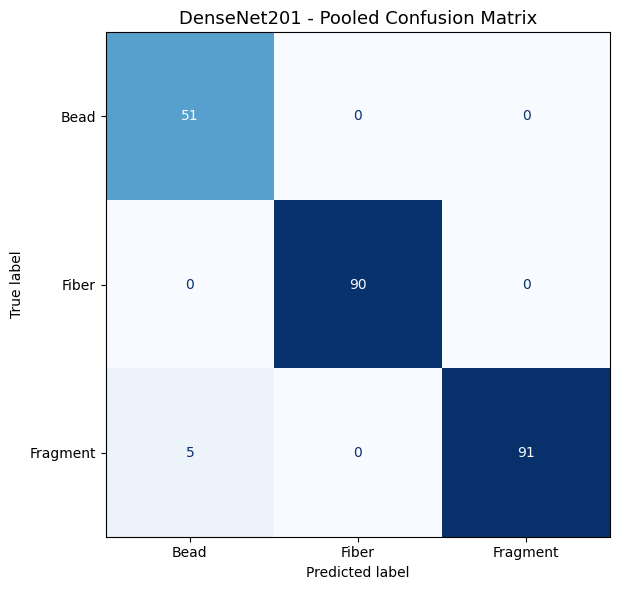


DenseNet201 Confusion Matrix:
          Bead  Fiber  Fragment
Bead        51      0         0
Fiber        0     90         0
Fragment     5      0        91


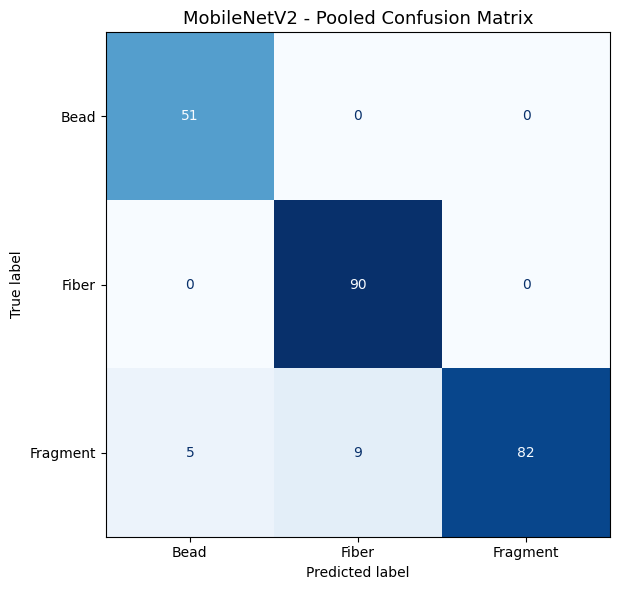


MobileNetV2 Confusion Matrix:
          Bead  Fiber  Fragment
Bead        51      0         0
Fiber        0     90         0
Fragment     5      9        82


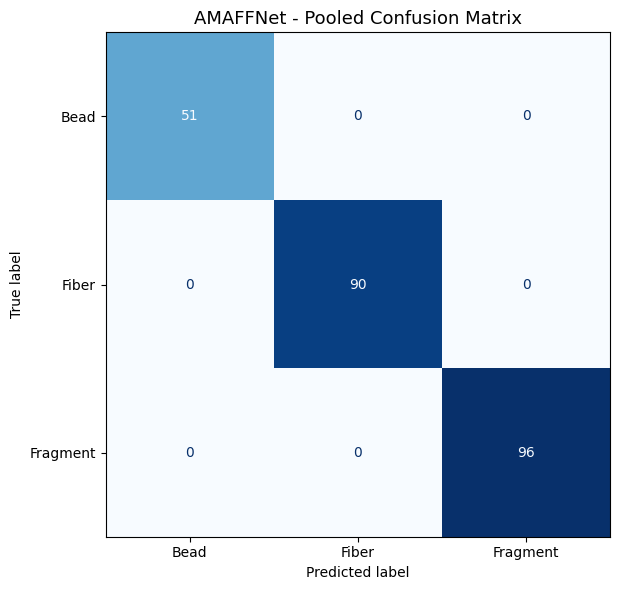


AMAFFNet Confusion Matrix:
          Bead  Fiber  Fragment
Bead        51      0         0
Fiber        0     90         0
Fragment     0      0        96


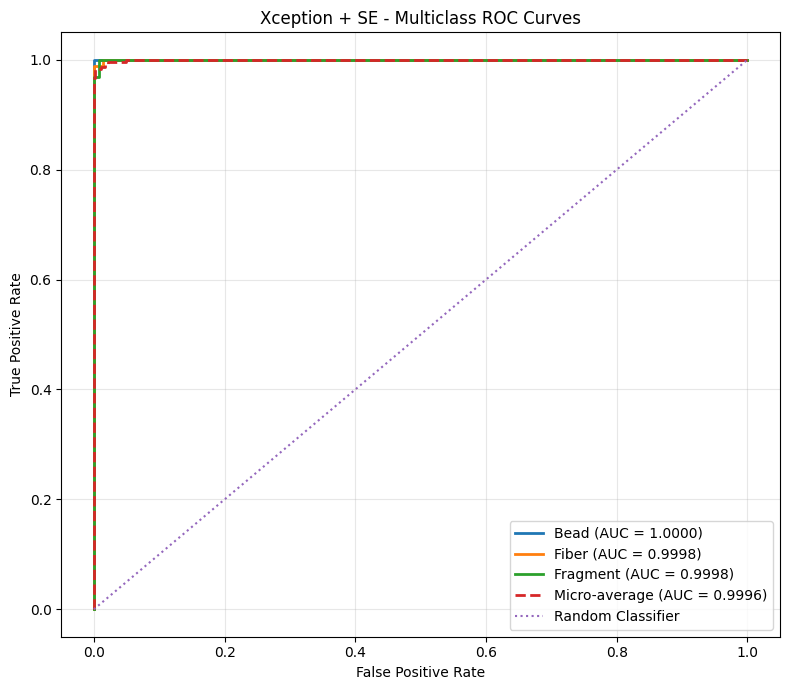


Xception + SE Class-wise ROC-AUC:
        Class  ROC_AUC
         Bead   1.0000
        Fiber   0.9998
     Fragment   0.9998
Micro_Average   0.9996


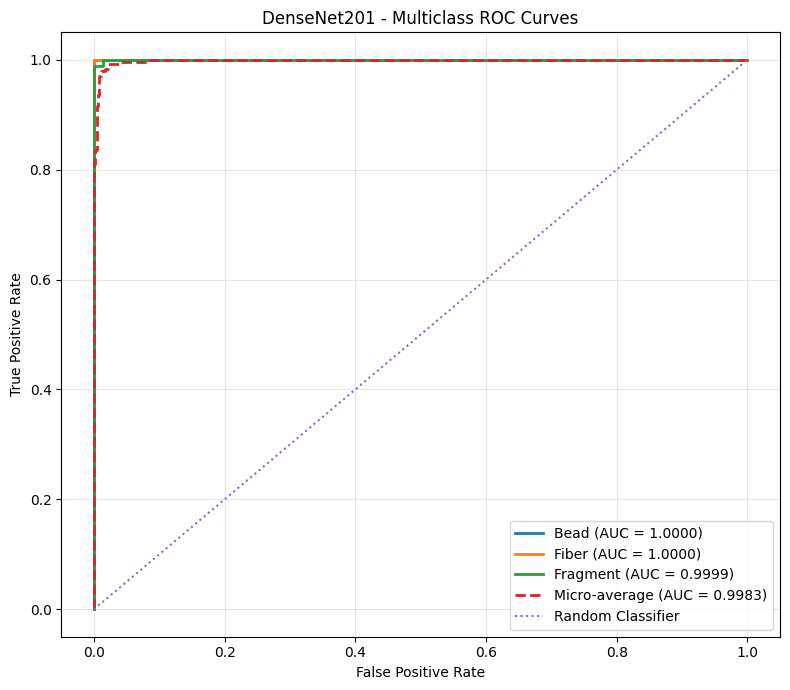


DenseNet201 Class-wise ROC-AUC:
        Class  ROC_AUC
         Bead   1.0000
        Fiber   1.0000
     Fragment   0.9999
Micro_Average   0.9983


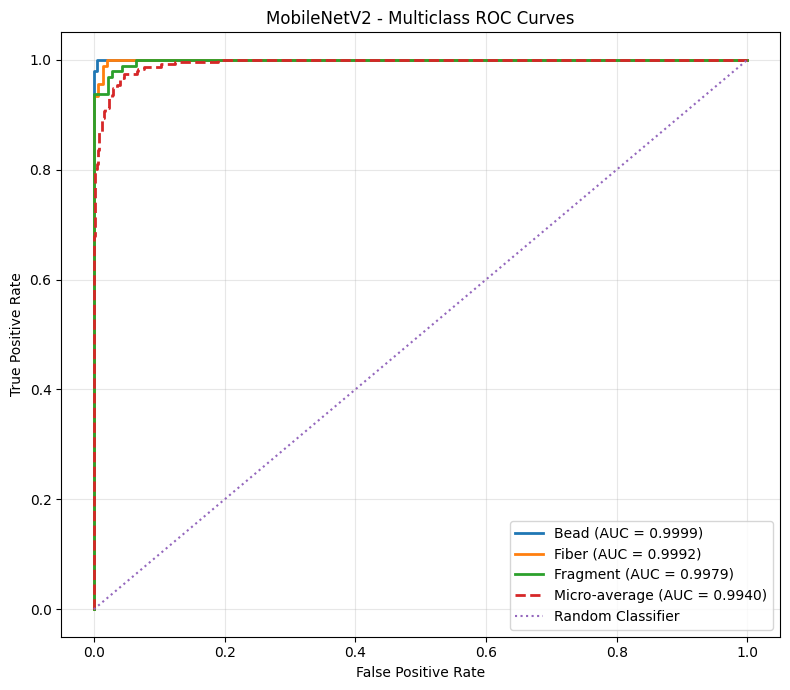


MobileNetV2 Class-wise ROC-AUC:
        Class  ROC_AUC
         Bead   0.9999
        Fiber   0.9992
     Fragment   0.9979
Micro_Average   0.9940


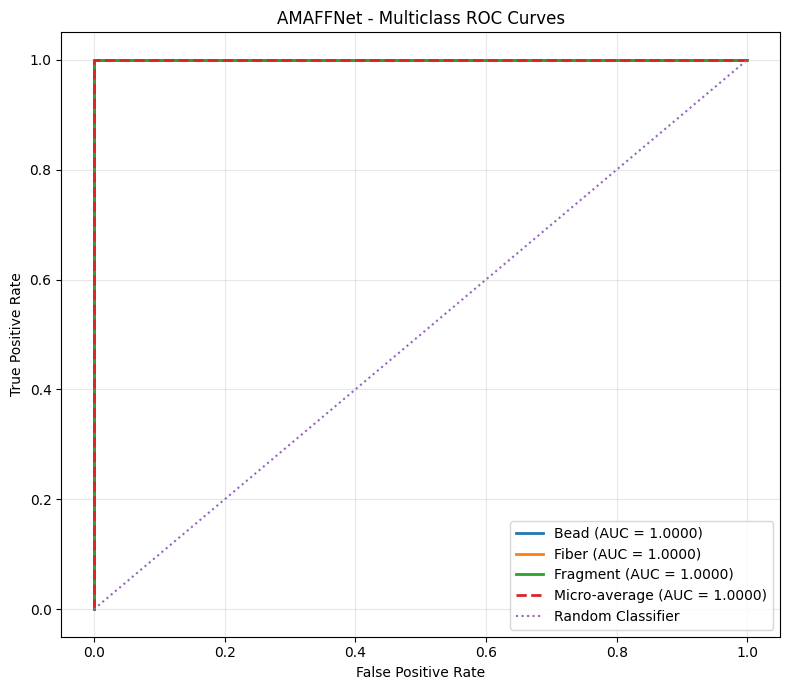


AMAFFNet Class-wise ROC-AUC:
        Class  ROC_AUC
         Bead      1.0
        Fiber      1.0
     Fragment      1.0
Micro_Average      1.0

FIVE-FOLD MEAN AND STANDARD DEVIATION
        Model            Metric   Mean  Standard_Deviation
Xception + SE         Test_Loss 0.2885              0.0299
Xception + SE          Accuracy 0.9872              0.0190
Xception + SE   Precision_Macro 0.9844              0.0223
Xception + SE      Recall_Macro 0.9893              0.0158
Xception + SE          F1_Macro 0.9862              0.0199
Xception + SE Balanced_Accuracy 0.9893              0.0158
Xception + SE      Cohens_Kappa 0.9803              0.0293
Xception + SE               MCC 0.9809              0.0285
Xception + SE ROC_AUC_Macro_OVR 0.9997              0.0006
  DenseNet201         Test_Loss 0.2832              0.0390
  DenseNet201          Accuracy 0.9788              0.0261
  DenseNet201   Precision_Macro 0.9730              0.0315
  DenseNet201      Recall_Macro 0.9825           

In [ ]:

# ================================================================
# STEP 10: COMPLETE EVALUATION OF ALL FOUR MODELS
#
# Models:
# 1. Xception + SE
# 2. DenseNet201
# 3. MobileNetV2
# 4. Proposed AMAFFNet
#
# Evaluation:
# - Pooled classification metrics
# - Confusion matrices
# - Classification reports
# - Class-wise ROC curves and AUC
# - Five-fold mean and standard deviation
# - Comparative performance table
#
# IMPORTANT:
# Uses existing saved predictions and metrics.
# No model training or prediction is performed.
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

# ---------------------------------------------------------------
# 1. Define directories
# ---------------------------------------------------------------

ROOT_DIR = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results"
)

# Create a separate folder for publication evaluation outputs
OUTPUT_DIR = os.path.join(
    ROOT_DIR,
    "Publication_Evaluation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------------------------------------------------------
# 2. Define model names and their actual folder names
# ---------------------------------------------------------------

MODEL_DIRS = {
    "Xception + SE": "Xception",
    "DenseNet201": "DenseNet201",
    "MobileNetV2": "MobileNetV2",
    "AMAFFNet": "AMAFFNet_Fusion"
}

# ---------------------------------------------------------------
# 3. Define prediction and metric filenames
# ---------------------------------------------------------------

PREDICTION_FILES = {
    "Xception + SE": "Xception_All_Fold_Predictions.csv",
    "DenseNet201": "DenseNet201_All_Fold_Predictions.csv",
    "MobileNetV2": "MobileNetV2_All_Fold_Predictions.csv",
    "AMAFFNet": "AMAFFNet_All_Fold_Predictions.csv"
}

METRIC_FILES = {
    "Xception + SE": "Xception_5Fold_Complete_Metrics.csv",
    "DenseNet201": "DenseNet201_5Fold_Results.csv",
    "MobileNetV2": "MobileNetV2_5Fold_Results.csv",
    "AMAFFNet": "AMAFFNet_5Fold_Results.csv"
}

# ---------------------------------------------------------------
# 4. Define class names and probability columns
# ---------------------------------------------------------------

CLASS_NAMES = [
    "Bead",
    "Fiber",
    "Fragment"
]

CLASS_MAPPING = {
    0: "Bead",
    1: "Fiber",
    2: "Fragment"
}

PROBABILITY_COLUMNS = [
    "Probability_Bead",
    "Probability_Fiber",
    "Probability_Fragment"
]

# ---------------------------------------------------------------
# 5. Verify all required files
# ---------------------------------------------------------------

prediction_paths = {}
metric_paths = {}

for display_name, folder_name in MODEL_DIRS.items():

    model_folder = os.path.join(
        ROOT_DIR,
        folder_name
    )

    prediction_path = os.path.join(
        model_folder,
        PREDICTION_FILES[display_name]
    )

    metric_path = os.path.join(
        model_folder,
        METRIC_FILES[display_name]
    )

    if not os.path.isfile(prediction_path):
        raise FileNotFoundError(
            f"Prediction file missing: {prediction_path}"
        )

    if not os.path.isfile(metric_path):
        raise FileNotFoundError(
            f"Metric file missing: {metric_path}"
        )

    prediction_paths[display_name] = prediction_path
    metric_paths[display_name] = metric_path

    print(f"\nVerified: {display_name}")
    print("Prediction:", prediction_path)
    print("Metrics:", metric_path)

print("\nAll four models and their files are verified.")

# ---------------------------------------------------------------
# 6. Function to standardize class labels
# ---------------------------------------------------------------

def standardize_labels(values):

    standardized = []

    for value in values:

        # Handle missing labels
        if pd.isna(value):
            raise ValueError("Missing class label detected.")

        # Convert numeric labels into class names
        if isinstance(
            value,
            (int, float, np.integer, np.floating)
        ):

            if float(value).is_integer():
                integer_value = int(value)

                if integer_value in CLASS_MAPPING:
                    standardized.append(
                        CLASS_MAPPING[integer_value]
                    )
                    continue

        # Handle numeric labels stored as strings
        value_string = str(value).strip()

        if value_string in ["0", "1", "2"]:

            standardized.append(
                CLASS_MAPPING[int(value_string)]
            )

        else:
            standardized.append(value_string.capitalize())

    return np.array(standardized)

# ---------------------------------------------------------------
# 7. Load all saved out-of-fold predictions
# ---------------------------------------------------------------

predictions = {}

for model_name, prediction_path in prediction_paths.items():

    df = pd.read_csv(prediction_path)

    # Select actual and predicted label columns
    if model_name == "AMAFFNet":

        actual_column = "Actual_Label"
        predicted_column = "Predicted_Label"

    else:

        actual_column = "True_Class"
        predicted_column = "Predicted_Class"

    # Check required columns
    required_columns = [
        actual_column,
        predicted_column
    ] + PROBABILITY_COLUMNS

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:

        raise ValueError(
            f"{model_name}: Missing columns {missing_columns}"
        )

    # Convert actual and predicted labels
    y_true = standardize_labels(
        df[actual_column]
    )

    y_pred = standardize_labels(
        df[predicted_column]
    )

    # Load class probability values
    y_prob = df[
        PROBABILITY_COLUMNS
    ].to_numpy(dtype=float)

    # Verify probability values
    if not np.isfinite(y_prob).all():

        raise ValueError(
            f"{model_name}: Invalid probability values."
        )

    if np.any(y_prob < 0) or np.any(y_prob > 1):

        raise ValueError(
            f"{model_name}: Probability outside [0, 1]."
        )

    if not np.allclose(
        y_prob.sum(axis=1),
        1.0,
        atol=1e-3
    ):

        raise ValueError(
            f"{model_name}: Probability rows do not sum to 1."
        )

    if not set(y_true).issubset(set(CLASS_NAMES)):
        raise ValueError(
            f"{model_name}: Unexpected actual labels."
        )

    if not set(y_pred).issubset(set(CLASS_NAMES)):
        raise ValueError(
            f"{model_name}: Unexpected predicted labels."
        )

    # Store all results
    predictions[model_name] = {
        "data": df,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    print(
        f"{model_name}: {len(df)} predictions loaded."
    )

# ---------------------------------------------------------------
# 8. Verify image identity and actual-label consistency
# ---------------------------------------------------------------

def get_image_identifiers(model_name):

    df = predictions[model_name]["data"]

    if model_name == "AMAFFNet":

        if "Image_Path" in df.columns:
            return df["Image_Path"].astype(str).to_numpy()

        return df["Filename"].astype(str).to_numpy()

    return df["Image_Path"].astype(str).to_numpy()


reference_name = "Xception + SE"

reference_images = get_image_identifiers(
    reference_name
)

reference_actual = predictions[
    reference_name
]["y_true"]

for model_name in predictions:

    current_images = get_image_identifiers(
        model_name
    )

    current_actual = predictions[
        model_name
    ]["y_true"]

    # Check whether the image ordering is identical
    if not np.array_equal(
        reference_images,
        current_images
    ):

        raise ValueError(
            f"Image order differs in {model_name}."
        )

    # Check whether actual labels are identical
    if not np.array_equal(
        reference_actual,
        current_actual
    ):

        raise ValueError(
            f"Actual labels differ in {model_name}."
        )

    # Check for repeated image identifiers
    if len(np.unique(current_images)) != len(current_images):

        raise ValueError(
            f"Duplicate image predictions detected in {model_name}."
        )

print("\nImage identity and actual-label consistency verified.")

# ---------------------------------------------------------------
# 9. Calculate pooled evaluation metrics
# ---------------------------------------------------------------

pooled_results = []
classification_reports = {}

for model_name, result in predictions.items():

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    y_prob = result["y_prob"]

    # Convert labels into one-vs-rest binary representation
    y_true_binary = label_binarize(
        y_true,
        classes=CLASS_NAMES
    )

    # Calculate macro ROC-AUC
    roc_auc_macro = roc_auc_score(
        y_true_binary,
        y_prob,
        average="macro"
    )

    # Calculate all pooled evaluation metrics
    metrics = {

        "Model": model_name,

        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Precision_Macro": precision_score(
            y_true,
            y_pred,
            labels=CLASS_NAMES,
            average="macro",
            zero_division=0
        ),

        "Recall_Macro": recall_score(
            y_true,
            y_pred,
            labels=CLASS_NAMES,
            average="macro",
            zero_division=0
        ),

        "F1_Macro": f1_score(
            y_true,
            y_pred,
            labels=CLASS_NAMES,
            average="macro",
            zero_division=0
        ),

        "Balanced_Accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "Cohens_Kappa": cohen_kappa_score(
            y_true,
            y_pred
        ),

        "MCC": matthews_corrcoef(
            y_true,
            y_pred
        ),

        "ROC_AUC_Macro_OVR": roc_auc_macro
    }

    pooled_results.append(metrics)

    # Generate detailed class-wise classification report
    report = classification_report(
        y_true,
        y_pred,
        labels=CLASS_NAMES,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(
        report
    ).transpose()

    classification_reports[model_name] = report_df

    # Save report with publication model name
    safe_name = model_name.replace(" + ", "_")

    report_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{safe_name}_Pooled_Classification_Report.csv"
        )
    )

# Create the pooled comparison table
pooled_df = pd.DataFrame(
    pooled_results
)

# Save pooled evaluation metrics
pooled_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "All_Models_Pooled_Evaluation_Metrics.csv"
    ),
    index=False
)

print("\n" + "=" * 80)
print("POOLED EVALUATION METRICS")
print("=" * 80)

print(
    pooled_df.round(4).to_string(index=False)
)

# ---------------------------------------------------------------
# 10. Generate pooled confusion matrices
# ---------------------------------------------------------------

for model_name, result in predictions.items():

    y_true = result["y_true"]
    y_pred = result["y_pred"]

    # Calculate confusion matrix in fixed class order
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=CLASS_NAMES
    )

    # Save numerical confusion matrix
    cm_df = pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    )

    cm_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{model_name.replace(' + ', '_')}_Pooled_Confusion_Matrix.csv"
        )
    )

    # Plot confusion matrix
    fig, ax = plt.subplots(
        figsize=(7, 6)
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(
        f"{model_name} - Pooled Confusion Matrix",
        fontsize=13
    )

    plt.tight_layout()

    # Save figure at publication resolution
    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{model_name.replace(' + ', '_')}_Pooled_Confusion_Matrix.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(f"\n{model_name} Confusion Matrix:")
    print(cm_df)

# ---------------------------------------------------------------
# 11. Generate class-wise ROC curves
# ---------------------------------------------------------------

for model_name, result in predictions.items():

    y_true = result["y_true"]
    y_prob = result["y_prob"]

    # Convert actual labels into binary format
    y_true_binary = label_binarize(
        y_true,
        classes=CLASS_NAMES
    )

    fig, ax = plt.subplots(
        figsize=(8, 7)
    )

    auc_results = []

    # Calculate ROC for each microplastic category
    for i, class_name in enumerate(CLASS_NAMES):

        fpr, tpr, thresholds = roc_curve(
            y_true_binary[:, i],
            y_prob[:, i]
        )

        class_auc = auc(
            fpr,
            tpr
        )

        auc_results.append({
            "Class": class_name,
            "ROC_AUC": class_auc
        })

        ax.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{class_name} (AUC = {class_auc:.4f})"
        )

    # Calculate micro-average ROC curve
    micro_fpr, micro_tpr, _ = roc_curve(
        y_true_binary.ravel(),
        y_prob.ravel()
    )

    micro_auc = auc(
        micro_fpr,
        micro_tpr
    )

    ax.plot(
        micro_fpr,
        micro_tpr,
        linestyle="--",
        linewidth=2,
        label=f"Micro-average (AUC = {micro_auc:.4f})"
    )

    # Random classification reference line
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle=":",
        linewidth=1.5,
        label="Random Classifier"
    )

    ax.set_xlabel(
        "False Positive Rate"
    )

    ax.set_ylabel(
        "True Positive Rate"
    )

    ax.set_title(
        f"{model_name} - Multiclass ROC Curves"
    )

    ax.legend(
        loc="lower right"
    )

    ax.grid(
        alpha=0.3
    )

    plt.tight_layout()

    # Save ROC curve
    safe_name = model_name.replace(" + ", "_")

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{safe_name}_ROC_Curves.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    # Save class-wise AUC values
    auc_df = pd.DataFrame(
        auc_results
    )

    auc_df.loc[len(auc_df)] = {
        "Class": "Micro_Average",
        "ROC_AUC": micro_auc
    }

    auc_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{safe_name}_Classwise_ROC_AUC.csv"
        ),
        index=False
    )

    print(f"\n{model_name} Class-wise ROC-AUC:")
    print(auc_df.round(4).to_string(index=False))

# ---------------------------------------------------------------
# 12. Calculate five-fold mean and standard deviation
# ---------------------------------------------------------------

fold_summary = []

for model_name, metric_path in metric_paths.items():

    fold_df = pd.read_csv(
        metric_path
    )

    # Metrics common to all four saved result files
    common_metrics = [
        "Test_Loss",
        "Accuracy",
        "Precision_Macro",
        "Recall_Macro",
        "F1_Macro",
        "Balanced_Accuracy",
        "Cohens_Kappa",
        "MCC",
        "ROC_AUC_Macro_OVR"
    ]

    # Calculate mean and standard deviation across folds
    for metric in common_metrics:

        if metric not in fold_df.columns:
            continue

        values = pd.to_numeric(
            fold_df[metric],
            errors="coerce"
        ).dropna()

        fold_summary.append({

            "Model": model_name,

            "Metric": metric,

            "Mean": values.mean(),

            "Standard_Deviation": values.std(
                ddof=1
            )
        })

fold_summary_df = pd.DataFrame(
    fold_summary
)

# Save five-fold summary
fold_summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "All_Models_Five_Fold_Mean_Standard_Deviation.csv"
    ),
    index=False
)

print("\n" + "=" * 80)
print("FIVE-FOLD MEAN AND STANDARD DEVIATION")
print("=" * 80)

print(
    fold_summary_df.round(4).to_string(index=False)
)

# ---------------------------------------------------------------
# 13. Generate a publication-ready comparison table
#     with five-fold mean and standard deviation
# ---------------------------------------------------------------

publication_rows = []

for model_name, metric_path in metric_paths.items():

    fold_df = pd.read_csv(
        metric_path
    )

    row = {
        "Model": model_name
    }

    # Include metrics with mean ± standard deviation
    for metric in [
        "Accuracy",
        "Precision_Macro",
        "Recall_Macro",
        "F1_Macro",
        "Balanced_Accuracy",
        "Cohens_Kappa",
        "MCC",
        "ROC_AUC_Macro_OVR"
    ]:

        if metric in fold_df.columns:

            values = pd.to_numeric(
                fold_df[metric],
                errors="coerce"
            ).dropna()

            row[metric] = (
                f"{values.mean():.4f} ± "
                f"{values.std(ddof=1):.4f}"
            )

    publication_rows.append(row)

publication_df = pd.DataFrame(
    publication_rows
)

publication_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Publication_Ready_Five_Fold_Comparison.csv"
    ),
    index=False
)

print("\nPUBLICATION-READY FIVE-FOLD COMPARISON")
print(
    publication_df.to_string(index=False)
)

# ---------------------------------------------------------------
# 14. Save a final evaluation completion summary
# ---------------------------------------------------------------

print("\n" + "=" * 80)
print("ALL EVALUATIONS COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nModels evaluated:")

for model_name in MODEL_DIRS:
    print("-", model_name)

print("\nNumber of pooled predictions per model:")

for model_name, result in predictions.items():
    print(
        f"{model_name}: {len(result['y_true'])}"
    )

print("\nAll evaluation outputs saved in:")
print(OUTPUT_DIR)

print("\nGenerated files include:")
print("1. All_Models_Pooled_Evaluation_Metrics.csv")
print("2. Individual pooled confusion matrices (CSV)")
print("3. Individual pooled confusion matrix figures (PNG)")
print("4. Individual classification reports (CSV)")
print("5. Individual ROC curves (PNG)")
print("6. Class-wise ROC-AUC values (CSV)")
print("7. All_Models_Five_Fold_Mean_Standard_Deviation.csv")
print("8. Publication_Ready_Five_Fold_Comparison.csv")

print("\nSTEP 10 COMPLETED.")



Verified: Xception + SE
Prediction: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/Xception/Xception_All_Fold_Predictions.csv
Metrics: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/Xception/Xception_5Fold_Complete_Metrics.csv

Verified: DenseNet201 + SE
Prediction: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_All_Fold_Predictions.csv
Metrics: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/DenseNet201/DenseNet201_5Fold_Results.csv

Verified: MobileNetV2 + SE
Prediction: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/MobileNetV2/MobileNetV2_All_Fold_Predictions.csv
Metrics: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/MobileNetV2/MobileNetV2_5Fold_Results.csv

Verified: AMAFFNet
Prediction: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/AMAFFNet_All_Fold_Predictions.csv
Metrics: /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/AMAFFNet_5Fold_

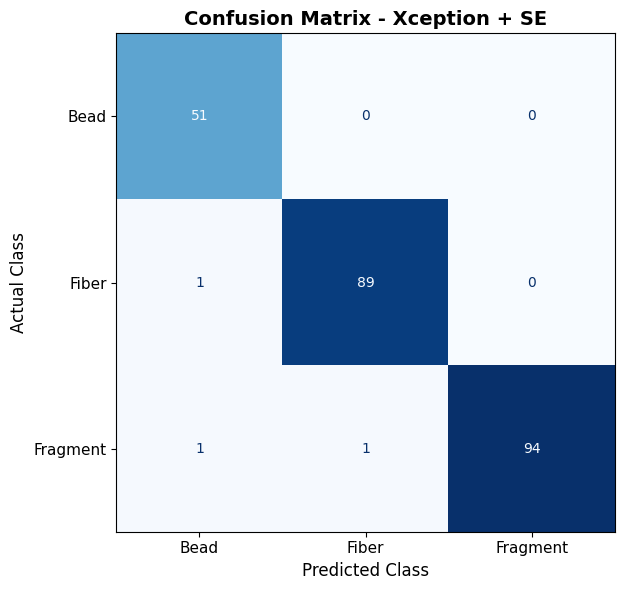


Xception + SE Confusion Matrix:
          Bead  Fiber  Fragment
Bead        51      0         0
Fiber        1     89         0
Fragment     1      1        94


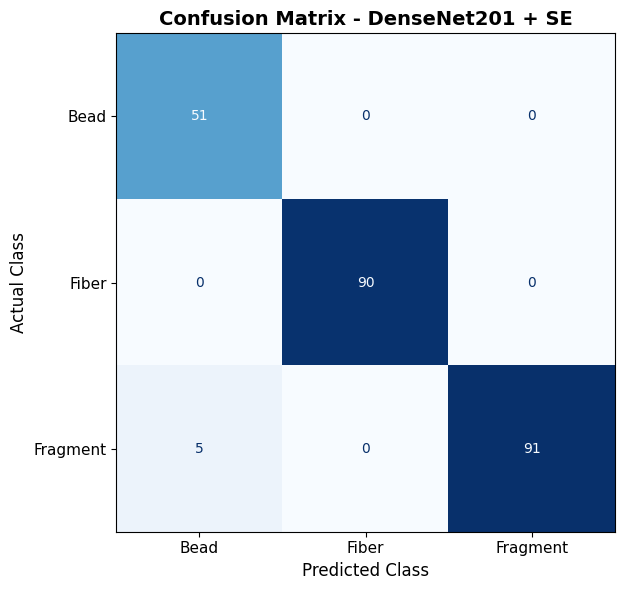


DenseNet201 + SE Confusion Matrix:
          Bead  Fiber  Fragment
Bead        51      0         0
Fiber        0     90         0
Fragment     5      0        91


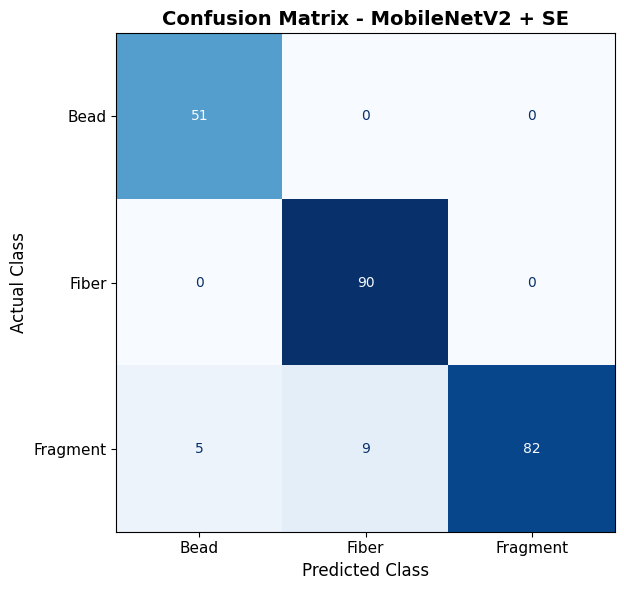


MobileNetV2 + SE Confusion Matrix:
          Bead  Fiber  Fragment
Bead        51      0         0
Fiber        0     90         0
Fragment     5      9        82


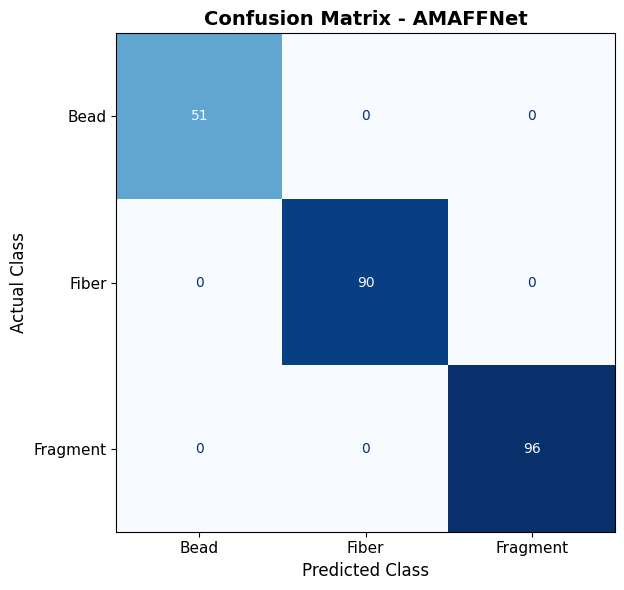


AMAFFNet Confusion Matrix:
          Bead  Fiber  Fragment
Bead        51      0         0
Fiber        0     90         0
Fragment     0      0        96


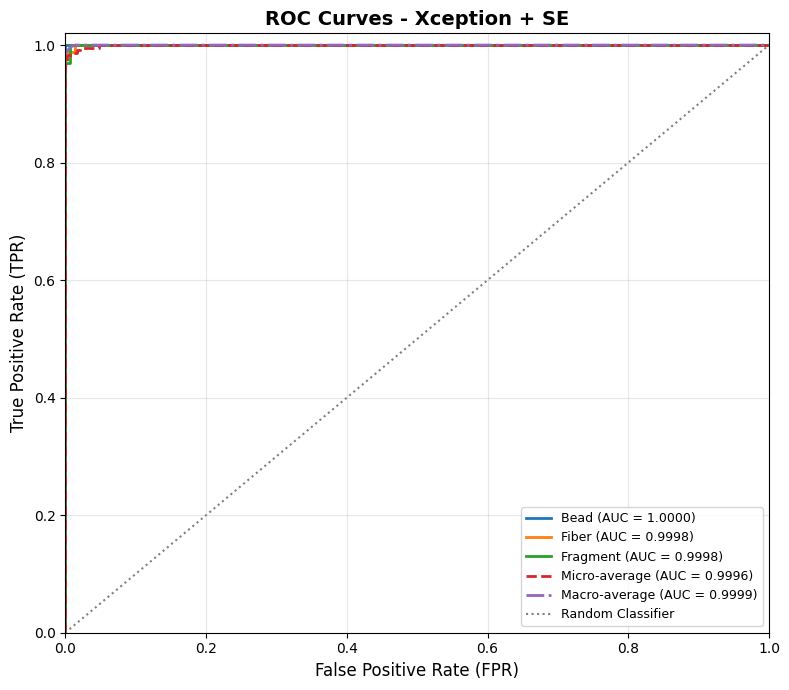


Xception + SE ROC-AUC Results:
        Class  ROC_AUC
         Bead   1.0000
        Fiber   0.9998
     Fragment   0.9998
Micro_Average   0.9996
Macro_Average   0.9999


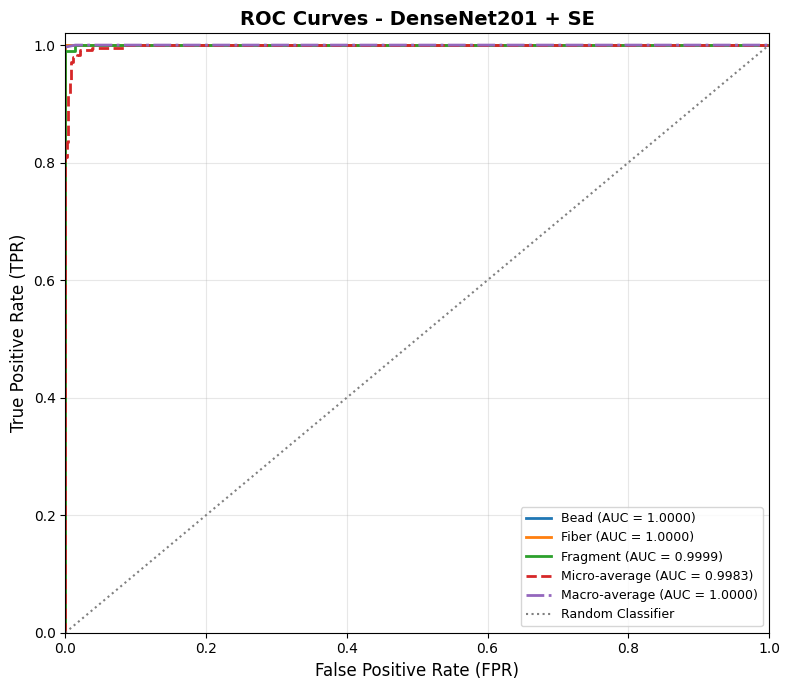


DenseNet201 + SE ROC-AUC Results:
        Class  ROC_AUC
         Bead   1.0000
        Fiber   1.0000
     Fragment   0.9999
Micro_Average   0.9983
Macro_Average   1.0000


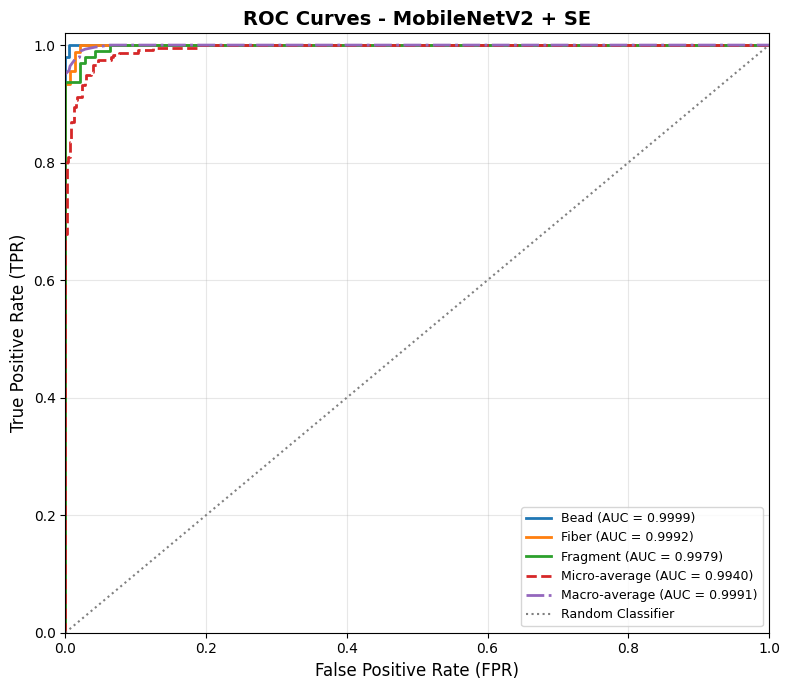


MobileNetV2 + SE ROC-AUC Results:
        Class  ROC_AUC
         Bead   0.9999
        Fiber   0.9992
     Fragment   0.9979
Micro_Average   0.9940
Macro_Average   0.9991


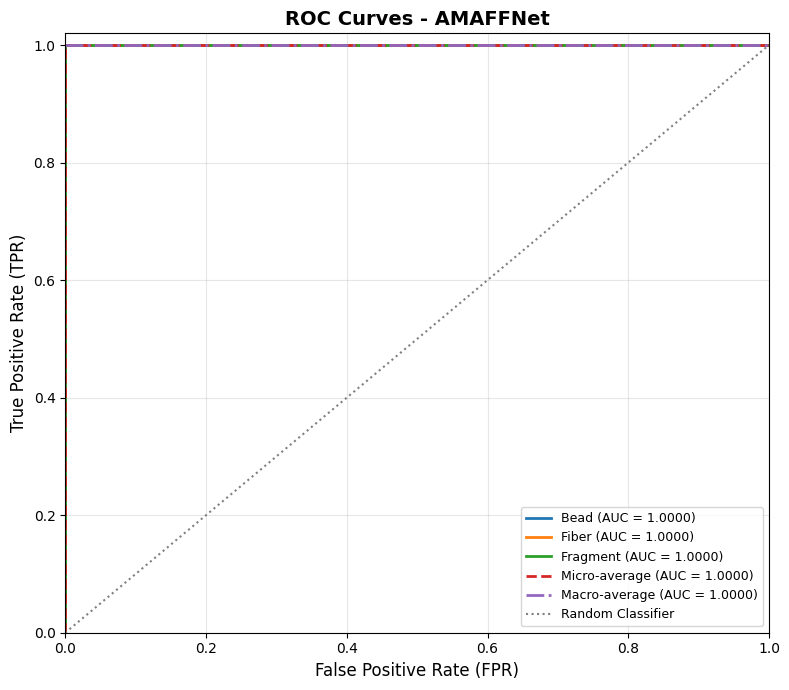


AMAFFNet ROC-AUC Results:
        Class  ROC_AUC
         Bead      1.0
        Fiber      1.0
     Fragment      1.0
Micro_Average      1.0
Macro_Average      1.0

FIVE-FOLD MEAN AND STANDARD DEVIATION
           Model            Metric   Mean  Standard_Deviation
   Xception + SE         Test_Loss 0.2885              0.0299
   Xception + SE          Accuracy 0.9872              0.0190
   Xception + SE   Precision_Macro 0.9844              0.0223
   Xception + SE      Recall_Macro 0.9893              0.0158
   Xception + SE          F1_Macro 0.9862              0.0199
   Xception + SE Balanced_Accuracy 0.9893              0.0158
   Xception + SE      Cohens_Kappa 0.9803              0.0293
   Xception + SE               MCC 0.9809              0.0285
   Xception + SE ROC_AUC_Macro_OVR 0.9997              0.0006
DenseNet201 + SE         Test_Loss 0.2832              0.0390
DenseNet201 + SE          Accuracy 0.9788              0.0261
DenseNet201 + SE   Precision_Macro 0.9730           

In [ ]:

# ================================================================
# STEP 10: COMPLETE EVALUATION OF ALL FOUR MODELS
#
# Publication model names:
# 1. Xception + SE
# 2. DenseNet201 + SE
# 3. MobileNetV2 + SE
# 4. Proposed AMAFFNet
#
# IMPORTANT:
# - Uses existing saved out-of-fold predictions and metrics.
# - No model training or prediction is performed.
# - Physical folder names and source CSV filenames are unchanged.
# - All displayed figure titles use the correct model names.
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize


# ---------------------------------------------------------------
# 1. DEFINE DIRECTORIES
# ---------------------------------------------------------------

ROOT_DIR = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results"
)

# Save all updated publication figures and tables separately
OUTPUT_DIR = os.path.join(
    ROOT_DIR,
    "Publication_Evaluation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ---------------------------------------------------------------
# 2. MODEL DISPLAY NAMES AND ACTUAL FOLDER NAMES
# ---------------------------------------------------------------

# Display names include SE.
# Physical directory names remain unchanged.

MODEL_DIRS = {
    "Xception + SE": "Xception",
    "DenseNet201 + SE": "DenseNet201",
    "MobileNetV2 + SE": "MobileNetV2",
    "AMAFFNet": "AMAFFNet_Fusion"
}


# ---------------------------------------------------------------
# 3. ORIGINAL PREDICTION AND METRIC FILENAMES
# ---------------------------------------------------------------

PREDICTION_FILES = {
    "Xception + SE": "Xception_All_Fold_Predictions.csv",
    "DenseNet201 + SE": "DenseNet201_All_Fold_Predictions.csv",
    "MobileNetV2 + SE": "MobileNetV2_All_Fold_Predictions.csv",
    "AMAFFNet": "AMAFFNet_All_Fold_Predictions.csv"
}

METRIC_FILES = {
    "Xception + SE": "Xception_5Fold_Complete_Metrics.csv",
    "DenseNet201 + SE": "DenseNet201_5Fold_Results.csv",
    "MobileNetV2 + SE": "MobileNetV2_5Fold_Results.csv",
    "AMAFFNet": "AMAFFNet_5Fold_Results.csv"
}


# ---------------------------------------------------------------
# 4. CLASS NAMES AND PROBABILITY COLUMNS
# ---------------------------------------------------------------

CLASS_NAMES = [
    "Bead",
    "Fiber",
    "Fragment"
]

CLASS_MAPPING = {
    0: "Bead",
    1: "Fiber",
    2: "Fragment"
}

PROBABILITY_COLUMNS = [
    "Probability_Bead",
    "Probability_Fiber",
    "Probability_Fragment"
]


# ---------------------------------------------------------------
# 5. HELPER FUNCTION FOR SAFE OUTPUT FILENAMES
# ---------------------------------------------------------------

def safe_model_name(model_name):

    # Convert publication names into filename-safe labels.
    # Example: Xception + SE becomes Xception_SE.

    return (
        model_name
        .replace(" + ", "_")
        .replace(" ", "_")
    )


# ---------------------------------------------------------------
# 6. VERIFY ALL REQUIRED FILES
# ---------------------------------------------------------------

prediction_paths = {}
metric_paths = {}

for display_name, folder_name in MODEL_DIRS.items():

    model_folder = os.path.join(
        ROOT_DIR,
        folder_name
    )

    prediction_path = os.path.join(
        model_folder,
        PREDICTION_FILES[display_name]
    )

    metric_path = os.path.join(
        model_folder,
        METRIC_FILES[display_name]
    )

    if not os.path.isfile(prediction_path):
        raise FileNotFoundError(prediction_path)

    if not os.path.isfile(metric_path):
        raise FileNotFoundError(metric_path)

    prediction_paths[display_name] = prediction_path
    metric_paths[display_name] = metric_path

    print("\nVerified:", display_name)
    print("Prediction:", prediction_path)
    print("Metrics:", metric_path)

print("\nAll four models and their files are verified.")


# ---------------------------------------------------------------
# 7. FUNCTION TO STANDARDIZE CLASS LABELS
# ---------------------------------------------------------------

def standardize_labels(values):

    standardized = []

    for value in values:

        if pd.isna(value):
            raise ValueError("Missing class label detected.")

        # Convert integer or floating-point labels into class names.
        if isinstance(
            value,
            (int, float, np.integer, np.floating)
        ):

            if float(value).is_integer():

                integer_value = int(value)

                if integer_value in CLASS_MAPPING:

                    standardized.append(
                        CLASS_MAPPING[integer_value]
                    )

                    continue

        # Handle numeric labels stored as strings.
        value_string = str(value).strip()

        if value_string in ["0", "1", "2"]:

            standardized.append(
                CLASS_MAPPING[int(value_string)]
            )

        else:

            standardized.append(
                value_string.capitalize()
            )

    return np.array(standardized)


# ---------------------------------------------------------------
# 8. LOAD ALL SAVED OUT-OF-FOLD PREDICTIONS
# ---------------------------------------------------------------

predictions = {}

for model_name, prediction_path in prediction_paths.items():

    df = pd.read_csv(prediction_path)

    # AMAFFNet uses numeric label columns.
    # The individual backbones use class-name columns.

    if model_name == "AMAFFNet":

        actual_column = "Actual_Label"
        predicted_column = "Predicted_Label"

    else:

        actual_column = "True_Class"
        predicted_column = "Predicted_Class"

    required_columns = (
        [actual_column, predicted_column]
        + PROBABILITY_COLUMNS
    )

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:

        raise ValueError(
            f"{model_name}: Missing columns {missing_columns}"
        )

    # Standardize actual and predicted labels.
    y_true = standardize_labels(
        df[actual_column]
    )

    y_pred = standardize_labels(
        df[predicted_column]
    )

    # Load the three class probabilities.
    y_prob = df[
        PROBABILITY_COLUMNS
    ].to_numpy(dtype=float)

    # Validate the probability values.
    if not np.isfinite(y_prob).all():
        raise ValueError(
            f"{model_name}: Invalid probability values."
        )

    if np.any(y_prob < 0) or np.any(y_prob > 1):
        raise ValueError(
            f"{model_name}: Probability outside [0,1]."
        )

    if not np.allclose(
        y_prob.sum(axis=1),
        1.0,
        atol=1e-3
    ):
        raise ValueError(
            f"{model_name}: Probability rows do not sum to 1."
        )

    if not set(y_true).issubset(set(CLASS_NAMES)):
        raise ValueError(
            f"{model_name}: Unexpected actual labels."
        )

    if not set(y_pred).issubset(set(CLASS_NAMES)):
        raise ValueError(
            f"{model_name}: Unexpected predicted labels."
        )

    # Store the loaded results.
    predictions[model_name] = {
        "data": df,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    print(
        f"{model_name}: {len(df)} predictions loaded."
    )


# ---------------------------------------------------------------
# 9. VERIFY IMAGE IDENTITY AND ACTUAL-LABEL CONSISTENCY
# ---------------------------------------------------------------

def get_image_identifiers(model_name):

    df = predictions[model_name]["data"]

    if model_name == "AMAFFNet":

        if "Image_Path" in df.columns:
            return df["Image_Path"].astype(str).to_numpy()

        return df["Filename"].astype(str).to_numpy()

    return df["Image_Path"].astype(str).to_numpy()


reference_name = "Xception + SE"

reference_images = get_image_identifiers(
    reference_name
)

reference_actual = predictions[
    reference_name
]["y_true"]

for model_name in predictions:

    current_images = get_image_identifiers(
        model_name
    )

    current_actual = predictions[
        model_name
    ]["y_true"]

    # Confirm that image ordering is identical.
    if not np.array_equal(
        reference_images,
        current_images
    ):

        raise ValueError(
            f"Image order differs in {model_name}."
        )

    # Confirm that actual labels are identical.
    if not np.array_equal(
        reference_actual,
        current_actual
    ):

        raise ValueError(
            f"Actual labels differ in {model_name}."
        )

    # Confirm that each image has only one OOF prediction.
    if len(np.unique(current_images)) != len(current_images):

        raise ValueError(
            f"Duplicate image predictions in {model_name}."
        )

print(
    "\nImage identity and actual-label consistency verified."
)


# ---------------------------------------------------------------
# 10. CALCULATE POOLED CLASSIFICATION METRICS
# ---------------------------------------------------------------

pooled_results = {}

for model_name, result in predictions.items():

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    y_prob = result["y_prob"]

    # Convert actual labels into one-vs-rest binary format.
    y_true_binary = label_binarize(
        y_true,
        classes=CLASS_NAMES
    )

    # Calculate macro-average ROC-AUC.
    roc_auc_macro = roc_auc_score(
        y_true_binary,
        y_prob,
        average="macro"
    )

    # Calculate pooled classification metrics.
    metrics = {

        "Model": model_name,

        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Precision_Macro": precision_score(
            y_true,
            y_pred,
            labels=CLASS_NAMES,
            average="macro",
            zero_division=0
        ),

        "Recall_Macro": recall_score(
            y_true,
            y_pred,
            labels=CLASS_NAMES,
            average="macro",
            zero_division=0
        ),

        "F1_Macro": f1_score(
            y_true,
            y_pred,
            labels=CLASS_NAMES,
            average="macro",
            zero_division=0
        ),

        "Balanced_Accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "Cohens_Kappa": cohen_kappa_score(
            y_true,
            y_pred
        ),

        "MCC": matthews_corrcoef(
            y_true,
            y_pred
        ),

        "ROC_AUC_Macro_OVR": roc_auc_macro
    }

    pooled_results[model_name] = metrics

    # Generate the class-wise classification report.
    report = classification_report(
        y_true,
        y_pred,
        labels=CLASS_NAMES,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    report_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{safe_model_name(model_name)}_Pooled_Classification_Report.csv"
        )
    )

# Save pooled metrics for all four models.
pooled_df = pd.DataFrame(
    list(pooled_results.values())
)

pooled_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "All_Models_Pooled_Evaluation_Metrics.csv"
    ),
    index=False
)

print("\n" + "=" * 80)
print("POOLED EVALUATION METRICS")
print("=" * 80)

print(
    pooled_df.round(4).to_string(index=False)
)


# ---------------------------------------------------------------
# 11. GENERATE POOLED CONFUSION MATRICES
# ---------------------------------------------------------------

for model_name, result in predictions.items():

    y_true = result["y_true"]
    y_pred = result["y_pred"]

    # Calculate the confusion matrix in fixed class order.
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=CLASS_NAMES
    )

    # Save numerical confusion matrix.
    cm_df = pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    )

    safe_name = safe_model_name(model_name)

    cm_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{safe_name}_Pooled_Confusion_Matrix.csv"
        )
    )

    # Plot the confusion matrix.
    fig, ax = plt.subplots(figsize=(7, 6))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    # Use the full publication model name.
    ax.set_title(
        f"Confusion Matrix - {model_name}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Predicted Class",
        fontsize=12
    )

    ax.set_ylabel(
        "Actual Class",
        fontsize=12
    )

    ax.tick_params(
        axis="both",
        labelsize=11
    )

    plt.tight_layout()

    # Save high-resolution publication figure.
    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{safe_name}_Pooled_Confusion_Matrix.png"
        ),
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(f"\n{model_name} Confusion Matrix:")
    print(cm_df)


# ---------------------------------------------------------------
# 12. GENERATE CLASS-WISE, MICRO AND MACRO ROC CURVES
# ---------------------------------------------------------------

for model_name, result in predictions.items():

    y_true = result["y_true"]
    y_prob = result["y_prob"]

    # Convert actual labels to one-vs-rest binary format.
    y_true_binary = label_binarize(
        y_true,
        classes=CLASS_NAMES
    )

    # Store ROC information for each class.
    fpr = {}
    tpr = {}
    roc_auc = {}

    fig, ax = plt.subplots(figsize=(8, 7))

    auc_results = []

    # -----------------------------------------------------------
    # Calculate individual class ROC curves.
    # -----------------------------------------------------------

    for i, class_name in enumerate(CLASS_NAMES):

        fpr[i], tpr[i], _ = roc_curve(
            y_true_binary[:, i],
            y_prob[:, i]
        )

        roc_auc[i] = auc(
            fpr[i],
            tpr[i]
        )

        auc_results.append({
            "Class": class_name,
            "ROC_AUC": roc_auc[i]
        })

        ax.plot(
            fpr[i],
            tpr[i],
            linewidth=2,
            label=(
                f"{class_name} "
                f"(AUC = {roc_auc[i]:.4f})"
            )
        )

    # -----------------------------------------------------------
    # Calculate micro-average ROC curve.
    # -----------------------------------------------------------

    fpr["micro"], tpr["micro"], _ = roc_curve(
        y_true_binary.ravel(),
        y_prob.ravel()
    )

    roc_auc["micro"] = auc(
        fpr["micro"],
        tpr["micro"]
    )

    ax.plot(
        fpr["micro"],
        tpr["micro"],
        linestyle="--",
        linewidth=2,
        label=(
            f"Micro-average "
            f"(AUC = {roc_auc['micro']:.4f})"
        )
    )

    # -----------------------------------------------------------
    # Calculate macro-average ROC curve.
    # -----------------------------------------------------------

    all_fpr = np.unique(
        np.concatenate([
            fpr[i] for i in range(len(CLASS_NAMES))
        ])
    )

    mean_tpr = np.zeros_like(all_fpr)

    for i in range(len(CLASS_NAMES)):

        mean_tpr += np.interp(
            all_fpr,
            fpr[i],
            tpr[i]
        )

    mean_tpr /= len(CLASS_NAMES)

    fpr["macro"] = all_fpr
    tpr["macro"] = mean_tpr

    roc_auc["macro"] = auc(
        fpr["macro"],
        tpr["macro"]
    )

    ax.plot(
        fpr["macro"],
        tpr["macro"],
        linestyle="-.",
        linewidth=2,
        label=(
            f"Macro-average "
            f"(AUC = {roc_auc['macro']:.4f})"
        )
    )

    # Random-classifier reference line.
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle=":",
        linewidth=1.5,
        color="gray",
        label="Random Classifier"
    )

    # -----------------------------------------------------------
    # Apply publication-ready labels.
    # -----------------------------------------------------------

    ax.set_xlabel(
        "False Positive Rate (FPR)",
        fontsize=12
    )

    ax.set_ylabel(
        "True Positive Rate (TPR)",
        fontsize=12
    )

    # Display the correct model name in the ROC figure.
    ax.set_title(
        f"ROC Curves - {model_name}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.legend(
        loc="lower right",
        fontsize=9
    )

    ax.grid(alpha=0.3)

    plt.tight_layout()

    safe_name = safe_model_name(model_name)

    # Save ROC curve at 600 DPI.
    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{safe_name}_ROC_Curves.png"
        ),
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    # -----------------------------------------------------------
    # Save all class-wise and average ROC-AUC values.
    # -----------------------------------------------------------

    auc_results.extend([

        {
            "Class": "Micro_Average",
            "ROC_AUC": roc_auc["micro"]
        },

        {
            "Class": "Macro_Average",
            "ROC_AUC": roc_auc["macro"]
        }

    ])

    auc_df = pd.DataFrame(auc_results)

    auc_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{safe_name}_Classwise_ROC_AUC.csv"
        ),
        index=False
    )

    print(f"\n{model_name} ROC-AUC Results:")
    print(
        auc_df.round(4).to_string(index=False)
    )


# ---------------------------------------------------------------
# 13. CALCULATE FIVE-FOLD MEAN AND STANDARD DEVIATION
# ---------------------------------------------------------------

fold_summary = []

for model_name, metric_path in metric_paths.items():

    fold_df = pd.read_csv(metric_path)

    common_metrics = [

        "Test_Loss",
        "Accuracy",
        "Precision_Macro",
        "Recall_Macro",
        "F1_Macro",
        "Balanced_Accuracy",
        "Cohens_Kappa",
        "MCC",
        "ROC_AUC_Macro_OVR"

    ]

    for metric in common_metrics:

        if metric not in fold_df.columns:
            continue

        values = pd.to_numeric(
            fold_df[metric],
            errors="coerce"
        ).dropna()

        fold_summary.append({

            "Model": model_name,

            "Metric": metric,

            "Mean": values.mean(),

            "Standard_Deviation": values.std(
                ddof=1
            )

        })

fold_summary_df = pd.DataFrame(
    fold_summary
)

fold_summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "All_Models_Five_Fold_Mean_Standard_Deviation.csv"
    ),
    index=False
)

print("\n" + "=" * 80)
print("FIVE-FOLD MEAN AND STANDARD DEVIATION")
print("=" * 80)

print(
    fold_summary_df.round(4).to_string(index=False)
)


# ---------------------------------------------------------------
# 14. GENERATE PUBLICATION-READY FIVE-FOLD COMPARISON
# ---------------------------------------------------------------

publication_rows = []

for model_name, metric_path in metric_paths.items():

    fold_df = pd.read_csv(metric_path)

    row = {
        "Model": model_name
    }

    for metric in [

        "Accuracy",
        "Precision_Macro",
        "Recall_Macro",
        "F1_Macro",
        "Balanced_Accuracy",
        "Cohens_Kappa",
        "MCC",
        "ROC_AUC_Macro_OVR"

    ]:

        if metric in fold_df.columns:

            values = pd.to_numeric(
                fold_df[metric],
                errors="coerce"
            ).dropna()

            row[metric] = (
                f"{values.mean():.4f} ± "
                f"{values.std(ddof=1):.4f}"
            )

    publication_rows.append(row)

publication_df = pd.DataFrame(
    publication_rows
)

publication_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Publication_Ready_Five_Fold_Comparison.csv"
    ),
    index=False
)

print("\nPUBLICATION-READY FIVE-FOLD COMPARISON")

print(
    publication_df.to_string(index=False)
)


# ---------------------------------------------------------------
# 15. FINAL EVALUATION COMPLETION SUMMARY
# ---------------------------------------------------------------

print("\n" + "=" * 80)
print("ALL EVALUATIONS COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nModels evaluated:")

for model_name in MODEL_DIRS:
    print("-", model_name)

print("\nNumber of pooled predictions per model:")

for model_name, result in predictions.items():

    print(
        f"{model_name}: {len(result['y_true'])}"
    )

print("\nAll evaluation outputs saved in:")
print(OUTPUT_DIR)

print("\nUpdated figure filenames:")

for model_name in MODEL_DIRS:

    safe_name = safe_model_name(model_name)

    print(
        f"{safe_name}_Pooled_Confusion_Matrix.png"
    )

    print(
        f"{safe_name}_ROC_Curves.png"
    )

print("\nAdditional outputs:")
print("1. Pooled classification metrics")
print("2. Individual classification reports")
print("3. Individual confusion matrices (CSV and PNG)")
print("4. Individual ROC curves (PNG)")
print("5. Class-wise, micro-average and macro-average AUC")
print("6. Five-fold mean and standard deviation")
print("7. Publication-ready comparison table")

print("\nSTEP 10 COMPLETED SUCCESSFULLY.")


In [ ]:

# ============================================================
# STEP 1: IMPORT LIBRARIES AND MOUNT GOOGLE DRIVE
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import drive
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.preprocessing import image

from tensorflow.keras.applications.xception import preprocess_input as xception_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

drive.mount('/content/drive')

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0
GPU available: []


In [ ]:

# ============================================================
# STEP 2: DEFINE DATASET, MODEL PATHS AND CONFIGURATIONS
# ============================================================

# CSV manifest must contain Image_Path and Class columns.
CSV_PATH = "/content/drive/MyDrive/Microplastics_SEM/REPLACE_WITH_MANIFEST.csv"

# Output directory for all Grad-CAM figures
OUTPUT_DIR = "/content/drive/MyDrive/Microplastics_SEM/GradCAM_All_Models"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Configure the three individual trained models.
# Input dimensions and preprocessing MUST match model training.

MODEL_CONFIGS = {

    "Xception_SE": {
        "path": "/content/drive/MyDrive/Microplastics_SEM/REPLACE_XCEPTION_MODEL.keras",
        "size": (299, 299),
        "preprocess": xception_preprocess,
        "target_layer": None
    },

    "DenseNet201_SE": {
        "path": "/content/drive/MyDrive/Microplastics_SEM/REPLACE_DENSENET_MODEL.keras",
        "size": (224, 224),
        "preprocess": densenet_preprocess,
        "target_layer": None
    },

    "MobileNetV2_SE": {
        "path": "/content/drive/MyDrive/Microplastics_SEM/REPLACE_MOBILENET_MODEL.keras",
        "size": (160, 160),
        "preprocess": mobilenet_preprocess,
        "target_layer": None
    }
}

# These are the three output classes.
CLASS_NAMES = ['Bead', 'Fiber', 'Fragment']

# Load the Mendeley dataset manifest.
df = pd.read_csv(CSV_PATH)

# Remove leading/trailing spaces in class names.
df['Class'] = df['Class'].astype(str).str.strip()

# Standardize common spelling variations.
df['Class'] = df['Class'].replace({
    'fibre': 'Fiber',
    'Fibre': 'Fiber',
    'bead': 'Bead',
    'fragment': 'Fragment'
})

# Check dataset distribution.
print("Mendeley dataset distribution:")
print(df['Class'].value_counts())

print("\nTotal images:", len(df))


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Microplastics_SEM/REPLACE_WITH_MANIFEST.csv'

In [ ]:

# ============================================================
# UPDATED DATASET 1 PATHS
# ============================================================

import os
import glob

# Main Dataset 1 directory
DATASET_DIR = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "dataset1/dataset1"
)

# Subset experiment used in our earlier metadata analysis
SUBSET_DIR = os.path.join(
    DATASET_DIR,
    "[datasets_subset]_Exp2"
)

# Individual class image folders
CLASS_DIRS = {
    "Bead": os.path.join(SUBSET_DIR, "bead", "image"),
    "Fiber": os.path.join(SUBSET_DIR, "fiber", "image"),
    "Fragment": os.path.join(SUBSET_DIR, "fragment", "image")
}

# Output directory
OUTPUT_DIR = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "GradCAM_Dataset1_Results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Collect image paths directly from Dataset 1
selected_images = {}

for class_name, folder in CLASS_DIRS.items():

    if not os.path.isdir(folder):
        print("Folder not found:", folder)
        continue

    files = []

    for ext in ["*.png", "*.jpg", "*.jpeg", "*.tif", "*.tiff"]:
        files.extend(
            glob.glob(os.path.join(folder, ext))
        )

    files = sorted(files)

    if files:
        selected_images[class_name] = files[0]

    print(
        class_name,
        "Total images:",
        len(files)
    )

print("\nSelected representative images:")

for class_name, path in selected_images.items():
    print(class_name, ":", path)


Bead Total images: 0
Folder not found: /content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/fiber/image
Folder not found: /content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/fragment/image

Selected representative images:


In [ ]:
XCEPTION_MODEL = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results/Xception/final_xception_se.keras"
)

In [ ]:

# ============================================================
# STEP 1: ROBUST IMAGE COLLECTION FROM DATASET 1
# Uses os.walk instead of glob
# ============================================================

import os

# Correct extracted Dataset 1 directory
DATASET_DIR = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "dataset1/dataset1/[datasets_subset]_Exp2"
)

# Check the directory
print("Dataset directory exists:", os.path.isdir(DATASET_DIR))

# Define image extensions
IMAGE_EXTENSIONS = (
    ".png", ".jpg", ".jpeg",
    ".tif", ".tiff", ".bmp"
)

# Initialize class-wise image lists
class_images = {
    "Bead": [],
    "Fiber": [],
    "Fragment": []
}

# Recursively search only the actual image folders
for root, dirs, files in os.walk(DATASET_DIR):

    # Exclude label folders and hidden metadata directories
    dirs[:] = [
        d for d in dirs
        if d.lower() not in ["label", "__macosx"]
    ]

    # Process only folders named image
    if os.path.basename(root).lower() != "image":
        continue

    # Identify the parent experiment folder
    parent = os.path.basename(os.path.dirname(root)).lower()

    # Determine the corresponding particle class
    if parent == "bead":
        class_name = "Bead"

    elif parent in ["fibre_1", "fibre_2"]:
        class_name = "Fiber"

    elif parent in ["fragment_1", "fragment_2"]:
        class_name = "Fragment"

    else:
        continue

    # Collect valid image files
    for filename in files:

        # Ignore macOS metadata files
        if filename.startswith("._"):
            continue

        # Case-insensitive extension checking
        if filename.lower().endswith(IMAGE_EXTENSIONS):

            image_path = os.path.join(root, filename)

            class_images[class_name].append(image_path)

# Sort image paths
for class_name in class_images:
    class_images[class_name] = sorted(
        set(class_images[class_name])
    )

# Display class-wise results
print("\n" + "=" * 65)
print("DATASET 1 IMAGE SUMMARY")
print("=" * 65)

for class_name, paths in class_images.items():

    print(class_name, ":", len(paths), "images")

    if paths:
        print("Sample:", paths[0])

# Calculate total images
total_images = sum(
    len(paths) for paths in class_images.values()
)

print("\nTotal images:", total_images)

# Select one representative image per class
selected_images = {}

for class_name, paths in class_images.items():

    if paths:
        selected_images[class_name] = paths[len(paths)//2]

print("\nSelected images:")

for class_name, path in selected_images.items():
    print(class_name, ":", path)


Dataset directory exists: True

DATASET 1 IMAGE SUMMARY
Bead : 51 images
Sample: /content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/bead/image/Dove_men_acrylates_copolymer_microbeads_002.png
Fiber : 90 images
Sample: /content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/fibre_1/image/polyester_101.png
Fragment : 96 images
Sample: /content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/fragment_1/image/Foam_No0001.png

Total images: 237

Selected images:
Bead : /content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/bead/image/Dove_men_acrylates_copolymer_microbeads_038.png
Fiber : /content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/fibre_2/image/PAN_01_3kV_20201119.png
Fragment : /content/drive/MyDrive/Microplastics_SEM/dataset1/dataset1/[datasets_subset]_Exp2/fragment_1/image/Particle_No0022.png


In [ ]:

# ============================================================
# STEP 2: SEARCH FOR SAVED MODEL FILES
# Search the Microplastics_SEM project directory
# ============================================================

import os

# Main project directory
SEARCH_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Supported Keras model formats
MODEL_EXTENSIONS = (".keras", ".h5", ".hdf5")

# Store discovered model paths
saved_models = []

# Search all subdirectories
for root, dirs, files in os.walk(SEARCH_DIR):

    # Ignore unnecessary system folders
    dirs[:] = [
        d for d in dirs
        if d not in ["__MACOSX", ".ipynb_checkpoints"]
    ]

    for filename in files:

        # Identify saved Keras models
        if filename.lower().endswith(MODEL_EXTENSIONS):

            full_path = os.path.join(root, filename)
            saved_models.append(full_path)

# Display results
print("=" * 75)
print("SAVED MODEL FILES")
print("=" * 75)

if saved_models:

    for index, path in enumerate(sorted(saved_models), 1):
        print(f"{index}. {path}")

else:
    print("No saved Keras model files found.")


SAVED MODEL FILES
1. /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/best_amaffnet_fold_1.keras
2. /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/best_amaffnet_fold_2.keras
3. /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/best_amaffnet_fold_3.keras
4. /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/best_amaffnet_fold_4.keras
5. /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Results/AMAFFNet_Fusion/best_amaffnet_fold_5.keras
6. /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/DenseNet201/best_densenet201_fold_1.keras
7. /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/DenseNet201/best_densenet201_fold_2.keras
8. /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/DenseNet201/best_densenet201_fold_3.keras
9. /content/drive/MyDrive/Microplastics_SEM/AMAFFNet_Weights/DenseNet201/best_densenet201_fold_4.keras
10. /content/drive/MyDrive/Microplastics_SEM/AMAFF

In [ ]:

# ============================================================
# STEP 3: INSPECT FOLD-1 MODEL ARCHITECTURES
# No training, fine-tuning, or weight modification
# ============================================================

import os
import tensorflow as tf
from tensorflow.keras.models import load_model

# ------------------------------------------------------------
# 1. Define the four fold-1 model paths
# ------------------------------------------------------------

MODEL_PATHS = {
    "Xception_SE":
        "/content/drive/MyDrive/Microplastics_SEM/"
        "AMAFFNet_Weights/Xception/best_xception_fold_1.keras",

    "DenseNet201_SE":
        "/content/drive/MyDrive/Microplastics_SEM/"
        "AMAFFNet_Weights/DenseNet201/best_densenet201_fold_1.keras",

    "MobileNetV2_SE":
        "/content/drive/MyDrive/Microplastics_SEM/"
        "AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_1.keras",

    "AMAFFNet":
        "/content/drive/MyDrive/Microplastics_SEM/"
        "AMAFFNet_Results/AMAFFNet_Fusion/best_amaffnet_fold_1.keras"
}

# ------------------------------------------------------------
# 2. Function to inspect nested model layers recursively
# ------------------------------------------------------------

def inspect_layers(model, prefix=""):

    for layer in model.layers:

        layer_name = prefix + layer.name
        layer_type = layer.__class__.__name__

        # Print layer name and type
        print(f"{layer_name:65s} | {layer_type}")

        # Identify convolutional layers
        if isinstance(
            layer,
            (
                tf.keras.layers.Conv2D,
                tf.keras.layers.DepthwiseConv2D,
                tf.keras.layers.SeparableConv2D
            )
        ):
            print("   >>> CONVOLUTIONAL LAYER")

        # Inspect nested Keras models
        if isinstance(layer, tf.keras.Model):
            inspect_layers(
                layer,
                prefix=layer_name + "/"
            )

# ------------------------------------------------------------
# 3. Load and inspect each model
# ------------------------------------------------------------

loaded_models = {}

for model_name, model_path in MODEL_PATHS.items():

    print("\n" + "=" * 90)
    print("MODEL:", model_name)
    print("=" * 90)

    # Verify that the model file exists
    if not os.path.exists(model_path):
        print("MODEL FILE NOT FOUND:", model_path)
        continue

    try:
        # Load without compiling because evaluation is not required here
        model = load_model(
            model_path,
            compile=False,
            safe_mode=False
        )

        loaded_models[model_name] = model

        print("\nMODEL INPUT SHAPE:")
        print(model.input_shape)

        print("\nMODEL OUTPUT SHAPE:")
        print(model.output_shape)

        print("\nMODEL LAYER DETAILS:")
        inspect_layers(model)

    except Exception as error:
        print("\nMODEL LOADING ERROR:")
        print(type(error).__name__, str(error))

# ------------------------------------------------------------
# 4. Display successfully loaded models
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("MODEL LOADING SUMMARY")
print("=" * 90)

for name in MODEL_PATHS:
    print(
        name,
        ":",
        "Loaded successfully" if name in loaded_models else "Not loaded"
    )



MODEL: Xception_SE

MODEL INPUT SHAPE:
(None, 299, 299, 3)

MODEL OUTPUT SHAPE:
(None, 3)

MODEL LAYER DETAILS:
input_layer_1                                                     | InputLayer
xception                                                          | Functional
xception/input_layer                                              | InputLayer
xception/block1_conv1                                             | Conv2D
   >>> CONVOLUTIONAL LAYER
xception/block1_conv1_bn                                          | BatchNormalization
xception/block1_conv1_act                                         | Activation
xception/block1_conv2                                             | Conv2D
   >>> CONVOLUTIONAL LAYER
xception/block1_conv2_bn                                          | BatchNormalization
xception/block1_conv2_act                                         | Activation
xception/block2_sepconv1                                          | SeparableConv2D
   >>> CONVOLUTIONAL LAYER
xce

In [ ]:

# ============================================================
# GRAD-CAM VISUALIZATION FOR DATASET 1
# Models: Xception, DenseNet201, MobileNetV2
# Dataset: Mendeley SEM Microplastics
#
# Uses:
#   1. Previously saved fold-1 models
#   2. Three representative Dataset 1 images
#   3. The exact preprocessing used during training
#
# Outputs:
#   1. Original SEM images
#   2. Grad-CAM heatmaps
#   3. Grad-CAM overlays
#   4. Model predictions
#   5. Combined comparison figure
#
# IMPORTANT:
#   No model training or fine-tuning is performed.
# ============================================================


# ============================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2

from tensorflow.keras.models import load_model, Model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

from tensorflow.keras.applications.xception import (
    preprocess_input as xception_preprocess
)

from tensorflow.keras.applications.densenet import (
    preprocess_input as densenet_preprocess
)

from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input as mobilenet_preprocess
)


# ============================================================
# STEP 2: DEFINE MODEL AND DATASET PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/Microplastics_SEM"

# Saved fold-1 model paths
MODEL_PATHS = {
    "Xception": os.path.join(
        BASE_DIR,
        "AMAFFNet_Weights/Xception/best_xception_fold_1.keras"
    ),

    "DenseNet201": os.path.join(
        BASE_DIR,
        "AMAFFNet_Weights/DenseNet201/best_densenet201_fold_1.keras"
    ),

    "MobileNetV2": os.path.join(
        BASE_DIR,
        "AMAFFNet_Weights/MobileNetV2/best_mobilenetv2_fold_1.keras"
    )
}

# Representative Dataset 1 images selected earlier
IMAGE_PATHS = {
    "Bead": (
        BASE_DIR +
        "/dataset1/dataset1/[datasets_subset]_Exp2/"
        "bead/image/Dove_men_acrylates_copolymer_microbeads_038.png"
    ),

    "Fiber": (
        BASE_DIR +
        "/dataset1/dataset1/[datasets_subset]_Exp2/"
        "fibre_2/image/PAN_01_3kV_20201119.png"
    ),

    "Fragment": (
        BASE_DIR +
        "/dataset1/dataset1/[datasets_subset]_Exp2/"
        "fragment_1/image/Particle_No0022.png"
    )
}

# Save all Grad-CAM outputs in this directory
OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "GradCAM_Dataset1_Results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Class order used during model training
CLASS_NAMES = ["Bead", "Fiber", "Fragment"]

# Input dimensions and preprocessing functions
MODEL_CONFIG = {
    "Xception": {
        "size": (299, 299),
        "preprocess": xception_preprocess,
        "backbone": "xception",
        "conv_layer": "block14_sepconv2"
    },

    "DenseNet201": {
        "size": (224, 224),
        "preprocess": densenet_preprocess,
        "backbone": "densenet201",
        "conv_layer": "relu"
    },

    "MobileNetV2": {
        "size": (160, 160),
        "preprocess": mobilenet_preprocess,
        "backbone": "mobilenetv2_1.00_224",
        "conv_layer": "out_relu"
    }
}


# ============================================================
# STEP 3: VERIFY ALL REQUIRED FILES
# ============================================================

print("=" * 65)
print("CHECKING SAVED MODELS AND DATASET 1 IMAGES")
print("=" * 65)

for model_name, model_path in MODEL_PATHS.items():

    if not os.path.isfile(model_path):
        raise FileNotFoundError(
            f"Saved model not found: {model_path}"
        )

    print("Model available:", model_name)

for class_name, image_path in IMAGE_PATHS.items():

    if not os.path.isfile(image_path):
        raise FileNotFoundError(
            f"{class_name} image not found: {image_path}"
        )

    print(f"{class_name} image available")


# ============================================================
# STEP 4: LOAD AND PREPROCESS AN IMAGE
# ============================================================

def prepare_image(image_path, model_name):

    # Obtain the input dimensions and preprocessing function
    config = MODEL_CONFIG[model_name]

    # Load the original SEM image and resize it
    image = load_img(
        image_path,
        target_size=config["size"],
        interpolation="nearest"
    )

    # Convert the image into a numerical array
    image_array = img_to_array(image)

    # Keep a copy of the resized RGB image for visualization
    original_image = np.uint8(
        np.clip(image_array, 0, 255)
    )

    # Add a batch dimension
    image_batch = np.expand_dims(
        image_array.copy(),
        axis=0
    )

    # Apply the same preprocessing used during training
    processed_batch = config["preprocess"](
        image_batch.astype(np.float32)
    )

    return original_image, processed_batch


# ============================================================
# STEP 5: BUILD A GRAD-CAM MODEL FOR A NESTED BACKBONE
# ============================================================

def build_gradcam_components(model, model_name):

    config = MODEL_CONFIG[model_name]

    # Locate the nested pretrained backbone
    backbone = model.get_layer(
        config["backbone"]
    )

    # Locate the final spatial convolutional feature layer
    conv_layer = backbone.get_layer(
        config["conv_layer"]
    )

    # Create a model that returns the selected convolutional
    # feature maps from the backbone
    activation_model = Model(
        inputs=backbone.input,
        outputs=conv_layer.output
    )

    # Create a model that continues from the selected feature
    # maps to the final backbone output
    backbone_tail = Model(
        inputs=conv_layer.output,
        outputs=backbone.output
    )

    # Identify the classification layers following the backbone
    backbone_index = model.layers.index(backbone)

    head_layers = model.layers[backbone_index + 1:]

    if not head_layers:
        raise ValueError(
            f"No classification head found for {model_name}"
        )

    return activation_model, backbone_tail, head_layers


# ============================================================
# STEP 6: CALCULATE GRAD-CAM HEATMAP
# ============================================================

def generate_gradcam(
    model,
    model_name,
    processed_image,
    activation_model,
    backbone_tail,
    head_layers
):

    # Use GradientTape to calculate gradients of the predicted
    # class score with respect to the convolutional feature maps
    with tf.GradientTape() as tape:

        # Obtain spatial feature maps from the selected layer
        conv_features = activation_model(
            processed_image,
            training=False
        )

        # Continue through the remaining backbone layers
        backbone_features = backbone_tail(
            conv_features,
            training=False
        )

        # Pass backbone features through the original
        # classification and attention layers
        x = backbone_features

        for layer in head_layers:
            x = layer(x)

        # Final model probabilities
        predictions = x

        # Select the predicted class
        predicted_class = tf.argmax(
            predictions[0]
        )

        # Obtain the score of that predicted class
        class_score = predictions[:, predicted_class]

    # Calculate gradients with respect to convolutional features
    gradients = tape.gradient(
        class_score,
        conv_features
    )

    if gradients is None:
        raise RuntimeError(
            f"Gradients are not connected for {model_name}. "
            "Check the selected layer and model architecture."
        )

    # Average gradients across the spatial dimensions
    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    # Obtain the feature maps for the current image
    feature_maps = conv_features[0]

    # Calculate the weighted combination of feature maps
    weights = pooled_gradients[0]

    cam = tf.reduce_sum(
        feature_maps * weights,
        axis=-1
    )

    # Retain positive contributions
    cam = tf.maximum(cam, 0)

    # Normalize the heatmap between zero and one
    cam = cam / (
        tf.reduce_max(cam) + tf.keras.backend.epsilon()
    )

    heatmap = cam.numpy()

    # Obtain the model probabilities
    probabilities = predictions.numpy()[0]

    return heatmap, probabilities


# ============================================================
# STEP 7: CREATE HEATMAP OVERLAY
# ============================================================

def create_overlay(original_image, heatmap):

    # Resize Grad-CAM heatmap to the original image dimensions
    resized_heatmap = cv2.resize(
        heatmap,
        (original_image.shape[1], original_image.shape[0])
    )

    # Convert heatmap values into an 8-bit image
    heatmap_uint8 = np.uint8(
        255 * resized_heatmap
    )

    # Apply the JET colour map
    coloured_heatmap = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    # Convert the colour map from BGR to RGB
    coloured_heatmap = cv2.cvtColor(
        coloured_heatmap,
        cv2.COLOR_BGR2RGB
    )

    # Blend the original SEM image and heatmap
    overlay = cv2.addWeighted(
        original_image,
        0.60,
        coloured_heatmap,
        0.40,
        0
    )

    return resized_heatmap, coloured_heatmap, overlay


# ============================================================
# STEP 8: LOAD MODELS AND GENERATE GRAD-CAM
# ============================================================

all_results = []
visualization_data = {}

for model_name, model_path in MODEL_PATHS.items():

    print("\n" + "=" * 65)
    print("PROCESSING:", model_name)
    print("=" * 65)

    # Load the already trained fold-1 model
    model = load_model(
        model_path,
        compile=False,
        safe_mode=False
    )

    print("Model loaded successfully.")
    print("Input shape :", model.input_shape)
    print("Output shape:", model.output_shape)

    # Build the Grad-CAM components
    activation_model, backbone_tail, head_layers = (
        build_gradcam_components(
            model,
            model_name
        )
    )

    # Store results for this model
    visualization_data[model_name] = {}

    # Process one representative image from each class
    for true_class, image_path in IMAGE_PATHS.items():

        print("\nProcessing image:", true_class)

        # Load and preprocess using the correct model procedure
        original_image, processed_image = prepare_image(
            image_path,
            model_name
        )

        # Generate Grad-CAM heatmap and predictions
        heatmap, probabilities = generate_gradcam(
            model,
            model_name,
            processed_image,
            activation_model,
            backbone_tail,
            head_layers
        )

        # Determine predicted class
        predicted_index = int(
            np.argmax(probabilities)
        )

        predicted_class = CLASS_NAMES[predicted_index]

        # Generate the overlay
        resized_heatmap, coloured_heatmap, overlay = (
            create_overlay(
                original_image,
                heatmap
            )
        )

        # Store the visualizations
        visualization_data[model_name][true_class] = {
            "original": original_image,
            "heatmap": resized_heatmap,
            "coloured_heatmap": coloured_heatmap,
            "overlay": overlay,
            "predicted_class": predicted_class,
            "probabilities": probabilities
        }

        # Save individual overlay image
        safe_class_name = true_class.lower()

        overlay_path = os.path.join(
            OUTPUT_DIR,
            f"{model_name}_{safe_class_name}_GradCAM.png"
        )

        plt.imsave(
            overlay_path,
            overlay
        )

        # Save individual heatmap
        heatmap_path = os.path.join(
            OUTPUT_DIR,
            f"{model_name}_{safe_class_name}_Heatmap.png"
        )

        plt.imsave(
            heatmap_path,
            resized_heatmap,
            cmap="jet"
        )

        # Record predictions and class probabilities
        all_results.append({
            "Model": model_name,
            "True_Class": true_class,
            "Predicted_Class": predicted_class,
            "Correct_Prediction": (
                true_class == predicted_class
            ),
            "Bead_Probability": probabilities[0],
            "Fiber_Probability": probabilities[1],
            "Fragment_Probability": probabilities[2],
            "Overlay_File": overlay_path,
            "Heatmap_File": heatmap_path
        })

        print("True class     :", true_class)
        print("Predicted class:", predicted_class)
        print(
            "Probabilities  :",
            np.round(probabilities, 4)
        )

        print("Grad-CAM saved :", overlay_path)

    # Release model resources before loading the next model
    del model
    del activation_model
    del backbone_tail
    del head_layers

    tf.keras.backend.clear_session()
    gc.collect()


# ============================================================
# STEP 9: SAVE PREDICTION SUMMARY
# ============================================================

results_df = pd.DataFrame(all_results)

csv_path = os.path.join(
    OUTPUT_DIR,
    "Dataset1_GradCAM_Predictions.csv"
)

results_df.to_csv(
    csv_path,
    index=False
)

print("\nPrediction summary saved:", csv_path)


# ============================================================
# STEP 10: CREATE COMBINED GRAD-CAM COMPARISON FIGURE
# ============================================================

# Each row represents one model.
# Columns show the original image, heatmap, and overlay.
model_names = [
    "Xception",
    "DenseNet201",
    "MobileNetV2"
]

class_names = [
    "Bead",
    "Fiber",
    "Fragment"
]

fig, axes = plt.subplots(
    nrows=9,
    ncols=3,
    figsize=(12, 27)
)

row = 0

for model_name in model_names:

    for class_name in class_names:

        data = visualization_data[model_name][class_name]

        # Display the original SEM image
        axes[row, 0].imshow(data["original"])
        axes[row, 0].set_title(
            f"{model_name} | {class_name} | Original"
        )

        # Display the Grad-CAM heatmap
        axes[row, 1].imshow(
            data["heatmap"],
            cmap="jet"
        )

        axes[row, 1].set_title(
            f"{model_name} | Grad-CAM"
        )

        # Display the Grad-CAM overlay
        axes[row, 2].imshow(data["overlay"])

        axes[row, 2].set_title(
            f"Predicted: {data['predicted_class']}"
        )

        # Remove axis markings for a cleaner figure
        for column in range(3):
            axes[row, column].axis("off")

        row += 1

plt.tight_layout()

combined_path = os.path.join(
    OUTPUT_DIR,
    "Dataset1_GradCAM_Combined_Comparison.png"
)

plt.savefig(
    combined_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nCombined figure saved:", combined_path)


# ============================================================
# STEP 11: DISPLAY FINAL OUTPUT LOCATIONS
# ============================================================

print("\n" + "=" * 65)
print("DATASET 1 GRAD-CAM PROCESS COMPLETED")
print("=" * 65)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nPrediction summary:")
print(csv_path)

print("\nCombined Grad-CAM figure:")
print(combined_path)

print("\nIndividual heatmaps and overlays:")
print("9 heatmaps and 9 overlay images are expected.")

print("\nPrediction summary:")
print(
    results_df[
        [
            "Model",
            "True_Class",
            "Predicted_Class",
            "Correct_Prediction"
        ]
    ].to_string(index=False)
)


CHECKING SAVED MODELS AND DATASET 1 IMAGES
Model available: Xception
Model available: DenseNet201
Model available: MobileNetV2
Bead image available
Fiber image available
Fragment image available

PROCESSING: Xception
Model loaded successfully.
Input shape : (None, 299, 299, 3)
Output shape: (None, 3)

Processing image: Bead
True class     : Bead
Predicted class: Bead
Probabilities  : [0.8001 0.0706 0.1293]
Grad-CAM saved : /content/drive/MyDrive/Microplastics_SEM/GradCAM_Dataset1_Results/Xception_bead_GradCAM.png

Processing image: Fiber
True class     : Fiber
Predicted class: Fiber
Probabilities  : [0.0463 0.8854 0.0683]
Grad-CAM saved : /content/drive/MyDrive/Microplastics_SEM/GradCAM_Dataset1_Results/Xception_fiber_GradCAM.png

Processing image: Fragment
True class     : Fragment
Predicted class: Fragment
Probabilities  : [0.1792 0.0796 0.7413]
Grad-CAM saved : /content/drive/MyDrive/Microplastics_SEM/GradCAM_Dataset1_Results/Xception_fragment_GradCAM.png

PROCESSING: DenseNet201
Mo

ValueError: `inputs` not connected to `outputs`

In [ ]:

# ============================================================
# DENSENET201: CHECK GRAD-CAM GRAPH CONNECTIVITY
# No training or prediction is performed.
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import load_model, Model

# Load the already saved DenseNet201 fold-1 model
model_path = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/DenseNet201/"
    "best_densenet201_fold_1.keras"
)

model = load_model(
    model_path,
    compile=False,
    safe_mode=False
)

print("Loaded DenseNet201 model.")
print("\nTop-level model layers:")

for i, layer in enumerate(model.layers):
    print(i, layer.name, type(layer).__name__)

# Locate the nested DenseNet201 backbone
backbone = model.get_layer("densenet201")

print("\nBackbone input shape:", backbone.input_shape)
print("Backbone output shape:", backbone.output_shape)

# Locate the final convolutional feature layer
conv_layer = backbone.get_layer("relu")

print("\nSelected convolutional layer:", conv_layer.name)
print("Convolutional output shape:", conv_layer.output.shape)

# Test three possible graph connections separately
tests = [
    (
        "Full model input -> convolutional output",
        model.inputs,
        conv_layer.output
    ),
    (
        "Backbone input -> convolutional output",
        backbone.inputs,
        conv_layer.output
    ),
    (
        "Convolutional output -> backbone output",
        conv_layer.output,
        backbone.output
    )
]

print("\n" + "=" * 65)
print("GRAPH CONNECTIVITY TEST")
print("=" * 65)

for test_name, test_input, test_output in tests:

    try:
        test_model = Model(
            inputs=test_input,
            outputs=test_output
        )

        print(test_name, ": SUCCESS")

        del test_model

    except Exception as error:
        print(test_name, ": FAILED")
        print("Error:", str(error)[:500])

print("\nDiagnostic completed.")


Loaded DenseNet201 model.

Top-level model layers:
0 input_layer InputLayer
1 densenet201 Functional
2 global_average_pooling2d GlobalAveragePooling2D
3 dense Dense
4 dense_1 Dense
5 reshape Reshape
6 multiply Multiply
7 global_average_pooling2d_1 GlobalAveragePooling2D
8 batch_normalization BatchNormalization
9 dense_2 Dense
10 dropout Dropout
11 Feature_Vector Dense
12 dropout_1 Dropout
13 dense_3 Dense

Backbone input shape: (None, 224, 224, 3)
Backbone output shape: (None, 7, 7, 1920)

Selected convolutional layer: relu
Convolutional output shape: (None, 7, 7, 1920)

GRAPH CONNECTIVITY TEST
Full model input -> convolutional output : SUCCESS
Backbone input -> convolutional output : SUCCESS
Convolutional output -> backbone output : FAILED
Error: `inputs` not connected to `outputs`

Diagnostic completed.


In [ ]:

# ============================================================
# DENSENET201 + SE: CORRECTED GRAD-CAM
# Dataset 1: Bead, Fiber, Fragment
#
# Uses the original trained fold-1 model.
# No retraining and no data augmentation.
#
# Saves:
# 1. Individual Grad-CAM heatmaps
# 2. Individual Grad-CAM overlays
# 3. Combined comparison figure
# ============================================================

import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model, Model
from tensorflow.keras.applications.densenet import preprocess_input

# ------------------------------------------------------------
# 1. Define model and output paths
# ------------------------------------------------------------

MODEL_PATH = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/DenseNet201/"
    "best_densenet201_fold_1.keras"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "GradCAM_Dataset1_Results/DenseNet201"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Define representative Dataset 1 images
# ------------------------------------------------------------

IMAGE_PATHS = {
    "Bead": (
        "/content/drive/MyDrive/Microplastics_SEM/"
        "dataset1/dataset1/[datasets_subset]_Exp2/"
        "bead/image/Dove_men_acrylates_copolymer_microbeads_038.png"
    ),

    "Fiber": (
        "/content/drive/MyDrive/Microplastics_SEM/"
        "dataset1/dataset1/[datasets_subset]_Exp2/"
        "fibre_2/image/PAN_01_3kV_20201119.png"
    ),

    "Fragment": (
        "/content/drive/MyDrive/Microplastics_SEM/"
        "dataset1/dataset1/[datasets_subset]_Exp2/"
        "fragment_1/image/Particle_No0022.png"
    )
}

# ------------------------------------------------------------
# 3. Define class labels and image dimensions
# ------------------------------------------------------------

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]

IMG_SIZE = 224

# ------------------------------------------------------------
# 4. Load the saved DenseNet201 model
# ------------------------------------------------------------

model = load_model(
    MODEL_PATH,
    compile=False,
    safe_mode=False
)

print("DenseNet201 model loaded successfully.")

# ------------------------------------------------------------
# 5. Select the final spatial convolutional feature map
# ------------------------------------------------------------

backbone = model.get_layer("densenet201")
target_layer = backbone.get_layer("relu")

print("Selected Grad-CAM layer:", target_layer.name)
print("Feature-map shape:", target_layer.output.shape)

# ------------------------------------------------------------
# 6. Build one model with TWO outputs:
#    (a) Intermediate convolutional activations
#    (b) Final classification predictions
#
# IMPORTANT:
# Both outputs are connected to the original model input.
# This avoids the disconnected backbone-tail construction.
# ------------------------------------------------------------

grad_model = Model(
    inputs=model.inputs,
    outputs=[
        target_layer.output,
        model.output
    ]
)

print("Combined Grad-CAM model created.")

# ------------------------------------------------------------
# 7. Function to generate Grad-CAM
# ------------------------------------------------------------

def generate_gradcam(image_path, class_name):

    # Read the original SEM image
    original = cv2.imread(image_path)

    if original is None:
        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    # Convert BGR to RGB
    original = cv2.cvtColor(
        original,
        cv2.COLOR_BGR2RGB
    )

    # Resize to the training input dimensions
    resized = cv2.resize(
        original,
        (IMG_SIZE, IMG_SIZE)
    )

    # Apply the exact DenseNet201 preprocessing
    image_array = resized.astype(np.float32)

    image_array = preprocess_input(
        image_array.copy()
    )

    # Add batch dimension
    input_tensor = np.expand_dims(
        image_array,
        axis=0
    )

    # --------------------------------------------------------
    # Calculate convolutional activations and predictions
    # within the same gradient-tracking context.
    # --------------------------------------------------------

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            input_tensor,
            training=False
        )

        # Identify the predicted class
        predicted_index = tf.argmax(
            predictions[0]
        )

        # Obtain the score for the predicted class
        class_score = predictions[:, predicted_index]

    # --------------------------------------------------------
    # Calculate gradients of the predicted class score
    # with respect to the convolutional feature maps.
    # --------------------------------------------------------

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    # Stop if the computational graph is disconnected
    if gradients is None:
        raise RuntimeError(
            "Gradients are None. The selected feature map "
            "is not connected to the final prediction graph."
        )

    # --------------------------------------------------------
    # Calculate channel-wise importance weights
    # --------------------------------------------------------

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    # Remove batch dimension from feature maps
    conv_outputs = conv_outputs[0]

    # Weighted sum of feature maps
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    # Retain positive contributions
    heatmap = tf.nn.relu(heatmap)

    # Normalize heatmap
    heatmap = heatmap.numpy()

    max_value = np.max(heatmap)

    if max_value > 0:
        heatmap = heatmap / max_value

    # --------------------------------------------------------
    # Resize heatmap to the original image dimensions
    # --------------------------------------------------------

    heatmap_resized = cv2.resize(
        heatmap,
        (original.shape[1], original.shape[0])
    )

    # Convert heatmap to an 8-bit image
    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    # Apply a colour map
    heatmap_colored = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_colored = cv2.cvtColor(
        heatmap_colored,
        cv2.COLOR_BGR2RGB
    )

    # --------------------------------------------------------
    # Generate the Grad-CAM overlay
    # --------------------------------------------------------

    overlay = cv2.addWeighted(
        original,
        0.60,
        heatmap_colored,
        0.40,
        0
    )

    # --------------------------------------------------------
    # Obtain prediction information
    # --------------------------------------------------------

    probabilities = predictions.numpy()[0]

    predicted_label = CLASS_NAMES[
        int(predicted_index.numpy())
    ]

    confidence = float(
        probabilities[int(predicted_index.numpy())]
    )

    print("\n" + "=" * 55)
    print("IMAGE CLASS:", class_name)
    print("PREDICTED CLASS:", predicted_label)
    print("CONFIDENCE:", round(confidence, 4))
    print("CLASS PROBABILITIES:", probabilities)
    print("=" * 55)

    # --------------------------------------------------------
    # Save heatmap and overlay
    # --------------------------------------------------------

    heatmap_path = os.path.join(
        OUTPUT_DIR,
        f"DenseNet201_{class_name}_GradCAM_Heatmap.png"
    )

    overlay_path = os.path.join(
        OUTPUT_DIR,
        f"DenseNet201_{class_name}_GradCAM_Overlay.png"
    )

    plt.imsave(
        heatmap_path,
        heatmap_resized,
        cmap="jet"
    )

    plt.imsave(
        overlay_path,
        overlay
    )

    # --------------------------------------------------------
    # Display original image, heatmap and overlay
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 5)
    )

    axes[0].imshow(original)
    axes[0].set_title(f"Original - {class_name}")

    axes[1].imshow(
        heatmap_resized,
        cmap="jet"
    )
    axes[1].set_title("Grad-CAM Heatmap")

    axes[2].imshow(overlay)
    axes[2].set_title(
        f"Grad-CAM Overlay\nPrediction: {predicted_label}"
    )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    plt.close()

    return {
        "class": class_name,
        "predicted_class": predicted_label,
        "confidence": confidence,
        "heatmap": heatmap_resized,
        "overlay": overlay,
        "heatmap_path": heatmap_path,
        "overlay_path": overlay_path
    }


# ------------------------------------------------------------
# 8. Generate Grad-CAM for all three classes
# ------------------------------------------------------------

gradcam_results = []

for class_name, image_path in IMAGE_PATHS.items():

    result = generate_gradcam(
        image_path,
        class_name
    )

    gradcam_results.append(result)

# ------------------------------------------------------------
# 9. Create a combined Grad-CAM comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 14)
)

for row, result in enumerate(gradcam_results):

    class_name = result["class"]

    image_path = IMAGE_PATHS[class_name]

    original = cv2.imread(image_path)

    original = cv2.cvtColor(
        original,
        cv2.COLOR_BGR2RGB
    )

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"{class_name} - Original"
    )

    axes[row, 1].imshow(
        result["heatmap"],
        cmap="jet"
    )
    axes[row, 1].set_title(
        f"{class_name} - Grad-CAM"
    )

    axes[row, 2].imshow(
        result["overlay"]
    )
    axes[row, 2].set_title(
        f"{class_name} - Overlay"
    )

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()

combined_path = os.path.join(
    OUTPUT_DIR,
    "DenseNet201_Dataset1_GradCAM_Comparison.png"
)

plt.savefig(
    combined_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 10. Print saved output locations
# ------------------------------------------------------------

print("\nGRAD-CAM GENERATION COMPLETED")

for result in gradcam_results:

    print(
        result["class"],
        "->",
        result["overlay_path"]
    )

print("\nCombined comparison:")
print(combined_path)


DenseNet201 model loaded successfully.
Selected Grad-CAM layer: relu
Feature-map shape: (None, 7, 7, 1920)
Combined Grad-CAM model created.


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


RuntimeError: Gradients are None. The selected feature map is not connected to the final prediction graph.

In [ ]:

# ============================================================
# DENSENET201: TEST SHARED GRADIENT CONNECTION
# No training, no weight updates, no file modifications.
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import load_model, Model

# ------------------------------------------------------------
# 1. Load the original trained DenseNet201 model
# ------------------------------------------------------------

MODEL_PATH = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/DenseNet201/"
    "best_densenet201_fold_1.keras"
)

model = load_model(
    MODEL_PATH,
    compile=False,
    safe_mode=False
)

# ------------------------------------------------------------
# 2. Access the nested DenseNet201 backbone
# ------------------------------------------------------------

backbone = model.get_layer("densenet201")

# Select the final spatial feature map
conv_layer = backbone.get_layer("relu")

# ------------------------------------------------------------
# 3. Create a model with both outputs from the SAME backbone
# ------------------------------------------------------------

try:

    backbone_tap = Model(
        inputs=backbone.inputs,
        outputs=[
            conv_layer.output,
            backbone.output
        ]
    )

    print("Shared-output backbone model: SUCCESS")

except Exception as error:

    print("Shared-output backbone model: FAILED")
    print(error)
    raise

# ------------------------------------------------------------
# 4. Test gradient flow between the two outputs
# ------------------------------------------------------------

dummy_input = tf.random.normal(
    shape=(1, 224, 224, 3)
)

with tf.GradientTape() as tape:

    # Run the shared-output model once
    conv_activations, backbone_output = backbone_tap(
        [dummy_input],
        training=False
    )

    # Use a scalar derived from the backbone output
    test_score = tf.reduce_sum(backbone_output)

# Calculate gradient with respect to convolutional activations
test_gradients = tape.gradient(
    test_score,
    conv_activations
)

# ------------------------------------------------------------
# 5. Display diagnostic results
# ------------------------------------------------------------

print("\nFeature-map shape:", conv_activations.shape)
print("Backbone-output shape:", backbone_output.shape)

if test_gradients is not None:

    print("\nSUCCESS: Gradient connection is available.")
    print("Gradient shape:", test_gradients.shape)
    print(
        "Gradient absolute mean:",
        float(tf.reduce_mean(tf.abs(test_gradients)).numpy())
    )

else:

    print("\nFAILED: Gradient is still disconnected.")

print("\nDiagnostic completed.")


Shared-output backbone model: SUCCESS

Feature-map shape: (1, 7, 7, 1920)
Backbone-output shape: (1, 7, 7, 1920)

SUCCESS: Gradient connection is available.
Gradient shape: (1, 7, 7, 1920)
Gradient absolute mean: 1.0

Diagnostic completed.


In [ ]:

# ============================================================
# DENSENET201 + SE: GRAD-CAM USING CONNECTED COMPUTATION GRAPH
# Dataset 1: Bead, Fiber, Fragment
#
# Original fold-1 trained weights are retained.
# Original SE attention and classification head are retained.
# No retraining or data augmentation is performed.
#
# Outputs:
# 1. Grad-CAM heatmaps
# 2. Grad-CAM overlays
# 3. Combined 3-class comparison
# 4. Prediction verification against the original model
# ============================================================

import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model, Model
from tensorflow.keras.applications.densenet import preprocess_input

# ------------------------------------------------------------
# 1. Define paths
# ------------------------------------------------------------

MODEL_PATH = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/DenseNet201/"
    "best_densenet201_fold_1.keras"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "GradCAM_Dataset1_Results/DenseNet201"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Representative Dataset 1 images
# ------------------------------------------------------------

IMAGE_PATHS = {
    "Bead": (
        "/content/drive/MyDrive/Microplastics_SEM/"
        "dataset1/dataset1/[datasets_subset]_Exp2/"
        "bead/image/Dove_men_acrylates_copolymer_microbeads_038.png"
    ),

    "Fiber": (
        "/content/drive/MyDrive/Microplastics_SEM/"
        "dataset1/dataset1/[datasets_subset]_Exp2/"
        "fibre_2/image/PAN_01_3kV_20201119.png"
    ),

    "Fragment": (
        "/content/drive/MyDrive/Microplastics_SEM/"
        "dataset1/dataset1/[datasets_subset]_Exp2/"
        "fragment_1/image/Particle_No0022.png"
    )
}

CLASS_NAMES = ["Bead", "Fiber", "Fragment"]
IMG_SIZE = 224

# ------------------------------------------------------------
# 3. Load the original trained model
# ------------------------------------------------------------

model = load_model(
    MODEL_PATH,
    compile=False,
    safe_mode=False
)

print("Original DenseNet201 model loaded.")

# ------------------------------------------------------------
# 4. Access the nested DenseNet201 backbone
# ------------------------------------------------------------

backbone = model.get_layer("densenet201")

# Final spatial feature map
target_layer = backbone.get_layer("relu")

print("Selected feature layer:", target_layer.name)

# ------------------------------------------------------------
# 5. Create a shared-output backbone model
#
# Both outputs are generated from the same backbone input.
# This preserves the differentiable connection.
# ------------------------------------------------------------

backbone_tap = Model(
    inputs=backbone.inputs,
    outputs=[
        target_layer.output,
        backbone.output
    ]
)

print("Backbone feature extraction model created.")

# ------------------------------------------------------------
# 6. Create the original trained classification head
#
# This reuses the existing trained layers and weights.
# It includes:
# Global Average Pooling, SE attention, BatchNorm,
# Dense layers, Feature_Vector and final softmax.
# ------------------------------------------------------------

head_model = Model(
    inputs=backbone.output,
    outputs=model.output
)

print("Original trained classification head connected.")

# ------------------------------------------------------------
# 7. Verify that the reconstructed prediction path
#    matches the original full model.
#
# This is an important check before generating Grad-CAM.
# ------------------------------------------------------------

test_input = tf.zeros(
    shape=(1, IMG_SIZE, IMG_SIZE, 3),
    dtype=tf.float32
)

# Original model prediction
original_prediction = model(
    test_input,
    training=False
)

# Backbone feature extraction
test_conv, test_features = backbone_tap(
    [test_input],
    training=False
)

# Prediction using the original classification head
reconstructed_prediction = head_model(
    test_features,
    training=False
)

# Calculate numerical difference
prediction_difference = tf.reduce_max(
    tf.abs(
        original_prediction - reconstructed_prediction
    )
).numpy()

print("\nPrediction verification")
print("Original prediction:", original_prediction.numpy())
print("Reconstructed prediction:", reconstructed_prediction.numpy())
print("Maximum absolute difference:", prediction_difference)

if prediction_difference > 1e-5:
    raise RuntimeError(
        "Prediction mismatch. Do not proceed with Grad-CAM."
    )

print("Prediction verification PASSED.")

# ------------------------------------------------------------
# 8. Grad-CAM generation function
# ------------------------------------------------------------

def generate_gradcam(image_path, class_name):

    # Read the original SEM image
    original = cv2.imread(image_path)

    if original is None:
        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    # Convert BGR to RGB
    original = cv2.cvtColor(
        original,
        cv2.COLOR_BGR2RGB
    )

    # Resize to DenseNet201 input dimensions
    resized = cv2.resize(
        original,
        (IMG_SIZE, IMG_SIZE)
    )

    # Apply the same preprocessing used during training
    image_array = resized.astype(np.float32)

    image_array = preprocess_input(
        image_array.copy()
    )

    # Add batch dimension
    input_tensor = tf.convert_to_tensor(
        np.expand_dims(image_array, axis=0),
        dtype=tf.float32
    )

    # --------------------------------------------------------
    # 9. Calculate Grad-CAM gradients
    # --------------------------------------------------------

    with tf.GradientTape() as tape:

        # Extract spatial feature map and backbone output
        conv_activations, backbone_features = backbone_tap(
            [input_tensor],
            training=False
        )

        # Explicitly watch the intermediate feature map
        tape.watch(conv_activations)

        # Pass features through the original trained head
        predictions = head_model(
            backbone_features,
            training=False
        )

        # Identify the predicted class
        predicted_index = tf.argmax(
            predictions[0]
        )

        # Obtain the predicted class score
        class_score = predictions[:, predicted_index]

    # Calculate gradients of class score
    gradients = tape.gradient(
        class_score,
        conv_activations
    )

    if gradients is None:
        raise RuntimeError(
            "Gradients are None. Check the connected computation graph."
        )

    # --------------------------------------------------------
    # 10. Calculate channel importance weights
    # --------------------------------------------------------

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    conv_activations = conv_activations[0]

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        conv_activations * pooled_gradients,
        axis=-1
    )

    # Retain positive contributions
    heatmap = tf.nn.relu(heatmap)

    # Convert to NumPy
    heatmap = heatmap.numpy()

    # Normalize heatmap
    maximum = np.max(heatmap)

    if maximum > 0:
        heatmap = heatmap / maximum

    # --------------------------------------------------------
    # 11. Resize heatmap to original image dimensions
    # --------------------------------------------------------

    heatmap_resized = cv2.resize(
        heatmap,
        (original.shape[1], original.shape[0])
    )

    # Convert to 8-bit representation
    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    # Apply colour map
    heatmap_colored = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_colored = cv2.cvtColor(
        heatmap_colored,
        cv2.COLOR_BGR2RGB
    )

    # --------------------------------------------------------
    # 12. Create the Grad-CAM overlay
    # --------------------------------------------------------

    overlay = cv2.addWeighted(
        original,
        0.60,
        heatmap_colored,
        0.40,
        0
    )

    # --------------------------------------------------------
    # 13. Verify prediction against original full model
    # --------------------------------------------------------

    full_model_prediction = model(
        input_tensor,
        training=False
    ).numpy()[0]

    reconstructed_probs = predictions.numpy()[0]

    difference = np.max(
        np.abs(
            full_model_prediction - reconstructed_probs
        )
    )

    if difference > 1e-5:
        raise RuntimeError(
            "Prediction mismatch for " + class_name
        )

    predicted_label = CLASS_NAMES[
        int(predicted_index.numpy())
    ]

    confidence = float(
        reconstructed_probs[int(predicted_index.numpy())]
    )

    print("\n" + "=" * 60)
    print("IMAGE CLASS:", class_name)
    print("PREDICTED CLASS:", predicted_label)
    print("CONFIDENCE:", round(confidence, 4))
    print("PROBABILITIES:", reconstructed_probs)
    print("Prediction difference:", difference)
    print("=" * 60)

    # --------------------------------------------------------
    # 14. Save individual heatmap and overlay
    # --------------------------------------------------------

    heatmap_path = os.path.join(
        OUTPUT_DIR,
        f"DenseNet201_{class_name}_GradCAM_Heatmap.png"
    )

    overlay_path = os.path.join(
        OUTPUT_DIR,
        f"DenseNet201_{class_name}_GradCAM_Overlay.png"
    )

    plt.imsave(
        heatmap_path,
        heatmap_resized,
        cmap="jet"
    )

    plt.imsave(
        overlay_path,
        overlay
    )

    # --------------------------------------------------------
    # 15. Display original, heatmap and overlay
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 5)
    )

    axes[0].imshow(original)
    axes[0].set_title("Original - " + class_name)

    axes[1].imshow(
        heatmap_resized,
        cmap="jet"
    )
    axes[1].set_title("Grad-CAM Heatmap")

    axes[2].imshow(overlay)
    axes[2].set_title(
        "Grad-CAM Overlay\nPrediction: " + predicted_label
    )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    plt.close()

    return {
        "class": class_name,
        "predicted_class": predicted_label,
        "confidence": confidence,
        "heatmap": heatmap_resized,
        "overlay": overlay,
        "heatmap_path": heatmap_path,
        "overlay_path": overlay_path
    }


# ------------------------------------------------------------
# 16. Generate Grad-CAM for all three representative images
# ------------------------------------------------------------

gradcam_results = []

for class_name, image_path in IMAGE_PATHS.items():

    result = generate_gradcam(
        image_path,
        class_name
    )

    gradcam_results.append(result)

# ------------------------------------------------------------
# 17. Create combined comparison figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 14)
)

for row, result in enumerate(gradcam_results):

    class_name = result["class"]

    original = cv2.imread(
        IMAGE_PATHS[class_name]
    )

    original = cv2.cvtColor(
        original,
        cv2.COLOR_BGR2RGB
    )

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        class_name + " - Original"
    )

    axes[row, 1].imshow(
        result["heatmap"],
        cmap="jet"
    )
    axes[row, 1].set_title(
        class_name + " - Grad-CAM"
    )

    axes[row, 2].imshow(
        result["overlay"]
    )
    axes[row, 2].set_title(
        class_name + " - Overlay"
    )

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()

combined_path = os.path.join(
    OUTPUT_DIR,
    "DenseNet201_Dataset1_GradCAM_Comparison.png"
)

plt.savefig(
    combined_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 18. Display final saved file locations
# ------------------------------------------------------------

print("\nDENSENET201 GRAD-CAM COMPLETED")

for result in gradcam_results:

    print(
        result["class"],
        "->",
        result["overlay_path"]
    )

print("\nCombined comparison:")
print(combined_path)


Original DenseNet201 model loaded.
Selected feature layer: relu
Backbone feature extraction model created.


ValueError: `inputs` not connected to `outputs`

In [ ]:

# ============================================================
# STEP 1: INSPECT ORIGINAL XCEPTION + SE MODEL
# Purpose: Identify the backbone and classification head
# No training, prediction, or model modification
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import load_model

# ------------------------------------------------------------
# 1. Define the saved Xception fold-1 model path
# ------------------------------------------------------------

MODEL_PATH = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/Xception/"
    "best_xception_fold_1.keras"
)

# ------------------------------------------------------------
# 2. Load the original trained model
# ------------------------------------------------------------

model = load_model(
    MODEL_PATH,
    compile=False,
    safe_mode=False
)

print("Xception + SE model loaded successfully.")

# ------------------------------------------------------------
# 3. Display overall model information
# ------------------------------------------------------------

print("\n========== MODEL INFORMATION ==========")

print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total top-level layers:", len(model.layers))

# ------------------------------------------------------------
# 4. Display all top-level layers
# ------------------------------------------------------------

print("\n========== TOP-LEVEL MODEL LAYERS ==========")

for index, layer in enumerate(model.layers):

    print(
        index,
        "| Name:", layer.name,
        "| Type:", type(layer).__name__
    )

    try:
        print("  Input shape:", layer.input.shape)
        print("  Output shape:", layer.output.shape)

    except Exception:
        print("  Shape information not directly available")

# ------------------------------------------------------------
# 5. Identify nested backbone models
# ------------------------------------------------------------

print("\n========== NESTED MODEL LAYERS ==========")

for layer in model.layers:

    if isinstance(layer, tf.keras.Model):

        print("\nBackbone name:", layer.name)
        print("Backbone input:", layer.input_shape)
        print("Backbone output:", layer.output_shape)

        print("\nLast 15 backbone layers:")

        for sublayer in layer.layers[-15:]:

            try:
                output_shape = sublayer.output.shape
            except Exception:
                output_shape = "Unavailable"

            print(
                sublayer.name,
                "|",
                type(sublayer).__name__,
                "|",
                output_shape
            )

# ------------------------------------------------------------
# 6. Display model summary
# ------------------------------------------------------------

print("\n========== COMPLETE MODEL SUMMARY ==========")

model.summary(expand_nested=False)

print("\nStep 1 inspection completed.")


Xception + SE model loaded successfully.

========== MODEL INFORMATION ==========
Input shape: (None, 299, 299, 3)
Output shape: (None, 3)
Total top-level layers: 9

========== TOP-LEVEL MODEL LAYERS ==========
0 | Name: input_layer_1 | Type: InputLayer
  Shape information not directly available
1 | Name: xception | Type: Functional
  Input shape: (None, 299, 299, 3)
  Output shape: (None, 10, 10, 2048)
2 | Name: global_average_pooling2d | Type: GlobalAveragePooling2D
  Input shape: (None, 10, 10, 2048)
  Output shape: (None, 2048)
3 | Name: batch_normalization_4 | Type: BatchNormalization
  Input shape: (None, 2048)
  Output shape: (None, 2048)
4 | Name: dense | Type: Dense
  Input shape: (None, 2048)
  Output shape: (None, 512)
5 | Name: dropout | Type: Dropout
  Input shape: (None, 512)
  Output shape: (None, 512)
6 | Name: Feature_Vector | Type: Dense
  Input shape: (None, 512)
  Output shape: (None, 256)
7 | Name: dropout_1 | Type: Dropout
  Input shape: (None, 256)
  Output shape

Model: "Xception_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 10, 10, 2048)   │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Feature_Vector (Dense)          │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,050,859 (84.12 MB)

 Trainable params: 1,185,283 (4.52 MB)

 Non-trainable params: 20,865,576 (79.60 MB)


Step 1 inspection completed.


In [ ]:

# ============================================================
# STEP 1: VERIFY XCEPTION + SE ATTENTION ARCHITECTURE
#
# Purpose:
# 1. Load the saved Xception fold-1 model.
# 2. Inspect top-level layers.
# 3. Inspect nested Xception backbone layers.
# 4. Identify SE attention components.
# 5. Verify the selected Grad-CAM feature layer.
#
# No training, prediction, or model modification.
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import load_model

# ------------------------------------------------------------
# 1. Define saved model path
# ------------------------------------------------------------

MODEL_PATH = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Weights/Xception/"
    "best_xception_fold_1.keras"
)

# ------------------------------------------------------------
# 2. Load original trained model
# ------------------------------------------------------------

model = load_model(
    MODEL_PATH,
    compile=False,
    safe_mode=False
)

print("Xception model loaded successfully.")

# ------------------------------------------------------------
# 3. Display model information
# ------------------------------------------------------------

print("\n========== MODEL INFORMATION ==========")

print("Model name:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total top-level layers:", len(model.layers))

# ------------------------------------------------------------
# 4. Inspect top-level layers
# ------------------------------------------------------------

print("\n========== TOP-LEVEL LAYERS ==========")

for index, layer in enumerate(model.layers):

    print(
        index,
        "|",
        layer.name,
        "|",
        type(layer).__name__
    )

    try:
        print("  Output shape:", layer.output.shape)
    except Exception:
        print("  Output shape unavailable")

# ------------------------------------------------------------
# 5. Identify nested backbone
# ------------------------------------------------------------

print("\n========== BACKBONE INSPECTION ==========")

backbone = model.get_layer("xception")

print("Backbone name:", backbone.name)
print("Backbone input:", backbone.input_shape)
print("Backbone output:", backbone.output_shape)

# ------------------------------------------------------------
# 6. Inspect all backbone layers for SE components
# ------------------------------------------------------------

print("\n========== BACKBONE SE LAYER SEARCH ==========")

se_keywords = [
    "se",
    "squeeze",
    "excitation",
    "reshape",
    "multiply"
]

backbone_se_layers = []

for layer in backbone.layers:

    layer_name = layer.name.lower()

    if any(keyword in layer_name for keyword in se_keywords):

        backbone_se_layers.append(layer)

        print(
            layer.name,
            "|",
            type(layer).__name__
        )

if len(backbone_se_layers) == 0:

    print("No explicitly named SE layers found inside backbone.")

# ------------------------------------------------------------
# 7. Inspect top-level model for SE components
# ------------------------------------------------------------

print("\n========== TOP-LEVEL SE LAYER SEARCH ==========")

top_level_se_layers = []

for layer in model.layers:

    layer_name = layer.name.lower()

    if any(keyword in layer_name for keyword in se_keywords):

        top_level_se_layers.append(layer)

        print(
            layer.name,
            "|",
            type(layer).__name__
        )

if len(top_level_se_layers) == 0:

    print("No explicitly named SE layers found at top level.")

# ------------------------------------------------------------
# 8. Search recursively for nested Functional models
# ------------------------------------------------------------

print("\n========== RECURSIVE MODEL INSPECTION ==========")

def inspect_nested_layers(current_model, prefix=""):

    for layer in current_model.layers:

        full_name = prefix + layer.name

        print(
            full_name,
            "|",
            type(layer).__name__
        )

        if isinstance(layer, tf.keras.Model):

            inspect_nested_layers(
                layer,
                prefix=full_name + "/"
            )

inspect_nested_layers(model)

# ------------------------------------------------------------
# 9. Verify candidate Grad-CAM target layer
# ------------------------------------------------------------

print("\n========== GRAD-CAM TARGET LAYER ==========")

candidate_names = [
    "block14_sepconv2_act",
    "block14_sepconv2"
]

for candidate in candidate_names:

    try:

        layer = backbone.get_layer(candidate)

        print("Found:", layer.name)
        print("Output shape:", layer.output.shape)

    except ValueError:

        print("Not found:", candidate)

# ------------------------------------------------------------
# 10. Final architecture verification summary
# ------------------------------------------------------------

print("\n========== VERIFICATION SUMMARY ==========")

print("Backbone:", backbone.name)

print(
    "Top-level SE-related layers:",
    len(top_level_se_layers)
)

print(
    "Backbone SE-related layers:",
    len(backbone_se_layers)
)

if len(top_level_se_layers) > 0 or len(backbone_se_layers) > 0:

    print("SE-related components detected.")

else:

    print(
        "WARNING: No explicitly identifiable SE components "
        "were found. Architecture requires further verification."
    )

print("\nArchitecture inspection completed.")


Xception model loaded successfully.

========== MODEL INFORMATION ==========
Model name: Xception_Baseline
Input shape: (None, 299, 299, 3)
Output shape: (None, 3)
Total top-level layers: 9

========== TOP-LEVEL LAYERS ==========
0 | input_layer_1 | InputLayer
  Output shape: (None, 299, 299, 3)
1 | xception | Functional
  Output shape: (None, 10, 10, 2048)
2 | global_average_pooling2d | GlobalAveragePooling2D
  Output shape: (None, 2048)
3 | batch_normalization_4 | BatchNormalization
  Output shape: (None, 2048)
4 | dense | Dense
  Output shape: (None, 512)
5 | dropout | Dropout
  Output shape: (None, 512)
6 | Feature_Vector | Dense
  Output shape: (None, 256)
7 | dropout_1 | Dropout
  Output shape: (None, 256)
8 | dense_1 | Dense
  Output shape: (None, 3)

========== BACKBONE INSPECTION ==========
Backbone name: xception
Backbone input: (None, 299, 299, 3)
Backbone output: (None, 10, 10, 2048)

========== BACKBONE SE LAYER SEARCH ==========
block2_sepconv1 | SeparableConv2D
block2_se

In [ ]:

# ============================================================
# INSPECT EXISTING AMAFF-NET MODEL CHECKPOINTS
# Automatically searches the known results directory.
# No model training or modification is performed.
# ============================================================

import os

# Known AMAFF-Net results directory
BASE_DIR = (
    "/content/drive/MyDrive/Microplastics_SEM/"
    "AMAFFNet_Results"
)

# Model folders to inspect
MODEL_FOLDERS = [
    "Xception",
    "DenseNet201",
    "MobileNetV2"
]

# Search for saved Keras model checkpoints
for folder in MODEL_FOLDERS:

    folder_path = os.path.join(BASE_DIR, folder)

    print("\n" + "=" * 60)
    print("MODEL:", folder)
    print("=" * 60)

    if not os.path.exists(folder_path):
        print("Folder not found:", folder_path)
        continue

    found = False

    for root, dirs, files in os.walk(folder_path):

        for file in files:

            if file.endswith((".keras", ".h5")):

                print(os.path.join(root, file))
                found = True

    if not found:
        print("No .keras or .h5 checkpoint found in this folder.")
